
Break-up
  NS  (rows in df: 250)
    PlanetScope   n=203  MAE=2.5 d  bias=+0.8 d  RMSE=3.7 d
    Sentinel-2    n=248  MAE=1.9 d  bias=-0.5 d  RMSE=2.8 d
  YF  (rows in df: 244)
    PlanetScope   n=237  MAE=4.1 d  bias=+0.8 d  RMSE=6.6 d
    Sentinel-2    n=244  MAE=3.6 d  bias=-1.1 d  RMSE=6.0 d
  YKD  (rows in df: 250)
    PlanetScope   n=244  MAE=5.9 d  bias=+5.1 d  RMSE=9.6 d
    Sentinel-2    n=248  MAE=3.5 d  bias=+2.1 d  RMSE=6.0 d

Freeze-up
  NS  (rows in df: 250)
    PlanetScope   n=166  MAE=6.8 d  bias=+6.3 d  RMSE=8.3 d
    Sentinel-2    n=180  MAE=2.6 d  bias=+1.2 d  RMSE=3.5 d
  YF  (rows in df: 250)
    PlanetScope   n=156  MAE=4.3 d  bias=+3.7 d  RMSE=5.3 d
    Sentinel-2    n=232  MAE=3.8 d  bias=+3.8 d  RMSE=5.3 d
  YKD  (rows in df: 250)
    PlanetScope   n=219  MAE=4.5 d  bias=+2.4 d  RMSE=6.8 d
    Sentinel-2    n=220  MAE=5.6 d  bias=+3.0 d  RMSE=8.4 d



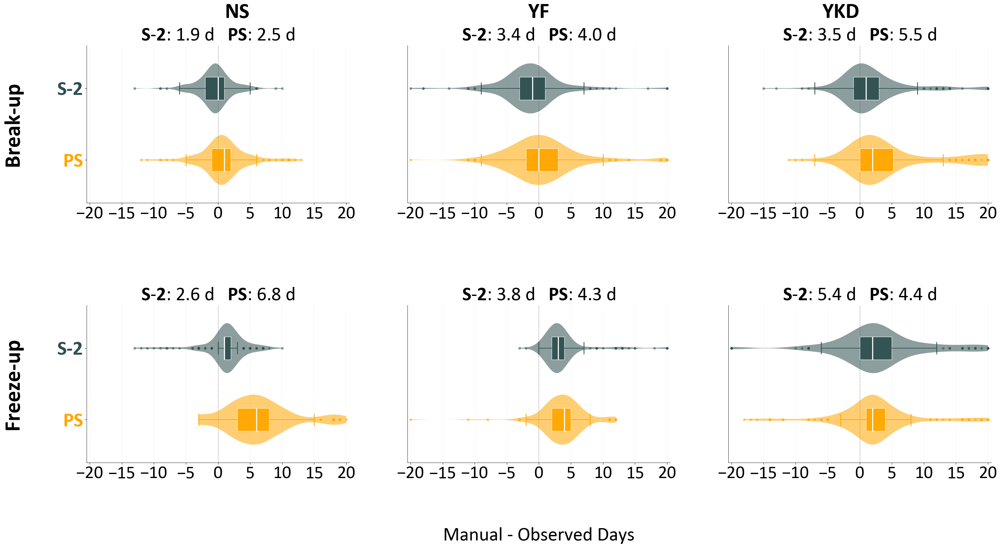

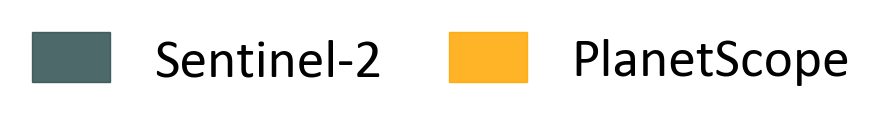

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Colours
PLANET_COLOR   = '#ffa600'
SENTINEL_COLOR = '#2f4f4f'

# Config
FREEZEUP_CSV = r'E:\planetscope_lake_ice\Data\Output\Freezeup\manual_freezeup_review.csv'
BREAKUP_CSV  = r'E:\planetscope_lake_ice\Data\Output\Breakup\manual_breakup_review.csv'

SITES   = ['NS', 'YF', 'YKD']
X_CLIP  = 20
x_ticks = np.arange(-X_CLIP, X_CLIP + 1, 5)

# Helper: parse dates, coercing anything unparseable to NaT
def _parse_dates(df, cols):
    for col in cols:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], format='mixed', errors='coerce', dayfirst=False)
    return df

# Load freeze-up
df_fu = pd.read_csv(FREEZEUP_CSV)
df_fu = _parse_dates(df_fu, ['planet_freezeup_date', 'sentinel_freezeup_date', 'manual_freezeup_date'])
df_fu['planet_error']   = (df_fu['planet_freezeup_date']   - df_fu['manual_freezeup_date']).dt.days
df_fu['sentinel_error'] = (df_fu['sentinel_freezeup_date'] - df_fu['manual_freezeup_date']).dt.days
df_fu = df_fu[df_fu['planet_error'].notna() | df_fu['sentinel_error'].notna()]

# Load break-up
df_bu = pd.read_csv(BREAKUP_CSV)
df_bu = _parse_dates(df_bu, ['planet_breakup_date', 'sentinel_breakup_date', 'manual_breakup_date'])
df_bu['planet_error']   = (df_bu['planet_breakup_date']   - df_bu['manual_breakup_date']).dt.days
df_bu['sentinel_error'] = (df_bu['sentinel_breakup_date'] - df_bu['manual_breakup_date']).dt.days
df_bu = df_bu[df_bu['planet_error'].notna() | df_bu['sentinel_error'].notna()]

# Print summary stats
for event, df_ev in [('Break-up', df_bu), ('Freeze-up', df_fu)]:
    print(f"\n{event}")
    for site in SITES:
        sub = df_ev[df_ev['study_site'] == site]
        print(f"  {site}  (rows in df: {len(sub)})")
        for lbl, col in [('PlanetScope', 'planet_error'), ('Sentinel-2', 'sentinel_error')]:
            err = sub[col].dropna()
            if len(err):
                print(f"    {lbl:12s}  n={len(err):3d}  "
                      f"MAE={err.abs().mean():.1f} d  "
                      f"bias={err.mean():+.1f} d  "
                      f"RMSE={np.sqrt((err**2).mean()):.1f} d")
            else:
                print(f"    {lbl:12s}  n=0  (no valid data)")
print()

# Global style
plt.rcParams.update({
    "font.family":        "Calibri",
    "mathtext.fontset":   "custom",
    "mathtext.rm":        "Calibri",
    "mathtext.bf":        "Calibri:bold",
    "mathtext.it":        "Calibri:italic",
    "font.size":          45,     
    "axes.titlesize":     45,     
    "axes.labelsize":     45,     
    "xtick.labelsize":    42,     
    "ytick.labelsize":    45,     
    "legend.fontsize":    45,     
    "figure.titlesize":   48,     
    "axes.linewidth":     0.7,
    "xtick.direction":    "out",
    "ytick.direction":    "out",
    "xtick.major.size":   4,
    "ytick.major.size":   4,
})

def _style_ax(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.xaxis.grid(True, color='#ebebeb', linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

def _draw_violin_box(ax, s_err, p_err):
    """
    Horizontal violin + slim boxplot overlay.
    S-2 at y=2, PS at y=1.
    """
    for vals, pos, col in [(s_err, 2, SENTINEL_COLOR), (p_err, 1, PLANET_COLOR)]:
        n = len(vals)
        if n == 0:
            continue
        elif n == 1:
            ax.scatter(vals.values[0], pos, color=col, s=120, 
                        zorder=5, clip_on=True)
        else:
            parts = ax.violinplot(
                [vals.values],
                positions=[pos],
                vert=False,
                widths=0.70, 
                showmedians=False,
                showextrema=False,
            )
            for body in parts['bodies']:
                body.set_facecolor(col)
                body.set_edgecolor('none')
                body.set_alpha(0.55)
                body.set_linewidth(0)
                body.set_zorder(2)

            bp = ax.boxplot(
                vals.values,
                positions=[pos],
                vert=False,
                widths=0.32,
                patch_artist=True,
                notch=False,
                whis=1.5,
                zorder=4,
                flierprops=dict(
                    marker='o',
                    markersize=5.0, 
                    linestyle='none',
                    markerfacecolor=col,
                    markeredgecolor=col,
                    alpha=0.5,
                    zorder=4,
                ),
                medianprops=dict(color='white', linewidth=2.5, zorder=5),
                whiskerprops=dict(color=col, linewidth=1.5, zorder=4),
                capprops=dict(color=col, linewidth=1.8, zorder=4),
            )
            bp['boxes'][0].set_facecolor(col)
            bp['boxes'][0].set_edgecolor('white')
            bp['boxes'][0].set_linewidth(1.0)
            bp['boxes'][0].set_alpha(0.95)

def _make_subtitle(p_err, s_err):
    p_mae = p_err.abs().mean() if len(p_err) else float('nan')
    s_mae = s_err.abs().mean() if len(s_err) else float('nan')
    ps_txt = rf"$\bf{{PS}}$: {p_mae:.1f} d" if not np.isnan(p_mae) else r"$\bf{PS}$: n/a"
    s2_txt = rf"$\bf{{S}}$-$\bf{{2}}$: {s_mae:.1f} d" if not np.isnan(s_mae) else r"$\bf{S}$-$\bf{2}$: n/a"
    return f"{s2_txt}   {ps_txt}"

# Row definitions
ROWS = [
    {'label': 'Break-up',  'df': df_bu},
    {'label': 'Freeze-up', 'df': df_fu},
]

# Shared x-axis label text
SHARED_XLABEL = 'Manual - Observed Days'

# Figure
fig, axes = plt.subplots(2, 3, figsize=(34, 19))
fig.subplots_adjust(hspace=0.65, wspace=0.22,
                    left=0.10, right=0.96,
                    top=0.86, bottom=0.15)

for row_idx, row_cfg in enumerate(ROWS):
    df_row = row_cfg['df']

    for col_idx, site in enumerate(SITES):
        sub   = df_row[df_row['study_site'] == site]
        p_err = sub['planet_error'].dropna().astype(float).clip(-X_CLIP, X_CLIP)
        s_err = sub['sentinel_error'].dropna().astype(float).clip(-X_CLIP, X_CLIP)

        ax = axes[row_idx, col_idx]

        _draw_violin_box(ax, s_err, p_err)

        ax.axvline(0, color='#999999', linewidth=1.0, linestyle='--', zorder=1)
        ax.set_xlim(-X_CLIP - 0.5, X_CLIP + 0.5)
        ax.set_xticks(x_ticks)
        ax.set_ylim(0.4, 2.6)
        ax.set_axisbelow(True)
        ax.set_xlabel('')

        # Only apply S-2 vs PS y-axis ticks and labels to the leftmost charts
        if col_idx == 0:
            y_labels = []
            for err_arr, lbl in [(p_err, 'PS'), (s_err, 'S-2')]:
                n = len(err_arr)
                suffix = f' (n={n})' if n <= 1 else ''
                y_labels.append(f'{lbl}{suffix}')

            ax.set_yticks([1, 2])
            ax.set_yticklabels(y_labels, fontsize=47, fontweight='bold')
            
            # Recolor target text labels to match plots
            tick_labels = ax.get_yticklabels()
            if len(tick_labels) >= 2:
                tick_labels[0].set_color(PLANET_COLOR)    # Y=1 is PlanetScope
                tick_labels[1].set_color(SENTINEL_COLOR)  # Y=2 is Sentinel-2
        else:
            # Clean up carried-over charts by hiding ticks entirely
            ax.set_yticks([])
            ax.set_yticklabels([])
            
        _style_ax(ax)

        subtitle = _make_subtitle(p_err, s_err)
        ax.set_title(subtitle, loc='center', pad=12, fontsize=45)

        if col_idx == 0:
            ax.text(-0.28, 0.5,
                row_cfg['label'],
                transform=ax.transAxes,
                va='center', ha='center',
                fontsize=52,
                fontweight='bold',
                rotation=90,
                color='black')

# Shifted y down from 0.93 to 0.915 to drop it by roughly 0.8 of a character height
col_x_positions = [0.243, 0.530, 0.817]
for site, x_pos in zip(SITES, col_x_positions):
    fig.text(x_pos, 0.9, f"{site}", 
             ha='center', va='bottom', 
             fontsize=51, fontweight='bold', 
             fontfamily='Calibri')

# Single, clean global X-axis label added directly to the bottom of the figure layout
fig.text(0.53, 0.04, SHARED_XLABEL,
         ha='center', va='top',
         fontsize=45,                 
         fontfamily='Calibri')

plt.show()

# Standalone legend
fig_leg, ax_leg = plt.subplots(figsize=(7, 1.8))
ax_leg.set_axis_off()
handles = [
    mpatches.Patch(color=SENTINEL_COLOR, alpha=0.85, label='Sentinel-2'),
    mpatches.Patch(color=PLANET_COLOR,   alpha=0.85, label='PlanetScope'),
]
ax_leg.legend(handles=handles, loc='center', ncol=2, frameon=False,
              fontsize=40, handlelength=1.4, handleheight=1.0, columnspacing=1.2)
plt.tight_layout()
plt.show()

In practice for your use case: Bias tells you about cloud/revisit-driven systematic latency; MAE is your headline accuracy number for the paper; RMSE flags whether outliers (e.g., lakes that froze under persistent cloud cover) are a real problem.

#Script to move over GEE output

Loading data…


C:\Users\nj142\AppData\Local\Temp\ipykernel_7540\3176509742.py:92: DtypeWarning: Columns (89,90,93,94,97,98,101,102,105,106,109,110,113,114,117,118,121,122,125,126,129,130,133,134) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_7540\3176509742.py:92: DtypeWarning: Columns (149,150,153,154) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_7540\3176509742.py:92: DtypeWarning: Columns (71,72,75,76,79,80,83,84,87,88,91,92) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_7540\3176509742.py:92: DtypeWarning: Columns (71,72,75,76,79,80) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_7540\3176509742.py:92: DtypeWarning:


── Figure 0: Mean DOY time series ──


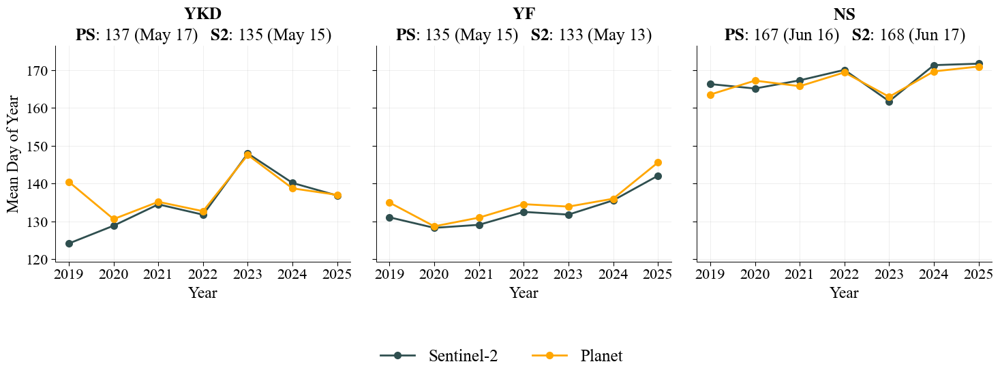

  shown  mean_breakup_DOY_timeseries_per_site


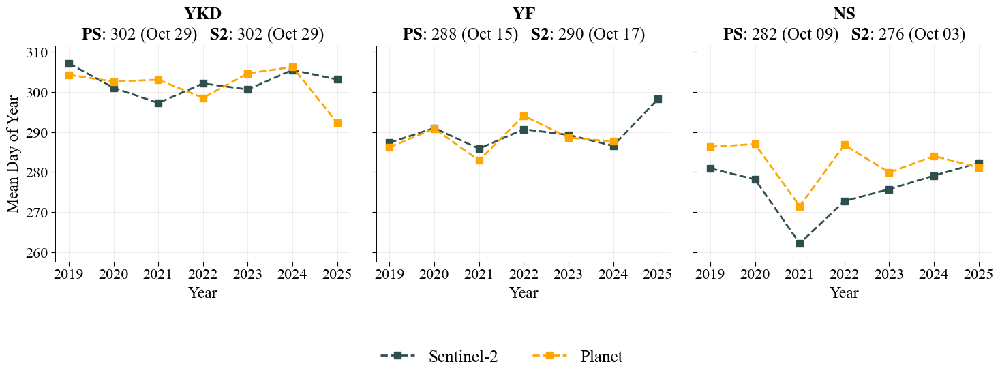

  shown  mean_freezeup_DOY_timeseries_per_site

── Figure 1: Ridgeline KDE ──


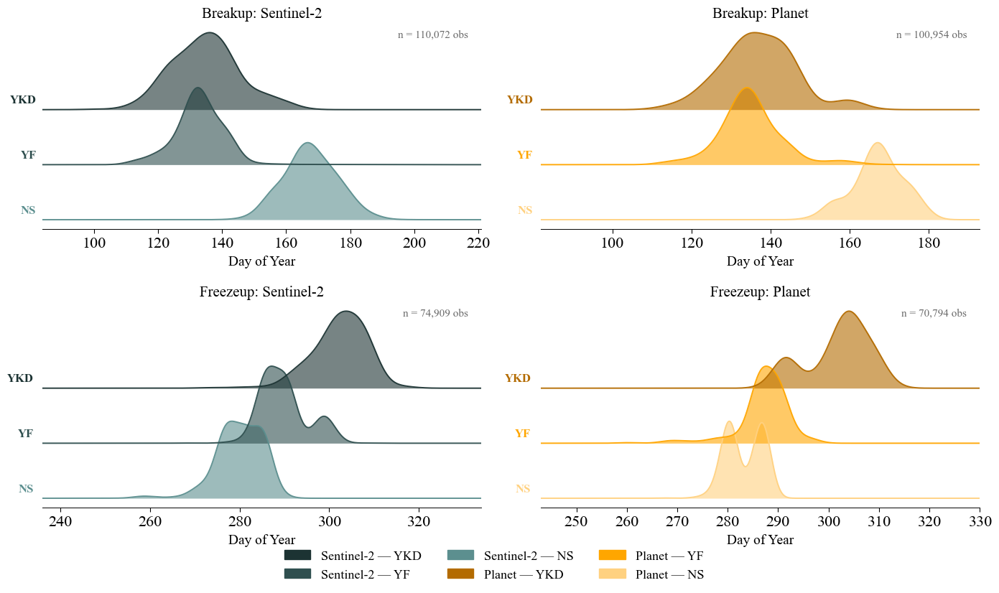

  shown  ridgeline_KDE

── Figure 2: Annual box plots ──


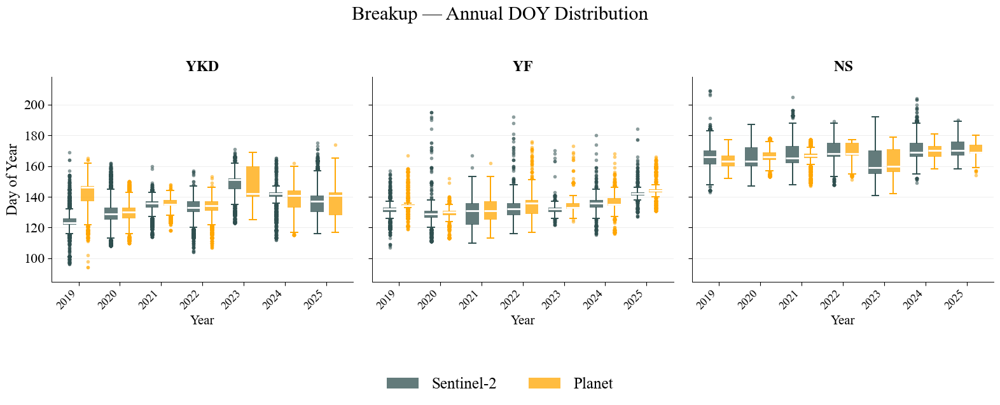

  shown  annual_boxplots_breakup


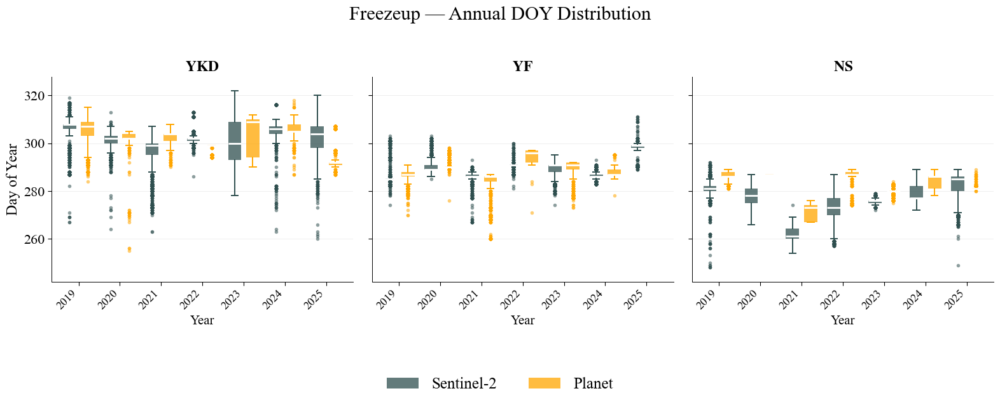

  shown  annual_boxplots_freezeup

  saved  mean_DOY_yearly.csv  (84 rows)

1. PER-SITE SUMMARY  (DOY = day of year; calendar date shown for the mean)

--- BREAKUP ---
Site Dataset         N   Mean   (Date)   Med   Std  Min  Max  Range
YKD  Sentinel-2  57601  134.9   May 15 135.0  10.3   96  175     79
YKD  Planet      55654  137.0   May 17 137.0   9.3   94  174     80
YF   Sentinel-2  12889  132.9   May 13 133.0   7.5  107  195     88
YF   Planet      12664  135.0   May 15 134.0   7.8  113  176     63
NS   Sentinel-2  39582  167.7   Jun 17 167.0   8.1  141  209     68
NS   Planet      32636  167.3   Jun 16 167.0   6.2  142  181     39

--- FREEZEUP ---
Site Dataset         N   Mean   (Date)   Med   Std  Min  Max  Range
YKD  Sentinel-2  48443  302.3   Oct 29 303.0   6.0  260  322     62
YKD  Planet      47575  301.9   Oct 29 304.0   6.1  255  318     63
YF   Sentinel-2  11734  289.8   Oct 17 289.0   5.1  267  311     44
YF   Planet       8139  287.3   Oct 14 287.0   4.8  260  298     3

In [ ]:
"""
Mean DOY time series per site — Sentinel-2 vs Planet.

Original figure
---------------
  Two figures (breakup, freezeup), each with 3 panels (YKD, YF, NS).
  Each panel shows the yearly mean DOY for Sentinel-2 (dark slate) and Planet (orange).

New figure 1 — Ridgeline KDE
-----------------------------
  One figure, 2 rows (breakup / freezeup) × 2 cols (Sentinel-2 / Planet).
  Every lake_id gets its own smooth KDE ridge, coloured by site using shades
  of the dataset colour (slate shades for S2, orange shades for Planet).

New figure 2 — Annual box plots
---------------------------------
  Two figures (breakup, freezeup), each with 3 panels (YKD, YF, NS).
  Same layout as the original dot plots, but each year has two side-by-side
  vertical box plots (S2 and Planet) instead of connected dots.

Also writes a tidy CSV of all yearly means and prints summary statistics.
"""

from pathlib import Path
from datetime import datetime, timedelta
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats

# ============================================================================
# FONT (Times New Roman everywhere)
# ============================================================================
plt.rcParams["font.family"]      = "Times New Roman"
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["font.size"]        = 16
plt.rcParams["axes.titlesize"]   = 18
plt.rcParams["axes.labelsize"]   = 17
plt.rcParams["xtick.labelsize"]  = 16
plt.rcParams["ytick.labelsize"]  = 16
plt.rcParams["legend.fontsize"]  = 20
plt.rcParams["figure.titlesize"] = 24

# ============================================================================
# CONFIG
# ============================================================================
ROOT       = Path(r"C:\Users\nj142\Desktop\Time Series")
OUTPUT_DIR = ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SITES    = ["YKD", "YF", "NS"]
METRICS  = ["breakup", "freezeup"]
DATASETS = [("S2", "Sentinel-2"), ("PS", "Planet")]
YEARS    = list(range(2019, 2026))

def csv_path(site: str, metric: str, dataset: str) -> Path:
    return ROOT / dataset / metric.capitalize() / f"{site}_{metric}_dates.csv"

PLANET_COLOR   = "#ffa600"
SENTINEL_COLOR = "#2f4f4f"
COLORS         = {"S2": SENTINEL_COLOR, "PS": PLANET_COLOR}
LINESTYLES     = {"breakup": "-",  "freezeup": "--"}
MARKERS        = {"breakup": "o",  "freezeup": "s"}

# Per-dataset site shades:
#   Sentinel-2 (dark slate #2f4f4f): YKD = darkest, YF = base, NS = lightest
#   Planet     (orange    #ffa600):  YKD = darkest, YF = base, NS = lightest
SITE_SHADES = {
    "S2": {
        "YKD": "#1c3333",   # darker slate
        "YF":  "#2f4f4f",   # base Sentinel-2 colour
        "NS":  "#5c8f8f",   # lighter slate
    },
    "PS": {
        "YKD": "#b36b00",   # darker orange
        "YF":  "#ffa600",   # base Planet colour
        "NS":  "#ffd180",   # lighter orange
    },
}

# ============================================================================
# DATA
# ============================================================================
def load_doy(path: Path, metric: str) -> pd.DataFrame:
    if not path.exists():
        print(f"  [missing] {path}")
        return pd.DataFrame(columns=["lake_id", "year", "doy"])

    df = pd.read_csv(path)
    date_col = f"{metric}_date"

    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    df = df.dropna(subset=[date_col]).copy()

    df["doy"]  = df[date_col].dt.dayofyear
    df["year"] = df[date_col].dt.year

    return df[["lake_id", "year", "doy"]]


def load_all():
    """Return (means dict, tidy yearly-means DataFrame, long per-observation DataFrame)."""
    means   = {}
    rows    = []
    records = []

    for site in SITES:
        for metric in METRICS:
            for ds_key, ds_name in DATASETS:
                df = load_doy(csv_path(site, metric, ds_key), metric)

                df_tagged = df.copy()
                df_tagged["site"]    = site
                df_tagged["metric"]  = metric
                df_tagged["dataset"] = ds_name

                records.append(df_tagged)

                m = df.groupby("year")["doy"].mean().to_dict()
                c = df.groupby("year")["doy"].count().to_dict()

                means[(site, metric, ds_key)] = m

                for y in YEARS:
                    rows.append({
                        "site":           site,
                        "metric":         metric,
                        "dataset":        ds_name,
                        "year":           y,
                        "mean_doy":       round(m.get(y, float("nan")), 2),
                        "n_observations": int(c.get(y, 0)),
                    })

    tidy     = pd.DataFrame(rows)
    all_data = pd.concat(records, ignore_index=True)

    return means, tidy, all_data

# ============================================================================
# HELPERS
# ============================================================================
def doy_to_date(doy):
    if np.isnan(doy):
        return "n/a"
    return (datetime(2023, 1, 1) + timedelta(days=int(round(doy)) - 1)).strftime("%b %d")


def site_mean_label(means, site, metric):
    ps_vals = list(means[(site, metric, "PS")].values())
    s2_vals = list(means[(site, metric, "S2")].values())

    ps_mean = np.nanmean(ps_vals) if len(ps_vals) else np.nan
    s2_mean = np.nanmean(s2_vals) if len(s2_vals) else np.nan

    ps_txt = (
        r"$\bf{PS}$: n/a"
        if np.isnan(ps_mean)
        else rf"$\bf{{PS}}$: {int(round(ps_mean))} ({doy_to_date(ps_mean)})"
    )
    s2_txt = (
        r"$\bf{S2}$: n/a"
        if np.isnan(s2_mean)
        else rf"$\bf{{S2}}$: {int(round(s2_mean))} ({doy_to_date(s2_mean)})"
    )

    return f"{ps_txt}   {s2_txt}"

# ============================================================================
# FIGURE 0 (original) — mean DOY time series
# ============================================================================
def plot_panels(means):
    for metric in METRICS:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

        all_vals = [
            v
            for site in SITES
            for ds_key, _ in DATASETS
            for v in means[(site, metric, ds_key)].values()
            if not np.isnan(v)
        ]

        if all_vals:
            lo, hi = min(all_vals), max(all_vals)
            pad  = max(2, (hi - lo) * 0.1)
            ylim = (lo - pad, hi + pad)
        else:
            ylim = None

        for ax, site in zip(axes, SITES):
            for ds_key, ds_name in DATASETS:
                d  = means[(site, metric, ds_key)]
                ys = [d.get(y, np.nan) for y in YEARS]

                ax.plot(
                    YEARS, ys,
                    color=COLORS[ds_key],
                    linestyle=LINESTYLES[metric],
                    marker=MARKERS[metric],
                    linewidth=2, markersize=7,
                    label=ds_name,
                )

            subtitle = site_mean_label(means, site, metric)
            ax.set_title(rf"$\bf{{{site}}}$" + "\n" + subtitle)
            ax.set_xlabel("Year")
            ax.set_xticks(YEARS)
            ax.grid(True, alpha=0.25, linewidth=0.6)

            if ylim:
                ax.set_ylim(ylim)

            for sp in ("top", "right"):
                ax.spines[sp].set_visible(False)

        axes[0].set_ylabel("Mean Day of Year", fontsize=17)

        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(
            handles, labels,
            loc="upper center", bbox_to_anchor=(0.5, -0.05),
            ncol=2, frameon=False, fontsize=18,
        )

        fig.tight_layout()
        plt.show()
        print(f"  shown  mean_{metric}_DOY_timeseries_per_site")

# ============================================================================
# FIGURE 1 (new) — ridgeline KDE
#   Layout: 2 rows (breakup / freezeup)  ×  2 cols (Sentinel-2 / Planet)
#   Colours: each site is a shade of that panel's dataset colour.
# ============================================================================


# ============================================================================
# FIGURE 2 (new) — annual box plots  (same 1×3 layout as original, per metric)
# ============================================================================
def plot_annual_boxplots(all_data: pd.DataFrame):
    """
    Two figures (breakup / freezeup), each with 3 panels (YKD / YF / NS).
    Each year gets two side-by-side vertical box plots — one S2, one Planet.

    FIX: ylim is computed globally across ALL sites for this metric so that
         sharey=True does not let the last panel clip data from earlier panels.
    """
    half_gap = 0.22   # half the centre-to-centre distance between S2 and Planet
    box_w    = 0.32   # box width in year units

    for metric in METRICS:
        fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True)

        # ---- global ylim across ALL sites for this metric ----
        all_metric_vals = all_data[
            all_data.metric == metric
        ]["doy"].dropna().values

        if len(all_metric_vals):
            global_lo  = all_metric_vals.min()
            global_hi  = all_metric_vals.max()
            global_pad = max(3, (global_hi - global_lo) * 0.08)
            global_ylim = (global_lo - global_pad, global_hi + global_pad)
        else:
            global_ylim = None

        for ax, site in zip(axes, SITES):
            sub = all_data[
                (all_data.site   == site) &
                (all_data.metric == metric)
            ]

            for ds_key, ds_name in DATASETS:
                color = COLORS[ds_key]
                # S2 boxes sit left (-half_gap), Planet boxes sit right (+half_gap)
                dx = -half_gap if ds_key == "S2" else +half_gap

                positions = []
                box_data  = []

                for year in YEARS:
                    vals = sub[
                        (sub.dataset == ds_name) &
                        (sub.year    == year)
                    ]["doy"].dropna().values

                    if len(vals) >= 2:
                        positions.append(year + dx)
                        box_data.append(vals)

                if not box_data:
                    continue

                bp = ax.boxplot(
                    box_data,
                    positions=positions,
                    widths=box_w,
                    patch_artist=True,
                    notch=False,
                    showfliers=True,
                    manage_ticks=False,
                    medianprops=dict(color="white", linewidth=2.0),
                )

                for patch in bp["boxes"]:
                    patch.set_facecolor(color)
                    patch.set_alpha(0.75)
                    patch.set_linewidth(0)

                for element in ("whiskers", "caps"):
                    for line in bp[element]:
                        line.set_color(color)
                        line.set_linewidth(1.4)

                for flier in bp["fliers"]:
                    flier.set(marker="o", markerfacecolor=color,
                              markeredgewidth=0, alpha=0.55, markersize=4)

            # ---- axes cosmetics ----
            ax.set_xticks(YEARS)
            ax.set_xticklabels(YEARS, rotation=45, ha="right", fontsize=13)
            ax.set_xlim(YEARS[0] - 0.65, YEARS[-1] + 0.65)
            ax.set_xlabel("Year", fontsize=15)
            ax.set_title(rf"$\bf{{{site}}}$", fontsize=17)
            ax.grid(True, axis="y", alpha=0.25, linewidth=0.6)

            # Apply the global ylim (safe even with sharey=True)
            if global_ylim:
                ax.set_ylim(global_ylim)

            for sp in ("top", "right"):
                ax.spines[sp].set_visible(False)

        axes[0].set_ylabel("Day of Year", fontsize=17)

        # ---- legend ----
        handles = [
            mpatches.Patch(facecolor=COLORS[ds_key], alpha=0.75, label=ds_name)
            for ds_key, ds_name in DATASETS
        ]
        fig.legend(
            handles, [ds_name for _, ds_name in DATASETS],
            loc="upper center", bbox_to_anchor=(0.5, -0.06),
            ncol=2, frameon=False, fontsize=18,
        )

        fig.suptitle(f"{metric.capitalize()} — Annual DOY Distribution",
                     fontsize=22, y=1.02)
        fig.tight_layout()
        plt.show()
        print(f"  shown  annual_boxplots_{metric}")

# ============================================================================
# STATS
# ============================================================================
def print_stats(all_data: pd.DataFrame):
    def get(site, metric, dataset):
        return all_data[
            (all_data.site    == site) &
            (all_data.metric  == metric) &
            (all_data.dataset == dataset)
        ]["doy"].values

    print("=" * 84)
    print("1. PER-SITE SUMMARY  (DOY = day of year; calendar date shown for the mean)")
    print("=" * 84)

    for metric in METRICS:
        print(f"\n--- {metric.upper()} ---")
        print(f"{'Site':<5}{'Dataset':<12}{'N':>5}{'Mean':>7}{'(Date)':>9}"
              f"{'Med':>6}{'Std':>6}{'Min':>5}{'Max':>5}{'Range':>7}")

        for site in SITES:
            for _, ds_name in DATASETS:
                d = get(site, metric, ds_name)
                if len(d) == 0:
                    continue
                print(
                    f"{site:<5}{ds_name:<12}{len(d):>5}"
                    f"{d.mean():>7.1f}{doy_to_date(d.mean()):>9}"
                    f"{np.median(d):>6.1f}{d.std():>6.1f}"
                    f"{int(d.min()):>5d}{int(d.max()):>5d}"
                    f"{int(d.max()-d.min()):>7d}"
                )

    print("\n" + "=" * 84)
    print("2. INTER-SITE TEST  (do YKD / YF / NS differ in mean timing?)")
    print("=" * 84)
    print("ANOVA assumes normality; Kruskal-Wallis does not. p < 0.05 → sites differ.\n")

    for metric in METRICS:
        for _, ds_name in DATASETS:
            groups = [get(s, metric, ds_name) for s in SITES]
            if any(len(g) < 2 for g in groups):
                continue
            F, p_a  = stats.f_oneway(*groups)
            H, p_kw = stats.kruskal(*groups)
            means_  = {s: g.mean() for s, g in zip(SITES, groups)}
            spread  = max(means_.values()) - min(means_.values())
            print(
                f"{metric:<9}{ds_name:<12} ANOVA F={F:5.2f} p={p_a:.4f}   "
                f"KW H={H:5.2f} p={p_kw:.4f}   "
                f"site-mean spread = {spread:5.1f} d  "
                f"({', '.join(f'{s}:{means_[s]:.0f}' for s in SITES)})"
            )

    print("\n" + "=" * 84)
    print("3. PAIRWISE SITE DIFFERENCES  (Δ = first − second, in days)")
    print("=" * 84)
    print("Positive Δ → first site's event happens later in the year.  * = p < 0.05\n")

    for metric in METRICS:
        for _, ds_name in DATASETS:
            print(f"{metric:<9} {ds_name}")
            for s1, s2 in combinations(SITES, 2):
                a, b = get(s1, metric, ds_name), get(s2, metric, ds_name)
                if len(a) < 2 or len(b) < 2:
                    continue
                delta = a.mean() - b.mean()
                try:
                    _, p = stats.mannwhitneyu(a, b, alternative="two-sided")
                except ValueError:
                    p = np.nan
                sig = " *" if (not np.isnan(p) and p < 0.05) else ""
                print(f"   {s1} − {s2}:  Δ = {delta:+6.1f} d   p = {p:.4f}{sig}")
            print()

    print("=" * 84)
    print("4. SENTINEL-2 vs PLANET  (per site / metric)")
    print("=" * 84)
    print("Δ = S2 mean − Planet mean.  Small |Δ| + high p → sensors agree.\n")

    for metric in METRICS:
        for site in SITES:
            s2 = get(site, metric, "Sentinel-2")
            ps = get(site, metric, "Planet")
            if len(s2) < 2 or len(ps) < 2:
                continue
            delta = s2.mean() - ps.mean()
            try:
                _, p = stats.mannwhitneyu(s2, ps, alternative="two-sided")
            except ValueError:
                p = np.nan
            sig = " *" if (not np.isnan(p) and p < 0.05) else ""
            print(
                f"{metric:<9} {site:<4} S2 mean={s2.mean():6.1f}  "
                f"PS mean={ps.mean():6.1f}  Δ={delta:+5.1f} d  p={p:.4f}{sig}"
            )

# ============================================================================
# MAIN
# ============================================================================
def main():
    print("Loading data…")
    means, tidy, all_data = load_all()

    # ── Original figure: mean DOY time series ─────────────────────────────
    print("\n── Figure 0: Mean DOY time series ──")
    plot_panels(means)

    # ── New Figure 1: Ridgeline KDE ────────────────────────────────────────
    print("\n── Figure 1: Ridgeline KDE ──")
    plot_ridgeline(all_data)

    # ── New Figure 2: Annual box plots ─────────────────────────────────────
    print("\n── Figure 2: Annual box plots ──")
    plot_annual_boxplots(all_data)

    # ── CSV output ────────────────────────────────────────────────────────
    csv_out = OUTPUT_DIR / "mean_DOY_yearly.csv"
    tidy.to_csv(csv_out, index=False)
    print(f"\n  saved  {csv_out.name}  ({len(tidy)} rows)\n")

    # ── Summary statistics ────────────────────────────────────────────────
    print_stats(all_data)


if __name__ == "__main__":
    main()

Loading data…

── Figure 1: Ridgeline KDE ──


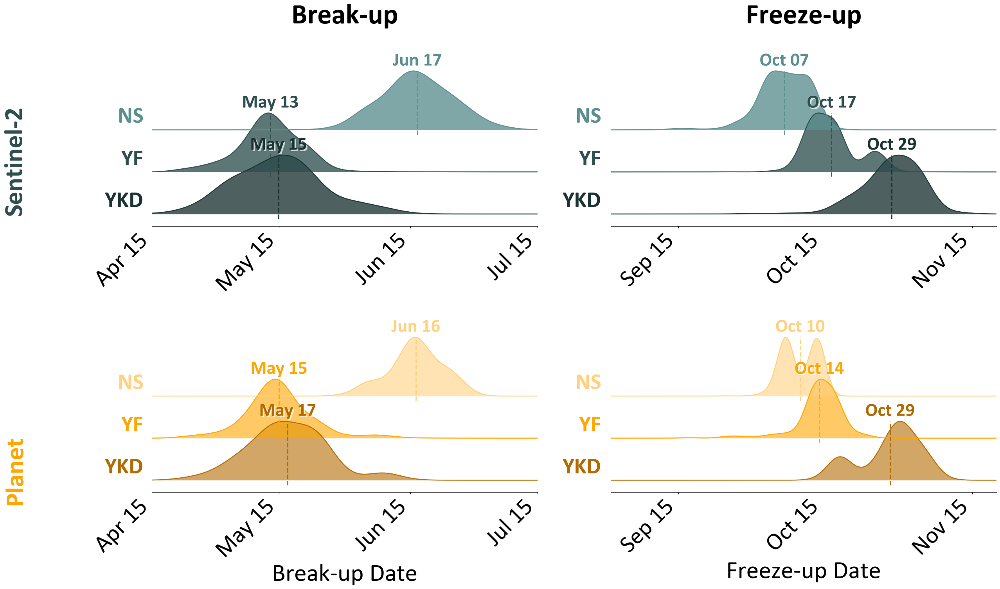


Sample sizes per panel (for figure caption):
  Sentinel-2   Breakup    n = 110,072
  Sentinel-2   Freezeup   n = 74,909
  Planet       Breakup    n = 100,954
  Planet       Freezeup   n = 70,794
  shown  ridgeline_KDE

── Figure 2: Legend ──


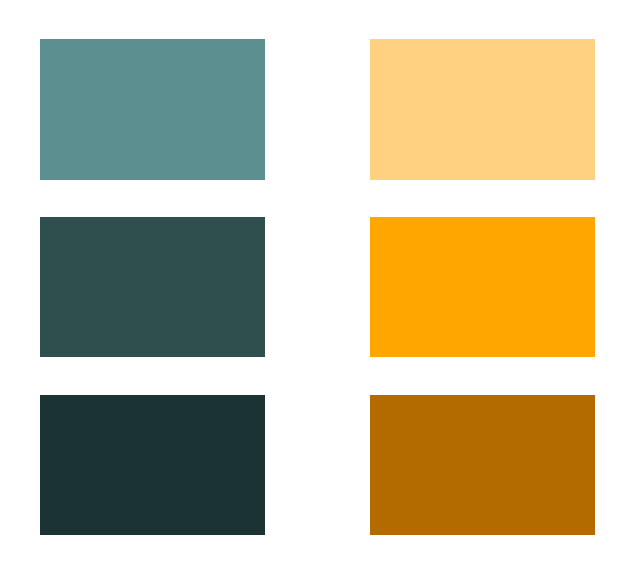

  shown  legend_standalone

  saved  mean_DOY_yearly.csv  (84 rows)

1. PER-SITE SUMMARY  (DOY = day of year; calendar date shown for the mean)

--- BREAKUP ---
Site Dataset         N   Mean   (Date)   Med   Std  Min  Max  Range
NS   Sentinel-2  39582  167.7   Jun 17 167.0   8.1  141  209     68
NS   Planet      32636  167.3   Jun 16 167.0   6.2  142  181     39
YF   Sentinel-2  12889  132.9   May 13 133.0   7.5  107  195     88
YF   Planet      12664  135.0   May 15 134.0   7.8  113  176     63
YKD  Sentinel-2  57601  134.9   May 15 135.0  10.3   96  175     79
YKD  Planet      55654  137.0   May 17 137.0   9.3   94  174     80

--- FREEZEUP ---
Site Dataset         N   Mean   (Date)   Med   Std  Min  Max  Range
NS   Sentinel-2  14732  280.0   Oct 07 280.0   5.1  248  292     44
NS   Planet      15080  283.3   Oct 10 283.0   3.6  267  289     22
YF   Sentinel-2  11734  289.8   Oct 17 289.0   5.1  267  311     44
YF   Planet       8139  287.3   Oct 14 287.0   4.8  260  298     38
YKD  

In [ ]:
"""
Mean DOY time series per site — Sentinel-2 vs Planet.

Original figure
---------------
  Two figures (breakup, freezeup), each with 3 panels (YKD, YF, NS).
  Each panel shows the yearly mean DOY for Sentinel-2 (dark slate) and Planet (orange).

New figure 1 — Ridgeline KDE
-----------------------------
  One figure, 2 rows (Sentinel-2 / Planet) × 2 cols (breakup / freezeup).
  Column headers: "Breakup" / "Freezeup".
  Vertical row labels on the left border: "Sentinel-2" / "Planet".
  Every lake_id gets its own smooth KDE ridge, coloured by site using shades
  of the dataset colour (slate shades for S2, orange shades for Planet).
  Top row rendered slightly darker.
  Legend: coloured patches only (no text), arranged in 2 vertical columns.

New figure 2 — Annual box plots
---------------------------------
  Two figures (breakup, freezeup), each with 3 panels (YKD, YF, NS).
  Same layout as the original dot plots, but each year has two side-by-side
  vertical box plots (S2 and Planet) instead of connected dots.

Also writes a tidy CSV of all yearly means and prints summary statistics.
"""

from pathlib import Path
from datetime import datetime, timedelta
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from scipy import stats

# ============================================================================
# FONT — Calibri everywhere, all sizes ×2.5
# ============================================================================
plt.rcParams["font.family"]      = "Calibri"
plt.rcParams["mathtext.fontset"] = "dejavusans"
plt.rcParams["font.size"]        = 44        # +4
plt.rcParams["axes.titlesize"]   = 49        # +4
plt.rcParams["axes.labelsize"]   = 46        # +4
plt.rcParams["xtick.labelsize"]  = 44        # +4
plt.rcParams["ytick.labelsize"]  = 44        # +4
plt.rcParams["legend.fontsize"]  = 54        # +4
plt.rcParams["figure.titlesize"] = 64        # +4

# ============================================================================
# CONFIG
# ============================================================================
ROOT       = Path(r"C:\Users\nj142\Desktop\Time Series")
OUTPUT_DIR = ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SITES    = ["NS", "YF", "YKD"]
METRICS  = ["breakup", "freezeup"]
DATASETS = [("S2", "Sentinel-2"), ("PS", "Planet")]
YEARS    = list(range(2019, 2026))

def csv_path(site: str, metric: str, dataset: str) -> Path:
    return ROOT / dataset / metric.capitalize() / f"{site}_{metric}_dates.csv"

PLANET_COLOR   = "#ffa600"
SENTINEL_COLOR = "#2f4f4f"
COLORS         = {"S2": SENTINEL_COLOR, "PS": PLANET_COLOR}
LINESTYLES     = {"breakup": "-",  "freezeup": "--"}
MARKERS        = {"breakup": "o",  "freezeup": "s"}

# Per-dataset site shades:
#   Sentinel-2 (dark slate #2f4f4f): YKD = darkest, YF = base, NS = lightest
#   Planet     (orange    #ffa600):  YKD = darkest, YF = base, NS = lightest
SITE_SHADES = {
    "S2": {
        "YKD": "#1c3333",   # darker slate
        "YF":  "#2f4f4f",   # base Sentinel-2 colour
        "NS":  "#5c8f8f",   # lighter slate
    },
    "PS": {
        "YKD": "#b36b00",   # darker orange
        "YF":  "#ffa600",   # base Planet colour
        "NS":  "#ffd180",   # lighter orange
    },
}

# ============================================================================
# DATA
# ============================================================================
def load_doy(path: Path, metric: str) -> pd.DataFrame:
    if not path.exists():
        print(f"  [missing] {path}")
        return pd.DataFrame(columns=["lake_id", "year", "doy"])

    df = pd.read_csv(path)
    date_col = f"{metric}_date"

    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    df = df.dropna(subset=[date_col]).copy()

    df["doy"]  = df[date_col].dt.dayofyear
    df["year"] = df[date_col].dt.year

    return df[["lake_id", "year", "doy"]]


def load_all():
    """Return (means dict, tidy yearly-means DataFrame, long per-observation DataFrame)."""
    means   = {}
    rows    = []
    records = []

    for site in SITES:
        for metric in METRICS:
            for ds_key, ds_name in DATASETS:
                df = load_doy(csv_path(site, metric, ds_key), metric)

                df_tagged = df.copy()
                df_tagged["site"]    = site
                df_tagged["metric"]  = metric
                df_tagged["dataset"] = ds_name

                records.append(df_tagged)

                m = df.groupby("year")["doy"].mean().to_dict()
                c = df.groupby("year")["doy"].count().to_dict()

                means[(site, metric, ds_key)] = m

                for y in YEARS:
                    rows.append({
                        "site":           site,
                        "metric":         metric,
                        "dataset":        ds_name,
                        "year":           y,
                        "mean_doy":       round(m.get(y, float("nan")), 2),
                        "n_observations": int(c.get(y, 0)),
                    })

    tidy     = pd.DataFrame(rows)
    all_data = pd.concat(records, ignore_index=True)

    return means, tidy, all_data

# ============================================================================
# HELPERS
# ============================================================================
def doy_to_date(doy):
    if np.isnan(doy):
        return "n/a"
    return (datetime(2023, 1, 1) + timedelta(days=int(round(doy)) - 1)).strftime("%b %d")


def site_mean_label(means, site, metric):
    ps_vals = list(means[(site, metric, "PS")].values())
    s2_vals = list(means[(site, metric, "S2")].values())

    ps_mean = np.nanmean(ps_vals) if len(ps_vals) else np.nan
    s2_mean = np.nanmean(s2_vals) if len(s2_vals) else np.nan

    ps_txt = (
        r"$\bf{PS}$: n/a"
        if np.isnan(ps_mean)
        else rf"$\bf{{PS}}$: {int(round(ps_mean))} ({doy_to_date(ps_mean)})"
    )
    s2_txt = (
        r"$\bf{S2}$: n/a"
        if np.isnan(s2_mean)
        else rf"$\bf{{S2}}$: {int(round(s2_mean))} ({doy_to_date(s2_mean)})"
    )

    return f"{ps_txt}   {s2_txt}"

# ============================================================================
# FIGURE 0 (original) — mean DOY time series
# ============================================================================
def plot_panels(means):
    for metric in METRICS:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

        all_vals = [
            v
            for site in SITES
            for ds_key, _ in DATASETS
            for v in means[(site, metric, ds_key)].values()
            if not np.isnan(v)
        ]

        if all_vals:
            lo, hi = min(all_vals), max(all_vals)
            pad  = max(2, (hi - lo) * 0.1)
            ylim = (lo - pad, hi + pad)
        else:
            ylim = None

        for ax, site in zip(axes, SITES):
            for ds_key, ds_name in DATASETS:
                d  = means[(site, metric, ds_key)]
                ys = [d.get(y, np.nan) for y in YEARS]

                ax.plot(
                    YEARS, ys,
                    color=COLORS[ds_key],
                    linestyle=LINESTYLES[metric],
                    marker=MARKERS[metric],
                    linewidth=2, markersize=7,
                    label=ds_name,
                )

            subtitle = site_mean_label(means, site, metric)
            ax.set_title(rf"$\bf{{{site}}}$" + "\n" + subtitle)
            ax.set_xlabel("Year")
            ax.set_xticks(YEARS)
            ax.grid(True, alpha=0.25, linewidth=0.6)

            if ylim:
                ax.set_ylim(ylim)

            for sp in ("top", "right"):
                ax.spines[sp].set_visible(False)

        axes[0].set_ylabel("Mean Day of Year", fontsize=17)

        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(
            handles, labels,
            loc="upper center", bbox_to_anchor=(0.5, -0.05),
            ncol=2, frameon=False, fontsize=18,
        )

        fig.tight_layout()
        plt.show()
        print(f"  shown  mean_{metric}_DOY_timeseries_per_site")

# ============================================================================
# FIGURE 1 (new) — ridgeline KDE
#
#   Layout : 2 rows (Sentinel-2 / Planet)  ×  2 cols (breakup / freezeup)
#   Column headers  : "Breakup" | "Freezeup"   (top border only)
#   Row labels      : "Sentinel-2" | "Planet"   (left border, vertical)
#   Top row alpha   : 0.78  (slightly darker than bottom row's 0.60)
#   Legend          : coloured patches only — no text — 2 vertical columns
# ============================================================================

def plot_ridgeline(all_data: pd.DataFrame):
    ds_order     = [("S2", "Sentinel-2"), ("PS", "Planet")]
    metric_order = ["breakup", "freezeup"]
    overlap      = 1.4
    ROW_ALPHA    = [0.78, 0.60]

    # Row-label colours = central (YF / base) shade of each dataset
    ROW_COLORS = {
        "Sentinel-2": SENTINEL_COLOR,   # #2f4f4f
        "Planet":     PLANET_COLOR,     # #ffa600
    }

    # Fixed calendar-date ticks per metric. The first and last tick also
    # define the hard x-axis clipping range for that column.
    METRIC_TICK_DAYS = {
        "breakup":  [(4, 15), (5, 15), (6, 15), (7, 15)],   # Apr 15 → Jul 15
        "freezeup": [(9, 15), (10, 15), (11, 15)],          # Sep 15 → Nov 15
    }
    METRIC_X_RANGE = {
    "breakup":  ((4, 15), (7, 15)),   # Apr 15 → Jul 15  (unchanged)
    "freezeup": ((9, 1),  (11, 20)),  # Sep  1 → Nov 30  (wider than ticks)
}
    METRIC_XLABEL = {
        "breakup":  "Break-up Date",
        "freezeup": "Freeze-up Date",
    }

    REF_YEAR = 2023  # non-leap reference for DOY mapping

    fig, axes = plt.subplots(
        len(ds_order), len(metric_order),
        figsize=(26, 18),
        sharex=False, sharey=False,
    )

    # Pre-compute shared x-range (and ticks) per column so both rows match.
    column_x_ranges = {}
    column_ticks    = {}
    for metric in metric_order:
        tick_doys, tick_labels = [], []
        for month, day in METRIC_TICK_DAYS[metric]:
            d = datetime(REF_YEAR, month, day)
            tick_doys.append(d.timetuple().tm_yday)
            tick_labels.append(d.strftime("%b %d"))

        (lo_m, lo_d), (hi_m, hi_d) = METRIC_X_RANGE[metric]
        lo_doy = datetime(REF_YEAR, lo_m, lo_d).timetuple().tm_yday
        hi_doy = datetime(REF_YEAR, hi_m, hi_d).timetuple().tm_yday

        column_x_ranges[metric] = (lo_doy, hi_doy)
        column_ticks[metric]    = (tick_doys, tick_labels)

    n_per_panel = []

    for row, (ds_key, ds_name) in enumerate(ds_order):
        alpha = ROW_ALPHA[row]

        for col, metric in enumerate(metric_order):
            ax  = axes[row, col]
            sub = all_data[
                (all_data.metric  == metric) &
                (all_data.dataset == ds_name)
            ].copy()

            x_lo, x_hi = column_x_ranges[metric]
            x = np.linspace(x_lo, x_hi, 600)

            if sub.empty:
                ax.text(0.5, 0.5, "No data",
                        ha="center", va="center", transform=ax.transAxes)
                ax.set_xlim(x_lo, x_hi)
                continue

            all_doys = sub["doy"].dropna()
            n_per_panel.append((ds_name, metric.capitalize(), len(all_doys)))

            for i, site in enumerate(reversed(SITES)):   # bottom → top
                vals = sub[sub.site == site]["doy"].dropna().values
                if len(vals) < 3:
                    continue

                kde    = stats.gaussian_kde(vals, bw_method=0.4)
                y_raw  = kde(x)
                y_nrm  = y_raw / y_raw.max()
                offset = i / overlap
                color  = SITE_SHADES[ds_key][site]

                ax.fill_between(x, offset, offset + y_nrm,
                                color=color, alpha=alpha, linewidth=0)
                ax.plot(x, offset + y_nrm,
                        color=color, linewidth=1.8, alpha=0.95)

                ax.text(x_lo - 2, offset + 0.05, site,
                        ha="right", va="bottom",
                        fontsize=42, color=color, fontweight="bold")

                # ── Mean DOY vertical line (numeric label removed) ─────
                mean_doy    = vals.mean()
                kde_at_mean = kde(mean_doy)[0] / y_raw.max()
                line_top    = offset + kde_at_mean

                ax.plot(
                    [mean_doy, mean_doy],
                    [offset - 0.08, offset + 1.0],          # extend line to ridge top
                    color=color, linestyle="--", linewidth=2.2, alpha=0.92,
                    zorder=5,
                )

                ax.text(
                    mean_doy,
                    offset + 1.0 + 0.04,                    # anchor label to ridge top, not curve
                    doy_to_date(mean_doy),
                    ha="center", va="bottom",
                    fontsize=34, color=color, fontweight="bold",
                    zorder=6,
                    path_effects=[
                        pe.SimplePatchShadow(
                            offset=(2.5, -2.5),
                            shadow_rgbFace="white",
                            alpha=0.7,
                            rho=0.4,
                        ),
                        pe.Normal(),
                    ],
                )

            # ── X-axis: fixed date ticks, hard-clipped to that range ────
            tick_doys, tick_labels = column_ticks[metric]
            ax.set_xlim(x_lo, x_hi)
            ax.set_xticks(tick_doys)
            ax.set_xticklabels(tick_labels, rotation=0, ha="center")
            ax.set_yticks([])

            # X-axis label ONLY on the bottom (Planet) row, since it applies
            # to the panel above it as well.
            if row == len(ds_order) - 1:
                ax.set_xlabel(METRIC_XLABEL[metric], fontsize=46)
            else:
                ax.set_xlabel("")

            # ── Column titles: bold, black, no italic, lifted half char ─────
            if row == 0:
                title_text = "Break-up" if metric == "breakup" else "Freeze-up"
                ax.set_title(
                    title_text,
                    fontsize=52, fontweight="bold", color="black",
                    pad=74,
                )

            for sp in ("top", "right", "left"):
                ax.spines[sp].set_visible(False)

    fig.tight_layout(rect=[0.06, 0.10, 1.0, 1.0])

    # Row labels: bold, no italic, coloured to match each row's base shade
    row_y_centres = [0.74, 0.30]
    row_labels    = ["Sentinel-2", "Planet"]

    for y_pos, label in zip(row_y_centres, row_labels):
        fig.text(
            0.01, y_pos, label,
            ha="center", va="center",
            rotation=90,
            fontsize=48, fontweight="bold",
            color=ROW_COLORS[label],
        )

    plt.show()

    print("\nSample sizes per panel (for figure caption):")
    for ds_name, metric_cap, n in n_per_panel:
        print(f"  {ds_name:<12} {metric_cap:<10} n = {n:,}")

    print("  shown  ridgeline_KDE")
    
# ============================================================================
# LEGEND (standalone figure)
#   6 coloured patches — no text — arranged as 2 vertical columns of 3:
#     col 0 = Sentinel-2 shades (YKD top → NS bottom)
#     col 1 = Planet     shades (YKD top → NS bottom)
#   User adds manual labels after export.
# ============================================================================
def plot_legend():
    ds_order = [("S2", "Sentinel-2"), ("PS", "Planet")]

    # Build patches column-by-column so ncol=2 fills them correctly
    patches = []
    for ds_key, _ in ds_order:
        for site in SITES:
            patches.append(
                mpatches.Patch(
                    facecolor=SITE_SHADES[ds_key][site],
                    label="",       # blank — user will label manually
                    linewidth=0,
                )
            )

    fig_leg, ax_leg = plt.subplots(figsize=(4, 3))
    ax_leg.set_axis_off()

    leg = ax_leg.legend(
        handles=patches,
        loc="center",
        ncol=2,                 # 2 vertical columns
        frameon=False,
        handlelength=3.0,
        handleheight=2.5,
        columnspacing=1.4,
        handletextpad=0,        # no gap between swatch and (empty) label
        borderpad=0.4,
    )

    fig_leg.tight_layout()
    plt.show()
    print("  shown  legend_standalone")

# ============================================================================
# FIGURE 2 (new) — annual box plots  (same 1×3 layout as original, per metric)
# ============================================================================
def plot_annual_boxplots(all_data: pd.DataFrame):
    """
    Two figures (breakup / freezeup), each with 3 panels (YKD / YF / NS).
    Each year gets two side-by-side vertical box plots — one S2, one Planet.

    FIX: ylim is computed globally across ALL sites for this metric so that
         sharey=True does not let the last panel clip data from earlier panels.
    """
    half_gap = 0.22   # half the centre-to-centre distance between S2 and Planet
    box_w    = 0.32   # box width in year units

    for metric in METRICS:
        fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True)

        # ---- global ylim across ALL sites for this metric ----
        all_metric_vals = all_data[
            all_data.metric == metric
        ]["doy"].dropna().values

        if len(all_metric_vals):
            global_lo  = all_metric_vals.min()
            global_hi  = all_metric_vals.max()
            global_pad = max(3, (global_hi - global_lo) * 0.08)
            global_ylim = (global_lo - global_pad, global_hi + global_pad)
        else:
            global_ylim = None

        for ax, site in zip(axes, SITES):
            sub = all_data[
                (all_data.site   == site) &
                (all_data.metric == metric)
            ]

            for ds_key, ds_name in DATASETS:
                color = COLORS[ds_key]
                # S2 boxes sit left (-half_gap), Planet boxes sit right (+half_gap)
                dx = -half_gap if ds_key == "S2" else +half_gap

                positions = []
                box_data  = []

                for year in YEARS:
                    vals = sub[
                        (sub.dataset == ds_name) &
                        (sub.year    == year)
                    ]["doy"].dropna().values

                    if len(vals) >= 2:
                        positions.append(year + dx)
                        box_data.append(vals)

                if not box_data:
                    continue

                bp = ax.boxplot(
                    box_data,
                    positions=positions,
                    widths=box_w,
                    patch_artist=True,
                    notch=False,
                    showfliers=True,
                    manage_ticks=False,
                    medianprops=dict(color="white", linewidth=2.0),
                )

                for patch in bp["boxes"]:
                    patch.set_facecolor(color)
                    patch.set_alpha(0.75)
                    patch.set_linewidth(0)

                for element in ("whiskers", "caps"):
                    for line in bp[element]:
                        line.set_color(color)
                        line.set_linewidth(1.4)

                for flier in bp["fliers"]:
                    flier.set(marker="o", markerfacecolor=color,
                              markeredgewidth=0, alpha=0.55, markersize=4)

            # ---- axes cosmetics ----
            ax.set_xticks(YEARS)
            ax.set_xticklabels(YEARS, rotation=45, ha="right", fontsize=13)
            ax.set_xlim(YEARS[0] - 0.65, YEARS[-1] + 0.65)
            ax.set_xlabel("Year", fontsize=15)
            ax.set_title(rf"$\bf{{{site}}}$", fontsize=17)
            ax.grid(True, axis="y", alpha=0.25, linewidth=0.6)

            # Apply the global ylim (safe even with sharey=True)
            if global_ylim:
                ax.set_ylim(global_ylim)

            for sp in ("top", "right"):
                ax.spines[sp].set_visible(False)

        axes[0].set_ylabel("Day of Year", fontsize=17)

        # ---- legend ----
        handles = [
            mpatches.Patch(facecolor=COLORS[ds_key], alpha=0.75, label=ds_name)
            for ds_key, ds_name in DATASETS
        ]
        fig.legend(
            handles, [ds_name for _, ds_name in DATASETS],
            loc="upper center", bbox_to_anchor=(0.5, -0.06),
            ncol=2, frameon=False, fontsize=18,
        )

        fig.suptitle(f"{metric.capitalize()} - Annual DOY Distribution",
                     fontsize=22, y=1.02)
        fig.tight_layout()
        plt.show()
        print(f"  shown  annual_boxplots_{metric}")

# ============================================================================
# STATS
# ============================================================================
def print_stats(all_data: pd.DataFrame):
    def get(site, metric, dataset):
        return all_data[
            (all_data.site    == site) &
            (all_data.metric  == metric) &
            (all_data.dataset == dataset)
        ]["doy"].values

    print("=" * 84)
    print("1. PER-SITE SUMMARY  (DOY = day of year; calendar date shown for the mean)")
    print("=" * 84)

    for metric in METRICS:
        print(f"\n--- {metric.upper()} ---")
        print(f"{'Site':<5}{'Dataset':<12}{'N':>5}{'Mean':>7}{'(Date)':>9}"
              f"{'Med':>6}{'Std':>6}{'Min':>5}{'Max':>5}{'Range':>7}")

        for site in SITES:
            for _, ds_name in DATASETS:
                d = get(site, metric, ds_name)
                if len(d) == 0:
                    continue
                print(
                    f"{site:<5}{ds_name:<12}{len(d):>5}"
                    f"{d.mean():>7.1f}{doy_to_date(d.mean()):>9}"
                    f"{np.median(d):>6.1f}{d.std():>6.1f}"
                    f"{int(d.min()):>5d}{int(d.max()):>5d}"
                    f"{int(d.max()-d.min()):>7d}"
                )

    print("\n" + "=" * 84)
    print("2. INTER-SITE TEST  (do YKD / YF / NS differ in mean timing?)")
    print("=" * 84)
    print("ANOVA assumes normality; Kruskal-Wallis does not. p < 0.05 → sites differ.\n")

    for metric in METRICS:
        for _, ds_name in DATASETS:
            groups = [get(s, metric, ds_name) for s in SITES]
            if any(len(g) < 2 for g in groups):
                continue
            F, p_a  = stats.f_oneway(*groups)
            H, p_kw = stats.kruskal(*groups)
            means_  = {s: g.mean() for s, g in zip(SITES, groups)}
            spread  = max(means_.values()) - min(means_.values())
            print(
                f"{metric:<9}{ds_name:<12} ANOVA F={F:5.2f} p={p_a:.4f}   "
                f"KW H={H:5.2f} p={p_kw:.4f}   "
                f"site-mean spread = {spread:5.1f} d  "
                f"({', '.join(f'{s}:{means_[s]:.0f}' for s in SITES)})"
            )

    print("\n" + "=" * 84)
    print("3. PAIRWISE SITE DIFFERENCES  (Δ = first - second, in days)")
    print("=" * 84)
    print("Positive Δ → first site's event happens later in the year.  * = p < 0.05\n")

    for metric in METRICS:
        for _, ds_name in DATASETS:
            print(f"{metric:<9} {ds_name}")
            for s1, s2 in combinations(SITES, 2):
                a, b = get(s1, metric, ds_name), get(s2, metric, ds_name)
                if len(a) < 2 or len(b) < 2:
                    continue
                delta = a.mean() - b.mean()
                try:
                    _, p = stats.mannwhitneyu(a, b, alternative="two-sided")
                except ValueError:
                    p = np.nan
                sig = " *" if (not np.isnan(p) and p < 0.05) else ""
                print(f"   {s1} − {s2}:  Δ = {delta:+6.1f} d   p = {p:.4f}{sig}")
            print()

    print("=" * 84)
    print("4. SENTINEL-2 vs PLANET  (per site / metric)")
    print("=" * 84)
    print("Δ = S2 mean - Planet mean.  Small |Δ| + high p → sensors agree.\n")

    for metric in METRICS:
        for site in SITES:
            s2 = get(site, metric, "Sentinel-2")
            ps = get(site, metric, "Planet")
            if len(s2) < 2 or len(ps) < 2:
                continue
            delta = s2.mean() - ps.mean()
            try:
                _, p = stats.mannwhitneyu(s2, ps, alternative="two-sided")
            except ValueError:
                p = np.nan
            sig = " *" if (not np.isnan(p) and p < 0.05) else ""
            print(
                f"{metric:<9} {site:<4} S2 mean={s2.mean():6.1f}  "
                f"PS mean={ps.mean():6.1f}  Δ={delta:+5.1f} d  p={p:.4f}{sig}"
            )

# ============================================================================
# MAIN
# ============================================================================
def main():
    print("Loading data…")
    means, tidy, all_data = load_all()

    # ── Ridgeline KDE ──────────────────────────────────────────────────────
    print("\n── Figure 1: Ridgeline KDE ──")
    plot_ridgeline(all_data)

    # ── Standalone legend ─────────────────────────────────────────────────
    print("\n── Figure 2: Legend ──")
    plot_legend()

    # ── CSV output ────────────────────────────────────────────────────────
    csv_out = OUTPUT_DIR / "mean_DOY_yearly.csv"
    tidy.to_csv(csv_out, index=False)
    print(f"\n  saved  {csv_out.name}  ({len(tidy)} rows)\n")

    # ── Summary statistics ────────────────────────────────────────────────
    print_stats(all_data)


if __name__ == "__main__":
    main()

# BELOW: time series lake size 

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from scipy import stats
import warnings
from datetime import datetime, timedelta
import matplotlib.ticker as ticker


# Changed font family to Calibri
plt.rcParams["font.family"] = "Calibri"

# ----------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------
TEXT_SCALE = 1.8
SITES   = ["YKD", "YF", "NS"]
SENSORS = ["PS", "S2"]
EVENTS  = ["Break-up", "Freeze-up"]
SENSOR_LABELS = {"PS": "Planet", "S2": "Sentinel"}
CSV_TEMPLATE = r"C:\Users\nj142\Desktop\Time Series\{sensor}\{event}\{site}_{event_lower}_dates.csv"
SHP_TEMPLATE = (
    r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data"
    r"\{site} 50x50 km\{site} Lakes from ALPOD Shapefile\{site}_50x50km_lakes.shp"
)
SMALL_THRESHOLD  = 0.01
MEDIUM_THRESHOLD = 0.5

PLANET_COLOR   = "#ffa600"
SENTINEL_COLOR = "#2f4f4f"

def _ramp(base):
    return {"Small": base, "Medium": base, "Large": base}

SENSOR_COLORS = {"PS": _ramp(PLANET_COLOR), "S2": _ramp(SENTINEL_COLOR)}
SIZE_ORDER       = ["Small", "Medium", "Large"]
SIZE_SHORT_LABEL = {"Small": "S", "Medium": "M", "Large": "L"}
# Ordered integer scores for Cuzick's test
SIZE_SCORES      = {"Small": 1, "Medium": 2, "Large": 3}
ID_CANDIDATES = ["lake_id", "Lake_id", "LAKE_ID", "id", "ID",
                 "alpod_id", "ALPOD_ID", "Hylak_id", "OBJECTID", "FID"]

# ----------------------------------------------------------------------
# Loaders & Caches
# ----------------------------------------------------------------------
_event_cache, _areas_cache, _assemble_cache = {}, {}, {}

def load_lake_areas(site):
    if site in _areas_cache: return _areas_cache[site].copy()
    gdf = gpd.read_file(SHP_TEMPLATE.format(site=site))
    id_col = next((c for c in ID_CANDIDATES if c in gdf.columns), None)
    gdf_proj = gdf.to_crs("EPSG:6933") if gdf.crs.is_geographic else gdf
    gdf["area_km2"] = gdf_proj.geometry.area / 1e6
    out = gdf[[id_col, "area_km2"]].rename(columns={id_col: "lake_id"})
    out["lake_id"] = pd.to_numeric(out["lake_id"], errors="coerce").astype("Int64").astype(str)
    _areas_cache[site] = out
    return out.copy()

def load_event(sensor, site, event):
    key = (sensor, site, event)
    if key in _event_cache: return _event_cache[key].copy()
    csv = CSV_TEMPLATE.format(sensor=sensor, event=event, event_lower=event.lower(), site=site)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        df = pd.read_csv(csv, low_memory=False)
    date_col = f"{event.lower()}_date"
    parsed = pd.to_datetime(df[date_col], format="%m/%d/%Y %H:%M", errors="coerce")
    if parsed.isna().mean() > 0.5: parsed = pd.to_datetime(df[date_col], format="mixed", errors="coerce")
    df[date_col] = parsed
    df = df.dropna(subset=[date_col])
    df["doy"] = df[date_col].dt.dayofyear
    df["lake_id"] = pd.to_numeric(df["lake_id"], errors="coerce").astype("Int64").astype(str)
    result = df.groupby("lake_id", as_index=False)["doy"].mean()
    _event_cache[key] = result
    return result.copy()

def classify_size(a):
    if a < SMALL_THRESHOLD:  return "Small"
    if a < MEDIUM_THRESHOLD: return "Medium"
    return "Large"

def assemble(sensor, site):
    key = (sensor, site)
    if key in _assemble_cache: return _assemble_cache[key].copy()
    areas = load_lake_areas(site)
    bu = load_event(sensor, site, "Breakup").rename(columns={"doy": "breakup_doy"})
    fu = load_event(sensor, site, "Freezeup").rename(columns={"doy": "freezeup_doy"})
    df = areas.merge(bu, on="lake_id", how="left").merge(fu, on="lake_id", how="left")
    df["size_class"] = df["area_km2"].apply(classify_size)
    _assemble_cache[key] = df
    return df.copy()

# ----------------------------------------------------------------------
# Cuzick's trend test
# ----------------------------------------------------------------------
EVENT_COL = {"Break-up": "breakup_doy", "Freeze-up": "freezeup_doy"}

def pval_stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return "ns"

def cuzick_test(groups, scores):
    """
    Cuzick's non-parametric test for a monotonic trend across ordered groups.
    """
    arrays = [np.asarray(g, dtype=float) for g in groups]
    n_i    = np.array([len(a) for a in arrays])
    l_i    = np.array(scores, dtype=float)
    N      = int(n_i.sum())

    if N < 3 or np.any(n_i < 1):
        return np.nan, np.nan

    all_vals = np.concatenate(arrays)
    all_ranks = stats.rankdata(all_vals)          # average-rank tie handling

    # Group rank sums (W_i)
    idx = 0
    W_i = np.empty(len(arrays))
    for k, a in enumerate(arrays):
        W_i[k] = all_ranks[idx : idx + len(a)].sum()
        idx += len(a)

    T   = float(l_i @ W_i)
    E_T = ((N + 1) / 2.0) * float(l_i @ n_i)

    sum_R2  = float((all_ranks ** 2).sum())
    term_R  = sum_R2 - N * (N + 1) ** 2 / 4.0
    term_l  = float(n_i @ (l_i ** 2)) - float(n_i @ l_i) ** 2 / N
    var_T   = term_R * term_l / (N - 1)

    if var_T <= 0:
        return np.nan, np.nan

    z_stat = (T - E_T) / np.sqrt(var_T)
    p_two  = float(2.0 * (1.0 - stats.norm.cdf(abs(z_stat))))
    return z_stat, p_two


def run_cuzick(all_dfs):
    scores = [SIZE_SCORES[sc] for sc in SIZE_ORDER]   # [1, 2, 3]
    results = []
    for sensor in SENSORS:
        for site in SITES:
            df = all_dfs[(sensor, site)]
            for event in EVENTS:
                col = EVENT_COL[event]
                groups = [
                    df.loc[df["size_class"] == sc, col].dropna().values
                    for sc in SIZE_ORDER
                ]
                ns = [len(g) for g in groups]
                if any(n < 3 for n in ns):
                    continue
                z_stat, p_two = cuzick_test(groups, scores)
                group_means = [g.mean() for g in groups]
                results.append({
                    "sensor":       sensor,
                    "site":         site,
                    "event":        event,
                    "n_small":      ns[0],
                    "n_medium":     ns[1],
                    "n_large":      ns[2],
                    "mean_small":   group_means[0],
                    "mean_medium":  group_means[1],
                    "mean_large":   group_means[2],
                    "z_stat":       z_stat,
                    "p_value":      p_two,
                    "stars":        pval_stars(p_two),
                })
    return pd.DataFrame(results)


def print_cuzick_summary(cuzick_df):
    print("\n" + "=" * 80)
    print("CUZICK'S TREND TEST  (H₀: no monotonic trend across Small→Medium→Large)")
    print("Stars: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant")
    print("Z > 0  →  larger lakes are later in the season")
    print("=" * 80)
    for event in EVENTS:
        print(f"\n{'─'*40}  {event.upper()}  {'─'*40}")
        sub = cuzick_df[cuzick_df["event"] == event]
        for sensor in SENSORS:
            print(f"\n  [{SENSOR_LABELS[sensor]}]")
            s = sub[sub["sensor"] == sensor]
            for site in SITES:
                row = s[s["site"] == site]
                if row.empty:
                    continue
                r = row.iloc[0]
                direction = "larger lakes later" if r["z_stat"] > 0 else "larger lakes EARLIER"
                print(
                    f"    {site}:  Z={r['z_stat']:+6.3f}  p={r['p_value']:.4f} {r['stars']:3s}"
                    f"  ({direction})"
                    f"  n={r['n_small']}/{r['n_medium']}/{r['n_large']}"
                    f"  means={r['mean_small']:.1f}/{r['mean_medium']:.1f}/{r['mean_large']:.1f} DOY"
                )
    print("=" * 80 + "\n")


# ----------------------------------------------------------------------
# Stats figure: heatmap of Z-statistics from Cuzick's test
# ----------------------------------------------------------------------
def make_stats_figure(cuzick_df):
    n_rows = len(SITES)
    n_cols = len(SENSORS)
    col_labels = [SENSOR_LABELS[sn] for sn in SENSORS]

    fig, axes = plt.subplots(
        1, len(EVENTS),
        figsize=(12, 7),
        gridspec_kw={"wspace": 0.50}
    )

    cmap = plt.get_cmap("RdBu").copy()
    cmap.set_bad(color="white")

    all_z   = cuzick_df["z_stat"].dropna().values
    abs_max = np.nanmax(np.abs(all_z)) if len(all_z) else 3.0
    vmin, vmax = -abs_max, abs_max

    for ax, event in zip(axes, EVENTS):
        sub = cuzick_df[cuzick_df["event"] == event]

        display_mat = np.full((n_rows, n_cols), np.nan)
        z_mat       = np.full((n_rows, n_cols), np.nan)
        p_mat       = np.ones((n_rows, n_cols))

        for r_idx, site in enumerate(SITES):
            for c_idx, sensor in enumerate(SENSORS):
                match = sub[(sub["site"] == site) & (sub["sensor"] == sensor)]
                if not match.empty:
                    z_val = match["z_stat"].values[0]
                    p_val = match["p_value"].values[0]
                    z_mat[r_idx, c_idx] = z_val
                    p_mat[r_idx, c_idx] = p_val
                    if p_val < 0.05:
                        display_mat[r_idx, c_idx] = z_val

        im = ax.imshow(display_mat, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")

        for r in range(n_rows):
            for c in range(n_cols):
                z_val  = z_mat[r, c]
                p_val  = p_mat[r, c]
                if np.isnan(z_val):
                    continue
                stars  = pval_stars(p_val)
                direction_arrow = "▲" if z_val > 0 else "▼"

                if p_val >= 0.05:
                    text_color = "black"
                else:
                    norm_val = (z_val - vmin) / (vmax - vmin)
                    text_color = "white" if (norm_val < 0.35 or norm_val > 0.65) else "black"

                cell_text = (
                    f"{direction_arrow} Z={z_val:+.2f}\n"
                    f"p={p_val:.3f}\n"
                    f"{stars}"
                )
                ax.text(
                    c, r, cell_text,
                    ha="center", va="center",
                    fontsize=7.5 * TEXT_SCALE,
                    color=text_color,
                    linespacing=1.4
                )

        ax.set_xticks(range(n_cols))
        ax.set_xticklabels(col_labels, fontsize=9 * TEXT_SCALE)
        ax.set_yticks(range(n_rows))
        ax.set_yticklabels(SITES, fontsize=9 * TEXT_SCALE)
        ax.set_title(event, fontsize=13 * TEXT_SCALE, fontweight="bold", pad=14)
        ax.set_xlabel("Sensor", fontsize=9 * TEXT_SCALE, labelpad=10)

        for sep in [0.5, 1.5]:
            ax.axhline(sep, color="lightgray", linewidth=1.2, alpha=0.6)
        ax.axvline(0.5, color="lightgray", linewidth=1.2, alpha=0.6)

        cbar = fig.colorbar(im, ax=ax, shrink=0.65, pad=0.04)
        cbar.set_label("Cuzick Z-statistic", fontsize=8 * TEXT_SCALE)
        cbar.ax.tick_params(labelsize=7.5 * TEXT_SCALE)

    fig.suptitle(
        "Cuzick's trend test: Significant monotonic trend (p < 0.05) colored\n"
        "▲ Z > 0 = larger lakes later  |  ▼ Z < 0 = larger lakes earlier  ",
        fontsize=9 * TEXT_SCALE,
        y=1.03
    )

    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------------------
# Main Figure — boxplots
# ----------------------------------------------------------------------

def date_ticks_for_range(doy_lo, doy_hi):
    """Ticks on day 5, 15, 25 of each month, labeled like 'Jun 5'."""
    ticks, labels = [], []
    for month in range(1, 13):
        for day in (5, 15, 25):
            d = datetime(2023, month, day)   # non-leap reference year
            doy = d.timetuple().tm_yday
            if doy_lo <= doy <= doy_hi:
                ticks.append(doy)
                labels.append(f"{d.strftime('%b')} {d.day}")
    return ticks, labels

def _size_range(sc):
    if sc == "Small":  return f"< {SMALL_THRESHOLD} km²"
    if sc == "Medium": return f"{SMALL_THRESHOLD}–{MEDIUM_THRESHOLD} km²"
    return f"> {MEDIUM_THRESHOLD} km²"
import matplotlib.ticker as ticker

def make_combined_figure(all_dfs):
    def padded(series, frac=0.08):
        if series.empty: return 0, 365
        lo, hi = series.min(), series.max()
        pad = (hi - lo) * frac
        return lo - pad, hi + pad

    event_ylim = {
        ev: padded(pd.concat([all_dfs[(sn, s)][EVENT_COL[ev]].dropna()
                               for sn in SENSORS for s in SITES]))
        for ev in EVENTS
    }

    fig1 = plt.figure(figsize=(24, 7))
    gs = GridSpec(1, 7, figure=fig1,
                  width_ratios=[1, 1, 1, 0.6, 1, 1, 1], wspace=0.1)

    axes = []
    pair_offsets = {"PS": -0.22, "S2": +0.22}
    box_width    = 0.38
    
    # Calculate unified font size: (10 * 1.8) + 5 = 23
    unified_label_size = (10 * TEXT_SCALE) + 5

    def draw_cluster(target_ax, sensor_site_data, event_col, ylim):
        group_centers = [0, 1, 2]
        n_by_size = {sc: {} for sc in SIZE_ORDER}
        for sensor in SENSORS:
            ramp = SENSOR_COLORS[sensor]
            positions, data, colors = [], [], []
            for sz_idx, sc in enumerate(SIZE_ORDER):
                df = sensor_site_data[sensor]
                vals = df.loc[df["size_class"] == sc, event_col].dropna().values
                positions.append(group_centers[sz_idx] + pair_offsets[sensor])
                data.append(vals)
                colors.append(ramp[sc])
                n_by_size[sc][sensor] = len(vals)

            bp = target_ax.boxplot(
                data, positions=positions, widths=box_width, patch_artist=True,
                medianprops=dict(color="black", linewidth=1.4),
                showfliers=False,                       # <-- no outliers drawn
            )
            for patch, c in zip(bp["boxes"], colors):
                patch.set_facecolor(c)
                patch.set_edgecolor("black")

        target_ax.set_ylim(ylim)
        target_ax.set_xlim(-0.7, 2.70)
        target_ax.set_xticks(group_centers)
        target_ax.set_xticklabels(
            [SIZE_SHORT_LABEL[sc] for sc in SIZE_ORDER],
            fontsize=unified_label_size
        )
        target_ax.grid(True, axis="y", alpha=0.2)

        target_ax.set_ylim(ylim)
        target_ax.set_xlim(-0.7, 2.70)

        y_lo, y_hi = target_ax.get_ylim()
        date_ticks, date_labels = date_ticks_for_range(
            int(np.floor(y_lo)), int(np.ceil(y_hi))
        )
        target_ax.set_yticks(date_ticks)
        target_ax.set_yticklabels(date_labels)

        target_ax.tick_params(axis='both', labelsize=unified_label_size)
        # n= labels removed — now printed in notebook output instead

    col_mapping = [0, 1, 2, 4, 5, 6]
    for idx, (ev, site) in enumerate([(ev, s) for ev in EVENTS for s in SITES]):
        ax = fig1.add_subplot(gs[col_mapping[idx]])
        axes.append(ax)
        site_data = {sn: all_dfs[(sn, site)] for sn in SENSORS}
        draw_cluster(ax, site_data, EVENT_COL[ev], event_ylim[ev])
        ax.set_title(site, fontsize=11 * TEXT_SCALE, pad=12)

        if col_mapping[idx] in [0, 4]:
            ax.set_ylabel(f"{ev} Date",
                          fontsize=unified_label_size, labelpad=15)
        else:
            ax.tick_params(labelleft=False)

    plt.tight_layout(rect=[0, 0.02, 0.98, 0.88])

    for ev_idx, ev in enumerate(EVENTS):
        start_pos = axes[ev_idx * 3].get_position()
        end_pos   = axes[ev_idx * 3 + 2].get_position()
        fig1.text(
            (start_pos.x0 + end_pos.x1) / 2,
            start_pos.y1 + 0.07,
            ev,
            ha="center",
            fontsize=14 * TEXT_SCALE,
            fontweight="bold"
        )

    plt.show()

    # --- Compact legend ---
    fig_leg = plt.figure(figsize=(12, 1.2))
    legend_ax = fig_leg.add_axes([0.05, 0.05, 0.9, 0.9])
    legend_ax.axis("off")
    legend_ax.set_xlim(0, 1)
    legend_ax.set_ylim(0, 1)

    label_x = 0.05
    for r, sensor in enumerate(SENSORS):
        y_c = 0.75 - (r * 0.5)
        legend_ax.text(label_x, y_c, SENSOR_LABELS[sensor],
                       ha="left", va="center",
                       fontsize=11 * TEXT_SCALE, fontweight="bold")
        
        legend_ax.scatter(label_x + 0.13, y_c, marker='s', s=450, 
                          facecolor=SENSOR_COLORS[sensor]["Medium"], edgecolor="none")

    letter_x = 0.40; range_x = 0.46
    for j, sc in enumerate(SIZE_ORDER):
        y_c = 0.85 - (j * 0.35)
        legend_ax.text(letter_x, y_c, SIZE_SHORT_LABEL[sc],
                       ha="left", va="center",
                       fontsize=14 * TEXT_SCALE, fontweight="bold")
        legend_ax.text(range_x, y_c, _size_range(sc),
                       ha="left", va="center",
                       fontsize=13 * TEXT_SCALE)

    plt.show()

def print_sample_sizes(all_dfs):
    print("\n" + "=" * 78)
    print("SAMPLE SIZES (n) by Event, Site, Sensor, and Size Class")
    print("=" * 78)
    for event in EVENTS:
        col = EVENT_COL[event]
        print(f"\n{event}:")
        header = f"  {'Site':<6}{'Sensor':<12}" + "".join(f"{sc:>10}" for sc in SIZE_ORDER)
        print(header)
        print("  " + "-" * (len(header) - 2))
        for site in SITES:
            for sensor in SENSORS:
                df = all_dfs[(sensor, site)]
                counts = [
                    int(df.loc[(df["size_class"] == sc) & df[col].notna()].shape[0])
                    for sc in SIZE_ORDER
                ]
                print(
                    f"  {site:<6}{SENSOR_LABELS[sensor]:<12}"
                    + "".join(f"{n:>10d}" for n in counts)
                )
    print("=" * 78 + "\n")

    

# ----------------------------------------------------------------------
# Entry point
# ----------------------------------------------------------------------
if __name__ == "__main__":
    all_dfs = {(sn, s): assemble(sn, s) for sn in SENSORS for s in SITES}

    cuzick_df = run_cuzick(all_dfs)
    print_cuzick_summary(cuzick_df)

    print_sample_sizes(all_dfs)        # <-- new

    make_combined_figure(all_dfs)
    make_stats_figure(cuzick_df)

KeyboardInterrupt: 

# Ice Duration Script

In [4]:
import pandas as pd
import numpy as np
from pathlib import Path
import warnings

# Configuration
ROOT = Path(r"C:\Users\nj142\Desktop\Time Series")
SITES = ["NS", "YF", "YKD"]
DATASETS = [("S2", "Sentinel-2"), ("PS", "Planet")]

def load_dates(site, event, dataset_key):
    """Loads event dates and returns a dataframe."""
    path = ROOT / dataset_key / event / f"{site}_{event.lower()}_dates.csv"
    if not path.exists():
        return pd.DataFrame(columns=["lake_id", f"{event.lower()}_date"])
    
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        df = pd.read_csv(path, low_memory=False)
        
    date_col = f"{event.lower()}_date"
    df[date_col] = pd.to_datetime(df[date_col], format="mixed", errors="coerce")
    df = df.dropna(subset=[date_col]).copy()
    df["lake_id"] = pd.to_numeric(df["lake_id"], errors="coerce").astype("Int64").astype(str)
    
    return df[["lake_id", date_col]]

def calculate_ice_duration():
    records = []
    
    for site in SITES:
        for ds_key, ds_name in DATASETS:
            # Load breakup and freezeup dates
            bu = load_dates(site, "Breakup", ds_key)
            fu = load_dates(site, "Freezeup", ds_key)
            
            if bu.empty or fu.empty:
                continue
            
            # Define 'Ice Year' based on breakup year. 
            # Freeze-up from Year Y-1 belongs to Ice Year Y.
            bu["ice_year"] = bu["breakup_date"].dt.year
            fu["ice_year"] = fu["freezeup_date"].dt.year + 1
            
            # Merge on lake_id and the aligned Ice Year
            merged = pd.merge(bu, fu, on=["lake_id", "ice_year"], how="inner")
            
            # Calculate duration in exact days
            merged["ice_duration_days"] = (merged["breakup_date"] - merged["freezeup_date"]).dt.days
            
            # Drop negative or illogical durations if any bad data exists
            merged = merged[merged["ice_duration_days"] > 0].copy()
            
            merged["site"] = site
            merged["dataset"] = ds_name
            records.append(merged)
            
    if not records:
        print("No valid paired dates found for duration calculation.")
        return

    all_durations = pd.concat(records, ignore_index=True)
    
    print("=" * 80)
    print("MEAN ICE DURATION PER SITE (Fall 2019 - Spring 2025)")
    print("=" * 80)
    print(f"{'Site':<6}{'Dataset':<14}{'N (Lakes)':<12}{'Mean (Days)':<14}{'Std Dev':<10}{'Min':<6}{'Max':<6}")
    print("-" * 80)
    
    # Group and calculate stats
    stats = all_durations.groupby(["site", "dataset"])["ice_duration_days"].agg(
        ['count', 'mean', 'std', 'min', 'max']
    ).reset_index()
    
    for _, row in stats.iterrows():
        print(f"{row['site']:<6}{row['dataset']:<14}{int(row['count']):<12}{row['mean']:<14.1f}"
              f"{row['std']:<10.1f}{int(row['min']):<6}{int(row['max']):<6}")
    print("=" * 80)

if __name__ == "__main__":
    calculate_ice_duration()

MEAN ICE DURATION PER SITE (Fall 2019 - Spring 2025)
Site  Dataset       N (Lakes)   Mean (Days)   Std Dev   Min   Max   
--------------------------------------------------------------------------------
NS    Planet        11990       248.6         7.9       223   271   
NS    Sentinel-2    11045       253.3         8.3       226   290   
YF    Planet        7911        213.2         9.9       182   281   
YF    Sentinel-2    9826        210.2         8.9       174   275   
YKD   Planet        39134       196.2         9.9       162   253   
YKD   Sentinel-2    39914       198.9         11.6      156   255   


# Lake Size Ice Duration Script

In [13]:
def print_size_class_summary_duration(all_dfs):
    """
    Computes Ice Duration stats (Freeze-up to Break-up) by lake size class.
    Duration = Breakup_DOY - Freezeup_DOY (adjusted for year crossing).
    """
    print("\n" + "=" * 90)
    print("LAKE SIZE ICE DURATION SUMMARY (Small / Medium / Large)")
    print("=" * 90)
    
    # Header
    print(f"{'Site':<6}{'Dataset':<12}{'Size':<8}{'N':<6}{'Mean (Days)':<12}{'Std':<6}{'Cuzick Z':<10}{'p-val':<8}")
    print("-" * 90)
    
    for site in SITES:
        for sensor, sensor_name in SENSOR_LABELS.items():
            df = all_dfs.get((sensor, site))
            if df is None or df.empty:
                continue
            
            # Calculate duration for every row first
            # Note: This assumes the DOY values are loaded in the same dataframe
            df = df.dropna(subset=['breakup_doy', 'freezeup_doy']).copy()
            # If freezeup happens late in the year and breakup early, duration 
            # calculation needs to handle the year boundary if your data 
            # uses raw DOY (1-365).
            df['duration'] = df['breakup_doy'] - df['freezeup_doy']
            # Simple correction: If duration is negative, add 365 (crossing New Year)
            df.loc[df['duration'] < 0, 'duration'] += 365
            
            groups = []
            stats_cache = {}
            
            for size in SIZE_ORDER:
                vals = df[df["size_class"] == size]['duration'].values
                groups.append(vals)
                stats_cache[size] = {
                    "n": len(vals),
                    "mean": vals.mean() if len(vals) > 0 else np.nan,
                    "std": vals.std() if len(vals) > 0 else np.nan
                }
            
            # Run Cuzick's Trend Test on Duration
            scores = [SIZE_SCORES[sc] for sc in SIZE_ORDER]
            z_stat, p_val = cuzick_test(groups, scores)
            sig = pval_stars(p_val) if not np.isnan(p_val) else ""
            
            for i, size in enumerate(SIZE_ORDER):
                s = stats_cache[size]
                
                site_str = site if i == 0 else ""
                sensor_str = sensor_name if i == 0 else ""
                z_str = f"{z_stat:.2f}" if i == 0 and not np.isnan(z_stat) else ""
                p_str = f"{p_val:.4f} {sig}" if i == 0 and not np.isnan(p_val) else ""
                
                print(f"{site_str:<6}{sensor_str:<12}{size:<8}{s['n']:<6}"
                      f"{s['mean']:<12.1f}{s['std']:<6.1f}{z_str:<10}{p_str:<8}")
            print("-" * 90)

# 1. First, make sure you have the list of all sites and sensors prepared
# This creates the dictionary of dataframes needed by the summary function
all_dfs = {}
for sensor in SENSORS:
    for site in SITES:
        print(f"Assembling data for {sensor} at {site}...")
        all_dfs[(sensor, site)] = assemble(sensor, site)

# 2. Now call the function to print your Lake Size Ice Duration Table
print_size_class_summary_duration(all_dfs)

Assembling data for PS at YKD...
Assembling data for PS at YF...
Assembling data for PS at NS...
Assembling data for S2 at YKD...
Assembling data for S2 at YF...
Assembling data for S2 at NS...

LAKE SIZE ICE DURATION SUMMARY (Small / Medium / Large)
Site  Dataset     Size    N     Mean (Days) Std   Cuzick Z  p-val   
------------------------------------------------------------------------------------------
YKD   Planet      Small   4642  199.1       6.1   20.50     0.0000 ***
                  Medium  3489  201.2       5.5                     
                  Large   198   207.5       6.9                     
------------------------------------------------------------------------------------------
YKD   Sentinel    Small   4642  196.2       5.6   26.58     0.0000 ***
                  Medium  3489  199.0       5.0                     
                  Large   194   203.3       5.2                     
--------------------------------------------------------------------------------

# Regression of lake size

In [4]:
import pandas as pd
import geopandas as gpd
import numpy as np
from pathlib import Path
from scipy import stats
import warnings

# ----------------------------------------------------------------------
# Config (unchanged from your script)
# ----------------------------------------------------------------------
SITES = ["NS", "YF", "YKD"]
SENSORS = [("PS", "Planet"), ("S2", "Sentinel-2")]

CSV_TEMPLATE = r"C:\Users\nj142\Desktop\Time Series\{sensor}\{event}\{site}_{event_lower}_dates.csv"
SHP_TEMPLATE = (
    r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data"
    r"\{site} 50x50 km\{site} Lakes from ALPOD Shapefile\{site}_50x50km_lakes.shp"
)

ID_CANDIDATES = ["lake_id", "Lake_id", "LAKE_ID", "id", "ID",
                 "alpod_id", "ALPOD_ID", "Hylak_id", "OBJECTID", "FID"]

SMALL_THRESHOLD = 0.01
MEDIUM_THRESHOLD = 0.5

_areas_cache = {}

def load_lake_areas(site):
    if site in _areas_cache:
        return _areas_cache[site].copy()
    gdf = gpd.read_file(SHP_TEMPLATE.format(site=site))
    id_col = next((c for c in ID_CANDIDATES if c in gdf.columns), None)
    gdf_proj = gdf.to_crs("EPSG:6933") if gdf.crs.is_geographic else gdf
    gdf["area_km2"] = gdf_proj.geometry.area / 1e6
    out = gdf[[id_col, "area_km2"]].rename(columns={id_col: "lake_id"})
    out["lake_id"] = pd.to_numeric(out["lake_id"], errors="coerce").astype("Int64").astype(str)
    _areas_cache[site] = out
    return out.copy()

def load_dates(site, event, dataset_key):
    path = Path(CSV_TEMPLATE.format(
        sensor=dataset_key, event=event,
        event_lower=event.lower(), site=site
    ))
    if not path.exists():
        return pd.DataFrame(columns=["lake_id", f"{event.lower()}_date"])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        df = pd.read_csv(path, low_memory=False)
    date_col = f"{event.lower()}_date"
    parsed = pd.to_datetime(df[date_col], format="%m/%d/%Y %H:%M", errors="coerce")
    if parsed.isna().mean() > 0.5:
        parsed = pd.to_datetime(df[date_col], format="mixed", errors="coerce")
    df[date_col] = parsed
    df = df.dropna(subset=[date_col]).copy()
    df["lake_id"] = pd.to_numeric(df["lake_id"], errors="coerce").astype("Int64").astype(str)
    return df[["lake_id", date_col]]

def classify_size(a):
    if a < SMALL_THRESHOLD:  return "Small"
    if a < MEDIUM_THRESHOLD: return "Medium"
    return "Large"

# ----------------------------------------------------------------------
# Step 1: ice duration for every lake-year (unchanged logic)
# ----------------------------------------------------------------------
def build_duration_table():
    records = []
    for site in SITES:
        areas = load_lake_areas(site)
        for ds_key, ds_name in SENSORS:
            bu = load_dates(site, "Breakup", ds_key)
            fu = load_dates(site, "Freezeup", ds_key)
            if bu.empty or fu.empty:
                continue
            bu["ice_year"] = bu["breakup_date"].dt.year
            fu["ice_year"] = fu["freezeup_date"].dt.year + 1
            merged = pd.merge(bu, fu, on=["lake_id", "ice_year"], how="inner")
            merged["ice_duration_days"] = (
                merged["breakup_date"] - merged["freezeup_date"]
            ).dt.days
            merged = merged[merged["ice_duration_days"] > 0].copy()
            merged = merged.merge(areas, on="lake_id", how="left")
            merged = merged.dropna(subset=["area_km2"])
            merged["size_class"] = merged["area_km2"].apply(classify_size)
            merged["site"] = site
            merged["dataset"] = ds_name
            records.append(merged)
    if not records:
        return pd.DataFrame()
    return pd.concat(records, ignore_index=True)

# ----------------------------------------------------------------------
# Step 2: per-site Small vs Large delta, then average the 3 deltas
#   - Within a site: plain mean of every raw ice-duration value in the bin
#     (both sensors pooled). No per-lake or per-sensor pre-averaging.
#   - Across sites: equal weight per site (mean of the 3 deltas).
# ----------------------------------------------------------------------
def simple_size_delta(df):
    print("=" * 78)
    print("SMALL vs LARGE — per-site/sensor delta, then unweighted average of all deltas")
    print(f"(Small < {SMALL_THRESHOLD} km²,  Large > {MEDIUM_THRESHOLD} km²)")
    print("=" * 78)
    print(f"{'Site':<6}{'Dataset':<14}{'N small':<10}{'Mean small':<13}"
          f"{'N large':<10}{'Mean large':<13}{'Δ (L−S)':<9}")
    print("-" * 78)

    deltas = []
    for (site, ds), g in df.groupby(["site", "dataset"]):
        small = g.loc[g["size_class"] == "Small", "ice_duration_days"]
        large = g.loc[g["size_class"] == "Large", "ice_duration_days"]
        if len(small) < 1 or len(large) < 1:
            print(f"{site:<6}{ds:<14}  (insufficient data)")
            continue
        ms, ml = small.mean(), large.mean()   # means straight from raw values
        delta = ml - ms
        deltas.append(delta)
        print(f"{site:<6}{ds:<14}{len(small):<10}{ms:<13.1f}"
              f"{len(large):<10}{ml:<13.1f}{delta:<+9.1f}")

    print("-" * 78)
    overall = np.mean(deltas)
    print(f"Deltas: {[round(d, 1) for d in deltas]}")
    print(f"Average delta across all {len(deltas)} site/sensor groups "
          f"(equal weight): {overall:+.1f} days")
    print("=" * 78)
    sign = "longer" if overall > 0 else "shorter"
    print(f"\n  → Large lakes had, on average, {abs(overall):.1f} days {sign} "
          f"ice cover than small lakes (site/sensor-averaged).")

# ----------------------------------------------------------------------
# Step 3: continuous slope (days per unit area), same equal-weight logic
#   - Fit a line inside each site/sensor group, then average the slopes.
#   - "raw"  : days per km²         (slope * 1 km²)
#   - "log10": days per 10x area    (slope * 1 unit of log10-area)
# ----------------------------------------------------------------------
def continuous_slope(df, mode="raw"):
    label = "days per km²" if mode == "raw" else "days per 10x area"
    print("=" * 78)
    print(f"CONTINUOUS SLOPE ({mode} area) — per-group fit, then unweighted average")
    print("=" * 78)
    print(f"{'Site':<6}{'Dataset':<14}{'N':<9}{'Slope':<12}{'R²':<9}{'p':<11}")
    print("-" * 78)

    slopes = []
    for (site, ds), g in df.groupby(["site", "dataset"]):
        x = g["area_km2"].values
        if mode == "log10":
            x = np.log10(x)                      # areas are all > 0 here
        y = g["ice_duration_days"].values
        if len(x) < 3 or np.std(x) == 0:
            continue
        res = stats.linregress(x, y)
        slopes.append(res.slope)
        print(f"{site:<6}{ds:<14}{len(x):<9}{res.slope:<+12.3f}"
              f"{res.rvalue**2:<9.3f}{res.pvalue:<11.2g}")

    print("-" * 78)
    overall = np.mean(slopes)
    print(f"Slopes: {[round(s, 2) for s in slopes]}")
    print(f"Equal-weight average slope: {overall:+.2f} {label}")
    print("=" * 78)
    if mode == "raw":
        print(f"\n  → Each +1 km² of area ~ {overall:+.2f} days of ice "
              f"(but note the near-zero R² above: area is a weak predictor).")
    else:
        print(f"\n  → Each 10x increase in area ~ {overall:+.2f} days of ice "
              f"(log fits the skewed area distribution far better than raw km²).")
    print()

# ----------------------------------------------------------------------
if __name__ == "__main__":
    df = build_duration_table()
    if df.empty:
        print("No duration data assembled.")
    else:
        simple_size_delta(df)
        print()
        continuous_slope(df, mode="raw")
        continuous_slope(df, mode="log10")

SMALL vs LARGE — per-site/sensor delta, then unweighted average of all deltas
(Small < 0.01 km²,  Large > 0.5 km²)
Site  Dataset       N small   Mean small   N large   Mean large   Δ (L−S)  
------------------------------------------------------------------------------
NS    Planet        7622      246.9        244       255.0        +8.2     
NS    Sentinel-2    6308      250.8        338       258.3        +7.4     
YF    Planet        3824      211.7        169       217.6        +5.8     
YF    Sentinel-2    4751      208.3        227       214.8        +6.4     
YKD   Planet        22345     195.2        781       203.1        +7.9     
YKD   Sentinel-2    23481     197.9        695       203.9        +6.0     
------------------------------------------------------------------------------
Deltas: [8.2, 7.4, 5.8, 6.4, 7.9, 6.0]
Average delta across all 6 site/sensor groups (equal weight): +7.0 days

  → Large lakes had, on average, 7.0 days longer ice cover than small lakes (site/s

# Bias Corrected Shoreline Index

[YKD] fractal dimension d = 1.118  (fitted from 8333 lakes)
[YF] fractal dimension d = 1.119  (fitted from 1858 lakes)
[NS] fractal dimension d = 1.095  (fitted from 5694 lakes)

MONOTONIC ASSOCIATION: SDIbc vs phenology DOY, by lake-size bin
rho/tau = effect size (rho>0 => rougher lakes LATER).  R2 = % of DOY
variance explained by SDIbc (linear fit on log10 SDIbc).
(Lakes are spatially autocorrelated, so p-values are optimistic.)

----------------------------------------------  BREAK-UP  ----------------------------------------------

  YKD
    [Sentinel]
      all sizes               rho=-0.105 ***  tau=-0.072  R2= 1.39%  n= 8333
      Small (< 0.01 km²)      rho=-0.118 ***  tau=-0.080  R2= 1.85%  n= 4643
      Medium (0.01–0.5 km²)   rho=-0.081 ***  tau=-0.055  R2= 1.24%  n= 3488
      Large (> 0.5 km²)       rho=-0.086 ns   tau=-0.057  R2= 2.92%  n=  202

  YF
    [Sentinel]
      all sizes               rho=-0.165 ***  tau=-0.112  R2= 0.85%  n= 1858
      Small (< 0.01 km²)      r

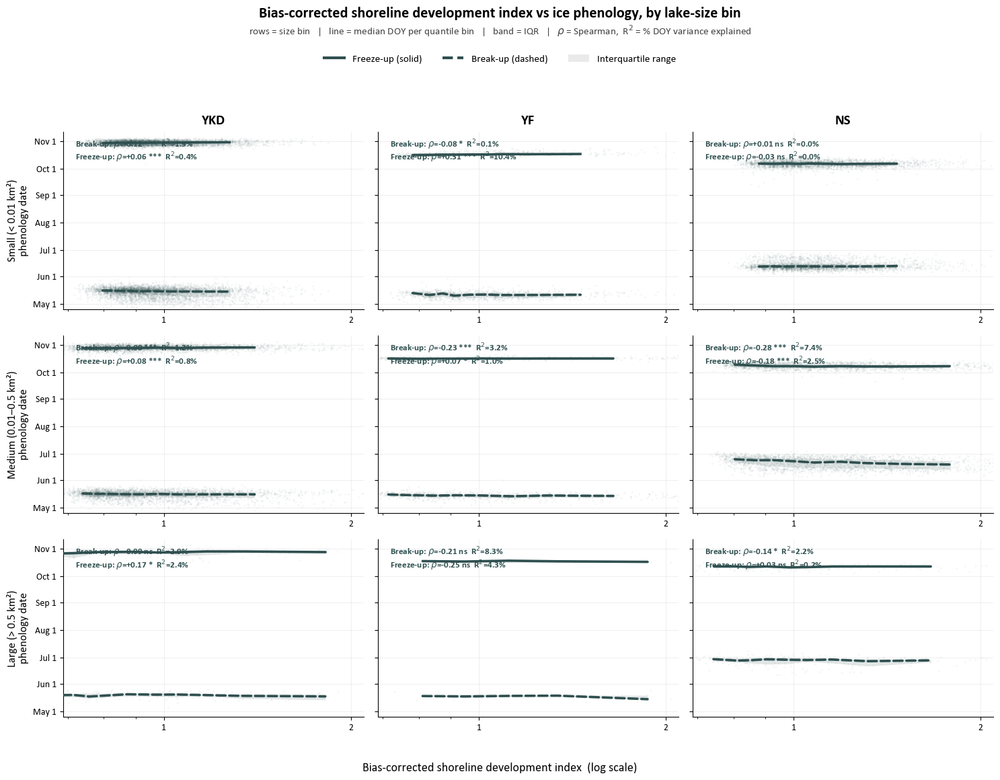

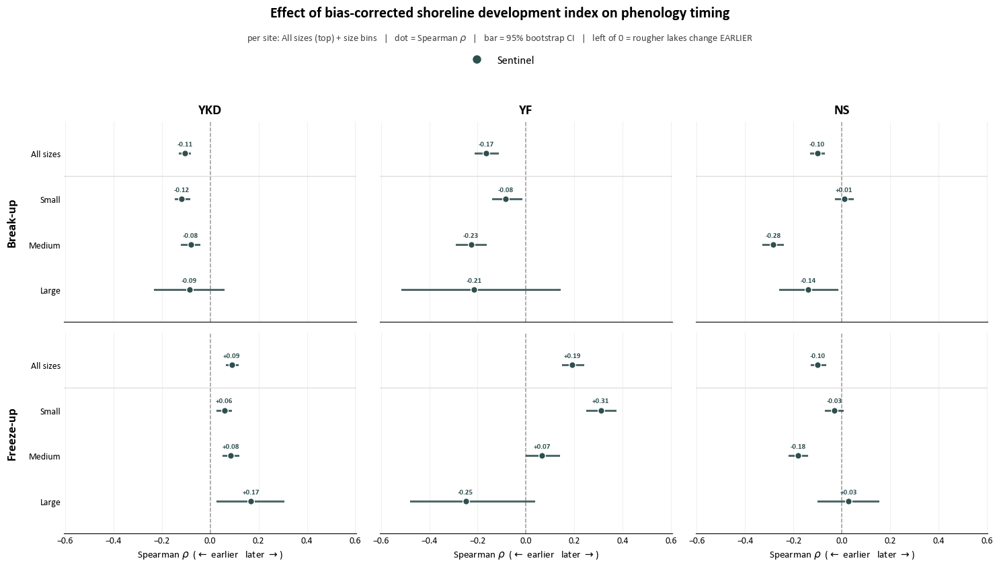

In [2]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import NullFormatter
from scipy import stats
import warnings
from datetime import datetime

plt.rcParams.update({
    "font.family":     "Calibri",
    "font.size":       11,
    "axes.titlesize":  14,
    "axes.labelsize":  12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
})

# ----------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------
TEXT_SCALE = 1.8
SITES   = ["YKD", "YF", "NS"]
SENSORS = ["PS", "S2"]            # canonical list (Planet logic kept intact)
# Sensors actually analyzed and plotted. Set ACTIVE_SENSORS = SENSORS to bring
# Planet back in; everything downstream follows this toggle.
ACTIVE_SENSORS = ["S2"]
EVENTS  = ["Break-up", "Freeze-up"]
SENSOR_LABELS = {"PS": "Planet", "S2": "Sentinel"}
CSV_TEMPLATE = r"C:\Users\nj142\Desktop\Time Series\{sensor}\{event}\{site}_{event_lower}_dates.csv"
SHP_TEMPLATE = (
    r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data"
    r"\{site} 50x50 km\{site} Lakes from ALPOD Shapefile\{site}_50x50km_lakes.shp"
)

PLANET_COLOR   = "#ffa600"
SENTINEL_COLOR = "#2f4f4f"
SENSOR_COLOR   = {"PS": PLANET_COLOR, "S2": SENTINEL_COLOR}

ID_CANDIDATES = ["lake_id", "Lake_id", "LAKE_ID", "id", "ID",
                 "alpod_id", "ALPOD_ID", "Hylak_id", "OBJECTID", "FID"]
EVENT_COL = {"Break-up": "breakup_doy", "Freeze-up": "freezeup_doy"}
# Line style encodes the event when both are overlaid on one panel.
EVENT_STYLE = {"Break-up": "--", "Freeze-up": "-"}

# Number of quantile bins for the conditional-median ribbon.
N_BINS = 9

# Lake-size bins (by net water area, km^2).  small < 0.01 <= medium <= 0.5 < large
SIZE_ORDER  = ["small", "medium", "large"]
SIZE_LABELS = {
    "small":  "Small (< 0.01 km\u00b2)",
    "medium": "Medium (0.01\u20130.5 km\u00b2)",
    "large":  "Large (> 0.5 km\u00b2)",
}
def assign_size(area_km2):
    a = np.asarray(area_km2, dtype=float)
    out = np.select([a < 0.01, (a >= 0.01) & (a <= 0.5), a > 0.5],
                    SIZE_ORDER, default=None)
    return pd.Categorical(out, categories=SIZE_ORDER, ordered=True)

# ----------------------------------------------------------------------
# Metric: bias-corrected shoreline development index (SDIbc) only
# ----------------------------------------------------------------------
METRICS = {
    "sdibc": {"label": "Bias-corrected shoreline development index",
              "unit": "", "log": True},
}
METRIC_ORDER = list(METRICS.keys())

def _xlabel(metric):
    info = METRICS[metric]
    return info["label"] if not info["unit"] else f"{info['label']} ({info['unit']})"

# ----------------------------------------------------------------------
# Bias-corrected shoreline development index  (Seekell, Cael & Byström 2022,
# GRL, 10.1029/2022GL098499)
# ----------------------------------------------------------------------
# The traditional index  D_L = L / (2*sqrt(pi*A))  is biased: because natural
# shorelines are fractal, D_L grows with lake size (~+14% per area doubling)
# even at fixed shape. The bias-corrected index replaces the area exponent in
# the denominator with d/2 (d = shoreline fractal dimension), which cancels the
# fractal area-scaling and makes the metric size-independent:
#
#       D_BC = L / (2*sqrt(pi) * A**(d/2))
#
# L and A must be in CONSISTENT units. Here both come from the UTM reprojection
# in metres and square metres, so no unit conversion is required.
D_FALLBACK       = 1.28          # global empirical default
D_BOUNDS_HARD    = (1.0, 2.0)    # valid range: 1 <= d < 2
D_BOUNDS_TYPICAL = (1.02, 1.40)  # warn outside this empirical range

def estimate_fractal_dimension(area_m2, perim_m):
    """Group-mode fractal dimension from a log-log perimeter-area regression.

    Fits  ln(L) = b0 + b1*ln(A)  over all valid lakes in the cohort and returns
    d = 2*b1. Falls back to D_FALLBACK when the fit is unusable, and
    clamps/warns when d leaves the expected range.

    Returns (d, used_fallback, n_fit).
    """
    A = np.asarray(area_m2, float)
    L = np.asarray(perim_m, float)
    ok = np.isfinite(A) & np.isfinite(L) & (A > 0) & (L > 0)
    n_fit = int(ok.sum())
    if n_fit < 10:
        warnings.warn(f"Only {n_fit} valid lakes for the fractal-dimension fit; "
                      f"using fallback d={D_FALLBACK}.")
        return float(D_FALLBACK), True, n_fit
    slope, intercept, r, p, se = stats.linregress(np.log(A[ok]), np.log(L[ok]))
    d = 2.0 * slope
    if not np.isfinite(d) or not (D_BOUNDS_HARD[0] <= d < D_BOUNDS_HARD[1]):
        warnings.warn(f"Fitted d={d:.3f} outside [1, 2); using fallback "
                      f"d={D_FALLBACK}.")
        return float(D_FALLBACK), True, n_fit
    if not (D_BOUNDS_TYPICAL[0] <= d <= D_BOUNDS_TYPICAL[1]):
        warnings.warn(f"Fitted d={d:.3f} is outside the typical range "
                      f"{D_BOUNDS_TYPICAL}; proceeding, but interpret with care "
                      f"(D_BC is sensitive to d).")
    return float(d), False, n_fit

def traditional_sdi(area_m2, perim_m):
    """Uncorrected shoreline development index  D_L = L / (2*sqrt(pi*A))."""
    A = np.asarray(area_m2, float); L = np.asarray(perim_m, float)
    bad = ~(np.isfinite(A) & np.isfinite(L)) | (A <= 0) | (L <= 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        sdi = L / (2.0 * np.sqrt(np.pi * A))
    return np.where(bad, np.nan, sdi)

def bias_corrected_sdi(area_m2, perim_m, d):
    """Bias-corrected index  D_BC = L / (2*sqrt(pi) * A**(d/2)).

    Non-positive or non-finite area/length -> NaN.
    """
    A = np.asarray(area_m2, float); L = np.asarray(perim_m, float)
    bad = ~(np.isfinite(A) & np.isfinite(L)) | (A <= 0) | (L <= 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        dbc = L / (2.0 * np.sqrt(np.pi) * np.power(A, d / 2.0))
    return np.where(bad, np.nan, dbc)

# ----------------------------------------------------------------------
# Loaders & Caches
# ----------------------------------------------------------------------
_event_cache, _morph_cache, _assemble_cache = {}, {}, {}

def load_lake_morphometrics(site):
    """
    Derive SDIbc from the actual ALPOD polygons.

    Reprojection is to the local UTM zone (conformal): it preserves shape
    almost exactly over a 50x50 km box and keeps area error well under 0.1%
    at these latitudes -- the right trade-off for shape indices, which need
    perimeter and area in the same, undistorted projection.

    Conventions:
      - area      = net water area (interior rings / islands subtracted)
      - perimeter = total boundary length, INCLUDING island shorelines
    """
    if site in _morph_cache:
        return _morph_cache[site].copy()

    gdf = gpd.read_file(SHP_TEMPLATE.format(site=site))
    id_col = next((c for c in ID_CANDIDATES if c in gdf.columns), None)
    if id_col is None:
        raise ValueError(f"No recognizable ID column in {site} shapefile; "
                         f"columns were: {list(gdf.columns)}")

    gproj   = gdf.to_crs(gdf.estimate_utm_crs())
    geom    = gproj.geometry
    area_m2 = geom.area.to_numpy()
    perim_m = geom.length.to_numpy()

    # One regional fractal dimension per site (the 50x50 km ALPOD cohort),
    # then apply it to every lake in that site.
    d, used_fallback, n_fit = estimate_fractal_dimension(area_m2, perim_m)
    tag = "fallback" if used_fallback else f"fitted from {n_fit} lakes"
    print(f"[{site}] fractal dimension d = {d:.3f}  ({tag})")

    sdibc    = bias_corrected_sdi(area_m2, perim_m, d)
    sdi_trad = traditional_sdi(area_m2, perim_m)

    out = pd.DataFrame({
        "lake_id":                gdf[id_col].to_numpy(),
        "area_km2":               area_m2 / 1e6,
        "sdibc":                  sdibc,
        "traditional_sdi":        sdi_trad,
        "fractal_dimension_used": d,
        "is_circular_baseline":   np.isclose(sdibc, 1.0, atol=0.05),
    }).replace([np.inf, -np.inf], np.nan)

    out["lake_id"] = pd.to_numeric(out["lake_id"], errors="coerce").astype("Int64").astype(str)
    _morph_cache[site] = out
    return out.copy()

def load_event(sensor, site, event):
    key = (sensor, site, event)
    if key in _event_cache:
        return _event_cache[key].copy()
    csv = CSV_TEMPLATE.format(sensor=sensor, event=event, event_lower=event.lower(), site=site)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        df = pd.read_csv(csv, low_memory=False)
    date_col = f"{event.lower()}_date"
    parsed = pd.to_datetime(df[date_col], format="%m/%d/%Y %H:%M", errors="coerce")
    if parsed.isna().mean() > 0.5:
        parsed = pd.to_datetime(df[date_col], format="mixed", errors="coerce")
    df[date_col] = parsed
    df = df.dropna(subset=[date_col])
    df["doy"] = df[date_col].dt.dayofyear
    df["lake_id"] = pd.to_numeric(df["lake_id"], errors="coerce").astype("Int64").astype(str)
    result = df.groupby("lake_id", as_index=False)["doy"].mean()
    _event_cache[key] = result
    return result.copy()

def assemble(sensor, site):
    key = (sensor, site)
    if key in _assemble_cache:
        return _assemble_cache[key].copy()
    morph = load_lake_morphometrics(site)
    bu = load_event(sensor, site, "Breakup").rename(columns={"doy": "breakup_doy"})
    fu = load_event(sensor, site, "Freezeup").rename(columns={"doy": "freezeup_doy"})
    df = morph.merge(bu, on="lake_id", how="left").merge(fu, on="lake_id", how="left")
    df["size"] = assign_size(df["area_km2"])
    _assemble_cache[key] = df
    return df.copy()

# ----------------------------------------------------------------------
# Association tests
# ----------------------------------------------------------------------
# Continuous Cuzick (rank scores) is algebraically Spearman's rho, so it is
# reported as rho. With huge n, p-values are near-automatic, so EFFECT SIZE is
# what to read: rho (monotonic strength) plus Kendall tau-b, which is robust to
# the heavy ties/clustering in these distributions.  rho > 0 / tau > 0  =>
# rougher lakes (higher SDIbc) occur LATER in the season.
def pval_stars(p):
    if not np.isfinite(p): return "ns"
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return "ns"

def association_tests(metric, response):
    m = np.asarray(metric, dtype=float)
    y = np.asarray(response, dtype=float)
    ok = np.isfinite(m) & np.isfinite(y)
    m, y = m[ok], y[ok]
    n = m.size
    out = dict(rho=np.nan, rho_p=np.nan, tau=np.nan, tau_p=np.nan, z=np.nan, n=n)
    if n < 4 or np.all(m == m[0]) or np.all(y == y[0]):
        return out
    rho, rho_p = stats.spearmanr(m, y)
    tau, tau_p = stats.kendalltau(m, y, variant="b")
    # Cuzick-style normal z (kept for continuity; equals the Spearman z-score)
    l, R = stats.rankdata(m), stats.rankdata(y)
    var = (np.sum((l - l.mean())**2) * np.sum((R - R.mean())**2)) / (n - 1)
    z = (l @ R - l.sum()*(n+1)/2.0) / np.sqrt(var) if var > 0 else np.nan
    out.update(rho=float(rho), rho_p=float(rho_p), tau=float(tau),
               tau_p=float(tau_p), z=float(z), n=n)
    return out

def run_trends(all_dfs):
    rows = []
    for sensor in ACTIVE_SENSORS:
        for site in SITES:
            df = all_dfs[(sensor, site)]
            for event in EVENTS:
                ycol = EVENT_COL[event]
                for metric in METRIC_ORDER:
                    use_log = METRICS[metric]["log"]
                    for size in ["all"] + SIZE_ORDER:
                        d = df if size == "all" else df[df["size"] == size]
                        sub = (d[[metric, ycol]]
                               .replace([np.inf, -np.inf], np.nan).dropna())
                        res = association_tests(sub[metric].values, sub[ycol].values)
                        # R^2 = % of variance in DOY explained by a linear fit on
                        # the metric (log10 scale when the axis is logarithmic),
                        # i.e. the squared Pearson correlation on that scale.
                        xv = sub[metric].to_numpy(float)
                        yv = sub[ycol].to_numpy(float)
                        if use_log:
                            keep = xv > 0
                            xv, yv = np.log10(xv[keep]), yv[keep]
                        if xv.size >= 4 and np.std(xv) > 0 and np.std(yv) > 0:
                            r2 = float(np.corrcoef(xv, yv)[0, 1] ** 2)
                        else:
                            r2 = np.nan
                        res.update(sensor=sensor, site=site, event=event, metric=metric,
                                   size=size, r2=r2, stars=pval_stars(res["rho_p"]))
                        rows.append(res)
    return pd.DataFrame(rows)

def print_trend_summary(trend_df):
    print("\n" + "=" * 100)
    print("MONOTONIC ASSOCIATION: SDIbc vs phenology DOY, by lake-size bin")
    print("rho/tau = effect size (rho>0 => rougher lakes LATER).  R2 = % of DOY")
    print("variance explained by SDIbc (linear fit on log10 SDIbc).")
    print("(Lakes are spatially autocorrelated, so p-values are optimistic.)")
    print("=" * 100)
    metric = METRIC_ORDER[0]
    for event in EVENTS:
        print(f"\n{'-'*46}  {event.upper()}  {'-'*46}")
        sub = trend_df[(trend_df["event"] == event) & (trend_df["metric"] == metric)]
        for site in SITES:
            print(f"\n  {site}")
            ss = sub[sub["site"] == site]
            for sensor in ACTIVE_SENSORS:
                print(f"    [{SENSOR_LABELS[sensor]}]")
                for size in ["all"] + SIZE_ORDER:
                    row = ss[(ss["sensor"] == sensor) & (ss["size"] == size)]
                    if row.empty:
                        continue
                    r = row.iloc[0]
                    name = "all sizes" if size == "all" else SIZE_LABELS[size]
                    if not np.isfinite(r["rho"]):
                        print(f"      {name:<22}  n={int(r['n']):>5d}  (insufficient)")
                        continue
                    r2pct = f"{100*r['r2']:5.2f}%" if np.isfinite(r.get("r2", np.nan)) else "  n/a"
                    print(f"      {name:<22}  rho={r['rho']:+.3f} {r['stars']:3s}  "
                          f"tau={r['tau']:+.3f}  R2={r2pct}  n={int(r['n']):>5d}")
    print("=" * 100 + "\n")

def print_sample_sizes(all_dfs):
    print("\n" + "=" * 72)
    print("SAMPLE SIZES by size bin (lakes with a phenology date AND finite SDIbc)")
    print("=" * 72)
    for event in EVENTS:
        col = EVENT_COL[event]
        print(f"\n{event}:")
        hdr = f"  {'Site':<6}{'Sensor':<11}" + "".join(f"{s:>10}" for s in SIZE_ORDER) + f"{'all':>10}"
        print(hdr); print("  " + "-" * (len(hdr) - 2))
        for site in SITES:
            for sensor in ACTIVE_SENSORS:
                df = all_dfs[(sensor, site)]
                valid = df[df[col].notna() & df["sdibc"].notna()]
                counts = [int((valid["size"] == s).sum()) for s in SIZE_ORDER]
                line = f"  {site:<6}{SENSOR_LABELS[sensor]:<11}" + \
                       "".join(f"{c:>10d}" for c in counts) + f"{len(valid):>10d}"
                print(line)
    print("=" * 72 + "\n")

# ----------------------------------------------------------------------
# Conditional-median ribbon  (quantile bins -> median line + IQR band)
# ----------------------------------------------------------------------
def binned_median_band(x, y, n_bins=N_BINS):
    """Quantile-bin x; return per-bin (median x, median y, Q25 y, Q75 y).

    Quantile bins put equal counts per bin, so they concentrate where the data
    actually live -- which is exactly the clustered region that a straight line
    reads poorly. The band is the interquartile spread of DOY within each bin.
    """
    x = np.asarray(x, float); y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    if x.size < 12:
        return (np.array([]),) * 4
    nb = max(3, min(n_bins, x.size // 8))
    edges = np.unique(np.quantile(x, np.linspace(0, 1, nb + 1)))
    if edges.size < 3:
        return (np.array([]),) * 4
    idx = np.clip(np.digitize(x, edges[1:-1]), 0, edges.size - 2)
    bx, med, q1, q3 = [], [], [], []
    for b in range(edges.size - 1):
        yy, xx = y[idx == b], x[idx == b]
        if yy.size < 3:
            continue
        bx.append(np.median(xx)); med.append(np.median(yy))
        q1.append(np.percentile(yy, 25)); q3.append(np.percentile(yy, 75))
    order = np.argsort(bx)
    return (np.array(bx)[order], np.array(med)[order],
            np.array(q1)[order], np.array(q3)[order])

def make_metric_figure(all_dfs, trend_df, metric, ylim):
    """Relationship figure: rows = size bin, cols = site, BOTH events overlaid.

    Within each panel and for each active sensor, the median-DOY line is drawn
    across quantile bins of the metric for both events: freeze-up SOLID,
    break-up DASHED (the two seasons appear as separate horizontal bands on the
    shared date axis). Each event is annotated with its Spearman rho and the
    % of DOY variance it explains (R^2). Reading DOWN a column shows whether
    the SDIbc->timing relationship changes with lake size.
    """
    info    = METRICS[metric]
    use_log = info["log"]
    ylo, yhi = ylim

    xall = np.concatenate([all_dfs[(sn, s)][metric].to_numpy(dtype=float)
                           for sn in ACTIVE_SENSORS for s in SITES])
    xall = xall[np.isfinite(xall)]
    if use_log:
        xall = xall[xall > 0]
    xlo, xhi = (np.nanpercentile(xall, [0.5, 99.5]) if xall.size else (0.1, 1.0))

    fig, axes = plt.subplots(len(SIZE_ORDER), len(SITES), figsize=(15, 12))
    for r_i, size in enumerate(SIZE_ORDER):
        for c_i, site in enumerate(SITES):
            ax = axes[r_i, c_i]
            for sensor in ACTIVE_SENSORS:
                col = SENSOR_COLOR[sensor]
                dfs = all_dfs[(sensor, site)]
                dfs = dfs[dfs["size"] == size]
                for event in EVENTS:
                    ycol = EVENT_COL[event]
                    x = dfs[metric].to_numpy(dtype=float)
                    y = dfs[ycol].to_numpy(dtype=float)
                    ok = np.isfinite(x) & np.isfinite(y)
                    if use_log:
                        ok &= x > 0
                    x, y = x[ok], y[ok]
                    ax.scatter(x, y, s=4, alpha=0.05, color=col, edgecolors="none",
                               rasterized=True)
                    bx, med, q1, q3 = binned_median_band(x, y)
                    if bx.size >= 2:
                        ax.fill_between(bx, q1, q3, color=col, alpha=0.14, linewidth=0)
                        ax.plot(bx, med, color=col, lw=2.6, ls=EVENT_STYLE[event],
                                solid_capstyle="round", dash_capstyle="round", zorder=5)

            # per-event annotation: rho + variance explained (R^2)
            ytxt = 0.97
            for sensor in ACTIVE_SENSORS:
                for event in EVENTS:
                    r = trend_df[(trend_df["event"] == event) & (trend_df["site"] == site) &
                                 (trend_df["metric"] == metric) & (trend_df["size"] == size) &
                                 (trend_df["sensor"] == sensor)]
                    if r.empty or not np.isfinite(r.iloc[0]["rho"]):
                        continue
                    r = r.iloc[0]
                    r2pct = f"{100*r['r2']:.1f}%" if np.isfinite(r.get("r2", np.nan)) else "n/a"
                    tag = event + (f" \u00b7 {SENSOR_LABELS[sensor]}"
                                   if len(ACTIVE_SENSORS) > 1 else "")
                    ax.text(0.04, ytxt,
                            f"{tag}: $\\rho$={r['rho']:+.2f} {r['stars']}  R$^2$={r2pct}",
                            transform=ax.transAxes, ha="left", va="top",
                            color=SENSOR_COLOR[sensor], fontsize=9.5, fontweight="bold")
                    ytxt -= 0.075

            if use_log:
                ax.set_xscale("log")
                cand = np.array([0.5, 1, 2, 3, 4, 5, 6, 8, 10])
                tk = cand[(cand >= xlo) & (cand <= xhi)]
                if tk.size:
                    ax.set_xticks(tk)
                    ax.set_xticklabels([f"{t:g}" for t in tk])
                ax.xaxis.set_minor_formatter(NullFormatter())
            ax.set_xlim(xlo, xhi)
            ax.set_ylim(ylo, yhi)
            dticks, dlabels = date_ticks_for_range(int(np.floor(ylo)), int(np.ceil(yhi)))
            ax.set_yticks(dticks); ax.set_yticklabels(dlabels)
            ax.tick_params(axis="both", labelsize=10)
            ax.grid(True, alpha=0.18)
            for sp in ("top", "right"):
                ax.spines[sp].set_visible(False)
            if r_i == 0:
                ax.set_title(site, fontsize=15, fontweight="bold", pad=8)
            if c_i == 0:
                ax.set_ylabel(f"{SIZE_LABELS[size]}\nphenology date", fontsize=12)
            else:
                ax.tick_params(labelleft=False)

    fig.supxlabel(_xlabel(metric) + ("  (log scale)" if use_log else ""),
                  fontsize=13, y=0.04)
    handles = []
    if len(ACTIVE_SENSORS) > 1:
        handles += [Line2D([0], [0], color=SENSOR_COLOR[s], lw=3, label=SENSOR_LABELS[s])
                    for s in ACTIVE_SENSORS]
    line_col = SENSOR_COLOR[ACTIVE_SENSORS[0]] if len(ACTIVE_SENSORS) == 1 else "#555"
    handles += [
        Line2D([0], [0], color=line_col, lw=3, ls="-",  label="Freeze-up (solid)"),
        Line2D([0], [0], color=line_col, lw=3, ls="--", label="Break-up (dashed)"),
        Patch(facecolor="gray", alpha=0.16, label="Interquartile range"),
    ]
    fig.subplots_adjust(top=0.88)
    fig.suptitle(f"{info['label']} vs ice phenology, by lake-size bin",
                 fontsize=16, fontweight="bold", y=0.99)
    fig.text(0.5, 0.955,
             "rows = size bin   |   line = median DOY per quantile bin   |   band = IQR   |   "
             r"$\rho$ = Spearman,  R$^2$ = % DOY variance explained",
             ha="center", fontsize=11, color="#444")
    fig.legend(handles=handles, loc="center", ncol=len(handles), frameon=False,
               fontsize=11, bbox_to_anchor=(0.5, 0.925))
    plt.tight_layout(rect=[0, 0.05, 1, 0.90])
    plt.show()

# ----------------------------------------------------------------------
# Date axis helper
# ----------------------------------------------------------------------
def date_ticks_for_range(doy_lo, doy_hi):
    # Thin the ticks as the date span widens so labels never crowd.
    span = doy_hi - doy_lo
    days = (1,) if span > 150 else (1, 15) if span > 70 else (5, 15, 25)
    ticks, labels = [], []
    for month in range(1, 13):
        for day in days:
            d = datetime(2023, month, day)
            doy = d.timetuple().tm_yday
            if doy_lo <= doy <= doy_hi:
                ticks.append(doy)
                labels.append(f"{d.strftime('%b')} {d.day}")
    return ticks, labels

def _event_ylims(all_dfs, lo_pct=1.5, hi_pct=98.5, frac=0.10):
    """Robust per-event y-limits (clip to ~central 97% so a few late/early
    outliers don't compress the band where the data actually live)."""
    out = {}
    for ev in EVENTS:
        pooled = pd.concat([all_dfs[(sn, s)][EVENT_COL[ev]].dropna()
                            for sn in ACTIVE_SENSORS for s in SITES])
        if pooled.empty:
            out[ev] = (0, 365); continue
        lo, hi = np.nanpercentile(pooled.to_numpy(), [lo_pct, hi_pct])
        pad = (hi - lo) * frac
        out[ev] = (lo - pad, hi + pad)
    return out

def _combined_ylim(all_dfs, lo_pct=1.0, hi_pct=99.0, frac=0.05):
    """Single y-range spanning both events (both seasons share one date axis)."""
    cols = [EVENT_COL[ev] for ev in EVENTS]
    pooled = pd.concat([all_dfs[(sn, s)][c].dropna()
                        for sn in ACTIVE_SENSORS for s in SITES for c in cols])
    if pooled.empty:
        return (0, 365)
    lo, hi = np.nanpercentile(pooled.to_numpy(), [lo_pct, hi_pct])
    pad = (hi - lo) * frac
    return (lo - pad, hi + pad)

# ----------------------------------------------------------------------
# Effect-size forest plot: Spearman rho with bootstrap 95% CI.
# rows = site x sensor, one facet per event. Clearer than a 1-column heatmap:
# direction, magnitude, and whether the CI clears zero are all readable at once.
# ----------------------------------------------------------------------
def boot_rho_ci(x, y, n_boot=500, seed=0):
    x = np.asarray(x, float); y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    if x.size < 8:
        return np.nan, np.nan, np.nan
    rho = stats.spearmanr(x, y)[0]
    rg = np.random.default_rng(seed); n = x.size; bs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rg.integers(0, n, n)
        bs[i] = stats.spearmanr(x[idx], y[idx])[0]
    return float(rho), float(np.nanpercentile(bs, 2.5)), float(np.nanpercentile(bs, 97.5))

def make_effectsize_figure(all_dfs, metric="sdibc", n_boot=500):
    """Small-multiples forest plot: 2 rows (events) x 3 cols (sites).

    Each small panel shows Spearman rho with a 95% bootstrap CI for that site
    and event: a top "All sizes" row (everything combined for the site) plus
    the three size bins below it. Sensors are offset within a row (centred when
    only one is active). A shared x-axis lets you compare magnitudes across the
    whole grid.
    """
    size_rows  = ["all"] + SIZE_ORDER
    size_labels = ["All sizes"] + [s.capitalize() for s in SIZE_ORDER]
    if len(ACTIVE_SENSORS) == 1:
        offset = {ACTIVE_SENSORS[0]: 0.0}
    else:
        offs = np.linspace(0.16, -0.16, len(ACTIVE_SENSORS))
        offset = {sn: float(o) for sn, o in zip(ACTIVE_SENSORS, offs)}

    def subset(df, size):
        return df if size == "all" else df[df["size"] == size]

    cache, max_abs = {}, 0.0
    for ev in EVENTS:
        ycol = EVENT_COL[ev]
        for site in SITES:
            for size in size_rows:
                for sensor in ACTIVE_SENSORS:
                    d = subset(all_dfs[(sensor, site)], size)
                    rho, lo, hi = boot_rho_ci(d[metric].to_numpy(float),
                                              d[ycol].to_numpy(float), n_boot=n_boot,
                                              seed=abs(hash((ev, site, size, sensor))) % 100000)
                    cache[(ev, site, size, sensor)] = (rho, lo, hi)
                    if np.isfinite(lo):
                        max_abs = max(max_abs, abs(lo), abs(hi))
    xlim = max(0.30, max_abs * 1.18)

    n_in = len(size_rows)
    fig, axes = plt.subplots(len(EVENTS), len(SITES), figsize=(15, 8.5),
                             sharex=True, sharey=True)
    axes = np.atleast_2d(axes)
    for r_i, ev in enumerate(EVENTS):
        for c_i, site in enumerate(SITES):
            ax = axes[r_i, c_i]
            ys = np.arange(n_in)[::-1]               # "All" at top
            for ypos, size in zip(ys, size_rows):
                for sensor in ACTIVE_SENSORS:
                    rho, lo, hi = cache[(ev, site, size, sensor)]
                    if not np.isfinite(rho):
                        continue
                    yy = ypos + offset[sensor]
                    col = SENSOR_COLOR[sensor]
                    ax.plot([lo, hi], [yy, yy], color=col, lw=2.2, alpha=0.85, zorder=3)
                    ax.plot(rho, yy, "o", color=col, ms=7, zorder=4,
                            markeredgecolor="white", markeredgewidth=1.0)
                    dy = 8 if offset[sensor] >= 0 else -12
                    ax.annotate(f"{rho:+.2f}", (rho, yy), textcoords="offset points",
                                xytext=(0, dy), ha="center", fontsize=8,
                                color=col, fontweight="bold")
            ax.axvline(0, color="#999", lw=1.1, ls="--", zorder=1)
            ax.axhline(n_in - 1.5, color="lightgray", lw=0.9, alpha=0.8)  # under "All"
            ax.set_ylim(-0.7, n_in - 0.3)
            ax.set_xlim(-xlim, xlim)
            ax.grid(axis="x", alpha=0.18)
            for sp in ("top", "right", "left"):
                ax.spines[sp].set_visible(False)
            ax.tick_params(length=0, labelsize=10)
            if r_i == 0:
                ax.set_title(site, fontsize=15, fontweight="bold", pad=8)
            if c_i == 0:
                ax.set_yticks(ys); ax.set_yticklabels(size_labels, fontsize=10)
                ax.set_ylabel(ev, fontsize=14, fontweight="bold", labelpad=12)
            if r_i == len(EVENTS) - 1:
                ax.set_xlabel(r"Spearman $\rho$  ($\leftarrow$ earlier   later $\rightarrow$)",
                              fontsize=11)

    handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=SENSOR_COLOR[s],
                      markersize=10, label=SENSOR_LABELS[s]) for s in ACTIVE_SENSORS]
    fig.subplots_adjust(top=0.84)
    fig.suptitle(f"Effect of {METRICS[metric]['label'].lower()} on phenology timing",
                 fontsize=16, fontweight="bold", y=0.99)
    fig.text(0.5, 0.93, "per site: All sizes (top) + size bins   |   dot = Spearman $\\rho$   |   "
             "bar = 95% bootstrap CI   |   left of 0 = rougher lakes change EARLIER",
             ha="center", fontsize=10.5, color="#444")
    fig.legend(handles=handles, loc="center", ncol=len(handles), frameon=False,
               fontsize=12, bbox_to_anchor=(0.5, 0.895))
    plt.tight_layout(rect=[0, 0, 1, 0.88])
    plt.show()

# ----------------------------------------------------------------------
# Entry point
# ----------------------------------------------------------------------
if __name__ == "__main__":
    all_dfs = {(sn, s): assemble(sn, s) for sn in ACTIVE_SENSORS for s in SITES}

    trend_df = run_trends(all_dfs)
    print_trend_summary(trend_df)
    print_sample_sizes(all_dfs)

    ylim = _combined_ylim(all_dfs)
    for metric in METRIC_ORDER:
        make_metric_figure(all_dfs, trend_df, metric, ylim)

    make_effectsize_figure(all_dfs)


# BREAKUP AND FREEZEUP DURATION SCRIPTS BELOW

Loading data …


C:\Users\nj142\AppData\Local\Temp\ipykernel_7540\3649123268.py:131: DtypeWarning: Columns (149,150,153,154) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(bu_path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_7540\3649123268.py:144: DtypeWarning: Columns (71,72,75,76,79,80) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(fu_path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_7540\3649123268.py:131: DtypeWarning: Columns (181,182,185,186,189,190,193,194,197,198,201,202,205,206,209,210,213,214) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(bu_path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_7540\3649123268.py:131: DtypeWarning: Columns (85,86,89,90,93,94) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(bu_path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_7540\3649123268.py:144: DtypeWarning: Columns (39,40,43,


SITE-WIDE BREAKUP DURATION STATISTICS
                      mean  median       std  count
site sensor                                        
NS   Planet       8.427354     6.0  9.028999  32617
     Sentinel-2   8.368615     7.0  6.142129  38707
YF   Planet       8.678882     7.0  6.269851  12634
     Sentinel-2   7.257249     7.0  4.900133  12416
YKD  Planet      11.469785     9.0  8.841351  55470
     Sentinel-2  13.415488    12.0  8.434890  57075

TWO-TAILED WELCH T-TEST — BREAKUP DURATION
H0: size classes share the same mean duration
delta_mean = mean(larger) − mean(smaller); + = larger lakes take longer
Stars: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant

  [Planet]
    YKD:
      S→M     Δ=  +1.1 d  p=0.0000 ***  (longer: n=31021,23138)
      M→L     Δ=  +1.9 d  p=0.0000 ***  (longer: n=23138,1311)
      S→L     Δ=  +3.0 d  p=0.0000 ***  (longer: n=31021,1311)
    YF:
      S→M     Δ=  +1.6 d  p=0.0000 ***  (longer: n=6150,6188)
      M→L     Δ=  +2.2 d  p=0.0000 ***  

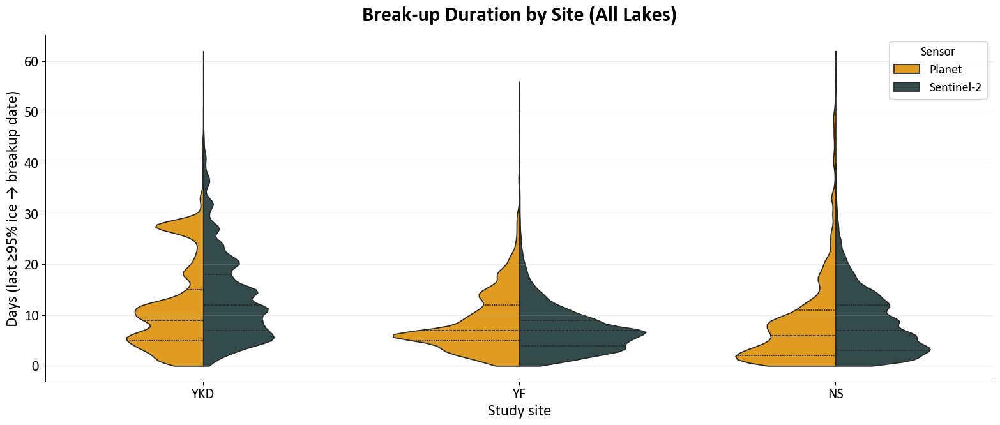

c:\Users\nj142\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9650 (\N{BLACK UP-POINTING TRIANGLE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\nj142\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9660 (\N{BLACK DOWN-POINTING TRIANGLE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


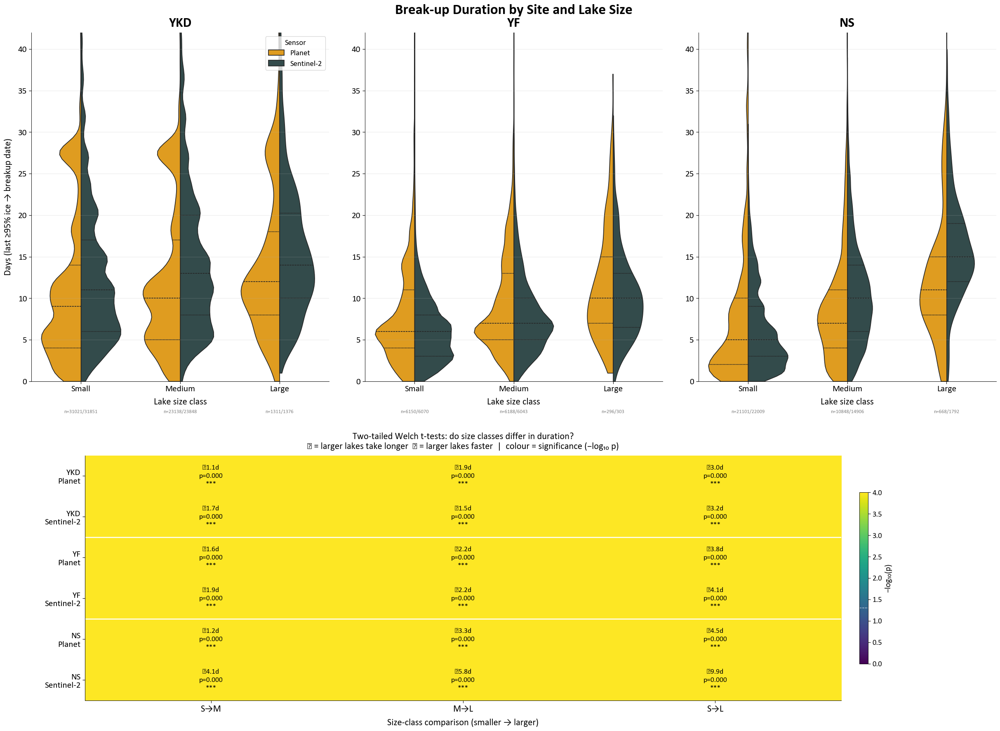


SITE-WIDE FREEZE-UP DURATION STATISTICS
                      mean  median       std  count
site sensor                                        
NS   Planet       7.615782     5.0  6.395346  15080
     Sentinel-2   7.214703     6.0  4.839463  14732
YF   Planet       8.890158     9.0  4.595800   8139
     Sentinel-2   8.394580     9.0  4.454158  11734
YKD  Planet       9.299464     7.0  6.685225  47575
     Sentinel-2  12.670045     9.0  8.950644  48443

TWO-TAILED WELCH T-TEST — FREEZE-UP DURATION
H0: size classes share the same mean duration
delta_mean = mean(larger) − mean(smaller); + = larger lakes take longer
Stars: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant

  [Planet]
    YKD:
      S→M     Δ=  +0.1 d  p=0.0619 ns   (longer: n=27103,19510)
      M→L     Δ=  +2.1 d  p=0.0000 ***  (longer: n=19510,962)
      S→L     Δ=  +2.2 d  p=0.0000 ***  (longer: n=27103,962)
    YF:
      S→M     Δ=  +0.5 d  p=0.0000 ***  (longer: n=3976,3985)
      M→L     Δ=  +0.6 d  p=0.0531 ns 

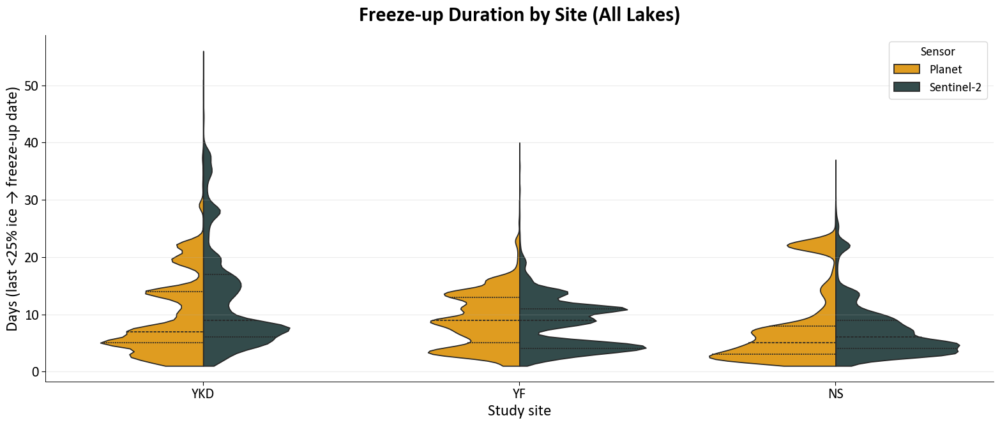

c:\Users\nj142\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9650 (\N{BLACK UP-POINTING TRIANGLE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\nj142\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9660 (\N{BLACK DOWN-POINTING TRIANGLE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


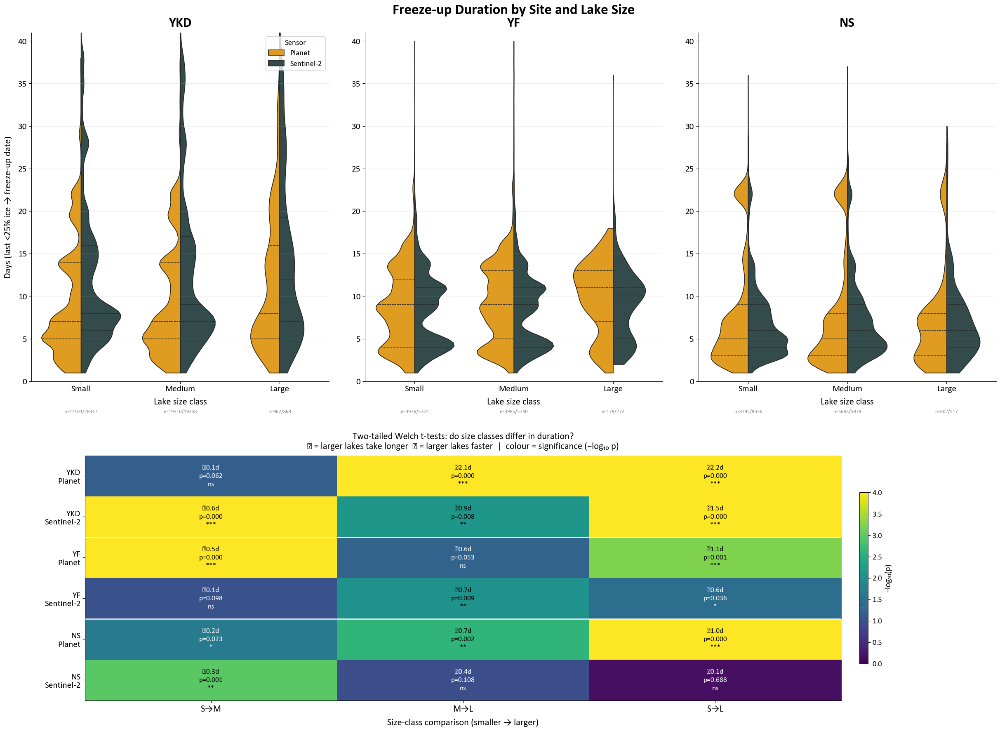

In [60]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from pathlib import Path
import warnings

# ============================================================================
# CONFIGURATION & STYLE
# ============================================================================
TEXT_SCALE = 1.8
plt.rcParams["font.family"] = "Calibri"
plt.rcParams["font.size"]   = 10 * TEXT_SCALE

SITES   = ["YKD", "YF", "NS"]
SENSORS = ["PS", "S2"]
SENSOR_LABELS = {"PS": "Planet", "S2": "Sentinel-2"}

PLANET_COLOR   = "#ffa600"
SENTINEL_COLOR = "#2f4f4f"

SMALL_THRESHOLD  = 0.01
MEDIUM_THRESHOLD = 0.5
SIZE_ORDER       = ["Small", "Medium", "Large"]
SIZE_SHORT_LABEL = {"Small": "S", "Medium": "M", "Large": "L"}

# Duration thresholds
BREAKUP_ICE_THRESHOLD  = 95.0   # last obs >= 95 % ice before breakup date
FREEZEUP_ICE_THRESHOLD = 25.0   # last obs <  25 % ice before freeze-up date

BASE_DIR     = Path(r"C:\Users\nj142\Desktop\Time Series")
SHP_TEMPLATE = (
    r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data"
    r"\{site} 50x50 km\{site} Lakes from ALPOD Shapefile\{site}_50x50km_lakes.shp"
)

ID_CANDIDATES = ["lake_id", "Lake_id", "LAKE_ID", "id", "ID",
                 "alpod_id", "ALPOD_ID", "Hylak_id", "OBJECTID", "FID"]
TTEST_PAIRS   = [("Small", "Medium"), ("Medium", "Large"), ("Small", "Large")]

# ============================================================================
# HELPERS
# ============================================================================
_areas_cache = {}

def get_lake_sizes(site):
    """Return DataFrame with lake_id and size_class."""
    if site in _areas_cache:
        return _areas_cache[site].copy()
    try:
        gdf    = gpd.read_file(SHP_TEMPLATE.format(site=site))
        id_col = next((c for c in ID_CANDIDATES if c in gdf.columns), gdf.columns[0])
        gdf_p  = gdf.to_crs("EPSG:6933") if gdf.crs.is_geographic else gdf
        gdf["area_km2"]   = gdf_p.geometry.area / 1e6
        gdf["size_class"] = gdf["area_km2"].apply(
            lambda a: "Small" if a < SMALL_THRESHOLD
                      else ("Medium" if a < MEDIUM_THRESHOLD else "Large")
        )
        out = gdf[[id_col, "size_class"]].rename(columns={id_col: "lake_id"}).copy()
        out["lake_id"] = out["lake_id"].astype(str)
    except Exception:
        out = pd.DataFrame(columns=["lake_id", "size_class"])
    _areas_cache[site] = out
    return out.copy()


def _obs_columns(row):
    """Return list of PctIce column names present in row."""
    return [c for c in row.index if "PctIce" in str(c)]


def calc_breakup_duration(row):
    """Days from last ≥95 % ice obs to breakup date."""
    if pd.isna(row["breakup_date"]):
        return np.nan
    breakup_dt = pd.to_datetime(row["breakup_date"])
    valid = []
    for col in _obs_columns(row):
        obs_num  = col.replace("Obs", "").replace("PctIce", "")
        date_col = f"Obs{obs_num}Date"
        ice_val  = row[col]
        obs_date = pd.to_datetime(row.get(date_col, np.nan), errors="coerce")
        if pd.notna(ice_val) and ice_val != "" and pd.notna(obs_date):
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                if float(ice_val) >= BREAKUP_ICE_THRESHOLD and obs_date < breakup_dt:
                    valid.append(obs_date)
    return (breakup_dt - max(valid)).days if valid else np.nan


def calc_freezeup_duration(row):
    """Days from last <25 % ice obs to freeze-up date."""
    if pd.isna(row["freezeup_date"]):
        return np.nan
    freeze_dt = pd.to_datetime(row["freezeup_date"])
    valid = []
    for col in _obs_columns(row):
        obs_num  = col.replace("Obs", "").replace("PctIce", "")
        date_col = f"Obs{obs_num}Date"
        ice_val  = row[col]
        obs_date = pd.to_datetime(row.get(date_col, np.nan), errors="coerce")
        if pd.notna(ice_val) and ice_val != "" and pd.notna(obs_date):
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                if float(ice_val) < FREEZEUP_ICE_THRESHOLD and obs_date < freeze_dt:
                    valid.append(obs_date)
    return (freeze_dt - max(valid)).days if valid else np.nan

# ============================================================================
# DATA LOADING
# ============================================================================

def load_duration_data():
    """
    Returns two DataFrames (breakup_df, freezeup_df) each with columns:
      site, sensor, size_class, duration_days
    """
    breakup_rows, freezeup_rows = [], []

    for sensor in SENSORS:
        label = SENSOR_LABELS[sensor]
        for site in SITES:
            sizes = get_lake_sizes(site)

            # --- Breakup ---
            bu_path = BASE_DIR / sensor / "Breakup" / f"{site}_breakup_dates.csv"
            if bu_path.exists():
                df = pd.read_csv(bu_path)
                df["lake_id"] = df["lake_id"].astype(str)
                df = df.merge(sizes, on="lake_id", how="left")
                df["duration_days"] = df.apply(calc_breakup_duration, axis=1)
                df["sensor"] = label
                df["site"]   = site
                breakup_rows.append(
                    df[["site", "sensor", "size_class", "duration_days"]].dropna()
                )

            # --- Freeze-up ---
            fu_path = BASE_DIR / sensor / "Freezeup" / f"{site}_freezeup_dates.csv"
            if fu_path.exists():
                df = pd.read_csv(fu_path)
                df["lake_id"] = df["lake_id"].astype(str)
                df = df.merge(sizes, on="lake_id", how="left")
                df["duration_days"] = df.apply(calc_freezeup_duration, axis=1)
                df["sensor"] = label
                df["site"]   = site
                freezeup_rows.append(
                    df[["site", "sensor", "size_class", "duration_days"]].dropna()
                )

    bu_df = pd.concat(breakup_rows)  if breakup_rows  else pd.DataFrame()
    fu_df = pd.concat(freezeup_rows) if freezeup_rows else pd.DataFrame()
    return bu_df, fu_df

# ============================================================================
# T-TESTS
# ============================================================================

def pval_stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return "ns"


def run_duration_ttests(df, event_label):
    """
    Two-tailed Welch t-test on duration_days for every (sensor, site, pair).
    delta_mean = mean(larger class) − mean(smaller class).
    """
    results = []
    for sensor in SENSOR_LABELS.values():
        for site in SITES:
            sub = df[(df["sensor"] == sensor) & (df["site"] == site)]
            for cls_a, cls_b in TTEST_PAIRS:
                vals_a = sub.loc[sub["size_class"] == cls_a, "duration_days"].dropna().values
                vals_b = sub.loc[sub["size_class"] == cls_b, "duration_days"].dropna().values
                if len(vals_a) < 3 or len(vals_b) < 3:
                    continue
                t_stat, p_two = stats.ttest_ind(vals_b, vals_a, equal_var=False)
                results.append({
                    "event":      event_label,
                    "sensor":     sensor,
                    "site":       site,
                    "pair_label": f"{SIZE_SHORT_LABEL[cls_a]}→{SIZE_SHORT_LABEL[cls_b]}",
                    "small_cls":  cls_a,
                    "large_cls":  cls_b,
                    "n_small":    len(vals_a),
                    "n_large":    len(vals_b),
                    "mean_small": vals_a.mean(),
                    "mean_large": vals_b.mean(),
                    "delta_mean": vals_b.mean() - vals_a.mean(),
                    "t_stat":     t_stat,
                    "p_value":    p_two,
                    "stars":      pval_stars(p_two),
                })
    return pd.DataFrame(results)


def print_ttest_summary(ttest_df, event_label):
    print("\n" + "="*80)
    print(f"TWO-TAILED WELCH T-TEST — {event_label.upper()} DURATION")
    print("H0: size classes share the same mean duration")
    print("delta_mean = mean(larger) − mean(smaller); + = larger lakes take longer")
    print("Stars: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant")
    print("="*80)
    for sensor in SENSOR_LABELS.values():
        print(f"\n  [{sensor}]")
        s = ttest_df[ttest_df["sensor"] == sensor]
        for site in SITES:
            print(f"    {site}:")
            ss = s[s["site"] == site]
            for _, row in ss.iterrows():
                direction = "longer" if row["delta_mean"] > 0 else "SHORTER"
                print(
                    f"      {row['pair_label']:6s}  Δ={row['delta_mean']:+6.1f} d  "
                    f"p={row['p_value']:.4f} {row['stars']:3s}  "
                    f"({direction}: n={row['n_small']},{row['n_large']})"
                )
    print("="*80)

# ============================================================================
# FIGURES
# ============================================================================

def make_violin_figure(df, ttest_df, event_label, y_label):
    """
    Two-panel figure per event:
      Top row  : site-wide split violins (one panel per site, 3 panels)
      Bottom   : single viridis heatmap of t-test significance
    """
    sensor_palette = {
        SENSOR_LABELS["PS"]: PLANET_COLOR,
        SENSOR_LABELS["S2"]: SENTINEL_COLOR,
    }
    pairs      = ["S→M", "M→L", "S→L"]
    row_labels = [f"{site}\n{SENSOR_LABELS[sn]}" for site in SITES for sn in SENSORS]
    n_rows     = len(row_labels)
    n_cols     = len(pairs)

    fig = plt.figure(figsize=(26, 18))
    # 2 rows: violins on top, heatmap on bottom
    gs_top = fig.add_gridspec(1, 3, top=0.93, bottom=0.46,
                              left=0.07, right=0.97, wspace=0.12)
    gs_bot = fig.add_gridspec(1, 1, top=0.36, bottom=0.03,
                              left=0.12, right=0.97)

    # ── Violin panels ──────────────────────────────────────────────────────
    axes_v = [fig.add_subplot(gs_top[i]) for i in range(3)]
    all_valid = df["duration_days"].dropna()
    y_lo = max(0, all_valid.quantile(0.01) - 5)
    y_hi = all_valid.quantile(0.99) + 5

    for i, site in enumerate(SITES):
        ax = axes_v[i]
        site_data = df[df["site"] == site]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            sns.violinplot(
                ax=ax,
                data=site_data,
                x="size_class",
                y="duration_days",
                hue="sensor",
                split=True,
                inner="quart",
                order=SIZE_ORDER,
                palette=sensor_palette,
                cut=0,
            )
        ax.set_title(site, fontsize=13 * TEXT_SCALE, fontweight="bold", pad=10)
        ax.set_xlabel("Lake size class", fontsize=9 * TEXT_SCALE, labelpad=8)
        ax.set_ylabel(y_label if i == 0 else "", fontsize=9 * TEXT_SCALE, labelpad=10)
        ax.set_ylim(y_lo, y_hi)
        ax.grid(axis="y", alpha=0.25)
        ax.tick_params(labelsize=8.5 * TEXT_SCALE)

        # Sample-size annotations below x-tick labels
        for j, sc in enumerate(SIZE_ORDER):
            counts = []
            for sn in SENSOR_LABELS.values():
                n = site_data[site_data["sensor"] == sn]["size_class"].eq(sc).sum()
                counts.append(n)
            label = (f"n={counts[0]}" if len(set(counts)) == 1
                     else f"n={counts[0]}/{counts[1]}")
            ax.text(j, -0.08, label, ha="center", va="top",
                    fontsize=5 * TEXT_SCALE, color="gray",
                    transform=ax.get_xaxis_transform())

        # Legend only on first panel; remove from others
        if i == 0:
            ax.legend(title="Sensor", fontsize=7.5 * TEXT_SCALE,
                      title_fontsize=7.5 * TEXT_SCALE, loc="upper right")
        else:
            legend = ax.get_legend()
            if legend:
                legend.remove()

    fig.text(
        0.52, 0.955, f"{event_label} Duration by Site and Lake Size",
        ha="center", fontsize=14 * TEXT_SCALE, fontweight="bold"
    )

    # ── T-test heatmap ─────────────────────────────────────────────────────
    ax_h = fig.add_subplot(gs_bot[0])

    delta_mat = np.zeros((n_rows, n_cols))
    p_mat     = np.ones((n_rows, n_cols))

    for r_idx, (site, sensor) in enumerate(
        [(s, sn) for s in SITES for sn in SENSOR_LABELS.values()]
    ):
        row_data = ttest_df[(ttest_df["site"] == site) & (ttest_df["sensor"] == sensor)]
        for c_idx, pair in enumerate(pairs):
            match = row_data[row_data["pair_label"] == pair]
            if not match.empty:
                delta_mat[r_idx, c_idx] = match["delta_mean"].values[0]
                p_mat[r_idx, c_idx]     = match["p_value"].values[0]

    log_p = np.clip(-np.log10(np.clip(p_mat, 1e-10, 1.0)), 0, 4)
    sig_threshold = -np.log10(0.05)

    im = ax_h.imshow(log_p, cmap="viridis", vmin=0, vmax=4, aspect="auto")

    for r in range(n_rows):
        for c in range(n_cols):
            delta     = delta_mat[r, c]
            p_val     = p_mat[r, c]
            norm_val  = log_p[r, c] / 4.0
            bg_dark   = norm_val < 0.45
            arrow     = "▲" if delta > 0 else "▼"
            cell_text = f"{arrow}{abs(delta):.1f}d\np={p_val:.3f}\n{pval_stars(p_val)}"
            ax_h.text(
                c, r, cell_text,
                ha="center", va="center",
                fontsize=7 * TEXT_SCALE,
                color="white" if bg_dark else "black",
                linespacing=1.4,
            )

    ax_h.set_xticks(range(n_cols))
    ax_h.set_xticklabels(pairs, fontsize=9 * TEXT_SCALE)
    ax_h.set_yticks(range(n_rows))
    ax_h.set_yticklabels(row_labels, fontsize=8.5 * TEXT_SCALE)
    ax_h.set_xlabel("Size-class comparison (smaller → larger)",
                    fontsize=9 * TEXT_SCALE, labelpad=10)
    ax_h.set_title(
        "Two-tailed Welch t-tests: do size classes differ in duration?\n"
        "▲ = larger lakes take longer  ▼ = larger lakes faster  |  colour = significance (−log₁₀ p)",
        fontsize=9 * TEXT_SCALE, pad=12
    )

    # Horizontal site separators
    for sep in [1.5, 3.5]:
        ax_h.axhline(sep, color="white", linewidth=1.8)

    cbar = fig.colorbar(im, ax=ax_h, shrink=0.7, pad=0.02, orientation="vertical")
    cbar.set_label("−log₁₀(p)", fontsize=8 * TEXT_SCALE)
    cbar.ax.tick_params(labelsize=7.5 * TEXT_SCALE)
    cbar.ax.axhline(sig_threshold, color="white", linewidth=0.9,
                    linestyle="--", alpha=0.8)
    cbar.ax.text(2.6, sig_threshold, " p=0.05", va="center",
                 fontsize=7 * TEXT_SCALE, color="white", alpha=0.8)

    plt.show()


def make_sitewide_violin(df, event_label, y_label):
    """Single split-violin across all sites (no size breakdown)."""
    sensor_palette = {
        SENSOR_LABELS["PS"]: PLANET_COLOR,
        SENSOR_LABELS["S2"]: SENTINEL_COLOR,
    }
    fig, ax = plt.subplots(figsize=(16, 7))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sns.violinplot(
            ax=ax,
            data=df,
            x="site",
            y="duration_days",
            hue="sensor",
            split=True,
            inner="quart",
            palette=sensor_palette,
            cut=0,
        )
    ax.set_title(f"{event_label} Duration by Site (All Lakes)",
                 fontsize=13 * TEXT_SCALE, fontweight="bold", pad=16)
    ax.set_xlabel("Study site", fontsize=10 * TEXT_SCALE)
    ax.set_ylabel(y_label,      fontsize=10 * TEXT_SCALE)
    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(labelsize=9 * TEXT_SCALE)
    ax.legend(title="Sensor", fontsize=8 * TEXT_SCALE,
              title_fontsize=8 * TEXT_SCALE)
    plt.tight_layout()
    plt.show()

# ============================================================================
# STATISTICS SUMMARY PRINTOUT
# ============================================================================

def print_site_stats(df, event_label, col="duration_days"):
    stats_tbl = (
        df.groupby(["site", "sensor"])[col]
          .agg(["mean", "median", "std", "count"])
    )
    print("\n" + "="*55)
    print(f"SITE-WIDE {event_label.upper()} DURATION STATISTICS")
    print("="*55)
    print(stats_tbl.to_string())

# ============================================================================
# ENTRY POINT
# ============================================================================
if __name__ == "__main__":
    print("Loading data …")
    bu_df, fu_df = load_duration_data()

    # ── Breakup ──────────────────────────────────────────────────────────────
    if not bu_df.empty:
        print_site_stats(bu_df, "Breakup")
        bu_ttest = run_duration_ttests(bu_df, "Breakup")
        print_ttest_summary(bu_ttest, "Breakup")

        make_sitewide_violin(
            bu_df, "Break-up",
            y_label=f"Days (last ≥{BREAKUP_ICE_THRESHOLD:.0f}% ice → breakup date)"
        )
        make_violin_figure(
            bu_df, bu_ttest, "Break-up",
            y_label=f"Days (last ≥{BREAKUP_ICE_THRESHOLD:.0f}% ice → breakup date)"
        )
    else:
        print("No breakup data found — check paths.")

    # ── Freeze-up ────────────────────────────────────────────────────────────
    if not fu_df.empty:
        print_site_stats(fu_df, "Freeze-up")
        fu_ttest = run_duration_ttests(fu_df, "Freeze-up")
        print_ttest_summary(fu_ttest, "Freeze-up")

        make_sitewide_violin(
            fu_df, "Freeze-up",
            y_label=f"Days (last <{FREEZEUP_ICE_THRESHOLD:.0f}% ice → freeze-up date)"
        )
        make_violin_figure(
            fu_df, fu_ttest, "Freeze-up",
            y_label=f"Days (last <{FREEZEUP_ICE_THRESHOLD:.0f}% ice → freeze-up date)"
        )
    else:
        print("No freeze-up data found — check paths.")

In [1]:
import geopandas as gpd

alpod_vector_shapefiles = {
    'YF':  r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data\YF 50x50 km\YF Lakes from ALPOD Shapefile\YF_50x50km_lakes.shp",
    'YKD': r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data\YKD 50x50 km\YKD Lakes from ALPOD Shapefile\YKD_50x50km_lakes.shp",
    'NS':  r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data\NS 50x50 km\NS Lakes from ALPOD Shapefile\NS_50x50km_lakes.shp",
}

total = 0
for site, path in alpod_vector_shapefiles.items():
    gdf = gpd.read_file(path)
    n = len(gdf)
    print(f"{site}: {n:,} lakes")
    total += n

print(f"\nTotal across all 3 sites: {total:,} lakes")

YF: 1,858 lakes
YKD: 8,333 lakes
NS: 5,694 lakes

Total across all 3 sites: 15,885 lakes


# TIME SERIES FOR FREEZEUP PLANETSCOPE BELOW

In [15]:
"""
freezeup_quartile_sampler.py

Self-contained. Samples 5 random (lake_id, year) pairs from each quartile of
pre-computed freeze-up DOY among lakes filtered by LAKE_SIZE_CLASS and renders
all 20 time series with a quartile header between groups.

Alternatively, provide a MANUAL_SELECTION dict in the USER CONFIG section to
show only specific (lake_id, site, year) combinations instead of random
quartile sampling.

Time-series observations and image filenames are read directly from the
wide Obs{k} / Obs{k}Date / Obs{k}PctIce columns in *_freezeup_dates.csv —
the separate *_freezeup_lake_obs.csv is NOT used.

File structure
--------------
Freeze-up dates + embedded observations (post-filtering):
    C:\\Users\\nj142\\Desktop\\Time Series\\{SENSOR}\\Freezeup\\{SITE}_freezeup_dates.csv

Run inside Jupyter:
    %run freezeup_quartile_sampler.py
"""

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import geopandas as gpd
import rasterio
import joblib
from matplotlib.legend_handler import HandlerBase
from rasterio.mask import mask as rio_mask
from rasterio.transform import rowcol as rio_rowcol
from rasterio.features import geometry_mask
from shapely.geometry import mapping
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
matplotlib.rcParams.update({
    "figure.dpi":       130,
    "savefig.dpi":      150,
    "figure.facecolor": "white",
    "font.family":      "Times New Roman",
})

# ══════════════════════════════════════════════════════════════════════════════
#  USER CONFIG
# ══════════════════════════════════════════════════════════════════════════════

# --- Sensor and site selection (used for random-sampling mode) ---
SENSOR = "PS"    # "PS" or "S2"
SITE   = "YKD"   # "YKD", "NS", or "YF"

# --- Manual selection (overrides random sampling when populated) ---
#
# Provide a list of dicts with keys: "lake_id", "site", "year"
# The "site" field must match one of: "YKD", "NS", "YF"
# Leave as None (or an empty list []) to use random quartile sampling instead.
#
# Example:
#   MANUAL_SELECTION = [
#       {"lake_id": "1234", "site": "YKD", "year": 2021},
#       {"lake_id": "5678", "site": "NS",  "year": 2020},
#       {"lake_id": "9999", "site": "YF",  "year": 2022},
#   ]
#
MANUAL_SELECTION = None # ← set to a list of dict within [], or leave as None

# --- Base paths (unchanged from original) ---
_BASE = r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data"
_ML   = (r"E:\planetscope_lake_ice\Data\Input"
         r"\Machine Learning - Planet Samples for RF\Models")

# --- Derived time-series paths (new structure) ---
_TS_BASE = r"C:\Users\nj142\Desktop\Time Series"

def _freezeup_dates_csv(sensor, site):
    return os.path.join(_TS_BASE, sensor, "Freezeup",
                        f"{site}_freezeup_dates.csv")

# --- Site-specific ALPOD paths (keyed by site tag, e.g. "YKD_50x50") ---
def _site_tag(site):
    return f"{site}_50x50"

SITE_FOLDER_MAP = {
    "YKD_50x50": os.path.join(_BASE, "YKD 50x50 km"),
    "NS_50x50":  os.path.join(_BASE, "NS 50x50 km"),
    "YF_50x50":  os.path.join(_BASE, "YF 50x50 km"),
}
SITE_SHAPEFILE_MAP = {
    "YKD_50x50": os.path.join(_BASE, "YKD 50x50 km",
                              "YKD Lakes from ALPOD Shapefile",
                              "YKD_50x50km_lakes.shp"),
    "NS_50x50":  os.path.join(_BASE, "NS 50x50 km",
                              "NS Lakes from ALPOD Shapefile",
                              "NS_50x50km_lakes.shp"),
    "YF_50x50":  os.path.join(_BASE, "YF 50x50 km",
                              "YF Lakes from ALPOD Shapefile",
                              "YF_50x50km_lakes.shp"),
}
RF_MODEL_PATH_MAP = {
    "YKD_50x50": os.path.join(_ML, "YKD_Freezeup", "YKD_planet_training_RFmodel.joblib"),
    "NS_50x50":  os.path.join(_ML, "NS_Freezeup",  "NS_planet_training_RFmodel.joblib"),
    "YF_50x50":  os.path.join(_ML, "YF_Freezeup",  "YF_planet_training_RFmodel.joblib"),
}

# --- Sampler controls ---
SAMPLES_PER_Q = 5
RANDOM_SEED   = 42

# Lake size class to sample from in random-quartile mode.
# "S" = small  (<  0.01 km²)
# "M" = medium (0.01 – 0.50 km²)
# "L" = large  (>  0.50 km²)
LAKE_SIZE_CLASS = "L"

# --- Visualization controls ---
FREEZE_THRESHOLD = 75.0
N_IMAGES_BEFORE  = 8
N_IMAGES_AFTER   = 8
FONT_SCALE       = 1.33

# Colours
_ICE_LOW    = "#1b4552"
_ICE_HIGH   = "#1b4552"
_ACCENT     = "#ffa600"
_TEXT_DARK  = "#222222"
_MASK_ICE   = np.array([0xB5, 0xDD, 0xE3], dtype=np.uint8)
_MASK_WATER = np.array([0x1B, 0x45, 0x52], dtype=np.uint8)
_MASK_LAND  = np.array([0x4A, 0x2E, 0x1A], dtype=np.uint8)

# ══════════════════════════════════════════════════════════════════════════════
#  LAKE-SIZE FILTER
# ══════════════════════════════════════════════════════════════════════════════

_SIZE_BOUNDS = {
    "S": (0.0,  0.01),
    "M": (0.01, 0.5),
    "L": (0.5,  float("inf")),
}
_SIZE_LABELS = {
    "S": "small (<0.01 km²)",
    "M": "medium (0.01–0.50 km²)",
    "L": "large (>0.50 km²)",
}

def get_lake_ids_by_size(site_tag, size_class="L"):
    """Return the set of lake_id strings for lakes in the requested size class.

    Parameters
    ----------
    site_tag   : e.g. "YKD_50x50"
    size_class : "S", "M", or "L"

    Returns
    -------
    (ids: set, n_total: int, n_in_class: int)
    """
    lo, hi   = _SIZE_BOUNDS[size_class.upper()]
    shp_path = SITE_SHAPEFILE_MAP[site_tag]
    gdf      = gpd.read_file(shp_path)
    id_col   = next((c for c in ("id", "ID", "lake_id", "FID") if c in gdf.columns), "id")
    gdf_proj = gdf.to_crs("EPSG:6933") if gdf.crs.is_geographic else gdf
    gdf      = gdf.copy()
    gdf["area_km2"] = gdf_proj.geometry.area / 1e6

    # "S" and "M" use  lo < area <= hi
    # "L" uses          area > lo   (hi is inf)
    subset = gdf[(gdf["area_km2"] > lo) & (gdf["area_km2"] <= hi)] \
             if hi != float("inf") else gdf[gdf["area_km2"] > lo]

    ids = set(subset[id_col].astype(str).str.replace(r"\.0$", "", regex=True))
    return ids, len(gdf), len(subset)

# ══════════════════════════════════════════════════════════════════════════════
#  OBS-COLUMN PARSER  (replaces separate *_freezeup_lake_obs.csv)
# ══════════════════════════════════════════════════════════════════════════════

def parse_obs_from_row(row):
    """
    Unpack the wide Obs{k} / Obs{k}Date / Obs{k}PctIce columns from a single
    *_freezeup_dates.csv row into a tidy DataFrame.

    Returns
    -------
    DataFrame with columns:
        filename      – image filename (str)
        date          – pd.Timestamp (noon on observation date)
        ice_fraction  – float (0–100)

    Rows are in chronological order (same order they were written by the
    processing script, which already sorted by datetime).
    """
    records = []
    k = 1
    while True:
        fname_col = f"Obs{k}"
        date_col  = f"Obs{k}Date"
        ice_col   = f"Obs{k}PctIce"

        # Stop when we run out of columns or hit an empty filename
        if fname_col not in row.index:
            break
        fname = str(row[fname_col]).strip()
        if not fname or fname.lower() in ("", "nan"):
            break

        date_str = str(row.get(date_col, "")).strip()
        ice_str  = str(row.get(ice_col,  "")).strip()

        try:
            obs_date = pd.to_datetime(date_str, format="%m/%d/%Y")
            # Set to noon so that datetime comparisons with interp_dt
            # (which has an intra-day component) behave correctly.
            obs_date = obs_date.replace(hour=12, minute=0, second=0)
        except Exception:
            k += 1
            if k > 500:          # safety valve
                break
            continue

        ice_frac = float(ice_str) if ice_str not in ("", "nan") else np.nan
        records.append({"filename": fname, "date": obs_date,
                        "ice_fraction": ice_frac})
        k += 1

    if not records:
        return pd.DataFrame(columns=["filename", "date", "ice_fraction"])

    return (pd.DataFrame(records)
              .sort_values("date")
              .reset_index(drop=True))


def _parse_date_mdy(s):
    """Parse a 'M/D/YYYY' string to a pd.Timestamp, or NaT."""
    try:
        return pd.to_datetime(str(s).strip(), format="%m/%d/%Y")
    except Exception:
        return pd.NaT


# ══════════════════════════════════════════════════════════════════════════════
#  GEOMETRY HELPERS
# ══════════════════════════════════════════════════════════════════════════════

def calculate_dynamic_buffer(lake_geom):
    """Buffer equal to 1.5× the mean radius (area-based)."""
    area = lake_geom.area
    mean_radius = np.sqrt(area / np.pi)
    return mean_radius * 1.5

# ══════════════════════════════════════════════════════════════════════════════
#  RF & IMAGE HELPERS
# ══════════════════════════════════════════════════════════════════════════════

RF_MODELS: dict = {}

def load_rf_models(site_tag):
    path = RF_MODEL_PATH_MAP.get(site_tag)
    if path and os.path.isfile(path):
        package = joblib.load(path)
        package["model"].set_params(n_jobs=-1)
        RF_MODELS[site_tag] = package

def classify_pixels(pixel_data, nodata, site_tag):
    _empty = (0, 0, np.array([], dtype=str), np.array([], dtype=bool))
    package = RF_MODELS.get(site_tag)
    if package is None or pixel_data.size == 0:
        return _empty
    model        = package["model"]
    le           = package["label_encoder"]
    feature_cols = package["feature_columns"]
    valid = (~np.all(pixel_data == nodata, axis=0)
             if nodata is not None
             else np.ones(pixel_data.shape[1], dtype=bool))
    pixels_np = pixel_data[:, valid].T
    if pixels_np.size == 0:
        return 0, 0, np.array([], dtype=str), valid
    predictions = model.predict(pd.DataFrame(pixels_np, columns=feature_cols))
    ice_idx     = int(np.where(le.classes_ == "ice")[0][0])
    pred_labels = np.where(predictions == ice_idx, "ice", "water")
    return (int(np.sum(pred_labels == "ice")),
            int(np.sum(pred_labels == "water")),
            pred_labels, valid)

def _stretch_uint8(band, lo=2, hi=98):
    band  = band.astype(np.float32)
    valid = band > 0
    if not valid.any():
        return np.zeros_like(band, dtype=np.uint8)
    p_lo, p_hi = np.percentile(band[valid], (lo, hi))
    if p_hi <= p_lo:
        return np.zeros_like(band, dtype=np.uint8)
    return np.clip((band - p_lo) / (p_hi - p_lo) * 255.0, 0, 255).astype(np.uint8)

def clip_to_lake_buffer(tif_path, lake_geom, lake_crs, buffer_m):
    try:
        with rasterio.open(tif_path) as src:
            lake_proj = (gpd.GeoSeries([lake_geom], crs=lake_crs)
                         .to_crs(src.crs).geometry.iloc[0])
            out_img, out_tf = rio_mask(src, [lake_proj.buffer(buffer_m)],
                                       crop=True, nodata=0)
            rgba = np.dstack([
                _stretch_uint8(out_img[2]),
                _stretch_uint8(out_img[1]),
                _stretch_uint8(out_img[0]),
                np.where(((out_img[0] == 0) & (out_img[1] == 0) & (out_img[2] == 0)),
                         0, 255).astype(np.uint8),
            ])
        return rgba, out_tf, lake_proj, None
    except Exception as e:
        return None, None, None, str(e)

def classify_and_build_mask_rgba(tif_path, lake_geom, lake_crs, site_tag, buffer_m):
    with rasterio.open(tif_path) as src:
        lake_proj = (gpd.GeoSeries([lake_geom], crs=lake_crs)
                     .to_crs(src.crs).geometry.iloc[0])
        out_img, out_tf = rio_mask(src, [lake_proj.buffer(buffer_m)],
                                   crop=True, nodata=0)
        nodata = src.nodata
    rows, cols   = out_img.shape[1], out_img.shape[2]
    nodata_mask  = (out_img[0] == 0) & (out_img[1] == 0) & (out_img[2] == 0)
    inside_mask  = geometry_mask(
        [mapping(lake_proj)], transform=out_tf,
        invert=True, out_shape=(rows, cols)
    )
    ice_cnt, water_cnt, pred_labels, v_mask = classify_pixels(
        out_img[:, inside_mask], nodata, site_tag
    )
    mask_rgba = np.zeros((rows, cols, 4), dtype=np.uint8)
    l_rows, l_cols = np.where(~inside_mask & ~nodata_mask)
    mask_rgba[l_rows, l_cols, :3] = _MASK_LAND
    mask_rgba[l_rows, l_cols,  3] = 255
    if pred_labels.size > 0:
        i_rows, i_cols = np.where(inside_mask)
        t_rows = i_rows[np.where(v_mask)[0]]
        t_cols = i_cols[np.where(v_mask)[0]]
        ice_sel = pred_labels == "ice"
        mask_rgba[t_rows[ice_sel],  t_cols[ice_sel],  :3] = _MASK_ICE
        mask_rgba[t_rows[~ice_sel], t_cols[~ice_sel], :3] = _MASK_WATER
        mask_rgba[t_rows, t_cols, 3] = 255
    total = ice_cnt + water_cnt
    return (mask_rgba, out_tf, lake_proj, ice_cnt, water_cnt,
            (100.0 * ice_cnt / total if total > 0 else 0.0))

def draw_lake_outline(ax, geom, transform, linewidth=2.5):
    polys = list(geom.geoms) if geom.geom_type.startswith("Multi") else [geom]
    for poly in polys:
        for ring in [poly.exterior] + list(poly.interiors):
            xs, ys = zip(*ring.coords)
            r, c   = rio_rowcol(transform, xs, ys)
            ax.plot(c, r, color=_ACCENT, linewidth=linewidth, alpha=0.9)

def build_image_lookup(site_folder):
    return {
        os.path.basename(p): p
        for p in glob.glob(os.path.join(site_folder, "**", "*.tif"), recursive=True)
    }

# ══════════════════════════════════════════════════════════════════════════════
#  FIGURE BUILDER
# ══════════════════════════════════════════════════════════════════════════════

class _JaggedHandler(HandlerBase):
    def create_artists(self, legend, orig_handle, xdescent, ydescent,
                       width, height, fontsize, trans):
        xs = np.array([0, 0.25, 0.25, 0.5, 0.5, 0.75, 0.75, 1.0]) * width - xdescent
        ys = np.array([0.2, 0.2, 0.8, 0.8, 0.2, 0.2, 0.8, 0.8]) * height - ydescent
        return [matplotlib.lines.Line2D(
            xs, ys, color=orig_handle.get_color(),
            lw=orig_handle.get_linewidth(), transform=trans
        )]

def _fs(base):
    return base * FONT_SCALE

_F = {
    "ice_pct":  32,
    "divider":  30,
    "yticks":   20,
    "dates":    28,
    "ylabel":   22,
    "legend":   25,
}

def build_figure(freeze_row, site_tag, shp_path, img_lookup, threshold=75.0):
    """
    Build a time-series figure for one (lake_id, year) pair.
    Handles rows with or without a valid freeze-up date.
    """
    lid = str(freeze_row["lake_id"]).replace(".0", "")

    # ── Check for Date Existence ─────────────────────────────────────────────
    interp_dt = freeze_row.get("freezeup_dt")
    has_date  = pd.notna(interp_dt)

    # ── Reconstruct filtered time series from the Obs columns ────────────────
    obs = parse_obs_from_row(freeze_row)
    if obs.empty:
        return None

    # ── Locate the split point ───────────────────────────────────────────────
    if has_date:
        obs_before_date = _parse_date_mdy(freeze_row.get("obs_before_date", ""))
        if pd.notna(obs_before_date):
            before_matches = obs[obs["date"].dt.date == obs_before_date.date()]
            cross_idx = int(before_matches.index[-1]) if not before_matches.empty else 0
        else:
            before_matches = obs[obs["date"] < interp_dt]
            cross_idx = int(before_matches.index[-1]) if not before_matches.empty else 0
    else:
        cross_idx = max(0, len(obs) // 2 - 1)

    before_obs = obs.loc[:cross_idx].tail(N_IMAGES_BEFORE).reset_index(drop=True)
    after_obs  = obs.loc[cross_idx + 1:].head(N_IMAGES_AFTER).reset_index(drop=True)

    if before_obs.empty and after_obs.empty:
        return None

    # ── Lake geometry ────────────────────────────────────────────────────────
    lakes_gdf = gpd.read_file(shp_path)
    id_col    = next((c for c in ("id", "ID", "lake_id", "FID") if c in lakes_gdf.columns), "id")
    lake_row  = lakes_gdf[lakes_gdf[id_col].astype(str).str.replace(".0", "") == lid]

    if lake_row.empty:
        return None

    lake_geom = lake_row.geometry.iloc[0]
    lake_crs  = lakes_gdf.crs
    buffer_m  = calculate_dynamic_buffer(lake_geom)

    # ── Layout ───────────────────────────────────────────────────────────────
    n_before, n_after = len(before_obs), len(after_obs)
    widths  = [1.0] * n_before + [0.5] + [1.0] * n_after
    n_cols  = len(widths)
    div_col = n_before
    total_w = sum(widths)

    cell_w = 5.2
    fig_w  = sum(w * cell_w for w in widths)
    fig_h  = (cell_w * 2) + 2.5
    fig    = plt.figure(figsize=(fig_w, fig_h), facecolor="white")

    gs = gridspec.GridSpec(
        3, n_cols,
        width_ratios=widths, height_ratios=[1, 1, 0.45],
        wspace=0.0, hspace=0.15,
        left=0.05, right=0.98, top=0.95, bottom=0.16,
    )

    # ── RGB + mask panels ────────────────────────────────────────────────────
    for df_sub, start_col in [(before_obs, 0), (after_obs, div_col + 1)]:
        for i, (_, row) in enumerate(df_sub.iterrows()):
            curr_col = start_col + i
            tif_path = img_lookup.get(row["filename"])

            ax_rgb = fig.add_subplot(gs[0, curr_col])
            ax_rgb.axis("off")
            if tif_path:
                rgba, tf, l_img, err = clip_to_lake_buffer(tif_path, lake_geom, lake_crs, buffer_m)
                if rgba is not None:
                    ax_rgb.imshow(rgba, interpolation="bilinear")
                    draw_lake_outline(ax_rgb, l_img, tf)

            ax_mask = fig.add_subplot(gs[1, curr_col])
            ax_mask.axis("off")
            if tif_path:
                try:
                    m_rgba, tf, l_img, _, _, _ = classify_and_build_mask_rgba(
                        tif_path, lake_geom, lake_crs, site_tag, buffer_m
                    )
                    ax_mask.imshow(m_rgba, interpolation="nearest")
                    draw_lake_outline(ax_mask, l_img, tf)
                except:
                    pass

    # ── Divider Annotation (Only if date exists) ─────────────────────────────
    ax_div = fig.add_subplot(gs[0:2, div_col])
    ax_div.axis("off")

    if has_date:
        date_str = interp_dt.strftime("%b %d").replace(" 0", " ")
        ax_div.text(
            0.40, 0.5,
            f"Interpolated {int(threshold)}% ice on {date_str}",
            color="darkorange", rotation=90, ha="right", va="center",
            fontsize=_fs(_F["divider"]), fontweight="bold",
            transform=ax_div.transAxes,
        )

    # ── Time-series strip ────────────────────────────────────────────────────
    ax_ts = fig.add_subplot(gs[2, :])

    x_before = [i + 0.5 for i in range(n_before)]
    x_after  = [n_before + 1.0 + j for j in range(n_after)]
    x_vals   = x_before + x_after
    y_vals   = list(before_obs["ice_fraction"]) + list(after_obs["ice_fraction"])

    all_obs     = pd.concat([before_obs, after_obs]).sort_values("date").reset_index(drop=True)
    date_labels = [pd.Timestamp(r["date"]).strftime("%b %d") for _, r in all_obs.iterrows()]

    ax_ts.plot(x_vals, y_vals, linestyle=":", color=_ICE_HIGH, linewidth=2.5, zorder=2)
    ax_ts.scatter(x_vals, y_vals, s=220, color=_ICE_HIGH, zorder=4, clip_on=False)
    ax_ts.axhline(y=threshold, color="gray", linewidth=1.2, linestyle="--", alpha=0.5, zorder=1)

    ax_ts.set_xlim(0, total_w)
    ax_ts.set_ylim(0, 108)
    ax_ts.set_yticks([0, 25, 50, 75, 100])
    ax_ts.set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=_fs(_F["yticks"]))
    ax_ts.set_xticks(x_vals)
    ax_ts.set_xticklabels(date_labels, fontsize=_fs(_F["dates"]), ha="center")
    ax_ts.tick_params(axis="x", length=0, pad=8)
    ax_ts.grid(True, color="lightgray", linewidth=0.8, zorder=0)
    ax_ts.set_facecolor("white")
    ax_ts.spines[["top", "right"]].set_visible(False)
    ax_ts.spines[["left", "bottom"]].set_color("lightgray")
    ax_ts.set_ylabel("Ice Cover", fontsize=_fs(_F["ylabel"]), color=_TEXT_DARK)

    # ── Full-height orange divider line (Only if date exists) ────────────────
    if has_date:
        divider_x = sum(widths[:div_col]) + widths[div_col] / 2.0
        usable_w  = 0.98 - 0.05
        fig_x     = 0.05 + (divider_x / total_w) * usable_w
        fig.add_artist(matplotlib.lines.Line2D(
            [fig_x, fig_x], [0.16, 0.95],
            color="darkorange", linewidth=5, zorder=10,
            transform=fig.transFigure, clip_on=False,
        ))

    # ── Legend ───────────────────────────────────────────────────────────────
    _lake_bound_handle = plt.Line2D([0], [0], color=_ACCENT, lw=8, label="Lake Boundary")
    legend_elements = [
        plt.Rectangle((0, 0), 1, 1, color=_MASK_ICE   / 255.0, label="Ice"),
        plt.Rectangle((0, 0), 1, 1, color=_MASK_WATER / 255.0, label="Water"),
        plt.Rectangle((0, 0), 1, 1, color=_MASK_LAND  / 255.0, label="Land"),
        _lake_bound_handle,
    ]
    if has_date:
        legend_elements.append(plt.Line2D([0], [0], color="darkorange", lw=8, label="Freeze-up"))

    fig.legend(
        handles=legend_elements, loc="lower center", ncol=len(legend_elements), frameon=False,
        fontsize=_fs(_F["legend"]), bbox_to_anchor=(0.5, 0.0),
        handler_map={_lake_bound_handle: _JaggedHandler()},
    )

    return fig

# ══════════════════════════════════════════════════════════════════════════════
#  FREEZE-UP DOY TABLE
#  Reads the pre-computed CSV and keeps ALL columns so that Obs columns
#  are available when building figures — no separate obs CSV needed.
# ══════════════════════════════════════════════════════════════════════════════

def load_freezeup_doy_table(sensor, site, site_tag, size_ids=None):
    """
    Loads the CSV and keeps all rows, even those without a valid freeze-up date.

    Parameters
    ----------
    sensor   : "PS" or "S2"
    site     : "YKD", "NS", or "YF"
    site_tag : e.g. "YKD_50x50"
    size_ids : set of lake_id strings to retain, or None to keep all
    """
    csv_path = _freezeup_dates_csv(sensor, site)
    df = pd.read_csv(csv_path, dtype=str)

    # Normalise lake_id
    df["lake_id"] = df["lake_id"].str.replace(r"\.0$", "", regex=True)

    # Numeric year
    df["year"] = pd.to_numeric(df["year"], errors="coerce")

    # Parse the freeze-up datetime
    df["freezeup_dt"] = pd.to_datetime(df["freezeup_date"], errors="coerce")

    # --- CRITICAL: COMMENTED OUT TO ALLOW LAKES WITHOUT DATES ---
    # df = df.dropna(subset=["freezeup_dt"]).copy()

    # DOY as float (NaT → NaN)
    df["freezeup_doy"] = df["freezeup_dt"].dt.dayofyear.astype(float)

    # Filter to the correct site/dataset tag
    df = df[df["dataset"] == site_tag]

    # Optionally filter to the requested size class
    if size_ids is not None:
        df = df[df["lake_id"].isin(size_ids)]

    return df.reset_index(drop=True)

# ══════════════════════════════════════════════════════════════════════════════
#  QUARTILE SAMPLER
# ══════════════════════════════════════════════════════════════════════════════

def sample_by_quartile(doy_table, n_per_q=5, seed=42):
    """Bin (lake, year) pairs into quartiles of freezeup_doy and randomly
    sample n_per_q from each.  Returns (samples_df, edges)."""
    if doy_table.empty:
        return doy_table, None

    edges     = np.quantile(doy_table["freezeup_doy"], [0, 0.25, 0.50, 0.75, 1.0])
    doy_table = doy_table.copy()
    doy_table["quartile"] = pd.qcut(
        doy_table["freezeup_doy"], q=4, labels=["Q1", "Q2", "Q3", "Q4"]
    )

    rng    = np.random.default_rng(seed)
    chunks = []
    for q in ["Q1", "Q2", "Q3", "Q4"]:
        pool   = doy_table[doy_table["quartile"] == q]
        n_take = min(n_per_q, len(pool))
        if n_take == 0:
            continue
        picked_idx = rng.choice(pool.index.values, size=n_take, replace=False)
        chunks.append(pool.loc[picked_idx])
    return pd.concat(chunks).reset_index(drop=True), edges

# ══════════════════════════════════════════════════════════════════════════════
#  MANUAL-SELECTION RENDERER
# ══════════════════════════════════════════════════════════════════════════════

def run_manual_selection(sensor, manual_list):
    """
    Render time-series figures for an explicit list of (lake_id, site, year)
    entries. Handles cases where freeze-up dates are missing (NaT).

    Note: LAKE_SIZE_CLASS is intentionally ignored here — manual entries are
    shown regardless of lake size.
    """
    print(f"Mode: MANUAL SELECTION  |  Sensor: {sensor}")
    print(f"  {len(manual_list)} entries requested\n")

    # Group by site so we only load each CSV / shapefile / RF model once
    by_site = {}
    for entry in manual_list:
        s = str(entry["site"]).upper()
        by_site.setdefault(s, []).append(entry)

    # Pre-load everything we need, keyed by site
    doy_tables  = {}
    img_lookups = {}
    for site, entries in by_site.items():
        tag = _site_tag(site)
        load_rf_models(tag)
        # size_ids=None so that manual entries are never filtered by size
        doy_tables[site]  = load_freezeup_doy_table(sensor, site, tag, size_ids=None)
        img_lookups[site] = build_image_lookup(SITE_FOLDER_MAP[tag])

    # Render in original order
    for entry in manual_list:
        lid  = str(entry["lake_id"]).replace(".0", "")
        site = str(entry["site"]).upper()
        year = int(entry["year"])
        tag  = _site_tag(site)

        df   = doy_tables[site]
        mask = (df["lake_id"] == lid) & (df["year"] == year)
        hits = df[mask]

        if hits.empty:
            print(f"  [not found] lake {lid} / {site} / {year} — skipping")
            continue

        row       = hits.iloc[0]
        doy       = row["freezeup_doy"]
        interp_dt = row["freezeup_dt"]

        if pd.notna(interp_dt):
            date_info = f"freeze-up DOY ≈ {doy:.1f} ({interp_dt.strftime('%b %d')})"
        else:
            date_info = "freeze-up date: NOT FOUND (showing available observations)"

        display(Markdown(
            f"**Lake {lid} — {site} — {year}** &nbsp;·&nbsp; {date_info}"
        ))

        try:
            fig = build_figure(
                freeze_row=row,
                site_tag=tag,
                shp_path=SITE_SHAPEFILE_MAP[tag],
                img_lookup=img_lookups[site],
                threshold=FREEZE_THRESHOLD,
            )
            if fig is None:
                print(f"   [skipped] build_figure returned None for {lid} / {site} / {year}")
                continue
            display(fig)
            plt.close(fig)
        except Exception as e:
            print(f"   [error] {lid} / {site} / {year}: {e}")

# ══════════════════════════════════════════════════════════════════════════════
#  RANDOM QUARTILE RENDERER
# ══════════════════════════════════════════════════════════════════════════════

def run_random_sampling(sensor, site):
    """Run quartile-based random sampling for a single site, filtered by
    LAKE_SIZE_CLASS."""
    site_tag   = _site_tag(site)
    size_label = _SIZE_LABELS[LAKE_SIZE_CLASS.upper()]

    print(f"Mode: RANDOM QUARTILE SAMPLING  |  Sensor: {sensor}  |  Site: {site}  ({site_tag})")
    print(f"  Lake size class: {LAKE_SIZE_CLASS.upper()} — {size_label}")

    # Size-class filter
    size_ids, n_total, n_in_class = get_lake_ids_by_size(site_tag, LAKE_SIZE_CLASS)
    print(f"  Lakes in class: {n_in_class} of {n_total} total")

    # Load RF model for this site
    load_rf_models(site_tag)

    # Load pre-computed freeze-up dates (full rows, including Obs columns)
    doy_tbl = load_freezeup_doy_table(sensor, site, site_tag, size_ids=size_ids)
    print(f"  → {len(doy_tbl)} (lake, year) pairs after size filter")

    # Only rows with a valid freeze-up DOY are usable for quartile binning
    doy_tbl_dated = doy_tbl.dropna(subset=["freezeup_doy"]).copy()
    print(f"  → {len(doy_tbl_dated)} of those have a pre-computed freeze-up date")

    if doy_tbl_dated.empty:
        print("No freeze-up events found for this size class. Stopping.")
        return

    # Build image lookup from the ALPOD site folder
    img_lookup = build_image_lookup(SITE_FOLDER_MAP[site_tag])
    shp_path   = SITE_SHAPEFILE_MAP[site_tag]

    # Quartile sampling (operates only on dated rows)
    samples, edges = sample_by_quartile(
        doy_tbl_dated, n_per_q=SAMPLES_PER_Q, seed=RANDOM_SEED
    )
    print(f"  → Quartile edges (DOY): "
          f"{edges[0]:.0f} | {edges[1]:.0f} | {edges[2]:.0f} | "
          f"{edges[3]:.0f} | {edges[4]:.0f}")
    print(f"  → Sampled {len(samples)} (lake, year) pairs total\n")

    # Render figures grouped by quartile
    for q_idx, q_label in enumerate(["Q1", "Q2", "Q3", "Q4"]):
        q_samples = samples[samples["quartile"] == q_label]
        lo, hi    = edges[q_idx], edges[q_idx + 1]
        display(Markdown(
            f"\n\n---\n\n"
            f"## {q_label} — DOY {lo:.0f}–{hi:.0f}  (n={len(q_samples)})\n\n"
        ))

        for _, row in q_samples.iterrows():
            lid       = row["lake_id"]
            yr        = int(row["year"])
            doy       = row["freezeup_doy"]
            interp_dt = pd.Timestamp(row["freezeup_dt"])

            display(Markdown(
                f"**Lake {lid} — {yr}** &nbsp;·&nbsp; "
                f"freeze-up DOY ≈ {doy:.1f} ({interp_dt.strftime('%b %d')})"
            ))
            try:
                fig = build_figure(
                    freeze_row=row,
                    site_tag=site_tag,
                    shp_path=shp_path,
                    img_lookup=img_lookup,
                    threshold=FREEZE_THRESHOLD,
                )
                if fig is None:
                    print(f"   [skipped] build_figure returned None for {lid} / {yr}")
                    continue
                display(fig)
                plt.close(fig)
            except Exception as e:
                print(f"   [error] {lid} / {yr}: {e}")

# ══════════════════════════════════════════════════════════════════════════════
#  MAIN ENTRY POINT
# ══════════════════════════════════════════════════════════════════════════════

def run_quartile_sampler():
    """
    Dispatch to either manual-selection or random-quartile mode depending on
    whether MANUAL_SELECTION is populated.
    """
    if MANUAL_SELECTION:
        run_manual_selection(sensor=SENSOR, manual_list=MANUAL_SELECTION)
    else:
        run_random_sampling(sensor=SENSOR, site=SITE)


if __name__ == "__main__":
    run_quartile_sampler()

Mode: RANDOM QUARTILE SAMPLING  |  Sensor: PS  |  Site: YKD  (YKD_50x50)
  Lake size class: L — large (>0.50 km²)
  Lakes in class: 202 of 8333 total


KeyboardInterrupt: 

# TIME SERIES FOR FREEZEUP SENTINEL BELOW

Mode: RANDOM QUARTILE SAMPLING  |  Sensor: S2  |  Site: YKD  (YKD_50x50)
  Lake size class: L — large (>0.50 km²)
  Lakes in class: 202 of 8333 total
  → 1414 (lake, year) pairs after size filter
  → 868 of those have a pre-computed freeze-up date
  → Quartile edges (DOY): 262 | 296 | 301 | 306 | 320
  → Sampled 20 (lake, year) pairs total





---

## Q1 — DOY 262–296  (n=5)



**Lake 162986 — 2021** &nbsp;·&nbsp; freeze-up DOY ≈ 295.0 (Oct 22)

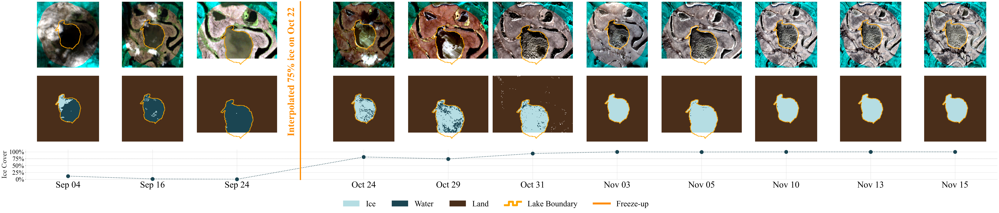

**Lake 449185 — 2023** &nbsp;·&nbsp; freeze-up DOY ≈ 291.0 (Oct 18)

In [ ]:
"""
freezeup_quartile_sampler.py

Self-contained. Samples 5 random (lake_id, year) pairs from each quartile of
pre-computed freeze-up DOY among lakes filtered by LAKE_SIZE_CLASS and renders
all 20 time series with a quartile header between groups.

Alternatively, provide a MANUAL_SELECTION dict in the USER CONFIG section to
show only specific (lake_id, site, year) combinations instead of random
quartile sampling.

Time-series observations and image filenames are read directly from the
wide Obs{k} / Obs{k}Date / Obs{k}PctIce columns in *_freezeup_dates.csv —
the separate *_freezeup_lake_obs.csv is NOT used.

Supports SENSOR = "PS" (PlanetScope) or "S2" (Sentinel-2). For S2:
  - Each "filename" in the Obs columns is a scene token (e.g.
    S2A_4WFD_20190903_0_L2A) corresponding to a folder of per-band TIFs.
  - RGB is composed from B04/B03/B02 on the B04 (10 m) grid.
  - Classification uses the bands listed in the model's feature_columns
    (typically B02, B03, B04, B08, B11, B12, SCL), nearest-resampled to
    the B04 grid.

File structure
--------------
Freeze-up dates + embedded observations (post-filtering):
    C:\\Users\\nj142\\Desktop\\Time Series\\{SENSOR}\\Freezeup\\{SITE}_freezeup_dates.csv

Run inside Jupyter:
    %run freezeup_quartile_sampler.py
"""

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import geopandas as gpd
import rasterio
import rasterio.windows
import joblib
from matplotlib.legend_handler import HandlerBase
from rasterio.mask import mask as rio_mask
from rasterio.transform import rowcol as rio_rowcol
from rasterio.features import geometry_mask
from shapely.geometry import mapping
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
matplotlib.rcParams.update({
    "figure.dpi":       130,
    "savefig.dpi":      150,
    "figure.facecolor": "white",
    "font.family":      "Times New Roman",
})

# ══════════════════════════════════════════════════════════════════════════════
#  USER CONFIG
# ══════════════════════════════════════════════════════════════════════════════

# --- Sensor and site selection (used for random-sampling mode) ---
SENSOR = "S2"    # "PS" or "S2"
SITE   = "YKD"   # "YKD", "NS", or "YF"

# --- Manual selection (overrides random sampling when populated) ---
#
# Provide a list of dicts with keys: "lake_id", "site", "year"
# The "site" field must match one of: "YKD", "NS", "YF"
# Leave as None (or an empty list []) to use random quartile sampling instead.
#
# Example:
#MANUAL_SELECTION = [
#       {"lake_id": "178", "site": "YKD", "year": 2019},
#       {"lake_id": "178", "site": "YKD", "year": 2020},
#       {"lake_id": "178", "site": "YKD", "year": 2021},
#       {"lake_id": "178", "site": "YKD", "year": 2022},
#       {"lake_id": "178", "site": "YKD", "year": 2023},
#       {"lake_id": "178", "site": "YKD", "year": 2024},
#       {"lake_id": "178", "site": "YKD", "year": 2025},
#]
#
MANUAL_SELECTION = [
       {"lake_id": "178", "site": "YKD", "year": 2019},
       {"lake_id": "178", "site": "YKD", "year": 2020},
       {"lake_id": "178", "site": "YKD", "year": 2021},
       {"lake_id": "178", "site": "YKD", "year": 2022},
       {"lake_id": "178", "site": "YKD", "year": 2023},
       {"lake_id": "178", "site": "YKD", "year": 2024},
       {"lake_id": "178", "site": "YKD", "year": 2025},
]

# --- Base paths (unchanged from original) ---
_BASE = r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data"
_ML   = (r"E:\planetscope_lake_ice\Data\Input"
         r"\Machine Learning - Planet Samples for RF\Models")

# --- S2 imagery + model roots ---
_S2_IMAGE_BASE = r"E:\sentinel_lake_ice\Data\Input\Freezeup S2 Data"
_S2_ML         = (r"E:\planetscope_lake_ice\Data\Input"
                  r"\Machine Learning - Sentinel Samples for RF\Models")

# --- Derived time-series paths (new structure) ---
_TS_BASE = r"C:\Users\nj142\Desktop\Time Series"

def _freezeup_dates_csv(sensor, site):
    return os.path.join(_TS_BASE, sensor, "Freezeup",
                        f"{site}_freezeup_dates.csv")

# --- Site-specific ALPOD paths (keyed by site tag, e.g. "YKD_50x50") ---
def _site_tag(site):
    return f"{site}_50x50"

SITE_FOLDER_MAP = {
    "YKD_50x50": os.path.join(_BASE, "YKD 50x50 km"),
    "NS_50x50":  os.path.join(_BASE, "NS 50x50 km"),
    "YF_50x50":  os.path.join(_BASE, "YF 50x50 km"),
}
SITE_SHAPEFILE_MAP = {
    "YKD_50x50": os.path.join(_BASE, "YKD 50x50 km",
                              "YKD Lakes from ALPOD Shapefile",
                              "YKD_50x50km_lakes.shp"),
    "NS_50x50":  os.path.join(_BASE, "NS 50x50 km",
                              "NS Lakes from ALPOD Shapefile",
                              "NS_50x50km_lakes.shp"),
    "YF_50x50":  os.path.join(_BASE, "YF 50x50 km",
                              "YF Lakes from ALPOD Shapefile",
                              "YF_50x50km_lakes.shp"),
}

# PlanetScope RF models
RF_MODEL_PATH_MAP = {
    "YKD_50x50": os.path.join(_ML, "YKD_Freezeup", "YKD_planet_training_RFmodel.joblib"),
    "NS_50x50":  os.path.join(_ML, "NS_Freezeup",  "NS_planet_training_RFmodel.joblib"),
    "YF_50x50":  os.path.join(_ML, "YF_Freezeup",  "YF_planet_training_RFmodel.joblib"),
}

# Sentinel-2 RF models
S2_RF_MODEL_PATH_MAP = {
    "YKD_50x50": os.path.join(_S2_ML, "YKD Freezeup", "YKD_freezeup_RFmodel.joblib"),
    "NS_50x50":  os.path.join(_S2_ML, "NS Freezeup",  "NS_freezeup_RFmodel.joblib"),
    "YF_50x50":  os.path.join(_S2_ML, "YF Freezeup",  "YF_freezeup_RFmodel.joblib"),
}

# Sentinel-2 imagery base folders (one per site).
S2_SITE_FOLDER_MAP = {
    "YKD_50x50": os.path.join(_S2_IMAGE_BASE, "YKD"),
    "NS_50x50":  os.path.join(_S2_IMAGE_BASE, "NS"),
    "YF_50x50":  os.path.join(_S2_IMAGE_BASE, "YF"),
}

# --- Sampler controls ---
SAMPLES_PER_Q = 5
RANDOM_SEED   = 123

# Lake size class to sample from in random-quartile mode.
# "S" = small  (<  0.01 km²)
# "M" = medium (0.01 – 0.50 km²)
# "L" = large  (>  0.50 km²)
LAKE_SIZE_CLASS = "L"

# --- Visualization controls ---
FREEZE_THRESHOLD = 75.0
N_IMAGES_BEFORE  = 8
N_IMAGES_AFTER   = 8
FONT_SCALE       = 1.33

# Colours
_ICE_LOW    = "#1b4552"
_ICE_HIGH   = "#1b4552"
_ACCENT     = "#ffa600"
_TEXT_DARK  = "#222222"
_MASK_ICE   = np.array([0xB5, 0xDD, 0xE3], dtype=np.uint8)
_MASK_WATER = np.array([0x1B, 0x45, 0x52], dtype=np.uint8)
_MASK_LAND  = np.array([0x4A, 0x2E, 0x1A], dtype=np.uint8)

# --- Sentinel-2 specifics ---
# RGB channels for true-color display (R, G, B).
_S2_RGB_BANDS = ("B04", "B03", "B02")
# Reference band for the common output grid (10 m).
_S2_REF_BAND  = "B04"
# All bands the classifier may need to read off disk. The actual feature order
# at predict time is taken from package["feature_columns"].
_S2_BAND_FILES = {
    "B01": "B01.tif", "B02": "B02.tif", "B03": "B03.tif", "B04": "B04.tif",
    "B05": "B05.tif", "B06": "B06.tif", "B07": "B07.tif", "B08": "B08.tif",
    "B8A": "B8A.tif", "B09": "B09.tif", "B11": "B11.tif", "B12": "B12.tif",
    "SCL": "SCL.tif",
}

# ══════════════════════════════════════════════════════════════════════════════
#  LAKE-SIZE FILTER
# ══════════════════════════════════════════════════════════════════════════════

_SIZE_BOUNDS = {
    "S": (0.0,  0.01),
    "M": (0.01, 0.5),
    "L": (0.5,  float("inf")),
}
_SIZE_LABELS = {
    "S": "small (<0.01 km²)",
    "M": "medium (0.01–0.50 km²)",
    "L": "large (>0.50 km²)",
}

def get_lake_ids_by_size(site_tag, size_class="L"):
    """Return the set of lake_id strings for lakes in the requested size class.

    Parameters
    ----------
    site_tag   : e.g. "YKD_50x50"
    size_class : "S", "M", or "L"

    Returns
    -------
    (ids: set, n_total: int, n_in_class: int)
    """
    lo, hi   = _SIZE_BOUNDS[size_class.upper()]
    shp_path = SITE_SHAPEFILE_MAP[site_tag]
    gdf      = gpd.read_file(shp_path)
    id_col   = next((c for c in ("id", "ID", "lake_id", "FID") if c in gdf.columns), "id")
    gdf_proj = gdf.to_crs("EPSG:6933") if gdf.crs.is_geographic else gdf
    gdf      = gdf.copy()
    gdf["area_km2"] = gdf_proj.geometry.area / 1e6

    # "S" and "M" use  lo < area <= hi
    # "L" uses          area > lo   (hi is inf)
    subset = gdf[(gdf["area_km2"] > lo) & (gdf["area_km2"] <= hi)] \
             if hi != float("inf") else gdf[gdf["area_km2"] > lo]

    ids = set(subset[id_col].astype(str).str.replace(r"\.0$", "", regex=True))
    return ids, len(gdf), len(subset)

# ══════════════════════════════════════════════════════════════════════════════
#  OBS-COLUMN PARSER  (replaces separate *_freezeup_lake_obs.csv)
# ══════════════════════════════════════════════════════════════════════════════

def parse_obs_from_row(row):
    """
    Unpack the wide Obs{k} / Obs{k}Date / Obs{k}PctIce columns from a single
    *_freezeup_dates.csv row into a tidy DataFrame.

    Returns
    -------
    DataFrame with columns:
        filename      – image filename (str). For PS this includes ".tif";
                        for S2 it is a scene token like
                        "S2A_4WFD_20190903_0_L2A".
        date          – pd.Timestamp (noon on observation date)
        ice_fraction  – float (0–100)
    """
    records = []
    k = 1
    while True:
        fname_col = f"Obs{k}"
        date_col  = f"Obs{k}Date"
        ice_col   = f"Obs{k}PctIce"

        # Stop when we run out of columns or hit an empty filename
        if fname_col not in row.index:
            break
        fname = str(row[fname_col]).strip()
        if not fname or fname.lower() in ("", "nan"):
            break

        date_str = str(row.get(date_col, "")).strip()
        ice_str  = str(row.get(ice_col,  "")).strip()

        try:
            obs_date = pd.to_datetime(date_str, format="%m/%d/%Y")
            # Set to noon so that datetime comparisons with interp_dt
            # (which has an intra-day component) behave correctly.
            obs_date = obs_date.replace(hour=12, minute=0, second=0)
        except Exception:
            k += 1
            if k > 500:          # safety valve
                break
            continue

        ice_frac = float(ice_str) if ice_str not in ("", "nan") else np.nan
        records.append({"filename": fname, "date": obs_date,
                        "ice_fraction": ice_frac})
        k += 1

    if not records:
        return pd.DataFrame(columns=["filename", "date", "ice_fraction"])

    return (pd.DataFrame(records)
              .sort_values("date")
              .reset_index(drop=True))


def _parse_date_mdy(s):
    """Parse a 'M/D/YYYY' string to a pd.Timestamp, or NaT."""
    try:
        return pd.to_datetime(str(s).strip(), format="%m/%d/%Y")
    except Exception:
        return pd.NaT


# ══════════════════════════════════════════════════════════════════════════════
#  GEOMETRY HELPERS
# ══════════════════════════════════════════════════════════════════════════════

def calculate_dynamic_buffer(lake_geom):
    """Buffer equal to 1.5× the mean radius (area-based)."""
    area = lake_geom.area
    mean_radius = np.sqrt(area / np.pi)
    return mean_radius * 1.5

# ══════════════════════════════════════════════════════════════════════════════
#  RF & IMAGE HELPERS
# ══════════════════════════════════════════════════════════════════════════════

RF_MODELS: dict = {}

def _rf_model_path(site_tag):
    """Return the RF model joblib path appropriate for the active SENSOR."""
    if SENSOR == "S2":
        return S2_RF_MODEL_PATH_MAP.get(site_tag)
    return RF_MODEL_PATH_MAP.get(site_tag)

def load_rf_models(site_tag):
    path = _rf_model_path(site_tag)
    if path and os.path.isfile(path):
        package = joblib.load(path)
        package["model"].set_params(n_jobs=-1)
        RF_MODELS[site_tag] = package
    else:
        print(f"  [warn] RF model not found for {site_tag} ({SENSOR}): {path}")

def classify_pixels(pixel_data, nodata, site_tag):
    """
    pixel_data : (n_features, n_pixels) array, rows ordered to match
                 package["feature_columns"]
    """
    _empty = (0, 0, np.array([], dtype=str), np.array([], dtype=bool))
    package = RF_MODELS.get(site_tag)
    if package is None or pixel_data.size == 0:
        return _empty
    model        = package["model"]
    le           = package["label_encoder"]
    feature_cols = package["feature_columns"]
    valid = (~np.all(pixel_data == nodata, axis=0)
             if nodata is not None
             else np.ones(pixel_data.shape[1], dtype=bool))
    pixels_np = pixel_data[:, valid].T
    if pixels_np.size == 0:
        return 0, 0, np.array([], dtype=str), valid
    predictions = model.predict(pd.DataFrame(pixels_np, columns=feature_cols))
    ice_idx     = int(np.where(le.classes_ == "ice")[0][0])
    pred_labels = np.where(predictions == ice_idx, "ice", "water")
    return (int(np.sum(pred_labels == "ice")),
            int(np.sum(pred_labels == "water")),
            pred_labels, valid)

def _stretch_uint8(band, lo=2, hi=98):
    band  = band.astype(np.float32)
    valid = band > 0
    if not valid.any():
        return np.zeros_like(band, dtype=np.uint8)
    p_lo, p_hi = np.percentile(band[valid], (lo, hi))
    if p_hi <= p_lo:
        return np.zeros_like(band, dtype=np.uint8)
    return np.clip((band - p_lo) / (p_hi - p_lo) * 255.0, 0, 255).astype(np.uint8)

# ─── PlanetScope (single multiband TIF) ──────────────────────────────────────

def _clip_to_lake_buffer_ps(tif_path, lake_geom, lake_crs, buffer_m):
    try:
        with rasterio.open(tif_path) as src:
            lake_proj = (gpd.GeoSeries([lake_geom], crs=lake_crs)
                         .to_crs(src.crs).geometry.iloc[0])
            out_img, out_tf = rio_mask(src, [lake_proj.buffer(buffer_m)],
                                       crop=True, nodata=0)
            rgba = np.dstack([
                _stretch_uint8(out_img[2]),
                _stretch_uint8(out_img[1]),
                _stretch_uint8(out_img[0]),
                np.where(((out_img[0] == 0) & (out_img[1] == 0) & (out_img[2] == 0)),
                         0, 255).astype(np.uint8),
            ])
        return rgba, out_tf, lake_proj, None
    except Exception as e:
        return None, None, None, str(e)

def _classify_and_build_mask_rgba_ps(tif_path, lake_geom, lake_crs, site_tag, buffer_m):
    with rasterio.open(tif_path) as src:
        lake_proj = (gpd.GeoSeries([lake_geom], crs=lake_crs)
                     .to_crs(src.crs).geometry.iloc[0])
        out_img, out_tf = rio_mask(src, [lake_proj.buffer(buffer_m)],
                                   crop=True, nodata=0)
        nodata = src.nodata
    rows, cols   = out_img.shape[1], out_img.shape[2]
    nodata_mask  = (out_img[0] == 0) & (out_img[1] == 0) & (out_img[2] == 0)
    inside_mask  = geometry_mask(
        [mapping(lake_proj)], transform=out_tf,
        invert=True, out_shape=(rows, cols)
    )
    ice_cnt, water_cnt, pred_labels, v_mask = classify_pixels(
        out_img[:, inside_mask], nodata, site_tag
    )
    mask_rgba = np.zeros((rows, cols, 4), dtype=np.uint8)
    l_rows, l_cols = np.where(~inside_mask & ~nodata_mask)
    mask_rgba[l_rows, l_cols, :3] = _MASK_LAND
    mask_rgba[l_rows, l_cols,  3] = 255
    if pred_labels.size > 0:
        i_rows, i_cols = np.where(inside_mask)
        t_rows = i_rows[np.where(v_mask)[0]]
        t_cols = i_cols[np.where(v_mask)[0]]
        ice_sel = pred_labels == "ice"
        mask_rgba[t_rows[ice_sel],  t_cols[ice_sel],  :3] = _MASK_ICE
        mask_rgba[t_rows[~ice_sel], t_cols[~ice_sel], :3] = _MASK_WATER
        mask_rgba[t_rows, t_cols, 3] = 255
    total = ice_cnt + water_cnt
    return (mask_rgba, out_tf, lake_proj, ice_cnt, water_cnt,
            (100.0 * ice_cnt / total if total > 0 else 0.0))

# ─── Sentinel-2 (per-band TIFs in a scene folder) ────────────────────────────

def _read_band_aligned(band_path, ref_h, ref_w, ref_bounds):
    """
    Read a single S2 band TIF, windowed to ref_bounds (in the band's own CRS,
    which matches the reference band's CRS within a scene) and resampled to
    (ref_h, ref_w) with nearest-neighbour. Returns a 2-D numpy array.

    Out-of-extent areas are filled with 0 (S2 nodata).
    """
    if not os.path.isfile(band_path):
        return np.zeros((ref_h, ref_w), dtype=np.float32)
    with rasterio.open(band_path) as src:
        win = rasterio.windows.from_bounds(*ref_bounds, transform=src.transform)
        return src.read(
            1, window=win, out_shape=(ref_h, ref_w),
            resampling=rasterio.enums.Resampling.nearest,
            boundless=True, fill_value=0,
        )

def _scene_ref_grid(scene_folder, lake_geom, lake_crs, buffer_m):
    """
    Establish the reference grid by clipping the B04 (10 m) band to the
    buffered lake. Returns (ref_arr_2d, ref_tf, lake_proj, ref_bounds).
    """
    ref_path = os.path.join(scene_folder, _S2_BAND_FILES[_S2_REF_BAND])
    if not os.path.isfile(ref_path):
        raise FileNotFoundError(f"Reference band missing: {ref_path}")
    with rasterio.open(ref_path) as ref_src:
        lake_proj = (gpd.GeoSeries([lake_geom], crs=lake_crs)
                     .to_crs(ref_src.crs).geometry.iloc[0])
        buf_geom = lake_proj.buffer(buffer_m)
        ref_arr, ref_tf = rio_mask(
            ref_src, [mapping(buf_geom)], crop=True, nodata=0
        )
    ref_h, ref_w = ref_arr.shape[1], ref_arr.shape[2]
    ref_bounds   = rasterio.transform.array_bounds(ref_h, ref_w, ref_tf)
    return ref_arr[0], ref_tf, lake_proj, ref_bounds

def _clip_to_lake_buffer_s2(scene_folder, lake_geom, lake_crs, buffer_m):
    try:
        # Reference grid + B04 (red)
        b04, ref_tf, lake_proj, ref_bounds = _scene_ref_grid(
            scene_folder, lake_geom, lake_crs, buffer_m
        )
        ref_h, ref_w = b04.shape
        # B03 (green), B02 (blue) — both 10 m, same grid as B04
        b03 = _read_band_aligned(
            os.path.join(scene_folder, _S2_BAND_FILES["B03"]),
            ref_h, ref_w, ref_bounds,
        )
        b02 = _read_band_aligned(
            os.path.join(scene_folder, _S2_BAND_FILES["B02"]),
            ref_h, ref_w, ref_bounds,
        )
        nodata_mask = (b04 == 0) & (b03 == 0) & (b02 == 0)
        rgba = np.dstack([
            _stretch_uint8(b04),
            _stretch_uint8(b03),
            _stretch_uint8(b02),
            np.where(nodata_mask, 0, 255).astype(np.uint8),
        ])
        return rgba, ref_tf, lake_proj, None
    except Exception as e:
        return None, None, None, str(e)

def _classify_and_build_mask_rgba_s2(scene_folder, lake_geom, lake_crs,
                                     site_tag, buffer_m):
    package = RF_MODELS.get(site_tag)
    if package is None:
        raise RuntimeError(f"S2 RF model not loaded for site_tag={site_tag}")
    feature_cols = list(package["feature_columns"])

    # Reference grid (B04, 10 m)
    b04, ref_tf, lake_proj, ref_bounds = _scene_ref_grid(
        scene_folder, lake_geom, lake_crs, buffer_m
    )
    ref_h, ref_w = b04.shape

    # Read every band the model expects, aligned to ref grid.
    band_arrays = {}
    for col in feature_cols:
        if col == "B04":
            band_arrays[col] = b04
            continue
        fname = _S2_BAND_FILES.get(col)
        if fname is None:
            # Unknown feature column — fill with zeros so the model still runs;
            # the user will see all-zero predictions and notice.
            band_arrays[col] = np.zeros((ref_h, ref_w), dtype=np.float32)
            continue
        band_arrays[col] = _read_band_aligned(
            os.path.join(scene_folder, fname), ref_h, ref_w, ref_bounds,
        )

    # nodata mask: where the RGB triple is all zero
    b03 = band_arrays.get("B03")
    b02 = band_arrays.get("B02")
    if b03 is None or b02 is None:
        b03 = _read_band_aligned(os.path.join(scene_folder, "B03.tif"),
                                 ref_h, ref_w, ref_bounds)
        b02 = _read_band_aligned(os.path.join(scene_folder, "B02.tif"),
                                 ref_h, ref_w, ref_bounds)
    nodata_mask = (b04 == 0) & (b03 == 0) & (b02 == 0)

    inside_mask = geometry_mask(
        [mapping(lake_proj)], transform=ref_tf,
        invert=True, out_shape=(ref_h, ref_w),
    )

    # Stack features in the model's expected order: (n_features, H, W)
    stack = np.stack([band_arrays[c] for c in feature_cols], axis=0)
    in_lake_pixels = stack[:, inside_mask]   # (n_features, n_in_lake)

    # Treat all-zero pixels as nodata
    ice_cnt, water_cnt, pred_labels, v_mask = classify_pixels(
        in_lake_pixels, 0, site_tag
    )

    mask_rgba = np.zeros((ref_h, ref_w, 4), dtype=np.uint8)
    l_rows, l_cols = np.where(~inside_mask & ~nodata_mask)
    mask_rgba[l_rows, l_cols, :3] = _MASK_LAND
    mask_rgba[l_rows, l_cols,  3] = 255
    if pred_labels.size > 0:
        i_rows, i_cols = np.where(inside_mask)
        t_rows = i_rows[np.where(v_mask)[0]]
        t_cols = i_cols[np.where(v_mask)[0]]
        ice_sel = pred_labels == "ice"
        mask_rgba[t_rows[ice_sel],  t_cols[ice_sel],  :3] = _MASK_ICE
        mask_rgba[t_rows[~ice_sel], t_cols[~ice_sel], :3] = _MASK_WATER
        mask_rgba[t_rows, t_cols, 3] = 255

    total = ice_cnt + water_cnt
    return (mask_rgba, ref_tf, lake_proj, ice_cnt, water_cnt,
            (100.0 * ice_cnt / total if total > 0 else 0.0))

# ─── Public dispatchers ──────────────────────────────────────────────────────

def clip_to_lake_buffer(image_path, lake_geom, lake_crs, buffer_m):
    """For PS, image_path is a .tif. For S2, it is the scene folder."""
    if SENSOR == "S2":
        return _clip_to_lake_buffer_s2(image_path, lake_geom, lake_crs, buffer_m)
    return _clip_to_lake_buffer_ps(image_path, lake_geom, lake_crs, buffer_m)

def classify_and_build_mask_rgba(image_path, lake_geom, lake_crs, site_tag, buffer_m):
    if SENSOR == "S2":
        return _classify_and_build_mask_rgba_s2(
            image_path, lake_geom, lake_crs, site_tag, buffer_m
        )
    return _classify_and_build_mask_rgba_ps(
        image_path, lake_geom, lake_crs, site_tag, buffer_m
    )

def draw_lake_outline(ax, geom, transform, linewidth=2.5):
    polys = list(geom.geoms) if geom.geom_type.startswith("Multi") else [geom]
    for poly in polys:
        for ring in [poly.exterior] + list(poly.interiors):
            xs, ys = zip(*ring.coords)
            r, c   = rio_rowcol(transform, xs, ys)
            ax.plot(c, r, color=_ACCENT, linewidth=linewidth, alpha=0.9)

def build_image_lookup(site_tag):
    """
    Returns {obs_filename: on-disk path}. For PS, the on-disk path is a .tif
    file. For S2, it is the scene folder (containing per-band TIFs).
    """
    if SENSOR == "S2":
        base = S2_SITE_FOLDER_MAP[site_tag]
        if not os.path.isdir(base):
            return {}
        return {
            entry: os.path.join(base, entry)
            for entry in os.listdir(base)
            if os.path.isdir(os.path.join(base, entry))
        }
    return {
        os.path.basename(p): p
        for p in glob.glob(
            os.path.join(SITE_FOLDER_MAP[site_tag], "**", "*.tif"),
            recursive=True,
        )
    }

# ══════════════════════════════════════════════════════════════════════════════
#  FIGURE BUILDER
# ══════════════════════════════════════════════════════════════════════════════

class _JaggedHandler(HandlerBase):
    def create_artists(self, legend, orig_handle, xdescent, ydescent,
                       width, height, fontsize, trans):
        xs = np.array([0, 0.25, 0.25, 0.5, 0.5, 0.75, 0.75, 1.0]) * width - xdescent
        ys = np.array([0.2, 0.2, 0.8, 0.8, 0.2, 0.2, 0.8, 0.8]) * height - ydescent
        return [matplotlib.lines.Line2D(
            xs, ys, color=orig_handle.get_color(),
            lw=orig_handle.get_linewidth(), transform=trans
        )]

def _fs(base):
    return base * FONT_SCALE

_F = {
    "ice_pct":  32,
    "divider":  30,
    "yticks":   20,
    "dates":    28,
    "ylabel":   22,
    "legend":   25,
}

def build_figure(freeze_row, site_tag, shp_path, img_lookup, threshold=75.0):
    """
    Build a time-series figure for one (lake_id, year) pair.
    Handles rows with or without a valid freeze-up date.
    """
    lid = str(freeze_row["lake_id"]).replace(".0", "")

    # ── Check for Date Existence ─────────────────────────────────────────────
    interp_dt = freeze_row.get("freezeup_dt")
    has_date  = pd.notna(interp_dt)

    # ── Reconstruct filtered time series from the Obs columns ────────────────
    obs = parse_obs_from_row(freeze_row)
    if obs.empty:
        return None

    # ── Locate the split point ───────────────────────────────────────────────
    if has_date:
        obs_before_date = _parse_date_mdy(freeze_row.get("obs_before_date", ""))
        if pd.notna(obs_before_date):
            before_matches = obs[obs["date"].dt.date == obs_before_date.date()]
            cross_idx = int(before_matches.index[-1]) if not before_matches.empty else 0
        else:
            before_matches = obs[obs["date"] < interp_dt]
            cross_idx = int(before_matches.index[-1]) if not before_matches.empty else 0
    else:
        cross_idx = max(0, len(obs) // 2 - 1)

    before_obs = obs.loc[:cross_idx].tail(N_IMAGES_BEFORE).reset_index(drop=True)
    after_obs  = obs.loc[cross_idx + 1:].head(N_IMAGES_AFTER).reset_index(drop=True)

    if before_obs.empty and after_obs.empty:
        return None

    # ── Lake geometry ────────────────────────────────────────────────────────
    lakes_gdf = gpd.read_file(shp_path)
    id_col    = next((c for c in ("id", "ID", "lake_id", "FID") if c in lakes_gdf.columns), "id")
    lake_row  = lakes_gdf[lakes_gdf[id_col].astype(str).str.replace(".0", "") == lid]

    if lake_row.empty:
        return None

    lake_geom = lake_row.geometry.iloc[0]
    lake_crs  = lakes_gdf.crs
    buffer_m  = calculate_dynamic_buffer(lake_geom)

    # ── Layout ───────────────────────────────────────────────────────────────
    n_before, n_after = len(before_obs), len(after_obs)
    widths  = [1.0] * n_before + [0.5] + [1.0] * n_after
    n_cols  = len(widths)
    div_col = n_before
    total_w = sum(widths)

    cell_w = 5.2
    fig_w  = sum(w * cell_w for w in widths)
    fig_h  = (cell_w * 2) + 2.5
    fig    = plt.figure(figsize=(fig_w, fig_h), facecolor="white")

    gs = gridspec.GridSpec(
        3, n_cols,
        width_ratios=widths, height_ratios=[1, 1, 0.45],
        wspace=0.0, hspace=0.15,
        left=0.05, right=0.98, top=0.95, bottom=0.16,
    )

    # ── RGB + mask panels ────────────────────────────────────────────────────
    for df_sub, start_col in [(before_obs, 0), (after_obs, div_col + 1)]:
        for i, (_, row) in enumerate(df_sub.iterrows()):
            curr_col  = start_col + i
            image_pth = img_lookup.get(row["filename"])

            ax_rgb = fig.add_subplot(gs[0, curr_col])
            ax_rgb.axis("off")
            if image_pth:
                rgba, tf, l_img, err = clip_to_lake_buffer(
                    image_pth, lake_geom, lake_crs, buffer_m
                )
                if rgba is not None:
                    ax_rgb.imshow(rgba, interpolation="bilinear")
                    draw_lake_outline(ax_rgb, l_img, tf)

            ax_mask = fig.add_subplot(gs[1, curr_col])
            ax_mask.axis("off")
            if image_pth:
                try:
                    m_rgba, tf, l_img, _, _, _ = classify_and_build_mask_rgba(
                        image_pth, lake_geom, lake_crs, site_tag, buffer_m
                    )
                    ax_mask.imshow(m_rgba, interpolation="nearest")
                    draw_lake_outline(ax_mask, l_img, tf)
                except:
                    pass

    # ── Divider Annotation (Only if date exists) ─────────────────────────────
    ax_div = fig.add_subplot(gs[0:2, div_col])
    ax_div.axis("off")

    if has_date:
        date_str = interp_dt.strftime("%b %d").replace(" 0", " ")
        ax_div.text(
            0.40, 0.5,
            f"Interpolated {int(threshold)}% ice on {date_str}",
            color="darkorange", rotation=90, ha="right", va="center",
            fontsize=_fs(_F["divider"]), fontweight="bold",
            transform=ax_div.transAxes,
        )

    # ── Time-series strip ────────────────────────────────────────────────────
    ax_ts = fig.add_subplot(gs[2, :])

    x_before = [i + 0.5 for i in range(n_before)]
    x_after  = [n_before + 1.0 + j for j in range(n_after)]
    x_vals   = x_before + x_after
    y_vals   = list(before_obs["ice_fraction"]) + list(after_obs["ice_fraction"])

    all_obs     = pd.concat([before_obs, after_obs]).sort_values("date").reset_index(drop=True)
    date_labels = [pd.Timestamp(r["date"]).strftime("%b %d") for _, r in all_obs.iterrows()]

    ax_ts.plot(x_vals, y_vals, linestyle=":", color=_ICE_HIGH, linewidth=2.5, zorder=2)
    ax_ts.scatter(x_vals, y_vals, s=220, color=_ICE_HIGH, zorder=4, clip_on=False)
    ax_ts.axhline(y=threshold, color="gray", linewidth=1.2, linestyle="--", alpha=0.5, zorder=1)

    ax_ts.set_xlim(0, total_w)
    ax_ts.set_ylim(0, 108)
    ax_ts.set_yticks([0, 25, 50, 75, 100])
    ax_ts.set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=_fs(_F["yticks"]))
    ax_ts.set_xticks(x_vals)
    ax_ts.set_xticklabels(date_labels, fontsize=_fs(_F["dates"]), ha="center")
    ax_ts.tick_params(axis="x", length=0, pad=8)
    ax_ts.grid(True, color="lightgray", linewidth=0.8, zorder=0)
    ax_ts.set_facecolor("white")
    ax_ts.spines[["top", "right"]].set_visible(False)
    ax_ts.spines[["left", "bottom"]].set_color("lightgray")
    ax_ts.set_ylabel("Ice Cover", fontsize=_fs(_F["ylabel"]), color=_TEXT_DARK)

    # ── Full-height orange divider line (Only if date exists) ────────────────
    if has_date:
        divider_x = sum(widths[:div_col]) + widths[div_col] / 2.0
        usable_w  = 0.98 - 0.05
        fig_x     = 0.05 + (divider_x / total_w) * usable_w
        fig.add_artist(matplotlib.lines.Line2D(
            [fig_x, fig_x], [0.16, 0.95],
            color="darkorange", linewidth=5, zorder=10,
            transform=fig.transFigure, clip_on=False,
        ))

    # ── Legend ───────────────────────────────────────────────────────────────
    _lake_bound_handle = plt.Line2D([0], [0], color=_ACCENT, lw=8, label="Lake Boundary")
    legend_elements = [
        plt.Rectangle((0, 0), 1, 1, color=_MASK_ICE   / 255.0, label="Ice"),
        plt.Rectangle((0, 0), 1, 1, color=_MASK_WATER / 255.0, label="Water"),
        plt.Rectangle((0, 0), 1, 1, color=_MASK_LAND  / 255.0, label="Land"),
        _lake_bound_handle,
    ]
    if has_date:
        legend_elements.append(plt.Line2D([0], [0], color="darkorange", lw=8, label="Freeze-up"))

    fig.legend(
        handles=legend_elements, loc="lower center", ncol=len(legend_elements), frameon=False,
        fontsize=_fs(_F["legend"]), bbox_to_anchor=(0.5, 0.0),
        handler_map={_lake_bound_handle: _JaggedHandler()},
    )

    return fig

# ══════════════════════════════════════════════════════════════════════════════
#  FREEZE-UP DOY TABLE
#  Reads the pre-computed CSV and keeps ALL columns so that Obs columns
#  are available when building figures — no separate obs CSV needed.
# ══════════════════════════════════════════════════════════════════════════════

def load_freezeup_doy_table(sensor, site, site_tag, size_ids=None):
    """
    Loads the CSV and keeps all rows, even those without a valid freeze-up date.

    Parameters
    ----------
    sensor   : "PS" or "S2"
    site     : "YKD", "NS", or "YF"
    site_tag : e.g. "YKD_50x50"
    size_ids : set of lake_id strings to retain, or None to keep all
    """
    csv_path = _freezeup_dates_csv(sensor, site)
    df = pd.read_csv(csv_path, dtype=str)

    # Normalise lake_id
    df["lake_id"] = df["lake_id"].str.replace(r"\.0$", "", regex=True)

    # Numeric year
    df["year"] = pd.to_numeric(df["year"], errors="coerce")

    # Parse the freeze-up datetime
    df["freezeup_dt"] = pd.to_datetime(df["freezeup_date"], errors="coerce")

    # --- CRITICAL: COMMENTED OUT TO ALLOW LAKES WITHOUT DATES ---
    # df = df.dropna(subset=["freezeup_dt"]).copy()

    # DOY as float (NaT → NaN)
    df["freezeup_doy"] = df["freezeup_dt"].dt.dayofyear.astype(float)

    # Filter to the correct site/dataset tag
    df = df[df["dataset"] == site_tag]

    # Optionally filter to the requested size class
    if size_ids is not None:
        df = df[df["lake_id"].isin(size_ids)]

    return df.reset_index(drop=True)

# ══════════════════════════════════════════════════════════════════════════════
#  QUARTILE SAMPLER
# ══════════════════════════════════════════════════════════════════════════════

def sample_by_quartile(doy_table, n_per_q=5, seed=42):
    """Bin (lake, year) pairs into quartiles of freezeup_doy and randomly
    sample n_per_q from each.  Returns (samples_df, edges)."""
    if doy_table.empty:
        return doy_table, None

    edges     = np.quantile(doy_table["freezeup_doy"], [0, 0.25, 0.50, 0.75, 1.0])
    doy_table = doy_table.copy()
    doy_table["quartile"] = pd.qcut(
        doy_table["freezeup_doy"], q=4, labels=["Q1", "Q2", "Q3", "Q4"]
    )

    rng    = np.random.default_rng(seed)
    chunks = []
    for q in ["Q1", "Q2", "Q3", "Q4"]:
        pool   = doy_table[doy_table["quartile"] == q]
        n_take = min(n_per_q, len(pool))
        if n_take == 0:
            continue
        picked_idx = rng.choice(pool.index.values, size=n_take, replace=False)
        chunks.append(pool.loc[picked_idx])
    return pd.concat(chunks).reset_index(drop=True), edges

# ══════════════════════════════════════════════════════════════════════════════
#  MANUAL-SELECTION RENDERER
# ══════════════════════════════════════════════════════════════════════════════

def run_manual_selection(sensor, manual_list):
    """
    Render time-series figures for an explicit list of (lake_id, site, year)
    entries. Handles cases where freeze-up dates are missing (NaT).

    Note: LAKE_SIZE_CLASS is intentionally ignored here — manual entries are
    shown regardless of lake size.
    """
    print(f"Mode: MANUAL SELECTION  |  Sensor: {sensor}")
    print(f"  {len(manual_list)} entries requested\n")

    # Group by site so we only load each CSV / shapefile / RF model once
    by_site = {}
    for entry in manual_list:
        s = str(entry["site"]).upper()
        by_site.setdefault(s, []).append(entry)

    # Pre-load everything we need, keyed by site
    doy_tables  = {}
    img_lookups = {}
    for site, entries in by_site.items():
        tag = _site_tag(site)
        load_rf_models(tag)
        # size_ids=None so that manual entries are never filtered by size
        doy_tables[site]  = load_freezeup_doy_table(sensor, site, tag, size_ids=None)
        img_lookups[site] = build_image_lookup(tag)

    # Render in original order
    for entry in manual_list:
        lid  = str(entry["lake_id"]).replace(".0", "")
        site = str(entry["site"]).upper()
        year = int(entry["year"])
        tag  = _site_tag(site)

        df   = doy_tables[site]
        mask = (df["lake_id"] == lid) & (df["year"] == year)
        hits = df[mask]

        if hits.empty:
            print(f"  [not found] lake {lid} / {site} / {year} — skipping")
            continue

        row       = hits.iloc[0]
        doy       = row["freezeup_doy"]
        interp_dt = row["freezeup_dt"]

        if pd.notna(interp_dt):
            date_info = f"freeze-up DOY ≈ {doy:.1f} ({interp_dt.strftime('%b %d')})"
        else:
            date_info = "freeze-up date: NOT FOUND (showing available observations)"

        display(Markdown(
            f"**Lake {lid} — {site} — {year}** &nbsp;·&nbsp; {date_info}"
        ))

        try:
            fig = build_figure(
                freeze_row=row,
                site_tag=tag,
                shp_path=SITE_SHAPEFILE_MAP[tag],
                img_lookup=img_lookups[site],
                threshold=FREEZE_THRESHOLD,
            )
            if fig is None:
                print(f"   [skipped] build_figure returned None for {lid} / {site} / {year}")
                continue
            display(fig)
            plt.close(fig)
        except Exception as e:
            print(f"   [error] {lid} / {site} / {year}: {e}")

# ══════════════════════════════════════════════════════════════════════════════
#  RANDOM QUARTILE RENDERER
# ══════════════════════════════════════════════════════════════════════════════

def run_random_sampling(sensor, site):
    """Run quartile-based random sampling for a single site, filtered by
    LAKE_SIZE_CLASS."""
    site_tag   = _site_tag(site)
    size_label = _SIZE_LABELS[LAKE_SIZE_CLASS.upper()]

    print(f"Mode: RANDOM QUARTILE SAMPLING  |  Sensor: {sensor}  |  Site: {site}  ({site_tag})")
    print(f"  Lake size class: {LAKE_SIZE_CLASS.upper()} — {size_label}")

    # Size-class filter
    size_ids, n_total, n_in_class = get_lake_ids_by_size(site_tag, LAKE_SIZE_CLASS)
    print(f"  Lakes in class: {n_in_class} of {n_total} total")

    # Load RF model for this site
    load_rf_models(site_tag)

    # Load pre-computed freeze-up dates (full rows, including Obs columns)
    doy_tbl = load_freezeup_doy_table(sensor, site, site_tag, size_ids=size_ids)
    print(f"  → {len(doy_tbl)} (lake, year) pairs after size filter")

    # Only rows with a valid freeze-up DOY are usable for quartile binning
    doy_tbl_dated = doy_tbl.dropna(subset=["freezeup_doy"]).copy()
    print(f"  → {len(doy_tbl_dated)} of those have a pre-computed freeze-up date")

    if doy_tbl_dated.empty:
        print("No freeze-up events found for this size class. Stopping.")
        return

    # Build image lookup (sensor-aware)
    img_lookup = build_image_lookup(site_tag)
    shp_path   = SITE_SHAPEFILE_MAP[site_tag]

    # Quartile sampling (operates only on dated rows)
    samples, edges = sample_by_quartile(
        doy_tbl_dated, n_per_q=SAMPLES_PER_Q, seed=RANDOM_SEED
    )
    print(f"  → Quartile edges (DOY): "
          f"{edges[0]:.0f} | {edges[1]:.0f} | {edges[2]:.0f} | "
          f"{edges[3]:.0f} | {edges[4]:.0f}")
    print(f"  → Sampled {len(samples)} (lake, year) pairs total\n")

    # Render figures grouped by quartile
    for q_idx, q_label in enumerate(["Q1", "Q2", "Q3", "Q4"]):
        q_samples = samples[samples["quartile"] == q_label]
        lo, hi    = edges[q_idx], edges[q_idx + 1]
        display(Markdown(
            f"\n\n---\n\n"
            f"## {q_label} — DOY {lo:.0f}–{hi:.0f}  (n={len(q_samples)})\n\n"
        ))

        for _, row in q_samples.iterrows():
            lid       = row["lake_id"]
            yr        = int(row["year"])
            doy       = row["freezeup_doy"]
            interp_dt = pd.Timestamp(row["freezeup_dt"])

            display(Markdown(
                f"**Lake {lid} — {yr}** &nbsp;·&nbsp; "
                f"freeze-up DOY ≈ {doy:.1f} ({interp_dt.strftime('%b %d')})"
            ))
            try:
                fig = build_figure(
                    freeze_row=row,
                    site_tag=site_tag,
                    shp_path=shp_path,
                    img_lookup=img_lookup,
                    threshold=FREEZE_THRESHOLD,
                )
                if fig is None:
                    print(f"   [skipped] build_figure returned None for {lid} / {yr}")
                    continue
                display(fig)
                plt.close(fig)
            except Exception as e:
                print(f"   [error] {lid} / {yr}: {e}")

# ══════════════════════════════════════════════════════════════════════════════
#  MAIN ENTRY POINT
# ══════════════════════════════════════════════════════════════════════════════

def run_quartile_sampler():
    """
    Dispatch to either manual-selection or random-quartile mode depending on
    whether MANUAL_SELECTION is populated.
    """
    if MANUAL_SELECTION:
        run_manual_selection(sensor=SENSOR, manual_list=MANUAL_SELECTION)
    else:
        run_random_sampling(sensor=SENSOR, site=SITE)


if __name__ == "__main__":
    run_quartile_sampler()


# BELOW:  SCRIPT FOR MAKING NEW LOGICAL FILTERS FOR FREEZEUP BUT ONLY PLANET

In [26]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================================
# CONFIGURATION
# ============================================================================
PS_OBS_DIR       = r"C:\Users\nj142\Desktop\Time Series\PS\Freezeup"
CLOUD_FILTER_DIR = r"C:\Users\nj142\Desktop\FREEZEUP_CLOUD_FILTERS"

SITES = ["YKD", "NS", "YF"]

# Per-lake pixel-coverage filter:
# For each lake we compute the MAX (ice + water) pixel count across all years.
# An observation is kept only if its (ice + water) pixel count is at least
# PIXEL_COVERAGE_THRESHOLD of that lake's max. This effectively allows up to
# (1 - PIXEL_COVERAGE_THRESHOLD) * 100% cloud cover over the lake.
PIXEL_COVERAGE_THRESHOLD = 0.75   # 75% of per-lake max -> allows up to 75% cloud cover

# Ice-fraction thresholds (percent)
WATER_THRESHOLD        = 10.0   # below this = open water
ICE_THRESHOLD          = 75.0   # at/above this = frozen
SPIKE_THRESHOLD        = 50.0   # >50% with water on both sides = cloud spike
LEADING_ICE_THRESHOLD  = 50.0   # if first obs >= this, drop it (cloud at series start)

OUTPUT_COLS = [
    'lake_id', 'dataset', 'year',
    'freezeup_date', 'error_days_negative', 'error_days_positive',
    'obs_before_date', 'obs_before_ice_frac',
    'obs_after_date',  'obs_after_ice_frac',
    'total_observations_before_filtering',
    'total_observations_after_filtering',
    'lake_max_pixels', 'pixel_threshold',
    'detection_method',
]


# ============================================================================
# I/O HELPERS
# ============================================================================

def load_cloud_classifications(site):
    """Load the PlanetScope cloud-classification CSV; return {filename: classification}."""
    p = Path(CLOUD_FILTER_DIR) / f"{site}_cloud_classifications.csv"
    df = pd.read_csv(p)
    df['Filename']       = df['Filename'].astype(str).str.strip()
    df['Classification'] = df['Classification'].astype(str).str.strip()
    return dict(zip(df['Filename'], df['Classification']))


def load_observations(filepath):
    """Load lake-observation CSV, parse datetime/date, coerce numerics."""
    df = pd.read_csv(filepath)
    df['datetime']     = pd.to_datetime(df['datetime'], errors='coerce')
    df['date']         = pd.to_datetime(df['date'],     errors='coerce')
    df['ice_fraction'] = pd.to_numeric(df['ice_fraction'], errors='coerce')
    df['ice_pixels']   = pd.to_numeric(df['ice_pixels'],   errors='coerce').fillna(0).astype(int)
    df['water_pixels'] = pd.to_numeric(df['water_pixels'], errors='coerce').fillna(0).astype(int)
    df['filename']     = df['filename'].astype(str).str.strip()
    return df


def compute_lake_max_pixels(obs_df):
    """
    For each lake_id, return the maximum (ice_pixels + water_pixels)
    seen across every observation in every year.

    This represents the lake's full visible footprint when the scene is
    cloud-free. We use it as the reference value for the per-lake
    pixel-coverage filter.
    """
    total = obs_df['ice_pixels'].astype(float) + obs_df['water_pixels'].astype(float)
    tmp   = obs_df.assign(_total_px=total)
    return tmp.groupby('lake_id')['_total_px'].max().to_dict()


def fmt_date(d):
    """Format Timestamp -> 'M/D/YYYY' (no leading zeros)."""
    if pd.isna(d): return ''
    return f"{d.month}/{d.day}/{d.year}"


def fmt_datetime(d):
    """Format Timestamp -> 'M/D/YYYY H:MM' (zero-pad minute only)."""
    if pd.isna(d): return ''
    return f"{d.month}/{d.day}/{d.year} {d.hour}:{d.minute:02d}"


def fmt_frac(x):
    """Format ice fraction with no trailing zeros (75.0 -> '75', 62.07 -> '62.07')."""
    if pd.isna(x) or x == '': return ''
    return f"{float(x):g}"


# ============================================================================
# CORE FILTERING FUNCTION — PLANETSCOPE
# ============================================================================

def filter_planet(obs_df, cloud_dict, lake_max_px):
    df = obs_df.copy().sort_values('datetime').reset_index(drop=True)
    n_before = len(df)

    # STEP 1 — CLOUD FILTER
    df['_cloud_class'] = df['filename'].map(cloud_dict)
    n_cloudy      = int((df['_cloud_class'] == 'Cloudy').sum())
    n_very_cloudy = int((df['_cloud_class'] == 'Very Cloudy').sum())
    df = df[~df['_cloud_class'].isin(['Cloudy', 'Very Cloudy'])].copy()
    df = df.drop(columns=['_cloud_class']).reset_index(drop=True)

    # STEP 2 — PER-LAKE PIXEL-COVERAGE FILTER
    # Drop observations whose (ice+water) pixel count is < 75% of this
    # lake's all-time max (i.e. >25% of the lake is obscured by cloud).
    px_threshold  = lake_max_px * PIXEL_COVERAGE_THRESHOLD
    total_px      = df['ice_pixels'] + df['water_pixels']
    n_pre_px      = len(df)
    df = df[total_px >= px_threshold].reset_index(drop=True)
    n_too_small   = n_pre_px - len(df)

    # STEP 3 — ONE OBSERVATION PER DAY (lowest ice%)
    if len(df) > 0:
        df = (df.sort_values(['date', 'ice_fraction'])
                .drop_duplicates(subset=['date'], keep='first')
                .sort_values('datetime')
                .reset_index(drop=True))

    # STEP 4 — REMOVE LEADING ICE OBSERVATION
    if len(df) > 0 and df.iloc[0]['ice_fraction'] >= LEADING_ICE_THRESHOLD:
        df = df.iloc[1:].reset_index(drop=True)

    # STEP 5 — SPIKE FILTER (water-ice-water = cloud)
    if len(df) >= 3:
        keep = np.ones(len(df), dtype=bool)
        ice  = df['ice_fraction'].values
        for i in range(1, len(df) - 1):
            if (ice[i]   >  SPIKE_THRESHOLD and
                ice[i-1] <  WATER_THRESHOLD and
                ice[i+1] <  WATER_THRESHOLD):
                keep[i] = False
        df = df[keep].reset_index(drop=True)

    return {
        'filtered_df':   df,
        'n_before':      n_before,
        'n_after':       len(df),
        'n_cloudy':      n_cloudy,
        'n_very_cloudy': n_very_cloudy,
        'n_too_small':   n_too_small,
        'lake_max_px':   lake_max_px,
        'px_threshold':  px_threshold,
    }


# ============================================================================
# FREEZEUP DETECTION
# ============================================================================

def detect_freezeup(filtered_df):
    n = len(filtered_df)
    if n < 2:
        return {'status': 'INSUFFICIENT OBSERVATIONS'}

    df  = filtered_df.reset_index(drop=True)
    ice = df['ice_fraction'].values

    pair_idx = None
    for i in range(n - 2, -1, -1):
        if ice[i] < WATER_THRESHOLD and ice[i+1] < WATER_THRESHOLD:
            pair_idx = i
            break
    if pair_idx is None:
        return {'status': 'NO OPEN WATER FOUND'}

    freeze_idx = None
    for j in range(pair_idx + 2, n):
        if ice[j] >= ICE_THRESHOLD:
            freeze_idx = j
            break
    if freeze_idx is None:
        return {'status': 'NEVER REACHES 75% ICE'}

    obs_after_row  = df.iloc[freeze_idx]
    obs_before_row = df.iloc[freeze_idx - 1]
    f_before = float(obs_before_row['ice_fraction'])
    f_after  = float(obs_after_row['ice_fraction'])

    t_before = pd.Timestamp(obs_before_row['date']).replace(hour=12, minute=0, second=0, microsecond=0)
    t_after  = pd.Timestamp(obs_after_row['date'] ).replace(hour=12, minute=0, second=0, microsecond=0)

    if f_after == f_before:
        freezeup_dt = t_after
    else:
        frac        = (ICE_THRESHOLD - f_before) / (f_after - f_before)
        freezeup_dt = t_before + (t_after - t_before) * frac

    freezeup_dt = freezeup_dt.round('min')

    err_neg = (freezeup_dt.date() - t_before.date()).days
    err_pos = (t_after.date()    - freezeup_dt.date()).days

    return {
        'status':              'OK',
        'freezeup_dt':         freezeup_dt,
        'err_neg':             int(err_neg),
        'err_pos':             int(err_pos),
        'obs_before_date':     obs_before_row['date'],
        'obs_before_ice_frac': f_before,
        'obs_after_date':      obs_after_row['date'],
        'obs_after_ice_frac':  f_after,
    }


# ============================================================================
# PER-SITE PROCESSING
# ============================================================================

def process_site(site):
    """Process all (lake, year) groups for one site; write CSV."""
    obs_path   = Path(PS_OBS_DIR) / f"{site}_freezeup_lake_obs.csv"
    cloud_dict = load_cloud_classifications(site)
    out_dir    = Path(PS_OBS_DIR)

    print(f"\n{'='*70}")
    print(f"Processing {site} (PS)")
    print(f"  Input: {obs_path}")
    print(f"{'='*70}")

    obs_df = load_observations(obs_path)

    # ------------------------------------------------------------------
    # Per-lake max (ice + water) pixel count, across ALL years.
    # This is the reference value for the pixel-coverage filter.
    # ------------------------------------------------------------------
    lake_max_pixels = compute_lake_max_pixels(obs_df)
    print(f"  Computed per-lake max pixel counts for {len(lake_max_pixels)} lakes")
    print(f"  Pixel-coverage threshold: {PIXEL_COVERAGE_THRESHOLD*100:.0f}% of each lake's max")

    site_n_cloudy = site_n_very_cloudy = 0
    site_n_too_small = 0
    rows = []
    max_obs = 0

    for (lake_id, year), grp in obs_df.groupby(['lake_id', 'year']):
        dataset_name = grp['dataset'].iloc[0]
        lake_max_px  = float(lake_max_pixels.get(lake_id, 0))

        r = filter_planet(grp, cloud_dict, lake_max_px)
        site_n_cloudy      += r['n_cloudy']
        site_n_very_cloudy += r['n_very_cloudy']
        site_n_too_small   += r['n_too_small']

        det = detect_freezeup(r['filtered_df'])

        row = {c: '' for c in OUTPUT_COLS}
        row['lake_id']                              = lake_id
        row['dataset']                              = dataset_name
        row['year']                                 = int(year)
        row['total_observations_before_filtering']  = r['n_before']
        row['total_observations_after_filtering']   = r['n_after']
        row['lake_max_pixels']                      = int(round(r['lake_max_px']))
        row['pixel_threshold']                      = f"{r['px_threshold']:.2f}"

        if det['status'] == 'OK':
            row['freezeup_date']        = fmt_datetime(det['freezeup_dt'])
            row['error_days_negative']  = det['err_neg']
            row['error_days_positive']  = det['err_pos']
            row['obs_before_date']      = fmt_date(det['obs_before_date'])
            row['obs_before_ice_frac']  = fmt_frac(det['obs_before_ice_frac'])
            row['obs_after_date']       = fmt_date(det['obs_after_date'])
            row['obs_after_ice_frac']   = fmt_frac(det['obs_after_ice_frac'])
            row['detection_method']     = 'ICE interpolated @75.0%'
        else:
            row['detection_method']     = det['status']

        # --------------------------------------------------------------------
        # Per-observation columns: every surviving obs as
        # Obs{k}, Obs{k}Date, Obs{k}PctIce, Obs{k}PctWat (chronological).
        # Water% = 100 - ice_fraction, matching the filtering convention.
        # --------------------------------------------------------------------
        filt = r['filtered_df']
        for k, (_, obs) in enumerate(filt.iterrows(), start=1):
            ice_frac   = obs['ice_fraction']
            water_frac = (100.0 - ice_frac) if pd.notna(ice_frac) else np.nan
            row[f'Obs{k}']        = obs['filename']
            row[f'Obs{k}Date']    = fmt_date(obs['date'])
            row[f'Obs{k}PctIce']  = fmt_frac(ice_frac)
            row[f'Obs{k}PctWat']  = fmt_frac(water_frac)

        if len(filt) > max_obs:
            max_obs = len(filt)

        rows.append(row)

    # ---- console summary ---------------------------------------------------
    print(f"  Cloud filter removed {site_n_cloudy + site_n_very_cloudy} images:")
    print(f"    Cloudy:      {site_n_cloudy}")
    print(f"    Very Cloudy: {site_n_very_cloudy}")
    print(f"  Pixel-coverage filter removed {site_n_too_small} observations "
          f"(< {PIXEL_COVERAGE_THRESHOLD*100:.0f}% of per-lake max pixels)")

    # ---- build final column order ------------------------------------------
    obs_cols = []
    for k in range(1, max_obs + 1):
        obs_cols += [f'Obs{k}', f'Obs{k}Date', f'Obs{k}PctIce', f'Obs{k}PctWat']

    all_cols   = OUTPUT_COLS + obs_cols
    results_df = pd.DataFrame(rows, columns=all_cols).fillna('')

    out_path = out_dir / f"{site}_freezeup_dates.csv"
    results_df.to_csv(out_path, index=False)
    print(f"  Wrote {len(results_df)} lake-years -> {out_path}")
    print(f"  Max observations in any lake-year: {max_obs}")

    return results_df


# ============================================================================
# MAIN
# ============================================================================

all_results = {}
for site in SITES:
    all_results[site] = process_site(site)

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)


Processing YKD (PS)
  Input: C:\Users\nj142\Desktop\Time Series\PS\Freezeup\YKD_freezeup_lake_obs.csv
  Computed per-lake max pixel counts for 8333 lakes
  Pixel-coverage threshold: 75% of each lake's max
  Cloud filter removed 301099 images:
    Cloudy:      201174
    Very Cloudy: 99925
  Pixel-coverage filter removed 334 observations (< 75% of per-lake max pixels)
  Wrote 58331 lake-years -> C:\Users\nj142\Desktop\Time Series\PS\Freezeup\YKD_freezeup_dates.csv
  Max observations in any lake-year: 17

Processing NS (PS)
  Input: C:\Users\nj142\Desktop\Time Series\PS\Freezeup\NS_freezeup_lake_obs.csv
  Computed per-lake max pixel counts for 5694 lakes
  Pixel-coverage threshold: 75% of each lake's max
  Cloud filter removed 166470 images:
    Cloudy:      50926
    Very Cloudy: 115544
  Pixel-coverage filter removed 88 observations (< 75% of per-lake max pixels)
  Wrote 39816 lake-years -> C:\Users\nj142\Desktop\Time Series\PS\Freezeup\NS_freezeup_dates.csv
  Max observations in any 

# BELOW: FREEZEUP FILTERING BUT ONLY FOR S-2

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================================
# CONFIGURATION
# ============================================================================
S2_OBS_DIR = r"C:\Users\nj142\Desktop\Time Series\S2\Freezeup"

SITES = ["YKD", "NS", "YF"]

# Per-lake pixel-coverage filter:
# For each lake we compute the MAX (ice + water) pixel count across all years.
# An observation is kept only if its (ice + water) pixel count is at least
# PIXEL_COVERAGE_THRESHOLD of that lake's max. This effectively allows up to
# (1 - PIXEL_COVERAGE_THRESHOLD) * 100% cloud cover over the lake.
PIXEL_COVERAGE_THRESHOLD = 0.75   # 75% of per-lake max -> allows up to 25% cloud cover

# Ice-fraction thresholds (percent)
WATER_THRESHOLD        = 10.0   # below this = open water
ICE_THRESHOLD          = 75.0   # at/above this = frozen
SPIKE_THRESHOLD        = 50.0   # >50% with water on both sides = cloud spike
LEADING_ICE_THRESHOLD  = 50.0   # if first obs >= this, drop it (cloud at series start)

OUTPUT_COLS = [
    'lake_id', 'dataset', 'year',
    'freezeup_date', 'error_days_negative', 'error_days_positive',
    'obs_before_date', 'obs_before_ice_frac',
    'obs_after_date',  'obs_after_ice_frac',
    'total_observations_before_filtering',
    'total_observations_after_filtering',
    'lake_max_pixels', 'pixel_threshold',
    'detection_method',
]


# ============================================================================
# I/O HELPERS
# ============================================================================

def load_observations(filepath):
    """Load lake-observation CSV, parse datetime/date, coerce numerics.

    The upstream observation CSVs store ice_fraction on a 0.0–1.0 scale,
    but every threshold in this script is expressed as a 0–100 percent.
    Multiply by 100 on load so the rest of the pipeline (filters, detection,
    Obs*PctIce / Obs*PctWat output columns) keeps working in percent.
    """
    df = pd.read_csv(filepath)
    df['datetime']     = pd.to_datetime(df['datetime'], errors='coerce')
    df['date']         = pd.to_datetime(df['date'],     errors='coerce')
    df['ice_fraction'] = pd.to_numeric(df['ice_fraction'], errors='coerce')
    df['ice_pixels']   = pd.to_numeric(df['ice_pixels'],   errors='coerce').fillna(0).astype(int)
    df['water_pixels'] = pd.to_numeric(df['water_pixels'], errors='coerce').fillna(0).astype(int)
    df['filename']     = df['filename'].astype(str).str.strip()
    return df


def compute_lake_max_pixels(obs_df):
    """
    For each lake_id, return the maximum (ice_pixels + water_pixels)
    seen across every observation in every year.

    This represents the lake's full visible footprint when the scene is
    cloud-free. We use it as the reference value for the per-lake
    pixel-coverage filter.
    """
    total = obs_df['ice_pixels'].astype(float) + obs_df['water_pixels'].astype(float)
    tmp   = obs_df.assign(_total_px=total)
    return tmp.groupby('lake_id')['_total_px'].max().to_dict()


def fmt_date(d):
    """Format Timestamp -> 'M/D/YYYY' (no leading zeros)."""
    if pd.isna(d): return ''
    return f"{d.month}/{d.day}/{d.year}"


def fmt_datetime(d):
    """Format Timestamp -> 'M/D/YYYY H:MM' (zero-pad minute only)."""
    if pd.isna(d): return ''
    return f"{d.month}/{d.day}/{d.year} {d.hour}:{d.minute:02d}"


def fmt_frac(x):
    """Format ice fraction with no trailing zeros (75.0 -> '75', 62.07 -> '62.07')."""
    if pd.isna(x) or x == '': return ''
    return f"{float(x):g}"


# ============================================================================
# CORE FILTERING FUNCTION — SENTINEL-2
# ============================================================================

def filter_sentinel2(obs_df, lake_max_px):
    df = obs_df.copy().sort_values('datetime').reset_index(drop=True)
    n_before = len(df)

    # STEP 1 — PER-LAKE PIXEL-COVERAGE FILTER
    # Drop observations whose (ice+water) pixel count is < 75% of this
    # lake's all-time max (i.e. >25% of the lake is obscured by cloud).
    px_threshold  = lake_max_px * PIXEL_COVERAGE_THRESHOLD
    total_px      = df['ice_pixels'] + df['water_pixels']
    n_pre_px      = len(df)
    df = df[total_px >= px_threshold].reset_index(drop=True)
    n_too_small   = n_pre_px - len(df)

    # STEP 2 — ONE OBSERVATION PER DAY (lowest ice%)
    if len(df) > 0:
        df = (df.sort_values(['date', 'ice_fraction'])
                .drop_duplicates(subset=['date'], keep='first')
                .sort_values('datetime')
                .reset_index(drop=True))

    # STEP 3 — REMOVE LEADING ICE OBSERVATION
    if len(df) > 0 and df.iloc[0]['ice_fraction'] >= LEADING_ICE_THRESHOLD:
        df = df.iloc[1:].reset_index(drop=True)

    # STEP 4 — SPIKE FILTER (water-ice-water = cloud)
    if len(df) >= 3:
        keep = np.ones(len(df), dtype=bool)
        ice  = df['ice_fraction'].values
        for i in range(1, len(df) - 1):
            if (ice[i]   >  SPIKE_THRESHOLD and
                ice[i-1] <  WATER_THRESHOLD and
                ice[i+1] <  WATER_THRESHOLD):
                keep[i] = False
        df = df[keep].reset_index(drop=True)

    return {
        'filtered_df':  df,
        'n_before':     n_before,
        'n_after':      len(df),
        'n_too_small':  n_too_small,
        'lake_max_px':  lake_max_px,
        'px_threshold': px_threshold,
    }


# ============================================================================
# FREEZEUP DETECTION
# ============================================================================

def detect_freezeup(filtered_df):
    n = len(filtered_df)
    if n < 2:
        return {'status': 'INSUFFICIENT OBSERVATIONS'}

    df  = filtered_df.reset_index(drop=True)
    ice = df['ice_fraction'].values

    pair_idx = None
    for i in range(n - 2, -1, -1):
        if ice[i] < WATER_THRESHOLD and ice[i+1] < WATER_THRESHOLD:
            pair_idx = i
            break
    if pair_idx is None:
        return {'status': 'NO OPEN WATER FOUND'}

    freeze_idx = None
    for j in range(pair_idx + 2, n):
        if ice[j] >= ICE_THRESHOLD:
            freeze_idx = j
            break
    if freeze_idx is None:
        return {'status': 'NEVER REACHES 75% ICE'}

    obs_after_row  = df.iloc[freeze_idx]
    obs_before_row = df.iloc[freeze_idx - 1]
    f_before = float(obs_before_row['ice_fraction'])
    f_after  = float(obs_after_row['ice_fraction'])

    t_before = pd.Timestamp(obs_before_row['date']).replace(hour=12, minute=0, second=0, microsecond=0)
    t_after  = pd.Timestamp(obs_after_row['date'] ).replace(hour=12, minute=0, second=0, microsecond=0)

    if f_after == f_before:
        freezeup_dt = t_after
    else:
        frac        = (ICE_THRESHOLD - f_before) / (f_after - f_before)
        freezeup_dt = t_before + (t_after - t_before) * frac

    freezeup_dt = freezeup_dt.round('min')

    err_neg = (freezeup_dt.date() - t_before.date()).days
    err_pos = (t_after.date()    - freezeup_dt.date()).days

    return {
        'status':              'OK',
        'freezeup_dt':         freezeup_dt,
        'err_neg':             int(err_neg),
        'err_pos':             int(err_pos),
        'obs_before_date':     obs_before_row['date'],
        'obs_before_ice_frac': f_before,
        'obs_after_date':      obs_after_row['date'],
        'obs_after_ice_frac':  f_after,
    }


# ============================================================================
# PER-SITE PROCESSING
# ============================================================================

def process_site(site):
    """Process all (lake, year) groups for one site; write CSV."""
    obs_path = Path(S2_OBS_DIR) / f"{site}_freezeup_lake_obs.csv"
    out_dir  = Path(S2_OBS_DIR)

    print(f"\n{'='*70}")
    print(f"Processing {site} (S2)")
    print(f"  Input: {obs_path}")
    print(f"{'='*70}")

    obs_df = load_observations(obs_path)

    # ------------------------------------------------------------------
    # Per-lake max (ice + water) pixel count, across ALL years.
    # This is the reference value for the pixel-coverage filter.
    # ------------------------------------------------------------------
    lake_max_pixels = compute_lake_max_pixels(obs_df)
    print(f"  Computed per-lake max pixel counts for {len(lake_max_pixels)} lakes")
    print(f"  Pixel-coverage threshold: {PIXEL_COVERAGE_THRESHOLD*100:.0f}% of each lake's max")

    site_n_too_small = 0
    rows = []
    max_obs = 0

    for (lake_id, year), grp in obs_df.groupby(['lake_id', 'year']):
        dataset_name = grp['dataset'].iloc[0]
        lake_max_px  = float(lake_max_pixels.get(lake_id, 0))

        r = filter_sentinel2(grp, lake_max_px)
        site_n_too_small += r['n_too_small']

        det = detect_freezeup(r['filtered_df'])

        row = {c: '' for c in OUTPUT_COLS}
        row['lake_id']                              = lake_id
        row['dataset']                              = dataset_name
        row['year']                                 = int(year)
        row['total_observations_before_filtering']  = r['n_before']
        row['total_observations_after_filtering']   = r['n_after']
        row['lake_max_pixels']                      = int(round(r['lake_max_px']))
        row['pixel_threshold']                      = f"{r['px_threshold']:.2f}"

        if det['status'] == 'OK':
            row['freezeup_date']        = fmt_datetime(det['freezeup_dt'])
            row['error_days_negative']  = det['err_neg']
            row['error_days_positive']  = det['err_pos']
            row['obs_before_date']      = fmt_date(det['obs_before_date'])
            row['obs_before_ice_frac']  = fmt_frac(det['obs_before_ice_frac'])
            row['obs_after_date']       = fmt_date(det['obs_after_date'])
            row['obs_after_ice_frac']   = fmt_frac(det['obs_after_ice_frac'])
            row['detection_method']     = 'ICE interpolated @75.0%'
        else:
            row['detection_method']     = det['status']

        # --------------------------------------------------------------------
        # Per-observation columns: every surviving obs as
        # Obs{k}, Obs{k}Date, Obs{k}PctIce, Obs{k}PctWat (chronological).
        # Water% = 100 - ice_fraction, matching the filtering convention.
        # --------------------------------------------------------------------
        filt = r['filtered_df']
        for k, (_, obs) in enumerate(filt.iterrows(), start=1):
            ice_frac   = obs['ice_fraction']
            water_frac = (100.0 - ice_frac) if pd.notna(ice_frac) else np.nan
            row[f'Obs{k}']        = obs['filename']
            row[f'Obs{k}Date']    = fmt_date(obs['date'])
            row[f'Obs{k}PctIce']  = fmt_frac(ice_frac)
            row[f'Obs{k}PctWat']  = fmt_frac(water_frac)

        if len(filt) > max_obs:
            max_obs = len(filt)

        rows.append(row)

    # ---- console summary ---------------------------------------------------
    print(f"  Pixel-coverage filter removed {site_n_too_small} observations "
          f"(< {PIXEL_COVERAGE_THRESHOLD*100:.0f}% of per-lake max pixels)")

    # ---- build final column order ------------------------------------------
    obs_cols = []
    for k in range(1, max_obs + 1):
        obs_cols += [f'Obs{k}', f'Obs{k}Date', f'Obs{k}PctIce', f'Obs{k}PctWat']

    all_cols   = OUTPUT_COLS + obs_cols
    results_df = pd.DataFrame(rows, columns=all_cols).fillna('')

    out_path = out_dir / f"{site}_freezeup_dates.csv"
    results_df.to_csv(out_path, index=False)
    print(f"  Wrote {len(results_df)} lake-years -> {out_path}")
    print(f"  Max observations in any lake-year: {max_obs}")

    return results_df


# ============================================================================
# MAIN
# ============================================================================

all_results = {}
for site in SITES:
    all_results[site] = process_site(site)

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)



Processing YKD (S2)
  Input: C:\Users\nj142\Desktop\Time Series\S2\Freezeup\YKD_freezeup_lake_obs.csv
  Computed per-lake max pixel counts for 8333 lakes
  Pixel-coverage threshold: 75% of each lake's max
  Pixel-coverage filter removed 4010579 observations (< 75% of per-lake max pixels)
  Wrote 58331 lake-years -> C:\Users\nj142\Desktop\Time Series\S2\Freezeup\YKD_freezeup_dates.csv
  Max observations in any lake-year: 20

Processing NS (S2)
  Input: C:\Users\nj142\Desktop\Time Series\S2\Freezeup\NS_freezeup_lake_obs.csv
  Computed per-lake max pixel counts for 5694 lakes
  Pixel-coverage threshold: 75% of each lake's max
  Pixel-coverage filter removed 1612489 observations (< 75% of per-lake max pixels)
  Wrote 39858 lake-years -> C:\Users\nj142\Desktop\Time Series\S2\Freezeup\NS_freezeup_dates.csv
  Max observations in any lake-year: 20

Processing YF (S2)
  Input: C:\Users\nj142\Desktop\Time Series\S2\Freezeup\YF_freezeup_lake_obs.csv
  Computed per-lake max pixel counts for 1858 

# BELOW:  BREAKUP DATE SCRIPT, LIKE FREEZEUP ABOVE W/ OBS(K) FOR PLANET ONLY

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================================
# CONFIGURATION
# ============================================================================
PS_OBS_DIR   = r"C:\Users\nj142\Desktop\Time Series\PS\Breakup"
CLOUD_DIR    = r"C:\Users\nj142\Desktop\BREAKUP_CLOUD_FILTERS"

SITES = ["YKD", "NS", "YF"]

CLOUD_THRESHOLD         = 33.0   # max % (cloud + nodata) pixels allowed
WATER_BREAKUP_THRESHOLD = 75.0
POST_BREAKUP_WATER_MIN  = 95.0
SPIKE_DELTA             = 75.0
ICE_START_MIN           = 50.0   # first surviving obs must have ice_fraction > 50%

SPRING_MONTH_START = 4
SPRING_MONTH_END   = 6

# Classifications in the cloud CSV that should be excluded
CLOUDY_LABELS = {"Cloudy", "Very Cloudy"}

OUTPUT_COLS = [
    'lake_id', 'dataset', 'year',
    'breakup_date', 'error_days_negative', 'error_days_positive',
    'obs_before_date', 'obs_before_ice_frac',
    'obs_after_date',  'obs_after_ice_frac',
    'total_observations_before_filtering',
    'total_observations_after_filtering',
    'detection_method',
]


# ============================================================================
# I/O HELPERS
# ============================================================================

def load_observations(filepath):
    df = pd.read_csv(filepath)
    df['datetime']      = pd.to_datetime(df['datetime'],  errors='coerce')
    df['date']          = pd.to_datetime(df['date'],      errors='coerce')
    df['ice_fraction']  = pd.to_numeric(df['ice_fraction'],  errors='coerce')
    df['ice_pixels']    = pd.to_numeric(df['ice_pixels'],    errors='coerce').fillna(0).astype(int)
    df['water_pixels']  = pd.to_numeric(df['water_pixels'],  errors='coerce').fillna(0).astype(int)
    df['cloud_pixels']  = pd.to_numeric(df['cloud_pixels'],  errors='coerce').fillna(0).astype(int)
    df['nodata_pixels'] = pd.to_numeric(df['nodata_pixels'], errors='coerce').fillna(0).astype(int)
    df['filename']      = df['filename'].astype(str).str.strip()
    return df


def load_cloudy_filenames(site):
    """
    Read SITE_cloud_classifications.csv and return the set of Filename values
    whose Classification is 'Cloudy' or 'Very Cloudy'.

    Handles multiple known column-name conventions across sites:
        Filename column  : 'Filename'  | 'image' | 'Image' | 'filename' | etc.
        Label column     : 'Classification' | 'label' | 'Label' | etc.

    Matching strategy (applied later in filter_planet):
        obs_filename  e.g.  20190418_201757_51_106b
        cloud_filename e.g. 20190418_201757_51_106b_ortho_analytic_4b_sr.tif

        An observation is excluded when obs_filename is a substring of
        cloud_filename. This tolerates the varying suffixes across sensors.
    """
    cloud_path = Path(CLOUD_DIR) / f"{site}_cloud_classifications.csv"
    if not cloud_path.exists():
        print(f"  [WARN] Cloud classification file not found: {cloud_path}")
        return set()

    # Try every common separator; pick the first one that yields >= 2 columns.
    cdf = None
    for sep in (',', '\t', ';', '|'):
        tmp = pd.read_csv(cloud_path, sep=sep, engine='python')
        tmp.columns = tmp.columns.str.strip()
        if len(tmp.columns) >= 2:
            cdf = tmp
            break

    if cdf is None or len(cdf.columns) < 2:
        print(f"  [WARN] Could not parse cloud file with any separator: {cloud_path}")
        return set()

    # ---- diagnostic: show what we actually loaded --------------------------
    print(f"  [Cloud CSV] Columns found : {cdf.columns.tolist()}")
    print(f"  [Cloud CSV] Total rows    : {len(cdf)}")

    # ---- locate the filename and classification columns --------------------
    FILENAME_CANDIDATES = ['Filename', 'filename', 'image', 'Image', 'FILE', 'file']
    CLASSIF_CANDIDATES  = ['Classification', 'classification', 'label', 'Label', 'CLASS', 'class']

    def find_col(df, candidates):
        """Return the first candidate that matches a column name (case-sensitive first,
        then case-insensitive fallback)."""
        # Exact match first
        for cand in candidates:
            if cand in df.columns:
                return cand
        # Case-insensitive fallback
        cols_lower = {c.lower(): c for c in df.columns}
        for cand in candidates:
            if cand.lower() in cols_lower:
                return cols_lower[cand.lower()]
        return None

    fn_col  = find_col(cdf, FILENAME_CANDIDATES)
    cls_col = find_col(cdf, CLASSIF_CANDIDATES)

    if fn_col is None:
        print(f"  [WARN] Could not identify a filename column in {cloud_path.name}. "
              f"Columns: {cdf.columns.tolist()}")
        return set()

    if cls_col is None:
        print(f"  [WARN] Could not identify a classification column in {cloud_path.name}. "
              f"Columns: {cdf.columns.tolist()}")
        return set()

    print(f"  [Cloud CSV] Using filename col='{fn_col}', classification col='{cls_col}'")

    # Strip whitespace from both columns before filtering
    cdf[fn_col]  = cdf[fn_col].astype(str).str.strip()
    cdf[cls_col] = cdf[cls_col].astype(str).str.strip()

    # Show unique classification values so mismatches are obvious
    print(f"  [Cloud CSV] Unique '{cls_col}' values: {sorted(cdf[cls_col].unique().tolist())}")

    cloudy_set = set(
        cdf.loc[cdf[cls_col].isin(CLOUDY_LABELS), fn_col].tolist()
    )
    print(f"  Cloud filter: {len(cloudy_set)} cloudy/very-cloudy scenes loaded "
          f"from {cloud_path.name}")
    return cloudy_set


def is_cloudy(obs_filename, cloudy_filenames):
    """
    Return True if obs_filename (short stem, e.g. '20190418_201757_51_106b')
    is a substring of ANY entry in cloudy_filenames
    (e.g. '20190418_201757_51_106b_ortho_analytic_4b_sr.tif').
    """
    obs_fn = obs_filename.strip()
    for cloud_fn in cloudy_filenames:
        if obs_fn in cloud_fn:
            return True
    return False


def fmt_date(d):
    if pd.isna(d): return ''
    return f"{d.month}/{d.day}/{d.year}"

def fmt_datetime(d):
    if pd.isna(d): return ''
    return f"{d.month}/{d.day}/{d.year} {d.hour}:{d.minute:02d}"

def fmt_frac(x):
    if pd.isna(x) or x == '': return ''
    return f"{float(x):g}"


# ============================================================================
# FILTERING — PLANETSCOPE
# Uses old-script logic throughout:
#   - STEP 0: Manual cloud classification pre-filter
#   - Cloud filter: (cloud + nodata) / total pixels <= 33%
#   - Ice-start check BEFORE spike/post-breakup filters
#   - Ice-start: ice_fraction > 50  (ice+snow combined into ice)
#   - Spike filter checks ice only, skips if either neighbor already invalid
#   - Error days rounded from total_seconds / 86400
# ============================================================================

def filter_planet(obs_df, cloudy_filenames):
    """
    Parameters
    ----------
    obs_df           : raw observation rows for one (lake_id, year)
    cloudy_filenames : set of cloud-classification Filename strings
                       (from SITE_cloud_classifications.csv, Cloudy/Very Cloudy only)
    """
    df = obs_df.copy().sort_values('datetime').reset_index(drop=True)
    n_before = len(df)

    # ------------------------------------------------------------------
    # STEP 0 — MANUAL CLOUD CLASSIFICATION PRE-FILTER
    # Remove any observation whose filename stem is found inside one of
    # the manually classified cloudy-scene filenames.
    # ------------------------------------------------------------------
    if cloudy_filenames:
        cloud_mask = df['filename'].apply(lambda fn: is_cloudy(fn, cloudy_filenames))
        n_removed  = cloud_mask.sum()
        if n_removed:
            print(f"    [Cloud pre-filter] removed {n_removed} observation(s)")
        df = df[~cloud_mask].reset_index(drop=True)

    # STEP 1 — CLOUD PIXEL FRACTION FILTER
    total_px   = df['ice_pixels'] + df['water_pixels'] + df['cloud_pixels'] + df['nodata_pixels']
    invalid_px = df['cloud_pixels'] + df['nodata_pixels']
    invalid_pct = np.where(total_px > 0, (invalid_px / total_px) * 100.0, 100.0)
    df = df[invalid_pct <= CLOUD_THRESHOLD].reset_index(drop=True)

    # STEP 2 — SPRING-MONTHS FILTER
    df = df[df['datetime'].dt.month.between(SPRING_MONTH_START, SPRING_MONTH_END)].reset_index(drop=True)

    # STEP 3 — ONE OBSERVATION PER DAY (highest water% = lowest ice_fraction)
    # Representative time set to noon, matching old script's aggregate_daily_observations.
    if len(df) > 0:
        df = (df.sort_values(['date', 'ice_fraction'])
                .drop_duplicates(subset=['date'], keep='first')
                .sort_values('datetime')
                .reset_index(drop=True))
        df['datetime'] = df['date'].apply(
            lambda d: pd.Timestamp(d).replace(hour=12, minute=0, second=0, microsecond=0)
        )

    # ICE-START CHECK — done here, before spike/post-breakup filters,
    # matching old script timing (checked on df_daily before classify_pixel_validity).
    if len(df) == 0:
        return {'filtered_df': df, 'n_before': n_before, 'n_after': 0, 'status': 'OK'}

    if df['ice_fraction'].iloc[0] <= ICE_START_MIN:
        return {
            'filtered_df': pd.DataFrame(columns=df.columns),
            'n_before': n_before,
            'n_after': 0,
            'status': 'INVALID TIME SERIES - NO ICE START',
        }

    # STEP 4 — SPIKE FILTER
    # Old script: skip the spike test for obs i if either neighbor is already
    # marked invalid (pixel_valid array prevents chaining).
    # Only checks ice (snow is combined into ice_fraction).
    pixel_valid = np.ones(len(df), dtype=bool)
    ice = df['ice_fraction'].values
    if len(df) >= 3:
        for i in range(1, len(df) - 1):
            if not pixel_valid[i - 1] or not pixel_valid[i + 1]:
                continue
            prev_v, curr_v, next_v = ice[i - 1], ice[i], ice[i + 1]
            if (curr_v - prev_v) > SPIKE_DELTA and (curr_v - next_v) > SPIKE_DELTA:
                if abs(prev_v - next_v) < abs(curr_v - prev_v):
                    pixel_valid[i] = False

    # STEP 5 — POST-BREAKUP FILTER
    # After the first valid obs where ice >= 75%, drop any subsequent valid
    # obs where water < 95%.
    ice_at_breakup = 100.0 - WATER_BREAKUP_THRESHOLD  # 25.0
    ice_post_max   = 100.0 - POST_BREAKUP_WATER_MIN    #  5.0
    first_breakup_idx = None
    for i in range(len(df)):
        if pixel_valid[i] and ice[i] <= ice_at_breakup:
            first_breakup_idx = i
            break
    if first_breakup_idx is not None:
        for i in range(first_breakup_idx + 1, len(df)):
            if ice[i] > ice_post_max:
                pixel_valid[i] = False

    df_filtered = df[pixel_valid].reset_index(drop=True)

    return {
        'filtered_df': df_filtered,
        'n_before': n_before,
        'n_after': len(df_filtered),
        'status': 'OK',
    }


# ============================================================================
# BREAKUP DETECTION
# ============================================================================

def detect_breakup(filtered_df):
    n = len(filtered_df)
    if n < 2:
        return {'status': 'INSUFFICIENT OBSERVATIONS'}

    df    = filtered_df.reset_index(drop=True)
    ice   = df['ice_fraction'].values
    water = 100.0 - ice

    # Scan left-to-right for first forward crossing: water rises through 75%.
    cross_idx = None
    for i in range(n - 1):
        if water[i] < WATER_BREAKUP_THRESHOLD and water[i + 1] >= WATER_BREAKUP_THRESHOLD:
            cross_idx = i
            break
    if cross_idx is None:
        return {'status': 'NO CROSSING FOUND'}

    obs_before_row = df.iloc[cross_idx]
    obs_after_row  = df.iloc[cross_idx + 1]
    f_before = float(obs_before_row['ice_fraction'])
    f_after  = float(obs_after_row['ice_fraction'])
    w_before = 100.0 - f_before
    w_after  = 100.0 - f_after

    # Midnight anchor to match S2 logic
    t_before = pd.Timestamp(obs_before_row['date'])
    t_after  = pd.Timestamp(obs_after_row['date'])

    if w_after == w_before:
        breakup_dt = t_after
    else:
        frac       = (WATER_BREAKUP_THRESHOLD - w_before) / (w_after - w_before)
        breakup_dt = t_before + (t_after - t_before) * frac
    breakup_dt = breakup_dt.round('min')

    # timedelta .days floor to match S2 logic
    err_neg = (breakup_dt - t_before).days
    err_pos = (t_after    - breakup_dt).days

    return {
        'status':              'OK',
        'breakup_dt':          breakup_dt,
        'err_neg':             int(err_neg),
        'err_pos':             int(err_pos),
        'obs_before_date':     obs_before_row['date'],
        'obs_before_ice_frac': f_before,
        'obs_after_date':      obs_after_row['date'],
        'obs_after_ice_frac':  f_after,
    }


# ============================================================================
# PER-SITE PROCESSING
# ============================================================================

def process_site(site):
    obs_path = Path(PS_OBS_DIR) / f"{site}_breakup_lake_obs.csv"
    out_dir  = Path(PS_OBS_DIR)

    print(f"\n{'='*70}")
    print(f"Processing {site} (PS)")
    print(f"  Input: {obs_path}")
    print(f"{'='*70}")

    # Load manual cloud classifications for this site
    cloudy_filenames = load_cloudy_filenames(site)

    obs_df = load_observations(obs_path)
    rows   = []
    max_obs = 0

    for (lake_id, year), grp in obs_df.groupby(['lake_id', 'year']):
        dataset_name  = grp['dataset'].iloc[0]
        r             = filter_planet(grp, cloudy_filenames)
        filter_status = r['status']
        det           = detect_breakup(r['filtered_df'])

        row = {c: '' for c in OUTPUT_COLS}
        row['lake_id']                             = lake_id
        row['dataset']                             = dataset_name
        row['year']                                = int(year)
        row['total_observations_before_filtering'] = r['n_before']
        row['total_observations_after_filtering']  = r['n_after']

        if filter_status != 'OK':
            row['detection_method'] = filter_status
        elif det['status'] == 'OK':
            row['breakup_date']        = fmt_datetime(det['breakup_dt'])
            row['error_days_negative'] = det['err_neg']
            row['error_days_positive'] = det['err_pos']
            row['obs_before_date']     = fmt_date(det['obs_before_date'])
            row['obs_before_ice_frac'] = fmt_frac(det['obs_before_ice_frac'])
            row['obs_after_date']      = fmt_date(det['obs_after_date'])
            row['obs_after_ice_frac']  = fmt_frac(det['obs_after_ice_frac'])
            row['detection_method']    = 'WATER interpolated @75.0%'
        else:
            row['detection_method'] = det['status']

        # Obs(k) columns — only valid (post-filter) observations
        filt = r['filtered_df']
        for k, (_, obs) in enumerate(filt.iterrows(), start=1):
            ice_frac   = obs['ice_fraction']
            water_frac = (100.0 - ice_frac) if pd.notna(ice_frac) else np.nan
            row[f'Obs{k}']        = obs['filename']
            row[f'Obs{k}Date']    = fmt_date(obs['date'])
            row[f'Obs{k}PctIce']  = fmt_frac(ice_frac)
            row[f'Obs{k}PctWat']  = fmt_frac(water_frac)

        if len(filt) > max_obs:
            max_obs = len(filt)

        rows.append(row)

    obs_cols = []
    for k in range(1, max_obs + 1):
        obs_cols += [f'Obs{k}', f'Obs{k}Date', f'Obs{k}PctIce', f'Obs{k}PctWat']

    all_cols   = OUTPUT_COLS + obs_cols
    results_df = pd.DataFrame(rows, columns=all_cols).fillna('')

    out_path = out_dir / f"{site}_breakup_dates.csv"
    results_df.to_csv(out_path, index=False)
    print(f"  Wrote {len(results_df)} lake-years -> {out_path}")
    print(f"  Max observations in any lake-year: {max_obs}")

    return results_df


# ============================================================================
# MAIN
# ============================================================================

for site in SITES:
    process_site(site)

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)


Processing YKD (PS)
  Input: C:\Users\nj142\Desktop\Time Series\PS\Breakup\YKD_breakup_lake_obs.csv
  [Cloud CSV] Columns found : ['Study_Site', 'Season_Folder', 'Filename', 'Filepath', 'Classification']
  [Cloud CSV] Total rows    : 1986
  [Cloud CSV] Using filename col='Filename', classification col='Classification'
  [Cloud CSV] Unique 'Classification' values: ['Not Cloudy', 'Some Clouds', 'Very Cloudy']
  Cloud filter: 313 cloudy/very-cloudy scenes loaded from YKD_cloud_classifications.csv
    [Cloud pre-filter] removed 8 observation(s)
    [Cloud pre-filter] removed 1 observation(s)
    [Cloud pre-filter] removed 9 observation(s)
    [Cloud pre-filter] removed 12 observation(s)
    [Cloud pre-filter] removed 8 observation(s)
    [Cloud pre-filter] removed 12 observation(s)
    [Cloud pre-filter] removed 12 observation(s)
    [Cloud pre-filter] removed 1 observation(s)
    [Cloud pre-filter] removed 17 observation(s)
    [Cloud pre-filter] removed 12 observation(s)
    [Cloud pre-

# BELOW: SCRIPT FOR MAKING NEW LOGICAL FILTERS FOR BREAKUP S2 ONLY (w/ Obs(k))

In [10]:
import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================================
# CONFIGURATION
# ============================================================================
S2_OBS_DIR = r"C:\Users\nj142\Desktop\Time Series\S2\Breakup"

SITES = ["YKD", "NS", "YF"]

CLOUD_THRESHOLD      = 33.0   # drop obs where cloud% > this
WATER_BREAKUP_THRESHOLD = 75.0   # water rising through 75% marks breakup

OUTPUT_COLS = [
    'lake_id', 'dataset', 'year',
    'breakup_date', 'error_days_negative', 'error_days_positive',
    'obs_before_date', 'obs_before_ice_frac',
    'obs_after_date',  'obs_after_ice_frac',
    'total_observations_before_filtering',
    'total_observations_after_filtering',
    'detection_method',
]


# ============================================================================
# I/O HELPERS
# ============================================================================

def load_observations(filepath):
    df = pd.read_csv(filepath)
    df['datetime']     = pd.to_datetime(df['datetime'], errors='coerce')
    df['date']         = pd.to_datetime(df['date'],     errors='coerce')
    df['ice_pixels']   = pd.to_numeric(df['ice_pixels'],   errors='coerce').fillna(0).astype(int)
    df['water_pixels'] = pd.to_numeric(df['water_pixels'], errors='coerce').fillna(0).astype(int)
    df['cloud_pixels'] = pd.to_numeric(df['cloud_pixels'], errors='coerce').fillna(0).astype(int)
    df['filename']     = df['filename'].astype(str).str.strip()
    return df


def fmt_date(d):
    if pd.isna(d): return ''
    return f"{d.month}/{d.day}/{d.year}"

def fmt_datetime(d):
    if pd.isna(d): return ''
    return f"{d.month}/{d.day}/{d.year} {d.hour}:{d.minute:02d}"

def fmt_frac(x):
    if pd.isna(x) or x == '': return ''
    return f"{float(x):g}"


# ============================================================================
# FILTERING — SENTINEL-2
# ============================================================================

def filter_sentinel2(obs_df):
    df = obs_df.copy().sort_values('datetime').reset_index(drop=True)
    n_before = len(df)

    # STEP 1 — CLOUD FILTER
    # cloud% = cloud / (ice + water + cloud); nodata excluded from denominator
    total_with_cloud = df['ice_pixels'] + df['water_pixels'] + df['cloud_pixels']
    cloud_pct = np.where(
        total_with_cloud > 0,
        (df['cloud_pixels'] / total_with_cloud) * 100,
        100.0   # all-zero row treated as 100% cloud → dropped
    )
    df = df[cloud_pct <= CLOUD_THRESHOLD].reset_index(drop=True)

    # STEP 2 — RECOMPUTE ice_fraction FROM SURVIVING PIXELS
    # ice_fraction = ice / (ice + water), cloud now fully excluded
    # This is the logically correct fraction after cloud filtering
    valid_total = df['ice_pixels'] + df['water_pixels']
    df = df[valid_total > 0].copy()
    df['ice_fraction'] = (df['ice_pixels'] / valid_total) * 100.0

    # STEP 3 — ONE OBSERVATION PER DAY
    # Keep lowest ice_fraction (= highest water%) for the day
    if len(df) > 0:
        df = (df.sort_values(['date', 'ice_fraction'])
                .drop_duplicates(subset=['date'], keep='first')
                .sort_values('datetime')
                .reset_index(drop=True))

    return {'filtered_df': df, 'n_before': n_before, 'n_after': len(df)}


# ============================================================================
# BREAKUP DETECTION
# ============================================================================

def detect_breakup(filtered_df):
    n = len(filtered_df)
    if n < 2:
        return {'status': 'INSUFFICIENT OBSERVATIONS'}

    df    = filtered_df.reset_index(drop=True)
    ice   = df['ice_fraction'].values
    water = 100.0 - ice

    # Scan left-to-right for first crossing where water rises through 75%
    cross_idx = None
    for i in range(n - 1):
        if water[i] < WATER_BREAKUP_THRESHOLD and water[i + 1] >= WATER_BREAKUP_THRESHOLD:
            cross_idx = i
            break
    if cross_idx is None:
        return {'status': 'NO CROSSING FOUND'}

    obs_before_row = df.iloc[cross_idx]
    obs_after_row  = df.iloc[cross_idx + 1]
    f_before = float(obs_before_row['ice_fraction'])
    f_after  = float(obs_after_row['ice_fraction'])
    w_before = 100.0 - f_before
    w_after  = 100.0 - f_after

    # Anchor at midnight to match old script behaviour
    t_before = pd.Timestamp(obs_before_row['date'])
    t_after  = pd.Timestamp(obs_after_row['date'])

    if w_after == w_before:
        breakup_dt = t_after
    else:
        frac       = (WATER_BREAKUP_THRESHOLD - w_before) / (w_after - w_before)
        breakup_dt = t_before + (t_after - t_before) * frac
    breakup_dt = breakup_dt.round('min')

    # Use timedelta .days (floor) to match old script error calculation
    err_neg = (breakup_dt - t_before).days
    err_pos = (t_after    - breakup_dt).days

    return {
        'status':              'OK',
        'breakup_dt':          breakup_dt,
        'err_neg':             int(err_neg),
        'err_pos':             int(err_pos),
        'obs_before_date':     obs_before_row['date'],
        'obs_before_ice_frac': f_before,
        'obs_after_date':      obs_after_row['date'],
        'obs_after_ice_frac':  f_after,
    }


# ============================================================================
# PER-SITE PROCESSING
# ============================================================================

def process_site(site):
    obs_path = Path(S2_OBS_DIR) / f"{site}_breakup_lake_obs.csv"
    out_dir  = Path(S2_OBS_DIR)

    print(f"\n{'='*70}")
    print(f"Processing {site} (S2)")
    print(f"  Input: {obs_path}")
    print(f"{'='*70}")

    obs_df = load_observations(obs_path)

    rows    = []
    max_obs = 0

    for (lake_id, year), grp in obs_df.groupby(['lake_id', 'year']):
        dataset_name = grp['dataset'].iloc[0]

        r   = filter_sentinel2(grp)
        det = detect_breakup(r['filtered_df'])

        row = {c: '' for c in OUTPUT_COLS}
        row['lake_id']                             = lake_id
        row['dataset']                             = dataset_name
        row['year']                                = int(year)
        row['total_observations_before_filtering'] = r['n_before']
        row['total_observations_after_filtering']  = r['n_after']

        if det['status'] == 'OK':
            row['breakup_date']        = fmt_datetime(det['breakup_dt'])
            row['error_days_negative'] = det['err_neg']
            row['error_days_positive'] = det['err_pos']
            row['obs_before_date']     = fmt_date(det['obs_before_date'])
            row['obs_before_ice_frac'] = fmt_frac(det['obs_before_ice_frac'])
            row['obs_after_date']      = fmt_date(det['obs_after_date'])
            row['obs_after_ice_frac']  = fmt_frac(det['obs_after_ice_frac'])
            row['detection_method']    = 'WATER interpolated @75.0%'
        else:
            row['detection_method']    = det['status']

        filt = r['filtered_df']
        for k, (_, obs) in enumerate(filt.iterrows(), start=1):
            ice_frac   = obs['ice_fraction']
            water_frac = (100.0 - ice_frac) if pd.notna(ice_frac) else np.nan
            row[f'Obs{k}']       = obs['filename']
            row[f'Obs{k}Date']   = fmt_date(obs['date'])
            row[f'Obs{k}PctIce'] = fmt_frac(ice_frac)
            row[f'Obs{k}PctWat'] = fmt_frac(water_frac)

        if len(filt) > max_obs:
            max_obs = len(filt)

        rows.append(row)

    obs_cols = []
    for k in range(1, max_obs + 1):
        obs_cols += [f'Obs{k}', f'Obs{k}Date', f'Obs{k}PctIce', f'Obs{k}PctWat']

    all_cols   = OUTPUT_COLS + obs_cols
    results_df = pd.DataFrame(rows, columns=all_cols).fillna('')

    out_path = out_dir / f"{site}_breakup_dates.csv"
    results_df.to_csv(out_path, index=False)
    print(f"  Wrote {len(results_df)} lake-years -> {out_path}")
    print(f"  Max observations in any lake-year: {max_obs}")

    return results_df


# ============================================================================
# MAIN
# ============================================================================

all_results = {}
for site in SITES:
    all_results[site] = process_site(site)

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)


Processing YKD (S2)
  Input: C:\Users\nj142\Desktop\Time Series\S2\Breakup\YKD_breakup_lake_obs.csv
  Wrote 58331 lake-years -> C:\Users\nj142\Desktop\Time Series\S2\Breakup\YKD_breakup_dates.csv
  Max observations in any lake-year: 31

Processing NS (S2)
  Input: C:\Users\nj142\Desktop\Time Series\S2\Breakup\NS_breakup_lake_obs.csv
  Wrote 39858 lake-years -> C:\Users\nj142\Desktop\Time Series\S2\Breakup\NS_breakup_dates.csv
  Max observations in any lake-year: 35

Processing YF (S2)
  Input: C:\Users\nj142\Desktop\Time Series\S2\Breakup\YF_breakup_lake_obs.csv
  Wrote 13006 lake-years -> C:\Users\nj142\Desktop\Time Series\S2\Breakup\YF_breakup_dates.csv
  Max observations in any lake-year: 43

DONE


# BELOW: MAKE NEW ERROR SPREADSHEET 

In [18]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
from openpyxl import Workbook
from openpyxl.styles import PatternFill, Font, Alignment

YEARS = list(range(2019, 2026))
SITES = ['NS', 'YF', 'YKD']
BASE = 'C:/Users/nj142/Desktop/Time Series'

# Exact colors from original (ARGB without FF prefix — openpyxl adds FF automatically)
ORANGE = PatternFill('solid', fgColor='FFF0D4')
TEAL   = PatternFill('solid', fgColor='D4E8ED')

CENTER      = Alignment(horizontal='center', vertical='center')
CENTER_WRAP = Alignment(horizontal='center', vertical='center', wrap_text=True)


def tnr(bold=False, size=11):
    return Font(name='Times New Roman', bold=bold, size=size)


def compute_error(df):
    """Per-lake error = (|neg| + pos) / 2, then averaged across all lakes per year."""
    df = df.copy()
    df['error'] = (df['error_days_negative'].abs() + df['error_days_positive']) / 2
    return df.groupby('year')['error'].mean()


# Load all data
data = {}
for sat in ['PS', 'S2']:
    for event in ['Breakup', 'Freezeup']:
        for site in SITES:
            path = f'{BASE}/{sat}/{event}/{site}_{event.lower()}_dates.csv'
            df = pd.read_csv(path, low_memory=False)
            data[(sat, event, site)] = compute_error(df)


def sc(ws, r, c, value, bold=False, size=11, fill=None, align=None):
    """Set cell value + formatting."""
    cell = ws.cell(r, c, value)
    cell.font = tnr(bold=bold, size=size)
    cell.alignment = align if align is not None else CENTER
    if fill is not None:
        cell.fill = fill
    return cell


def write_section(ws, start_row, event):
    r = start_row
    N = 11  # columns A–K

    # Title row
    ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=N)
    sc(ws, r, 1,
       f'{event} Uncertainty Comparison: Planet vs. Sentinel-2  (± days)',
       bold=True, size=14)
    ws.row_dimensions[r].height = 15.0
    r += 1

    # Subtitle row
    ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=N)
    sc(ws, r, 1,
       'Orange tint = Planet higher   |   Teal tint = Sentinel-2 higher',
       bold=False, size=10)
    ws.row_dimensions[r].height = 15.75
    r += 1

    # Blank row
    r += 1

    # Header (spans two rows, each column merged)
    headers = (['Site', 'Satellite'] + YEARS +
               ['Avg Error\nRate (± days)', '% Years\nPlanet Higher'])
    for ci, h in enumerate(headers, 1):
        ws.merge_cells(start_row=r, start_column=ci, end_row=r + 1, end_column=ci)
        sc(ws, r, ci, h, bold=True, size=11, align=CENTER_WRAP)
    ws.row_dimensions[r].height = 27.75
    ws.row_dimensions[r + 1].height = 3.75
    r += 2

    for si, site in enumerate(SITES):
        ps_err = data[('PS', event, site)]
        s2_err = data[('S2', event, site)]

        ps_vals = [ps_err.get(yr, np.nan) for yr in YEARS]
        s2_vals = [s2_err.get(yr, np.nan) for yr in YEARS]

        ps_avg = np.nanmean(ps_vals)
        s2_avg = np.nanmean(s2_vals)

        valid_pairs = [(p, s) for p, s in zip(ps_vals, s2_vals)
                       if not (np.isnan(p) or np.isnan(s))]
        ps_higher_count = sum(1 for p, s in valid_pairs if p > s)
        pct_planet = round(ps_higher_count / len(valid_pairs) * 100, 2) if valid_pairs else 0

        planet_row = r
        s2_row     = r + 1

        # Site label — merged across both data rows
        ws.merge_cells(start_row=planet_row, start_column=1, end_row=s2_row, end_column=1)
        sc(ws, planet_row, 1, site, bold=True, size=11)

        # Satellite labels
        sc(ws, planet_row, 2, 'Planet',     bold=False, size=11)
        sc(ws, s2_row,     2, 'Sentinel-2', bold=False, size=11)

        # Year columns (C–I)
        for ci, yr in enumerate(YEARS):
            col = 3 + ci
            pv  = ps_vals[ci]
            sv  = s2_vals[ci]
            pval = round(float(pv), 2) if not np.isnan(pv) else None
            sval = round(float(sv), 2) if not np.isnan(sv) else None

            if pval is not None and sval is not None:
                if pv > sv:
                    sc(ws, planet_row, col, pval, bold=True,  size=10, fill=ORANGE)
                    sc(ws, s2_row,     col, sval, bold=False, size=10)
                elif sv > pv:
                    sc(ws, planet_row, col, pval, bold=False, size=10)
                    sc(ws, s2_row,     col, sval, bold=True,  size=10, fill=TEAL)
                else:
                    sc(ws, planet_row, col, pval, bold=False, size=10)
                    sc(ws, s2_row,     col, sval, bold=False, size=10)
            else:
                if pval is not None:
                    sc(ws, planet_row, col, pval, bold=False, size=10)
                if sval is not None:
                    sc(ws, s2_row,     col, sval, bold=False, size=10)

        # Avg column (J = col 10)
        ps_avg_r = round(float(ps_avg), 2)
        s2_avg_r = round(float(s2_avg), 2)
        if ps_avg > s2_avg:
            sc(ws, planet_row, 10, ps_avg_r, bold=True,  size=10, fill=ORANGE)
            sc(ws, s2_row,     10, s2_avg_r, bold=False, size=10)
        elif s2_avg > ps_avg:
            sc(ws, planet_row, 10, ps_avg_r, bold=False, size=10)
            sc(ws, s2_row,     10, s2_avg_r, bold=True,  size=10, fill=TEAL)
        else:
            sc(ws, planet_row, 10, ps_avg_r, bold=False, size=10)
            sc(ws, s2_row,     10, s2_avg_r, bold=False, size=10)

        # % Years Planet Higher (K = col 11) — merged across both rows
        ws.merge_cells(start_row=planet_row, start_column=11, end_row=s2_row, end_column=11)
        if pct_planet > 50:
            pct_fill = ORANGE
        elif pct_planet < 50:
            pct_fill = TEAL
        else:
            pct_fill = None
        sc(ws, planet_row, 11, pct_planet, bold=True, size=11, fill=pct_fill)

        ws.row_dimensions[planet_row].height = 18.0
        ws.row_dimensions[s2_row].height     = 18.0
        r += 2

        # Blank separator between sites
        if si < len(SITES) - 1:
            ws.row_dimensions[r].height = 6.75
            r += 1

    return r + 1  # blank gap before next section


# ── Build workbook ──────────────────────────────────────────────────────────
wb = Workbook()
ws = wb.active
ws.title = 'Uncertainty Comparison'

r = 1
r = write_section(ws, r, 'Breakup')
r = write_section(ws, r, 'Freezeup')

# Column widths matching original
ws.column_dimensions['A'].width = 7.0
ws.column_dimensions['B'].width = 11.0
for col in list('CDEFGHI'):
    ws.column_dimensions[col].width = 8.453125
ws.column_dimensions['J'].width = 12.0
ws.column_dimensions['K'].width = 13.0

# ── Color Key sheet ─────────────────────────────────────────────────────────
ws2 = wb.create_sheet('Color Key')
ws2['A1'] = 'Color Key'
ws2['A1'].font = Font(name='Times New Roman', bold=True)
ws2['A2'] = 'Orange tint = Planet had higher uncertainty'
ws2['A2'].fill = ORANGE
ws2['A3'] = 'Teal tint = Sentinel-2 had higher uncertainty'
ws2['A3'].fill = TEAL
ws2['A4'] = 'No tint = equal uncertainty'
ws2['A6'] = ('Avg Error Rate column: average of (|error_days_negative| + error_days_positive) / 2'
             ' across all lakes per site-year')
ws2['A7'] = '% Years Planet Higher: % of years where Planet avg error > S2 avg error'
ws2.column_dimensions['A'].width = 80

out = 'C:/Users/nj142/Desktop/Final Figures/uncertainty_comparison_rebuilt_ps_no_clouds.xlsx'
wb.save(out)
print('Saved:', out)


Saved: C:/Users/nj142/Desktop/Final Figures/uncertainty_comparison_rebuilt_ps_no_clouds.xlsx


# BELOW: MAKE NEW ERROR SPREADSHEET WITH FULL MONTH ADDED

In [1]:
"""
penalized_uncertainty_spreadsheet_simplified.py
===============================================
Same penalized-uncertainty comparison, simplified further for display:
  * Calibri font throughout.
  * The "% Observed" row is REMOVED -- each satellite now shows just ONE
    row: "Uncertainty +/-" (the penalized uncertainty value).
  * Sentinel-2 is shown ON TOP, Planet on bottom (was the reverse).
  * Header/subtitle preserved as in the figure:
        "<Event> Uncertainty (+/- days)"
        "Orange = Planet worse | Teal = Sentinel-2 worse"
  * Final column header preserved: "% Years Planet Worse".

The penalized-uncertainty math is unchanged:

    penalized_error = ( sum(observed_errors) + missed * PENALTY ) / n_total
    PENALTY         = season_length_days * PENALTY_FACTOR   (default 0.5)

The workbook has two sheets:
  1. "Penalized Uncertainty"  -- per year, per satellite, ONE row each:
         Uncertainty +/-   (bold, orange/teal = which sensor was worse)
  2. "Methods & Color Key"    -- season windows, penalty per site/event,
     total-lake counts, and every config knob.
"""

import pandas as pd
import numpy as np
import warnings
from datetime import datetime
warnings.filterwarnings('ignore')
from openpyxl import Workbook
from openpyxl.styles import PatternFill, Font, Alignment

# ============================ CONFIG =======================================
YEARS = list(range(2019, 2026))
SITES = ['NS', 'YF', 'YKD']
BASE  = 'C:/Users/nj142/Desktop/Time Series'
OUT   = 'C:/Users/nj142/Desktop/Final Figures/uncertainty_comparison_simplified.xlsx'

# Display font for the whole workbook.
FONT_NAME = 'Calibri'

# Seasonal search windows (start, end) as MM-DD. Penalty is derived from these.
SEASONS = {
    'NS':  {'Breakup': ('04-15', '07-30'), 'Freezeup': ('09-01', '10-30')},
    'YF':  {'Breakup': ('04-15', '07-15'), 'Freezeup': ('09-01', '11-15')},
    'YKD': {'Breakup': ('04-01', '06-30'), 'Freezeup': ('09-01', '11-30')},
}

# 0.5 -> a missed lake counts as +/-(season/2)  i.e. window == full season.
PENALTY_FACTOR = 0.5

# Column that identifies a lake. None = auto-detect from common names.
LAKE_ID_COL = None

# Hard-code true total monitored lakes per site if you have a master list.
TOTAL_LAKES_OVERRIDE = {}
# ===========================================================================

ORANGE = PatternFill('solid', fgColor='FFF0D4')   # Planet higher (worse)
TEAL   = PatternFill('solid', fgColor='D4E8ED')   # Sentinel-2 higher (worse)

CENTER      = Alignment(horizontal='center', vertical='center')
CENTER_WRAP = Alignment(horizontal='center', vertical='center', wrap_text=True)
LEFT        = Alignment(horizontal='left', vertical='center')


def cf(bold=False, size=11, color=None, italic=False):
    return Font(name=FONT_NAME, bold=bold, size=size, color=color, italic=italic)


def season_days(site, event):
    s, e = SEASONS[site][event]
    d0 = datetime.strptime(f'2021-{s}', '%Y-%m-%d')
    d1 = datetime.strptime(f'2021-{e}', '%Y-%m-%d')
    return (d1 - d0).days


def penalty_value(site, event):
    return season_days(site, event) * PENALTY_FACTOR


# ----------------------------- load data ----------------------------------
def detect_lake_col(df):
    if LAKE_ID_COL is not None:
        return LAKE_ID_COL
    candidates = ['lake_id', 'lakeid', 'LakeID', 'lake', 'Lake', 'LAKE',
                  'id', 'ID', 'fid', 'FID', 'OBJECTID', 'objectid',
                  'system:index', 'lake_name', 'name', 'Name', 'feature_id']
    for c in candidates:
        if c in df.columns:
            return c
    exclude = {'year', 'error_days_negative', 'error_days_positive', 'error'}
    cols = [c for c in df.columns
            if c.lower() not in exclude and 'error' not in c.lower()
            and c.lower() != 'year']
    if cols:
        return max(cols, key=lambda c: df[c].nunique())
    return None


raw_dfs = {}
lake_col = None
for sat in ['PS', 'S2']:
    for event in ['Breakup', 'Freezeup']:
        for site in SITES:
            path = f'{BASE}/{sat}/{event}/{site}_{event.lower()}_dates.csv'
            try:
                df = pd.read_csv(path, low_memory=False)
            except FileNotFoundError:
                print(f'  [warn] missing file: {path}')
                df = None
            raw_dfs[(sat, event, site)] = df
            if df is not None and lake_col is None:
                lake_col = detect_lake_col(df)

if lake_col is None:
    raise SystemExit(
        'Could not auto-detect a lake-ID column. Set LAKE_ID_COL in CONFIG '
        'to the name of the column that identifies each lake.')
print(f'Using lake-ID column: "{lake_col}"')

master_lakes = {site: set() for site in SITES}
for (sat, event, site), df in raw_dfs.items():
    if df is None or lake_col not in df.columns:
        continue
    master_lakes[site].update(df[lake_col].astype(str).dropna().unique())

total_lakes = {}
for site in SITES:
    total_lakes[site] = TOTAL_LAKES_OVERRIDE.get(site, len(master_lakes[site]))
    if total_lakes[site] == 0:
        total_lakes[site] = 1
print('Total lakes per site:', total_lakes)


def compute_metrics(sat, event, site):
    """Return dict: year -> {pen, obs, pct, n_obs, n_total}."""
    df = raw_dfs[(sat, event, site)]
    N = total_lakes[site]
    P = penalty_value(site, event)
    out = {}
    if df is None or 'year' not in df.columns:
        return out
    work = df.copy()
    work['__err'] = (work['error_days_negative'].abs()
                     + work['error_days_positive']) / 2.0
    for yr in YEARS:
        sub = work[work['year'] == yr]
        if len(sub) == 0:
            continue
        valid = sub[sub['__err'].notna()]
        obs_ids = valid[lake_col].astype(str).unique()
        n_obs = len(obs_ids)
        per_lake = valid.groupby(valid[lake_col].astype(str))['__err'].mean()
        sum_err = float(per_lake.sum())
        missed = max(N - n_obs, 0)
        pen = (sum_err + missed * P) / N
        obs = sum_err / n_obs if n_obs > 0 else np.nan
        out[yr] = {'pen': pen, 'obs': obs, 'pct': n_obs / N,
                   'n_obs': n_obs, 'n_total': N}
    return out


metrics = {}
for sat in ['PS', 'S2']:
    for event in ['Breakup', 'Freezeup']:
        for site in SITES:
            metrics[(sat, event, site)] = compute_metrics(sat, event, site)


# ----------------------------- cell helper --------------------------------
def sc(ws, r, c, value, bold=False, size=11, fill=None, align=None,
       color=None, italic=False, numfmt=None):
    cell = ws.cell(r, c, value)
    cell.font = cf(bold=bold, size=size, color=color, italic=italic)
    cell.alignment = align if align is not None else CENTER
    if fill is not None:
        cell.fill = fill
    if numfmt is not None and not isinstance(value, str):
        cell.number_format = numfmt
    return cell


def rnd(x, d=1):
    return round(float(x), d) if (x is not None and not np.isnan(x)) else None


# ===================== SHEET 1: PENALIZED (main) ===========================
wb = Workbook()
ws = wb.active
ws.title = 'Penalized Uncertainty'

# columns: A Site | B Satellite | C Metric | D..J years | K Avg | L %PlanetHigher
NCOL = 3 + len(YEARS) + 2          # 12
COL_AVG = 3 + len(YEARS) + 1       # 11
COL_PCT = NCOL                     # 12


def write_penalized_section(ws, start_row, event):
    r = start_row
    ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=NCOL)
    sc(ws, r, 1, f'{event} Uncertainty (\u00b1 days)', bold=True, size=14)
    ws.row_dimensions[r].height = 18
    r += 1

    ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=NCOL)
    sc(ws, r, 1,
       'Orange = Planet worse | Teal = Sentinel-2 worse',
       bold=False, size=10)
    ws.row_dimensions[r].height = 15
    r += 2  # blank row after subtitle

    # header (two merged rows)
    headers = (['Site', 'Satellite', 'Metric'] + [str(y) for y in YEARS]
               + ['Avg', '% Years\nPlanet Worse'])
    for ci, h in enumerate(headers, 1):
        ws.merge_cells(start_row=r, start_column=ci, end_row=r + 1, end_column=ci)
        sc(ws, r, ci, h, bold=True, size=11, align=CENTER_WRAP)
    ws.row_dimensions[r].height = 28
    r += 2

    for si, site in enumerate(SITES):
        pm = metrics[('PS', event, site)]
        sm = metrics[('S2', event, site)]

        ps_pen = [pm.get(y, {}).get('pen', np.nan) for y in YEARS]
        s2_pen = [sm.get(y, {}).get('pen', np.nan) for y in YEARS]
        ps_avg = np.nanmean(ps_pen) if np.any(~np.isnan(ps_pen)) else np.nan
        s2_avg = np.nanmean(s2_pen) if np.any(~np.isnan(s2_pen)) else np.nan

        pairs = [(p, s) for p, s in zip(ps_pen, s2_pen)
                 if not (np.isnan(p) or np.isnan(s))]
        ps_higher = sum(1 for p, s in pairs if p > s)
        pct_planet = round(ps_higher / len(pairs) * 100, 1) if pairs else 0.0

        block_top = r
        # Sentinel-2 on TOP, Planet on BOTTOM -- one row per satellite.
        for sat, sat_label, src in [('S2', 'Sentinel-2', sm),
                                    ('PS', 'Planet', pm)]:
            sc(ws, r, 2, sat_label, bold=False, size=11)
            sc(ws, r, 3, 'Uncertainty \u00b1', bold=False, size=9, align=LEFT)

            for ci, yr in enumerate(YEARS):
                col = 4 + ci
                cell_p = pm.get(yr, {})
                cell_s = sm.get(yr, {})
                val = src.get(yr, {}).get('pen', np.nan)

                pp = cell_p.get('pen', np.nan)
                ss = cell_s.get('pen', np.nan)
                v = rnd(val)
                fill = None
                bold = False
                if not (np.isnan(pp) or np.isnan(ss)):
                    if sat == 'PS' and pp > ss:
                        fill, bold = ORANGE, True
                    elif sat == 'S2' and ss > pp:
                        fill, bold = TEAL, True
                sc(ws, r, col, 'N/A' if v is None else v,
                   bold=bold, size=10, fill=fill)

            # Avg column
            a = ps_avg if sat == 'PS' else s2_avg
            fill, bold = None, False
            if not (np.isnan(ps_avg) or np.isnan(s2_avg)):
                if sat == 'PS' and ps_avg > s2_avg:
                    fill, bold = ORANGE, True
                elif sat == 'S2' and s2_avg > ps_avg:
                    fill, bold = TEAL, True
            sc(ws, r, COL_AVG, 'N/A' if np.isnan(a) else rnd(a),
               bold=bold, size=10, fill=fill)

            ws.row_dimensions[r].height = 18
            r += 1

        # Site label merged across both satellite rows
        ws.merge_cells(start_row=block_top, start_column=1,
                       end_row=r - 1, end_column=1)
        sc(ws, block_top, 1, site, bold=True, size=12)

        # % Years Planet Worse merged across both satellite rows
        ws.merge_cells(start_row=block_top, start_column=COL_PCT,
                       end_row=r - 1, end_column=COL_PCT)
        pct_fill = ORANGE if pct_planet > 50 else (TEAL if pct_planet < 50 else None)
        sc(ws, block_top, COL_PCT, pct_planet, bold=True, size=11,
           fill=pct_fill, numfmt='0"%"')

        if si < len(SITES) - 1:
            ws.row_dimensions[r].height = 6
            r += 1

    return r + 1


r = 1
r = write_penalized_section(ws, r, 'Breakup')
r = write_penalized_section(ws, r, 'Freezeup')

ws.column_dimensions['A'].width = 6.5
ws.column_dimensions['B'].width = 11.0
ws.column_dimensions['C'].width = 12.5
for i in range(len(YEARS)):
    ws.column_dimensions[chr(ord('D') + i)].width = 8.0
ws.column_dimensions[chr(ord('D') + len(YEARS))].width = 10.0      # Avg (K)
ws.column_dimensions[chr(ord('D') + len(YEARS) + 1)].width = 13.0  # % (L)


# ===================== SHEET 2: METHODS & KEY ==============================
ws3 = wb.create_sheet('Methods & Color Key')
ws3['A1'] = 'Methods & Color Key'
ws3['A1'].font = cf(bold=True, size=14)

rows = [
    '',
    'Penalized uncertainty:',
    '   penalized_error = ( sum(observed +/- errors) + missed_lakes * PENALTY ) / total_lakes',
    f'   PENALTY = season_length_days * {PENALTY_FACTOR}   (0.5 means a missed lake = +/- half the season, i.e. window = full season)',
    '',
    'Color key:',
    '   Orange tint = Planet had higher (worse) penalized uncertainty',
    '   Teal tint   = Sentinel-2 had higher (worse) penalized uncertainty',
    '',
    'Season windows & per-missed-lake penalty:',
]
rr = 3
for line in rows:
    ws3.cell(rr, 1, line).font = cf(bold=line.endswith(':'), size=11)
    rr += 1

hdr = ['Site', 'Event', 'Window', 'Season length (days)', 'Penalty per missed lake (+/- days)', 'Total lakes']
for ci, h in enumerate(hdr, 1):
    ws3.cell(rr, ci, h).font = cf(bold=True, size=11)
rr += 1
for site in SITES:
    for event in ['Breakup', 'Freezeup']:
        s, e = SEASONS[site][event]
        vals = [site, event, f'{s} to {e}', season_days(site, event),
                round(penalty_value(site, event), 1), total_lakes[site]]
        for ci, v in enumerate(vals, 1):
            ws3.cell(rr, ci, v).font = cf(size=11)
        rr += 1

rr += 1
note = ('NOTE: total lakes = union of all lake IDs seen in the CSVs for each site. '
        'If some lakes were NEVER detected in any year they will be undercounted; '
        'set TOTAL_LAKES_OVERRIDE in the script with your master lake counts for exact %.')
ws3.cell(rr, 1, note).font = cf(italic=True, size=10, color='808080')

for col, w in {'A': 10, 'B': 12, 'C': 16, 'D': 20, 'E': 30, 'F': 12}.items():
    ws3.column_dimensions[col].width = w

wb.save(OUT)
print('Saved:', OUT)

Using lake-ID column: "lake_id"
Total lakes per site: {'NS': 5694, 'YF': 1858, 'YKD': 8333}
Saved: C:/Users/nj142/Desktop/Final Figures/uncertainty_comparison_simplified.xlsx


# BELOW: ERR and other revisit metrics

C:\Users\nj142\AppData\Local\Temp\ipykernel_22224\1860750806.py:57: DtypeWarning: Columns (85,86,89,90,93,94) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_22224\1860750806.py:57: DtypeWarning: Columns (39,40,43,44) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_22224\1860750806.py:57: DtypeWarning: Columns (129,130,133,134,137,138,141,142,145,146,149,150) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_22224\1860750806.py:57: DtypeWarning: Columns (79,80,83,84,87,88,91,92) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)
C:\Users\nj142\AppData\Local\Temp\ipykernel_22224\1860750806.py:57: DtypeWarning: Columns (149,150,153,154) have mixed

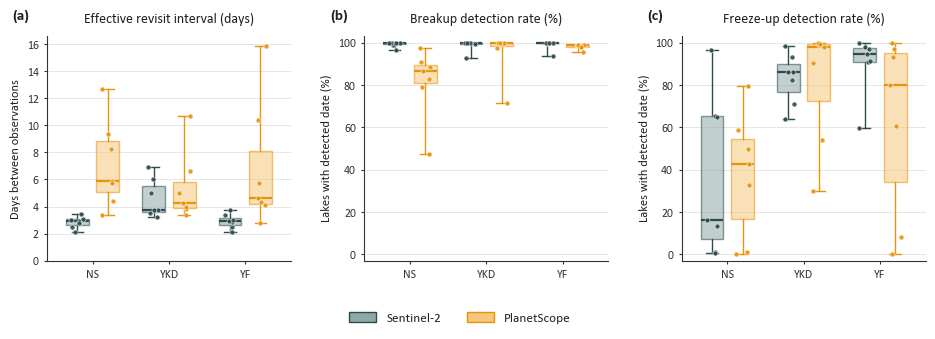


      metric                sat     median      min      max
NS    revisit (d)           S2        2.90     2.15     3.42
NS    revisit (d)           PS        5.92     3.36    12.66
NS    breakup (%)           S2       99.86    96.45   100.00
NS    breakup (%)           PS       86.83    47.65    97.51
NS    freezeup (%)          S2       16.35     0.63    96.38
NS    freezeup (%)          PS       42.80     0.18    79.35
YKD   revisit (d)           S2        3.73     3.26     6.90
YKD   revisit (d)           PS        4.27     3.34    10.69
YKD   breakup (%)           S2       99.82    92.70   100.00
YKD   breakup (%)           PS       99.77    71.38   100.00
YKD   freezeup (%)          S2       86.28    63.85    98.32
YKD   freezeup (%)          PS       98.02    30.06    99.76
YF    revisit (d)           S2        2.93     2.15     3.73
YF    revisit (d)           PS        4.61     2.76    15.87
YF    breakup (%)           S2      100.00    93.97   100.00
YF    breakup (%)      

: 

In [ ]:
"""
Publication figure — satellite performance summary as box-and-whisker plots.

Three panels, each with paired boxes (Sentinel-2 vs PlanetScope) per site:
  (a) Effective revisit interval (days)
  (b) Breakup detection rate (%)
  (c) Freeze-up detection rate (%)

Each box summarizes the distribution of annual values across 2019-2025
(one jittered point per year, n = 7). Whiskers span the full range
(no hidden outliers), the heavy line is the median.

Data loading and metric computation are identical to the original script.
Output is saved at 600 dpi as both PNG and PDF (vector) for submission.
"""

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
import os

# ── USER CONFIG ────────────────────────────────────────────────────────────────

SITES_TO_PLOT = ['NS', 'YKD', 'YF']
ALL_YEARS     = [2019, 2020, 2021, 2022, 2023, 2024, 2025]

SEASONS = {
    'NS':  {'Breakup': ('04-15', '07-30'), 'Freezeup': ('09-01', '10-30')},
    'YF':  {'Breakup': ('04-15', '07-15'), 'Freezeup': ('09-01', '11-15')},
    'YKD': {'Breakup': ('04-01', '06-30'), 'Freezeup': ('09-01', '11-30')},
}

BASE_DIR    = r"C:\Users\nj142\Desktop\Time Series"
OUTPUT_PNG  = os.path.join(BASE_DIR, "satellite_performance_boxplots.png")
OUTPUT_PDF  = os.path.join(BASE_DIR, "satellite_performance_boxplots.pdf")

SENTINEL_COLOR = '#2E4B4B'
PLANET_COLOR   = '#E8930C'
SENTINEL_LIGHT = '#8FA8A8'
PLANET_LIGHT   = '#F5C77A'

mpl.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'font.family': ['Calibri', 'Arial', 'DejaVu Sans'], 'font.size': 9,
    'axes.edgecolor': '#333333', 'axes.linewidth': 0.8,
    'text.color': '#222222', 'axes.labelcolor': '#222222',
    'xtick.color': '#333333', 'ytick.color': '#333333',
    'pdf.fonttype': 42, 'ps.fonttype': 42,   # editable text in vector output
})

# ── LOADING & METRICS (unchanged from original) ───────────────────────────────

def load_results(csv_path, date_col):
    if not os.path.exists(csv_path): return pd.DataFrame()
    df = pd.read_csv(csv_path)
    df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
    df = df[df[date_col].notna()].copy()
    df['year'] = df[date_col].dt.year
    return df

def load_timeseries(csv_path, date_col='date', id_col='lake_id'):
    if not os.path.exists(csv_path):
        return pd.DataFrame(columns=[id_col, 'date', 'year'])
    df = pd.read_csv(csv_path)
    if date_col not in df.columns and 'datetime' in df.columns:
        date_col = 'datetime'
    df['date'] = pd.to_datetime(df[date_col], errors='coerce')
    df = df[df['date'].notna()].copy()
    df['year'] = df['date'].dt.year
    return df[[id_col, 'date', 'year']].drop_duplicates()

def per_lake_gaps(obs_df, lakes, season_start, season_end, id_col='lake_id'):
    results = {}
    win_len = (season_end - season_start).days + 1
    if obs_df.empty:
        return {l: float(win_len) for l in lakes}
    sub = obs_df[(obs_df['date'] >= season_start) & (obs_df['date'] <= season_end)]
    for lake in lakes:
        lake_dates = sub[sub[id_col] == lake]['date'].sort_values().unique()
        if len(lake_dates) == 0:
            results[lake] = float(win_len)
        elif len(lake_dates) == 1:
            d = pd.Timestamp(lake_dates[0])
            results[lake] = ((d - season_start).days + (season_end - d).days) / 2.0
        else:
            diffs = np.diff(pd.to_datetime(lake_dates)).astype('timedelta64[D]').astype(int)
            results[lake] = float(np.mean(diffs))
    return results

def satellite_revisit_stats(site, obs_bu, obs_fu):
    bu_s_md, bu_e_md = SEASONS[site]['Breakup']
    fu_s_md, fu_e_md = SEASONS[site]['Freezeup']
    per_year = {}
    for yr in ALL_YEARS:
        bu_start, bu_end = pd.Timestamp(f"{yr}-{bu_s_md}"), pd.Timestamp(f"{yr}-{bu_e_md}")
        fu_start, fu_end = pd.Timestamp(f"{yr}-{fu_s_md}"), pd.Timestamp(f"{yr}-{fu_e_md}")
        lakes = set()
        for d in (obs_bu, obs_fu):
            if not d.empty: lakes.update(d['lake_id'].unique())
        lakes = sorted(lakes)
        bu_gaps = per_lake_gaps(obs_bu, lakes, bu_start, bu_end)
        fu_gaps = per_lake_gaps(obs_fu, lakes, fu_start, fu_end)
        combined = []
        for lake in lakes:
            g = [d[lake] for d in (bu_gaps, fu_gaps) if lake in d]
            if g: combined.append(np.mean(g))
        per_year[yr] = float(np.mean(combined)) if combined else float('nan')
    return per_year

def detection_pct(df_res, obs_df, year, id_col='lake_id'):
    if obs_df.empty or id_col not in df_res.columns:
        return float('nan')
    pool = set(obs_df[obs_df['year'] == year][id_col].unique())
    if not pool: return float('nan')
    det = set(df_res[df_res['year'] == year][id_col].unique())
    return 100.0 * len(det & pool) / len(pool)

# ── ASSEMBLE ANNUAL METRICS ───────────────────────────────────────────────────

stats = {}
for site in SITES_TO_PLOT:
    P = lambda *a: os.path.join(BASE_DIR, *a)
    df_ps_bu = load_results(P("PS", "Breakup",  f"{site}_breakup_dates.csv"),  'breakup_date')
    df_ps_fu = load_results(P("PS", "Freezeup", f"{site}_freezeup_dates.csv"), 'freezeup_date')
    df_s2_bu = load_results(P("S2", "Breakup",  f"{site}_breakup_dates.csv"),  'breakup_date')
    df_s2_fu = load_results(P("S2", "Freezeup", f"{site}_freezeup_dates.csv"), 'freezeup_date')

    obs_ps_bu = load_timeseries(P("PS", "Breakup",  f"{site}_breakup_lake_obs.csv"))
    obs_ps_fu = load_timeseries(P("PS", "Freezeup", f"{site}_freezeup_lake_obs.csv"))
    obs_s2_bu = load_timeseries(P("S2", "Breakup",  f"{site}_breakup_lake_obs.csv"))
    obs_s2_fu = load_timeseries(P("S2", "Freezeup", f"{site}_freezeup_lake_obs.csv"))

    ps_rev = satellite_revisit_stats(site, obs_ps_bu, obs_ps_fu)
    s2_rev = satellite_revisit_stats(site, obs_s2_bu, obs_s2_fu)

    stats[site] = {yr: {
        's2_revisit': s2_rev.get(yr, float('nan')),
        'ps_revisit': ps_rev.get(yr, float('nan')),
        's2_bu': detection_pct(df_s2_bu, obs_s2_bu, yr),
        'ps_bu': detection_pct(df_ps_bu, obs_ps_bu, yr),
        's2_fu': detection_pct(df_s2_fu, obs_s2_fu, yr),
        'ps_fu': detection_pct(df_ps_fu, obs_ps_fu, yr),
    } for yr in ALL_YEARS}

# ── FIGURE ────────────────────────────────────────────────────────────────────

rng = np.random.default_rng(0)   # fixed seed → reproducible jitter

fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.4))
fig.subplots_adjust(left=0.065, right=0.99, top=0.86, bottom=0.20, wspace=0.30)

metrics = [
    ('a', 'Effective revisit interval (days)', ('s2_revisit', 'ps_revisit')),
    ('b', 'Breakup detection rate (%)',        ('s2_bu', 'ps_bu')),
    ('c', 'Freeze-up detection rate (%)',      ('s2_fu', 'ps_fu')),
]
box_w, off = 0.30, 0.20

for ax, (letter, title, (k_s2, k_ps)) in zip(axes, metrics):
    for si, site in enumerate(SITES_TO_PLOT):
        for key, color, light, dx in [(k_s2, SENTINEL_COLOR, SENTINEL_LIGHT, -off),
                                      (k_ps, PLANET_COLOR, PLANET_LIGHT, +off)]:
            vals = np.array([stats[site][y][key] for y in ALL_YEARS], float)
            vals = vals[~np.isnan(vals)]
            if len(vals) == 0:
                continue
            x = si + dx
            ax.boxplot([vals], positions=[x], widths=box_w,
                       patch_artist=True, showcaps=True, showfliers=False,
                       whis=(0, 100), zorder=2,
                       boxprops=dict(facecolor=light, edgecolor=color, lw=1.0, alpha=0.55),
                       whiskerprops=dict(color=color, lw=1.0),
                       capprops=dict(color=color, lw=1.0),
                       medianprops=dict(color=color, lw=1.6))
            jit = (rng.random(len(vals)) - 0.5) * box_w * 0.55
            ax.scatter(np.full(len(vals), x) + jit, vals, s=13,
                       facecolor=color, edgecolor='white', lw=0.4,
                       zorder=3, alpha=0.9)

    ax.set_xticks(range(len(SITES_TO_PLOT)))
    ax.set_xticklabels(SITES_TO_PLOT, fontsize=9.5)
    ax.set_xlim(-0.6, len(SITES_TO_PLOT) - 0.4)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    ax.yaxis.grid(True, color='#e2e2e2', lw=0.6, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(length=2.5, labelsize=8.5)
    ax.set_title(title, fontsize=10, pad=10)
    ax.text(-0.14, 1.06, f'({letter})', transform=ax.transAxes,
            fontsize=11, fontweight='bold', va='bottom')
    if letter == 'a':
        ax.set_ylabel('Days between observations', fontsize=9)
        ax.set_ylim(bottom=0)
    else:
        ax.set_ylabel('Lakes with detected date (%)', fontsize=9)
        ax.set_ylim(-3, 103)

h1 = mpatches.Patch(facecolor=SENTINEL_LIGHT, edgecolor=SENTINEL_COLOR, label='Sentinel-2')
h2 = mpatches.Patch(facecolor=PLANET_LIGHT, edgecolor=PLANET_COLOR, label='PlanetScope')
fig.legend(handles=[h1, h2], loc='lower center', ncol=2,
           bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=9.5)

fig.savefig(OUTPUT_PNG, dpi=600, bbox_inches='tight')
fig.savefig(OUTPUT_PDF, bbox_inches='tight')
plt.show()

# ── CONSOLE SUMMARY (medians / ranges per box) ────────────────────────────────

print("\n" + "=" * 66)
print(f"{'':6s}{'metric':22s}{'sat':5s}{'median':>9s}{'min':>9s}{'max':>9s}")
print("=" * 66)
for site in SITES_TO_PLOT:
    for label, key in [('revisit (d)', 'revisit'), ('breakup (%)', 'bu'), ('freezeup (%)', 'fu')]:
        for sat in ('s2', 'ps'):
            vals = np.array([stats[site][y][f"{sat}_{key.split()[0].rstrip('()d%')}"
                             if False else f"{sat}_" + ('revisit' if 'revisit' in label
                             else ('bu' if 'breakup' in label else 'fu'))]
                             for y in ALL_YEARS], float)
            vals = vals[~np.isnan(vals)]
            if len(vals):
                print(f"{site:6s}{label:22s}{sat.upper():5s}"
                      f"{np.median(vals):9.2f}{vals.min():9.2f}{vals.max():9.2f}")
print("=" * 66)

# BELOW: YEARLY BOXPLOTS

In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from scipy import stats
import warnings

plt.rcParams["font.family"] = "Times New Roman"

# ----------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------
TEXT_SCALE = 1.8
SITES   = ["YKD", "YF", "NS"]
SENSORS = ["PS", "S2"]
EVENTS  = ["Breakup", "Freezeup"]
SENSOR_LABELS = {"PS": "Planet", "S2": "Sentinel"}
CSV_TEMPLATE = r"C:\Users\nj142\Desktop\Time Series\{sensor}\{event}\{site}_{event_lower}_dates.csv"
SHP_TEMPLATE = (
    r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data"
    r"\{site} 50x50 km\{site} Lakes from ALPOD Shapefile\{site}_50x50km_lakes.shp"
)
SMALL_THRESHOLD  = 0.01
MEDIUM_THRESHOLD = 0.5

PLANET_COLOR   = "#ffa600"
SENTINEL_COLOR = "#2f4f4f"

def _ramp(base):
    return {"Small": base, "Medium": base, "Large": base}

SENSOR_COLORS = {"PS": _ramp(PLANET_COLOR), "S2": _ramp(SENTINEL_COLOR)}
SIZE_ORDER       = ["Small", "Medium", "Large"]
SIZE_SHORT_LABEL = {"Small": "S", "Medium": "M", "Large": "L"}
SIZE_SCORES      = {"Small": 1, "Medium": 2, "Large": 3}
ID_CANDIDATES = ["lake_id", "Lake_id", "LAKE_ID", "id", "ID",
                 "alpod_id", "ALPOD_ID", "Hylak_id", "OBJECTID", "FID"]

# ----------------------------------------------------------------------
# Loaders (Year-Aware)
# ----------------------------------------------------------------------
_event_cache, _areas_cache, _assemble_cache = {}, {}, {}

def load_lake_areas(site):
    if site in _areas_cache: return _areas_cache[site].copy()
    gdf = gpd.read_file(SHP_TEMPLATE.format(site=site))
    id_col = next((c for c in ID_CANDIDATES if c in gdf.columns), None)
    gdf_proj = gdf.to_crs("EPSG:6933") if gdf.crs.is_geographic else gdf
    gdf["area_km2"] = gdf_proj.geometry.area / 1e6
    out = gdf[[id_col, "area_km2"]].rename(columns={id_col: "lake_id"})
    out["lake_id"] = pd.to_numeric(out["lake_id"], errors="coerce").astype("Int64").astype(str)
    _areas_cache[site] = out
    return out.copy()

def load_event(sensor, site, event):
    key = (sensor, site, event)
    if key in _event_cache: return _event_cache[key].copy()
    csv = CSV_TEMPLATE.format(sensor=sensor, event=event, event_lower=event.lower(), site=site)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        df = pd.read_csv(csv, low_memory=False)
    date_col = f"{event.lower()}_date"
    parsed = pd.to_datetime(df[date_col], format="%m/%d/%Y %H:%M", errors="coerce")
    if parsed.isna().mean() > 0.5: parsed = pd.to_datetime(df[date_col], format="mixed", errors="coerce")
    df[date_col] = parsed
    df = df.dropna(subset=[date_col])
    df["doy"] = df[date_col].dt.dayofyear
    df["year"] = df[date_col].dt.year
    df["lake_id"] = pd.to_numeric(df["lake_id"], errors="coerce").astype("Int64").astype(str)
    result = df.groupby(["lake_id", "year"], as_index=False)["doy"].mean()
    _event_cache[key] = result
    return result.copy()

def classify_size(a):
    if a < SMALL_THRESHOLD:  return "Small"
    if a < MEDIUM_THRESHOLD: return "Medium"
    return "Large"

def assemble(sensor, site):
    key = (sensor, site)
    if key in _assemble_cache: return _assemble_cache[key].copy()
    areas = load_lake_areas(site)
    bu = load_event(sensor, site, "Breakup").rename(columns={"doy": "breakup_doy"})
    fu = load_event(sensor, site, "Freezeup").rename(columns={"doy": "freezeup_doy"})
    events = pd.merge(bu, fu, on=["lake_id", "year"], how="outer")
    df = areas.merge(events, on="lake_id", how="right")
    df["size_class"] = df["area_km2"].apply(classify_size)
    _assemble_cache[key] = df
    return df.copy()

# ----------------------------------------------------------------------
# Plotting: Yearly Faceted Boxplots
# ----------------------------------------------------------------------
EVENT_COL = {"Breakup": "breakup_doy", "Freezeup": "freezeup_doy"}

def make_yearly_boxplot_figures(all_dfs):
    # Determine unique years across all datasets
    all_combined = pd.concat(all_dfs.values())
    years = sorted(all_combined["year"].unique())
    
    pair_offsets = {"PS": -0.22, "S2": +0.22}
    box_width    = 0.38

    for event in EVENTS:
        col = EVENT_COL[event]
        # Calculate consistent Y-axis for the event
        all_vals = all_combined[col].dropna()
        lo, hi = all_vals.min(), all_vals.max()
        pad = (hi - lo) * 0.1
        ylim = (lo - pad, hi + pad)

        fig = plt.figure(figsize=(18, 4 * len(years)))
        gs = GridSpec(len(years), len(SITES), figure=fig, wspace=0.15, hspace=0.3)

        for r_idx, yr in enumerate(years):
            for c_idx, site in enumerate(SITES):
                ax = fig.add_subplot(gs[r_idx, c_idx])
                
                group_centers = [0, 1, 2]
                
                for sensor in SENSORS:
                    df = all_dfs[(sensor, site)]
                    yr_df = df[df["year"] == yr]
                    
                    positions, data, colors = [], [], []
                    for sz_idx, sc in enumerate(SIZE_ORDER):
                        vals = yr_df.loc[yr_df["size_class"] == sc, col].dropna().values
                        positions.append(group_centers[sz_idx] + pair_offsets[sensor])
                        data.append(vals)
                        colors.append(SENSOR_COLORS[sensor][sc])

                    if any(len(d) > 0 for d in data):
                        bp = ax.boxplot(
                            data, positions=positions, widths=box_width, patch_artist=True,
                            medianprops=dict(color="black", linewidth=1.2),
                            flierprops=dict(marker="o", markersize=2, alpha=0.3)
                        )
                        for patch, c in zip(bp["boxes"], colors):
                            patch.set_facecolor(c)

                # Formatting
                ax.set_ylim(ylim)
                ax.set_xlim(-0.7, 2.7)
                ax.set_xticks(group_centers)
                ax.set_xticklabels([SIZE_SHORT_LABEL[sc] for sc in SIZE_ORDER], fontsize=8*TEXT_SCALE)
                ax.grid(True, axis="y", alpha=0.15)

                if r_idx == 0:
                    ax.set_title(site, fontsize=12*TEXT_SCALE, fontweight="bold", pad=10)
                if c_idx == 0:
                    ax.set_ylabel(f"{yr}\nDOY", fontsize=10*TEXT_SCALE, fontweight="bold")
                else:
                    ax.tick_params(labelleft=False)

        fig.suptitle(f"Yearly {event} Timing by Lake Size Class", fontsize=16*TEXT_SCALE, y=0.98, fontweight="bold")
        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

# ----------------------------------------------------------------------
# Entry Point
# ----------------------------------------------------------------------
if __name__ == "__main__":
    # 1. Load Data
    all_dfs = {(sn, s): assemble(sn, s) for sn in SENSORS for s in SITES}

    # 2. Generate the large multi-year boxplot figures
    make_yearly_boxplot_figures(all_dfs)

# Random year sampler for NS investigation

Mode: RANDOM SITE+YEAR  |  Sensor: S2  |  Site: NS  |  Year: 2020
  → 5694 (lake, year) pairs for 2020  (77 with a freeze-up date, 5617 without)


**Lake 489603 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

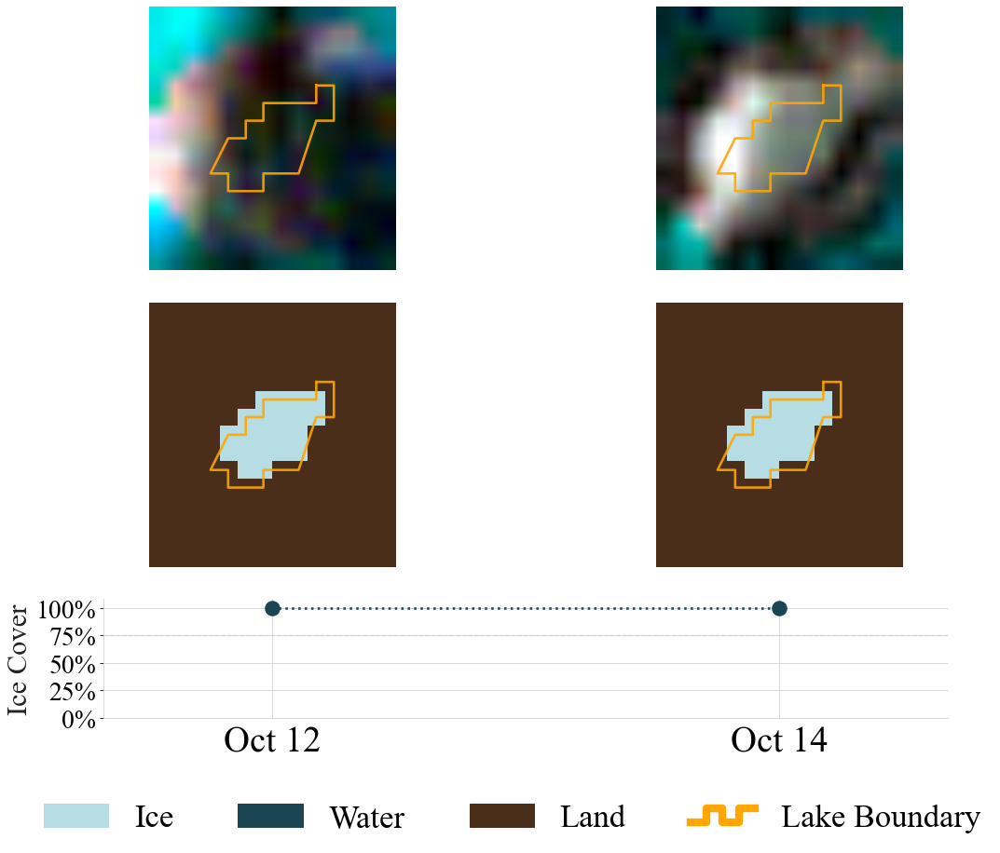

**Lake 499701 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

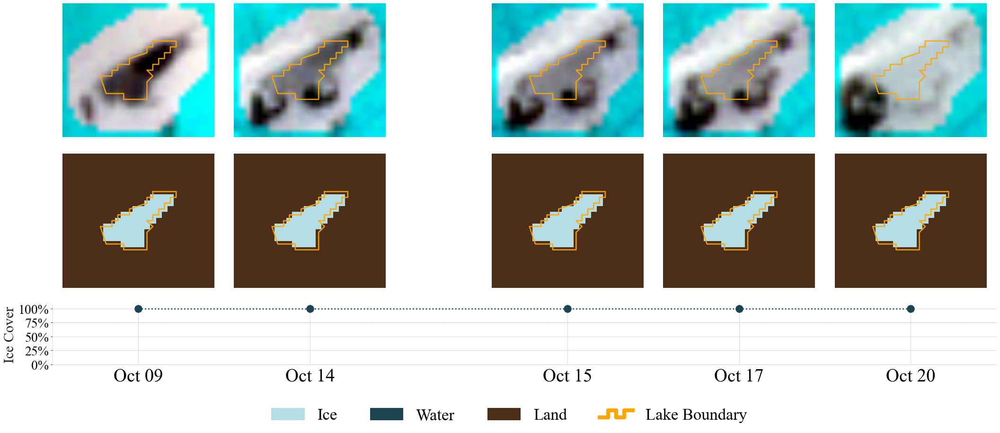

**Lake 499500 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

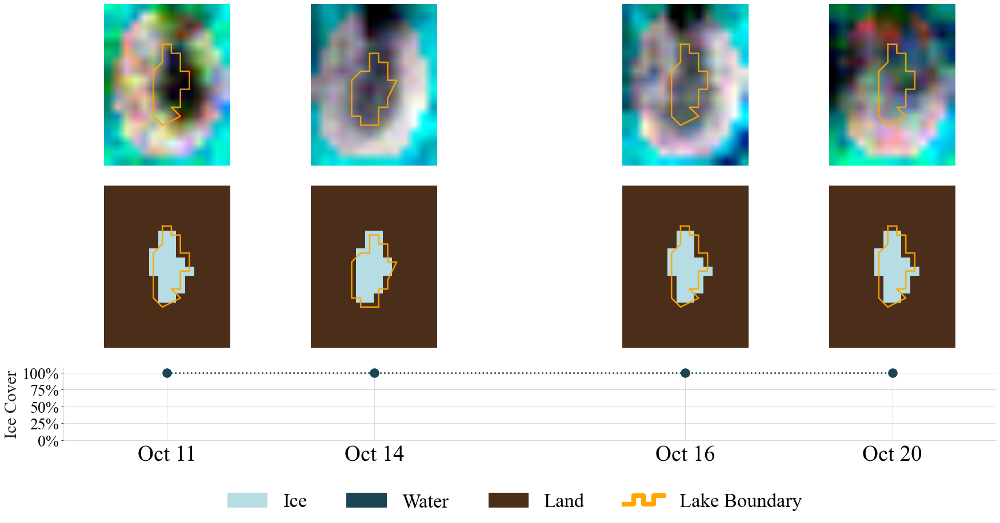

**Lake 490323 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

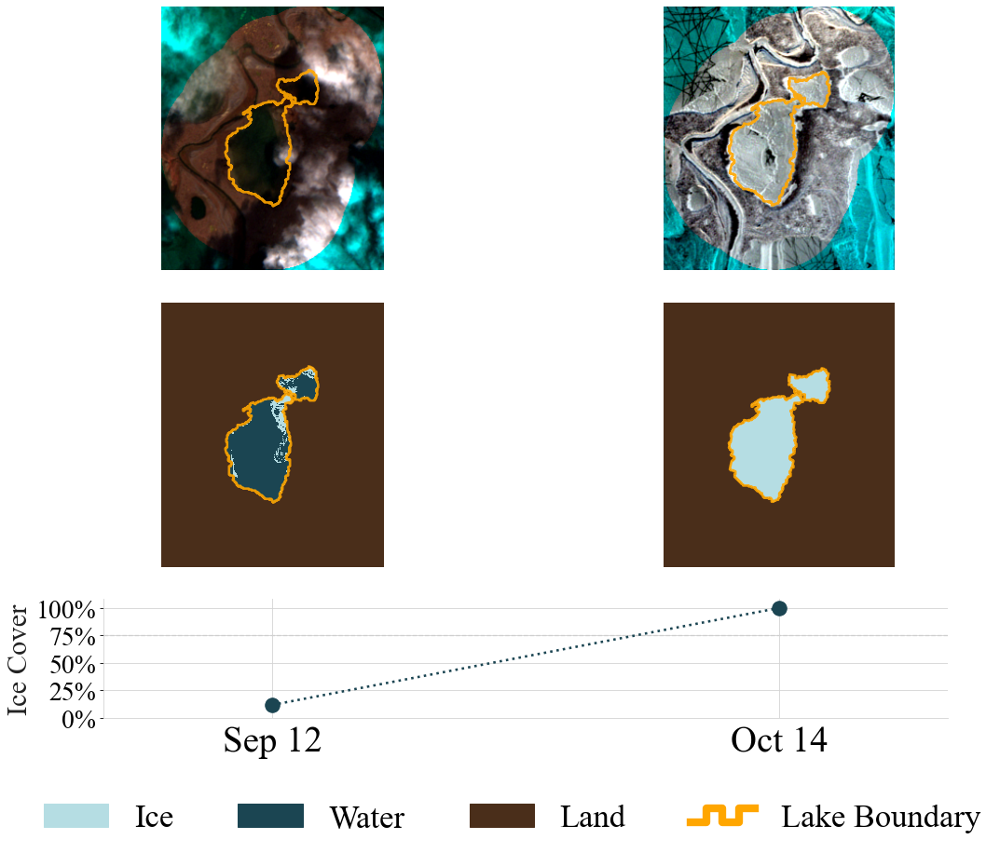

**Lake 499102 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

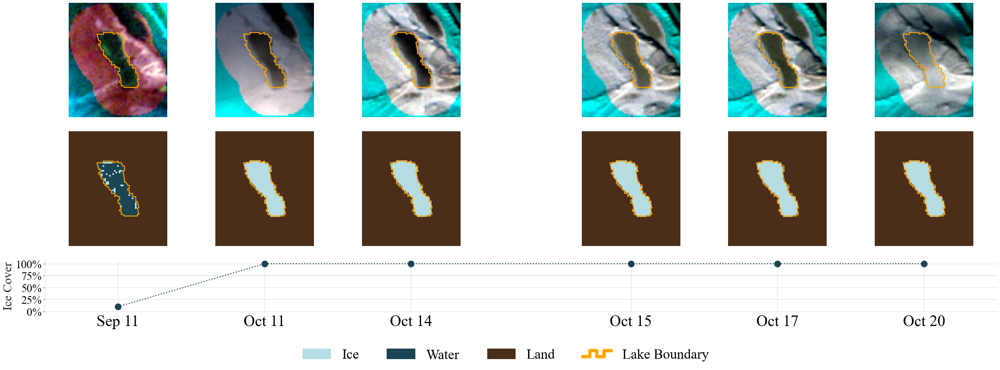

**Lake 490281 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

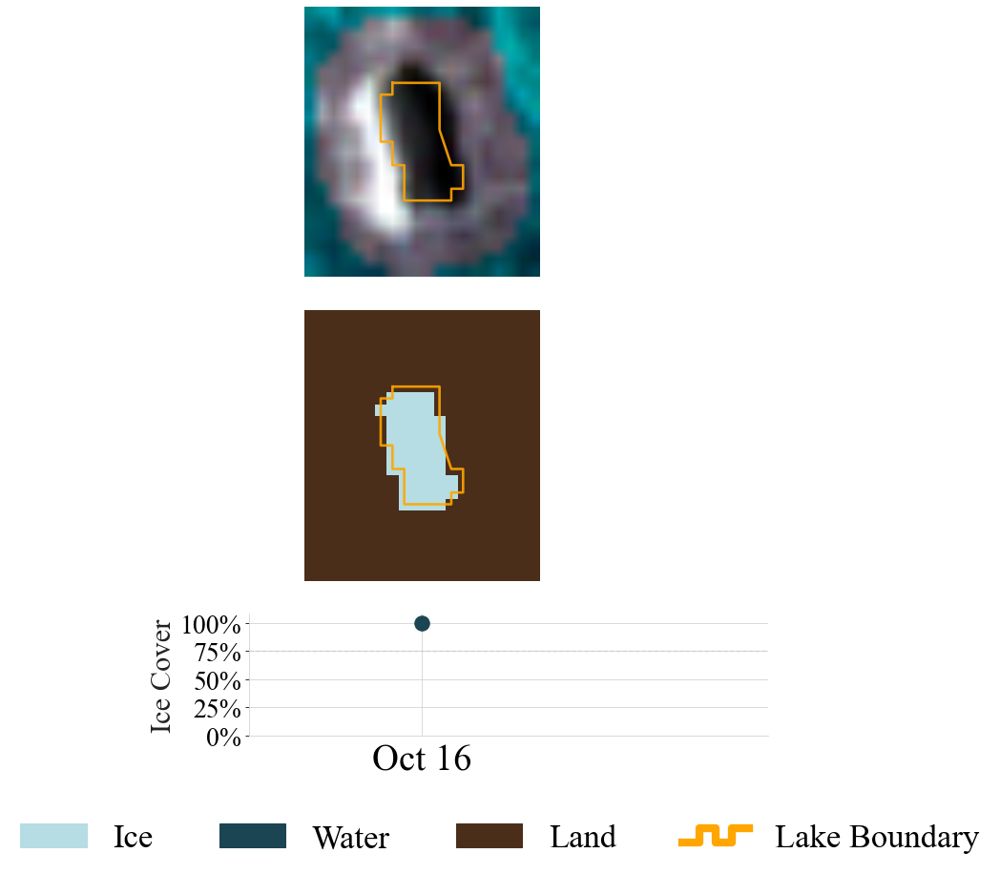

**Lake 500399 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

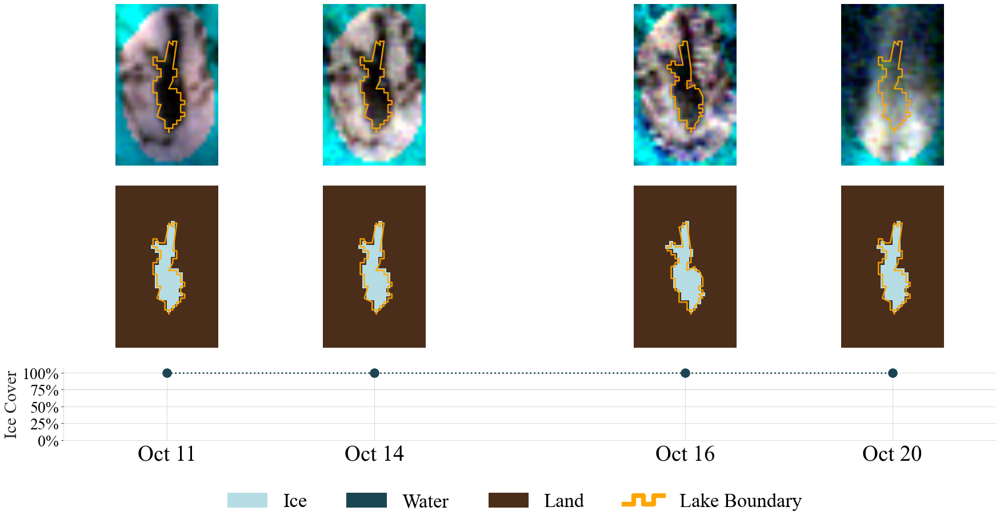

**Lake 492398 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

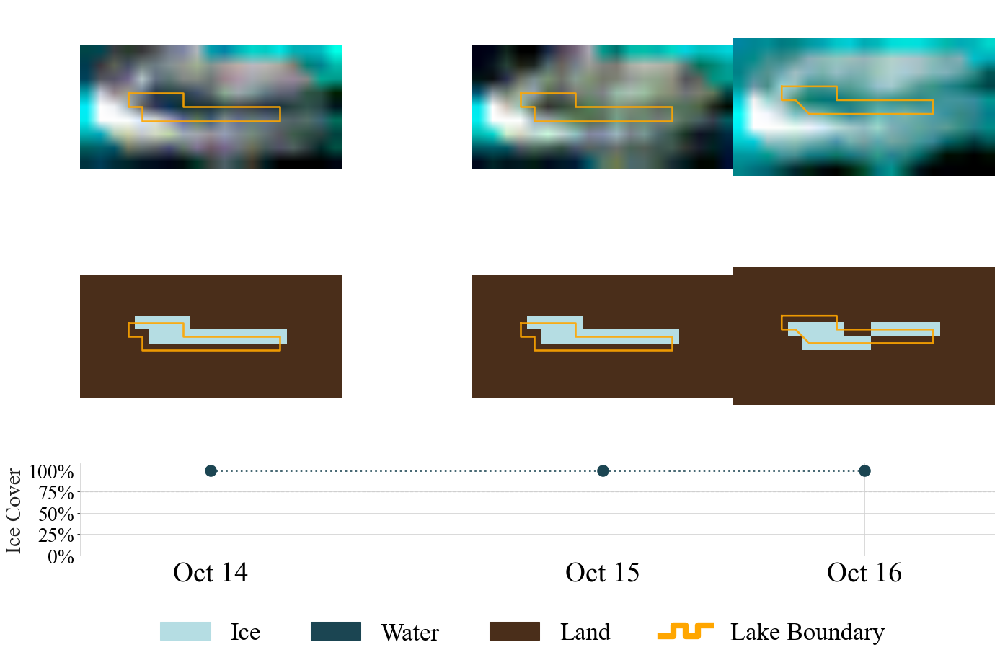

**Lake 488356 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

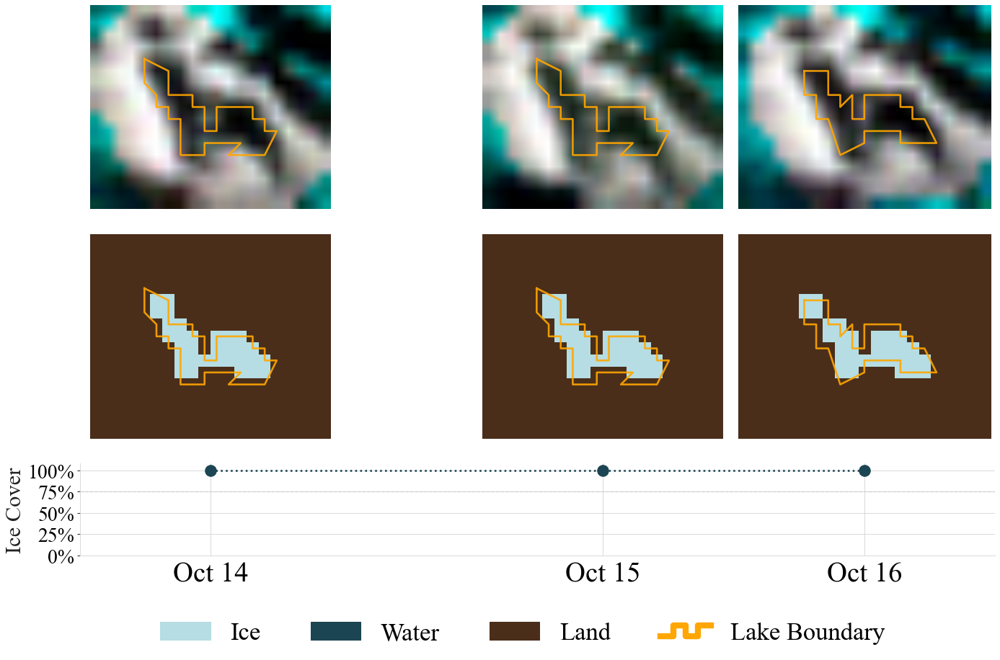

**Lake 488190 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

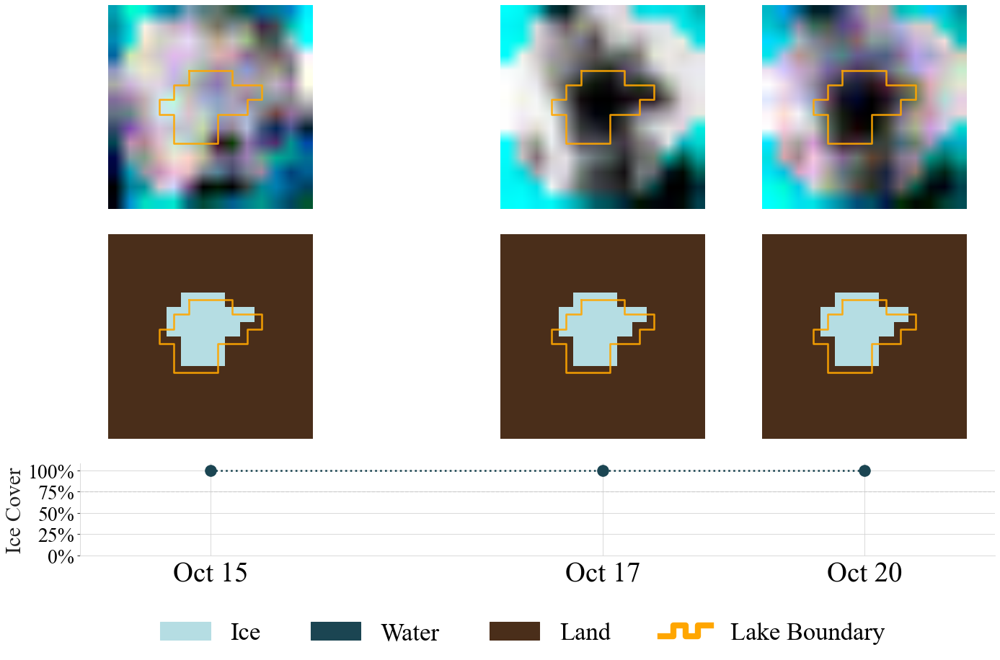

**Lake 493306 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

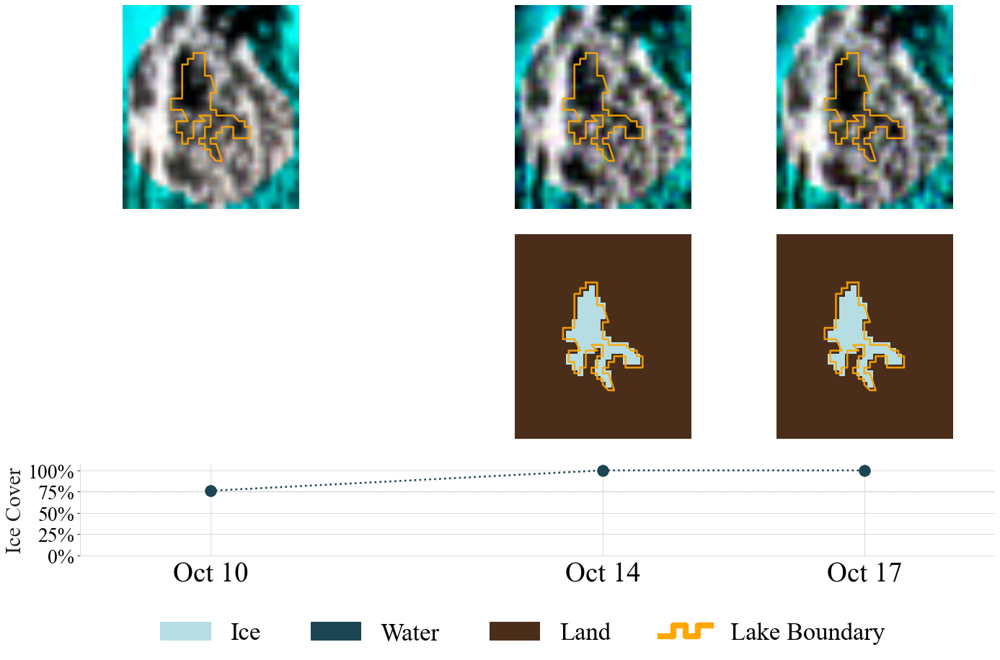

**Lake 491747 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

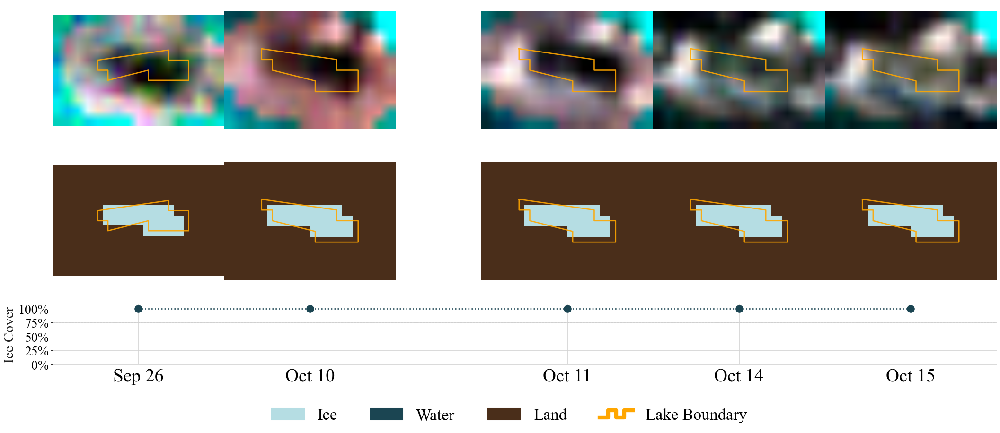

**Lake 501507 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

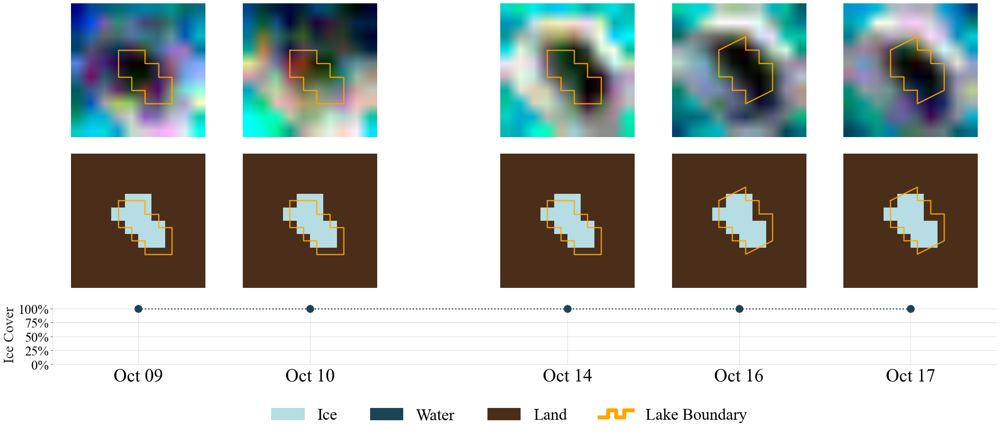

**Lake 492204 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

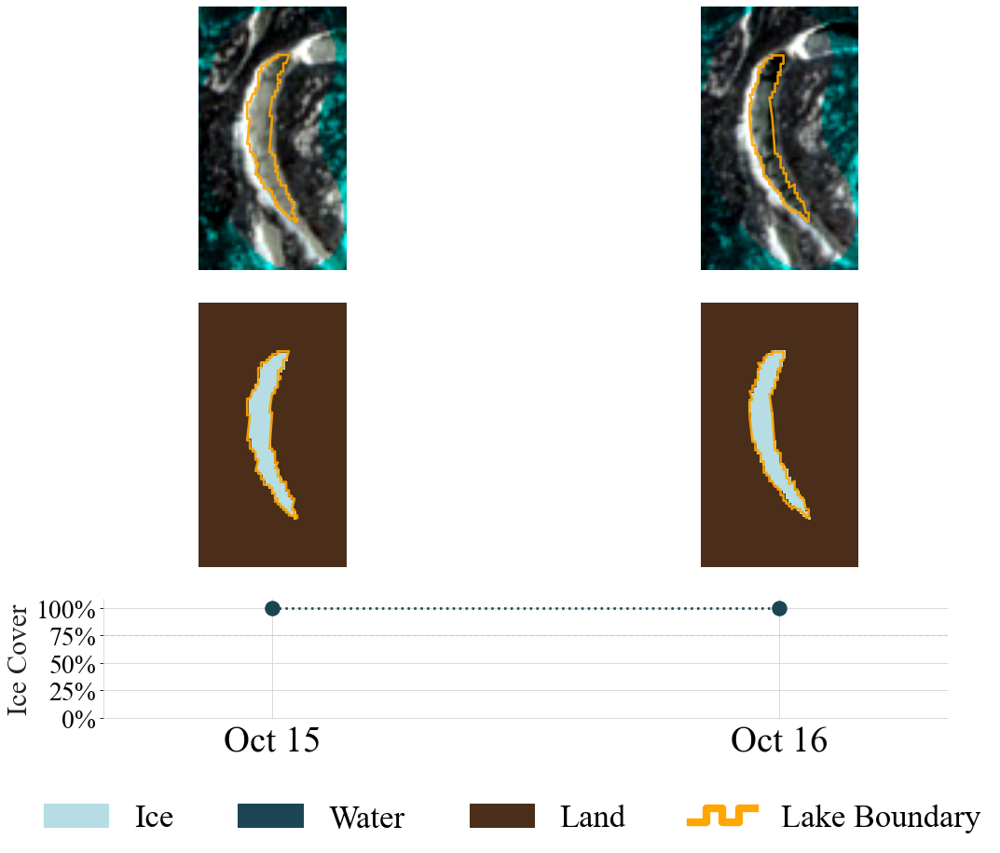

**Lake 503216 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

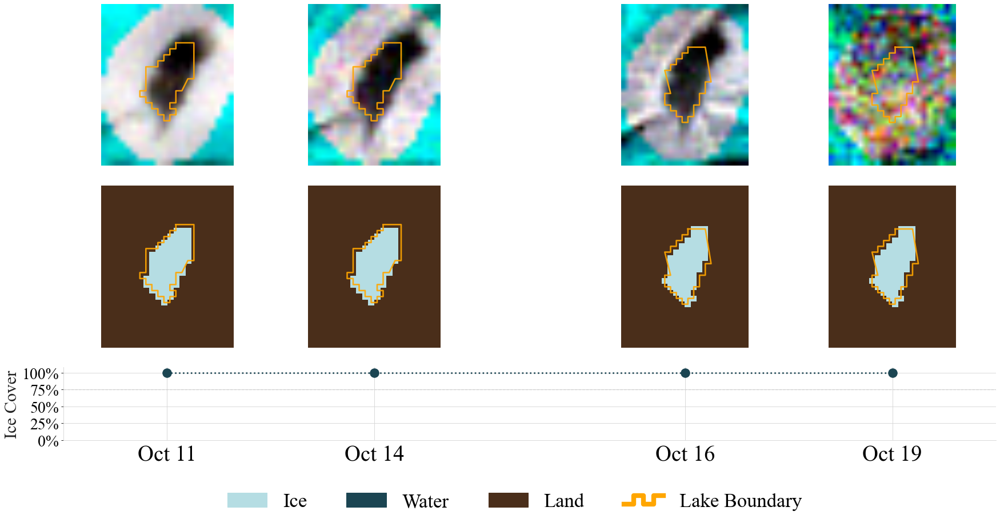

**Lake 491573 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

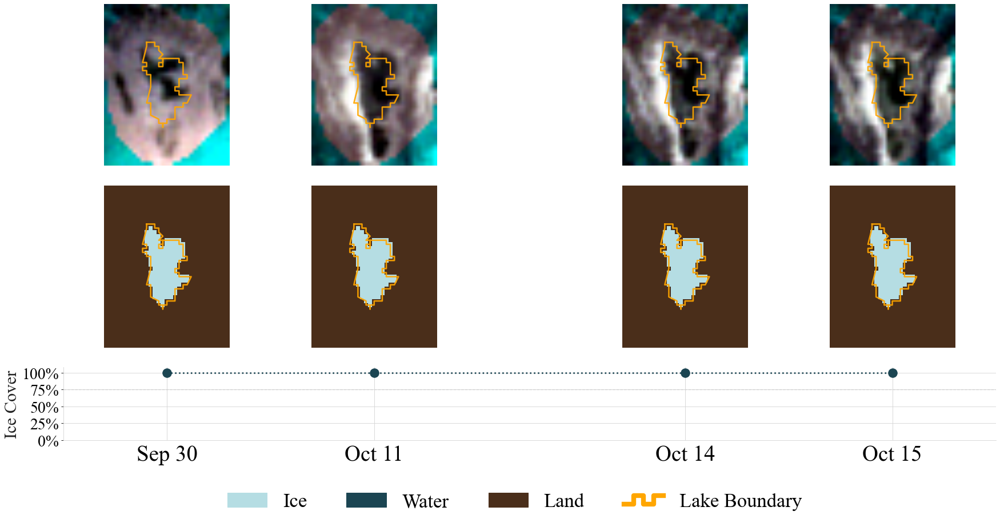

**Lake 489699 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

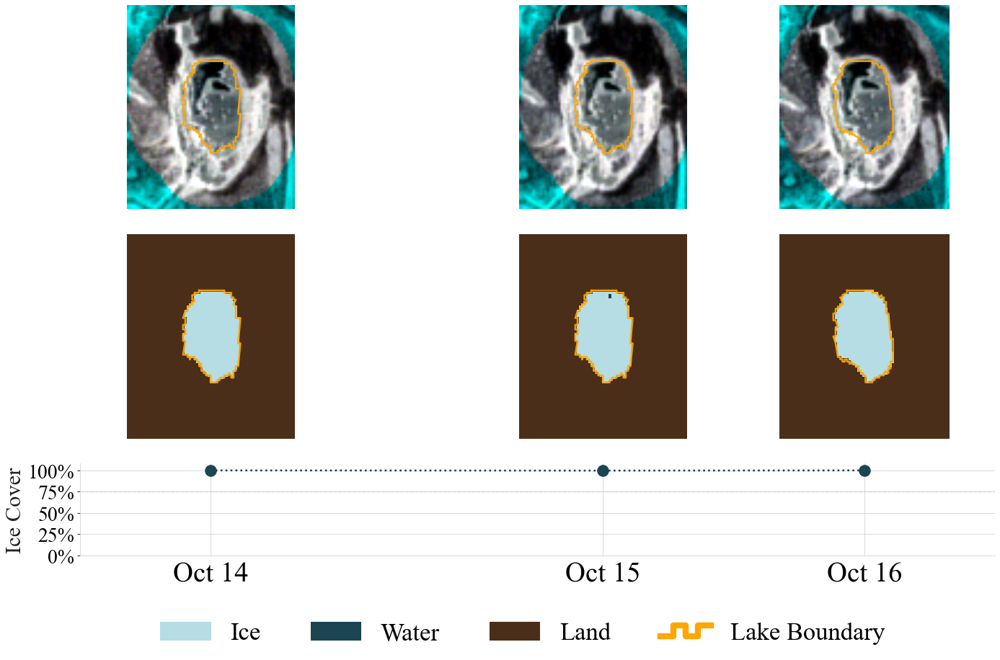

**Lake 491520 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

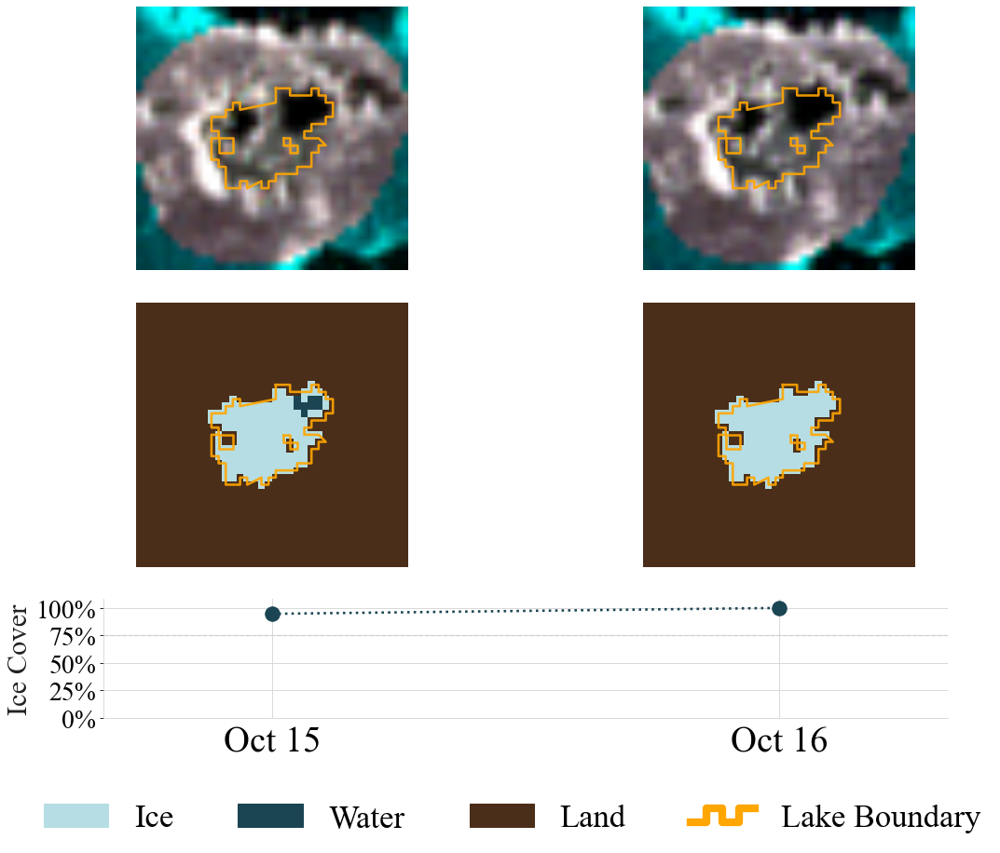

**Lake 494972 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

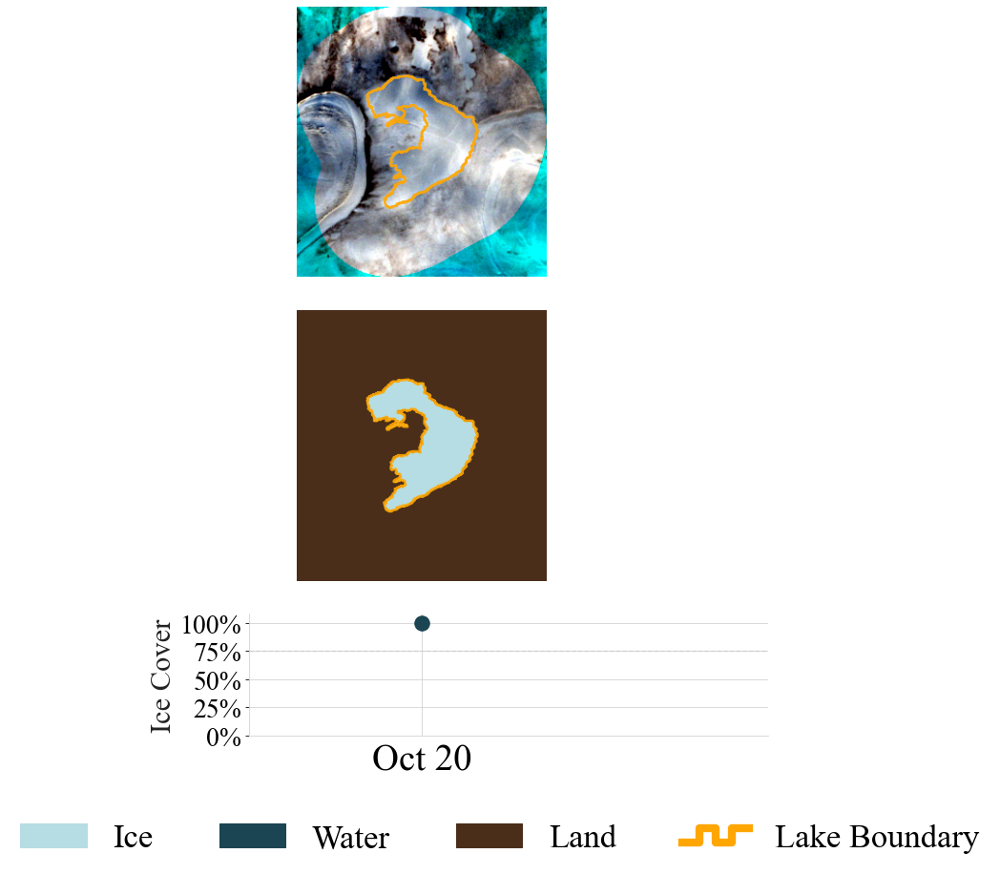

**Lake 489330 — NS — 2020** &nbsp;·&nbsp; no freeze-up detected (showing available observations)

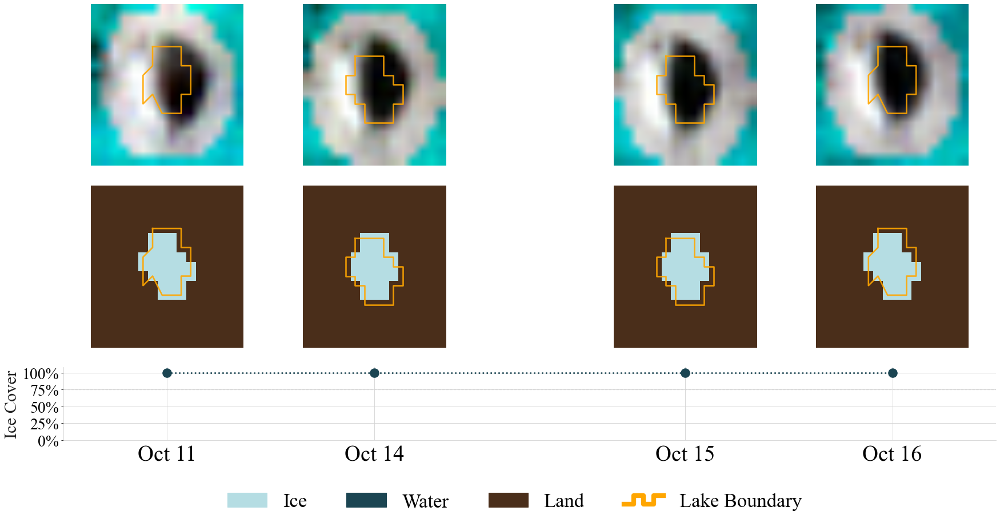


  Rendered 20 of 20 requested time series (from 5694 available for NS 2020).


In [2]:
"""
freezeup_quartile_sampler.py

Self-contained. Samples 5 random (lake_id, year) pairs from each quartile of
pre-computed freeze-up DOY among lakes filtered by LAKE_SIZE_CLASS and renders
all 20 time series with a quartile header between groups.

Alternatively, provide a MANUAL_SELECTION dict in the USER CONFIG section to
show only specific (lake_id, site, year) combinations instead of random
quartile sampling.

As a third option, when MANUAL_SELECTION is empty/None and RANDOM_MODE is set
to "site_year", the script randomly samples N_RANDOM_SAMPLES (lake_id) time
series from a single study site and year, WHETHER OR NOT a freeze-up date was
detected. All lake sizes are eligible in this mode.

Time-series observations and image filenames are read directly from the
wide Obs{k} / Obs{k}Date / Obs{k}PctIce columns in *_freezeup_dates.csv —
the separate *_freezeup_lake_obs.csv is NOT used.

Supports SENSOR = "PS" (PlanetScope) or "S2" (Sentinel-2). For S2:
  - Each "filename" in the Obs columns is a scene token (e.g.
    S2A_4WFD_20190903_0_L2A) corresponding to a folder of per-band TIFs.
  - RGB is composed from B04/B03/B02 on the B04 (10 m) grid.
  - Classification uses the bands listed in the model's feature_columns
    (typically B02, B03, B04, B08, B11, B12, SCL), nearest-resampled to
    the B04 grid.

File structure
--------------
Freeze-up dates + embedded observations (post-filtering):
    C:\\Users\\nj142\\Desktop\\Time Series\\{SENSOR}\\Freezeup\\{SITE}_freezeup_dates.csv

Run inside Jupyter:
    %run freezeup_quartile_sampler.py
"""

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import geopandas as gpd
import rasterio
import rasterio.windows
import joblib
from matplotlib.legend_handler import HandlerBase
from rasterio.mask import mask as rio_mask
from rasterio.transform import rowcol as rio_rowcol
from rasterio.features import geometry_mask
from shapely.geometry import mapping
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
matplotlib.rcParams.update({
    "figure.dpi":       130,
    "savefig.dpi":      150,
    "figure.facecolor": "white",
    "font.family":      "Times New Roman",
})

# ══════════════════════════════════════════════════════════════════════════════
#  USER CONFIG
# ══════════════════════════════════════════════════════════════════════════════

# --- Sensor and site selection (used for random-sampling modes) ---
SENSOR = "S2"    # "PS" or "S2"
SITE   = "YKD"   # "YKD", "NS", or "YF"  (used only by the "quartile" mode)

# --- Manual selection (overrides all random sampling when populated) ---
#
# Provide a list of dicts with keys: "lake_id", "site", "year"
# The "site" field must match one of: "YKD", "NS", "YF"
# Leave as None (or an empty list []) to use one of the random modes instead.
#
# Example:
#MANUAL_SELECTION = [
#       {"lake_id": "178", "site": "YKD", "year": 2019},
#       {"lake_id": "178", "site": "YKD", "year": 2020},
#       {"lake_id": "178", "site": "YKD", "year": 2021},
#       {"lake_id": "178", "site": "YKD", "year": 2022},
#       {"lake_id": "178", "site": "YKD", "year": 2023},
#       {"lake_id": "178", "site": "YKD", "year": 2024},
#       {"lake_id": "178", "site": "YKD", "year": 2025},
#]
#
MANUAL_SELECTION = None

# --- Random sampling mode -----------------------------------------------------
# Used only when MANUAL_SELECTION is empty/None.
#
#   "site_year" : randomly sample N_RANDOM_SAMPLES (lake_id) time series from
#                 RANDOM_SITE in RANDOM_YEAR, WHETHER OR NOT a freeze-up date
#                 was found. Lake size is ignored (all sizes eligible).
#   "quartile"  : original behaviour — quartile-binned sampling for SITE,
#                 filtered by LAKE_SIZE_CLASS (only lakes with a freeze-up date).
RANDOM_MODE      = "site_year"
RANDOM_SITE      = "NS"
RANDOM_YEAR      = 2020
N_RANDOM_SAMPLES = 20

# --- Base paths (unchanged from original) ---
_BASE = r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data"
_ML   = (r"E:\planetscope_lake_ice\Data\Input"
         r"\Machine Learning - Planet Samples for RF\Models")

# --- S2 imagery + model roots ---
_S2_IMAGE_BASE = r"E:\sentinel_lake_ice\Data\Input\Freezeup S2 Data"
_S2_ML         = (r"E:\planetscope_lake_ice\Data\Input"
                  r"\Machine Learning - Sentinel Samples for RF\Models")

# --- Derived time-series paths (new structure) ---
_TS_BASE = r"C:\Users\nj142\Desktop\Time Series"

def _freezeup_dates_csv(sensor, site):
    return os.path.join(_TS_BASE, sensor, "Freezeup",
                        f"{site}_freezeup_dates.csv")

# --- Site-specific ALPOD paths (keyed by site tag, e.g. "YKD_50x50") ---
def _site_tag(site):
    return f"{site}_50x50"

SITE_FOLDER_MAP = {
    "YKD_50x50": os.path.join(_BASE, "YKD 50x50 km"),
    "NS_50x50":  os.path.join(_BASE, "NS 50x50 km"),
    "YF_50x50":  os.path.join(_BASE, "YF 50x50 km"),
}
SITE_SHAPEFILE_MAP = {
    "YKD_50x50": os.path.join(_BASE, "YKD 50x50 km",
                              "YKD Lakes from ALPOD Shapefile",
                              "YKD_50x50km_lakes.shp"),
    "NS_50x50":  os.path.join(_BASE, "NS 50x50 km",
                              "NS Lakes from ALPOD Shapefile",
                              "NS_50x50km_lakes.shp"),
    "YF_50x50":  os.path.join(_BASE, "YF 50x50 km",
                              "YF Lakes from ALPOD Shapefile",
                              "YF_50x50km_lakes.shp"),
}

# PlanetScope RF models
RF_MODEL_PATH_MAP = {
    "YKD_50x50": os.path.join(_ML, "YKD_Freezeup", "YKD_planet_training_RFmodel.joblib"),
    "NS_50x50":  os.path.join(_ML, "NS_Freezeup",  "NS_planet_training_RFmodel.joblib"),
    "YF_50x50":  os.path.join(_ML, "YF_Freezeup",  "YF_planet_training_RFmodel.joblib"),
}

# Sentinel-2 RF models
S2_RF_MODEL_PATH_MAP = {
    "YKD_50x50": os.path.join(_S2_ML, "YKD Freezeup", "YKD_freezeup_RFmodel.joblib"),
    "NS_50x50":  os.path.join(_S2_ML, "NS Freezeup",  "NS_freezeup_RFmodel.joblib"),
    "YF_50x50":  os.path.join(_S2_ML, "YF Freezeup",  "YF_freezeup_RFmodel.joblib"),
}

# Sentinel-2 imagery base folders (one per site).
S2_SITE_FOLDER_MAP = {
    "YKD_50x50": os.path.join(_S2_IMAGE_BASE, "YKD"),
    "NS_50x50":  os.path.join(_S2_IMAGE_BASE, "NS"),
    "YF_50x50":  os.path.join(_S2_IMAGE_BASE, "YF"),
}

# --- Sampler controls ---
SAMPLES_PER_Q = 5
RANDOM_SEED   = 123

# Lake size class to sample from in random-quartile mode.
# "S" = small  (<  0.01 km²)
# "M" = medium (0.01 – 0.50 km²)
# "L" = large  (>  0.50 km²)
LAKE_SIZE_CLASS = "L"

# --- Visualization controls ---
FREEZE_THRESHOLD = 75.0
N_IMAGES_BEFORE  = 8
N_IMAGES_AFTER   = 8
FONT_SCALE       = 1.33

# Uniform display scaling for the rendered figures.
# 0.5 = half size (2× smaller) with identical icons/markers/text proportions;
# 1.0 = original size. Rendering at a reduced DPI shrinks the whole figure
# uniformly, so every element keeps the same look — it's just smaller. This
# lets a full stack of time series fit in a single Jupyter cell.
FIGURE_SCALE = 0.5

# Colours
_ICE_LOW    = "#1b4552"
_ICE_HIGH   = "#1b4552"
_ACCENT     = "#ffa600"
_TEXT_DARK  = "#222222"
_MASK_ICE   = np.array([0xB5, 0xDD, 0xE3], dtype=np.uint8)
_MASK_WATER = np.array([0x1B, 0x45, 0x52], dtype=np.uint8)
_MASK_LAND  = np.array([0x4A, 0x2E, 0x1A], dtype=np.uint8)

# --- Sentinel-2 specifics ---
# RGB channels for true-color display (R, G, B).
_S2_RGB_BANDS = ("B04", "B03", "B02")
# Reference band for the common output grid (10 m).
_S2_REF_BAND  = "B04"
# All bands the classifier may need to read off disk. The actual feature order
# at predict time is taken from package["feature_columns"].
_S2_BAND_FILES = {
    "B01": "B01.tif", "B02": "B02.tif", "B03": "B03.tif", "B04": "B04.tif",
    "B05": "B05.tif", "B06": "B06.tif", "B07": "B07.tif", "B08": "B08.tif",
    "B8A": "B8A.tif", "B09": "B09.tif", "B11": "B11.tif", "B12": "B12.tif",
    "SCL": "SCL.tif",
}

# ══════════════════════════════════════════════════════════════════════════════
#  LAKE-SIZE FILTER
# ══════════════════════════════════════════════════════════════════════════════

_SIZE_BOUNDS = {
    "S": (0.0,  0.01),
    "M": (0.01, 0.5),
    "L": (0.5,  float("inf")),
}
_SIZE_LABELS = {
    "S": "small (<0.01 km²)",
    "M": "medium (0.01–0.50 km²)",
    "L": "large (>0.50 km²)",
}

def get_lake_ids_by_size(site_tag, size_class="L"):
    """Return the set of lake_id strings for lakes in the requested size class.

    Parameters
    ----------
    site_tag   : e.g. "YKD_50x50"
    size_class : "S", "M", or "L"

    Returns
    -------
    (ids: set, n_total: int, n_in_class: int)
    """
    lo, hi   = _SIZE_BOUNDS[size_class.upper()]
    shp_path = SITE_SHAPEFILE_MAP[site_tag]
    gdf      = gpd.read_file(shp_path)
    id_col   = next((c for c in ("id", "ID", "lake_id", "FID") if c in gdf.columns), "id")
    gdf_proj = gdf.to_crs("EPSG:6933") if gdf.crs.is_geographic else gdf
    gdf      = gdf.copy()
    gdf["area_km2"] = gdf_proj.geometry.area / 1e6

    # "S" and "M" use  lo < area <= hi
    # "L" uses          area > lo   (hi is inf)
    subset = gdf[(gdf["area_km2"] > lo) & (gdf["area_km2"] <= hi)] \
             if hi != float("inf") else gdf[gdf["area_km2"] > lo]

    ids = set(subset[id_col].astype(str).str.replace(r"\.0$", "", regex=True))
    return ids, len(gdf), len(subset)

# ══════════════════════════════════════════════════════════════════════════════
#  OBS-COLUMN PARSER  (replaces separate *_freezeup_lake_obs.csv)
# ══════════════════════════════════════════════════════════════════════════════

def parse_obs_from_row(row):
    """
    Unpack the wide Obs{k} / Obs{k}Date / Obs{k}PctIce columns from a single
    *_freezeup_dates.csv row into a tidy DataFrame.

    Returns
    -------
    DataFrame with columns:
        filename      – image filename (str). For PS this includes ".tif";
                        for S2 it is a scene token like
                        "S2A_4WFD_20190903_0_L2A".
        date          – pd.Timestamp (noon on observation date)
        ice_fraction  – float (0–100)
    """
    records = []
    k = 1
    while True:
        fname_col = f"Obs{k}"
        date_col  = f"Obs{k}Date"
        ice_col   = f"Obs{k}PctIce"

        # Stop when we run out of columns or hit an empty filename
        if fname_col not in row.index:
            break
        fname = str(row[fname_col]).strip()
        if not fname or fname.lower() in ("", "nan"):
            break

        date_str = str(row.get(date_col, "")).strip()
        ice_str  = str(row.get(ice_col,  "")).strip()

        try:
            obs_date = pd.to_datetime(date_str, format="%m/%d/%Y")
            # Set to noon so that datetime comparisons with interp_dt
            # (which has an intra-day component) behave correctly.
            obs_date = obs_date.replace(hour=12, minute=0, second=0)
        except Exception:
            k += 1
            if k > 500:          # safety valve
                break
            continue

        ice_frac = float(ice_str) if ice_str not in ("", "nan") else np.nan
        records.append({"filename": fname, "date": obs_date,
                        "ice_fraction": ice_frac})
        k += 1

    if not records:
        return pd.DataFrame(columns=["filename", "date", "ice_fraction"])

    return (pd.DataFrame(records)
              .sort_values("date")
              .reset_index(drop=True))


def _parse_date_mdy(s):
    """Parse a 'M/D/YYYY' string to a pd.Timestamp, or NaT."""
    try:
        return pd.to_datetime(str(s).strip(), format="%m/%d/%Y")
    except Exception:
        return pd.NaT


# ══════════════════════════════════════════════════════════════════════════════
#  GEOMETRY HELPERS
# ══════════════════════════════════════════════════════════════════════════════

def calculate_dynamic_buffer(lake_geom):
    """Buffer equal to 1.5× the mean radius (area-based)."""
    area = lake_geom.area
    mean_radius = np.sqrt(area / np.pi)
    return mean_radius * 1.5

# ══════════════════════════════════════════════════════════════════════════════
#  RF & IMAGE HELPERS
# ══════════════════════════════════════════════════════════════════════════════

RF_MODELS: dict = {}

def _rf_model_path(site_tag):
    """Return the RF model joblib path appropriate for the active SENSOR."""
    if SENSOR == "S2":
        return S2_RF_MODEL_PATH_MAP.get(site_tag)
    return RF_MODEL_PATH_MAP.get(site_tag)

def load_rf_models(site_tag):
    path = _rf_model_path(site_tag)
    if path and os.path.isfile(path):
        package = joblib.load(path)
        package["model"].set_params(n_jobs=-1)
        RF_MODELS[site_tag] = package
    else:
        print(f"  [warn] RF model not found for {site_tag} ({SENSOR}): {path}")

def classify_pixels(pixel_data, nodata, site_tag):
    """
    pixel_data : (n_features, n_pixels) array, rows ordered to match
                 package["feature_columns"]
    """
    _empty = (0, 0, np.array([], dtype=str), np.array([], dtype=bool))
    package = RF_MODELS.get(site_tag)
    if package is None or pixel_data.size == 0:
        return _empty
    model        = package["model"]
    le           = package["label_encoder"]
    feature_cols = package["feature_columns"]
    valid = (~np.all(pixel_data == nodata, axis=0)
             if nodata is not None
             else np.ones(pixel_data.shape[1], dtype=bool))
    pixels_np = pixel_data[:, valid].T
    if pixels_np.size == 0:
        return 0, 0, np.array([], dtype=str), valid
    predictions = model.predict(pd.DataFrame(pixels_np, columns=feature_cols))
    ice_idx     = int(np.where(le.classes_ == "ice")[0][0])
    pred_labels = np.where(predictions == ice_idx, "ice", "water")
    return (int(np.sum(pred_labels == "ice")),
            int(np.sum(pred_labels == "water")),
            pred_labels, valid)

def _stretch_uint8(band, lo=2, hi=98):
    band  = band.astype(np.float32)
    valid = band > 0
    if not valid.any():
        return np.zeros_like(band, dtype=np.uint8)
    p_lo, p_hi = np.percentile(band[valid], (lo, hi))
    if p_hi <= p_lo:
        return np.zeros_like(band, dtype=np.uint8)
    return np.clip((band - p_lo) / (p_hi - p_lo) * 255.0, 0, 255).astype(np.uint8)

# ─── PlanetScope (single multiband TIF) ──────────────────────────────────────

def _clip_to_lake_buffer_ps(tif_path, lake_geom, lake_crs, buffer_m):
    try:
        with rasterio.open(tif_path) as src:
            lake_proj = (gpd.GeoSeries([lake_geom], crs=lake_crs)
                         .to_crs(src.crs).geometry.iloc[0])
            out_img, out_tf = rio_mask(src, [lake_proj.buffer(buffer_m)],
                                       crop=True, nodata=0)
            rgba = np.dstack([
                _stretch_uint8(out_img[2]),
                _stretch_uint8(out_img[1]),
                _stretch_uint8(out_img[0]),
                np.where(((out_img[0] == 0) & (out_img[1] == 0) & (out_img[2] == 0)),
                         0, 255).astype(np.uint8),
            ])
        return rgba, out_tf, lake_proj, None
    except Exception as e:
        return None, None, None, str(e)

def _classify_and_build_mask_rgba_ps(tif_path, lake_geom, lake_crs, site_tag, buffer_m):
    with rasterio.open(tif_path) as src:
        lake_proj = (gpd.GeoSeries([lake_geom], crs=lake_crs)
                     .to_crs(src.crs).geometry.iloc[0])
        out_img, out_tf = rio_mask(src, [lake_proj.buffer(buffer_m)],
                                   crop=True, nodata=0)
        nodata = src.nodata
    rows, cols   = out_img.shape[1], out_img.shape[2]
    nodata_mask  = (out_img[0] == 0) & (out_img[1] == 0) & (out_img[2] == 0)
    inside_mask  = geometry_mask(
        [mapping(lake_proj)], transform=out_tf,
        invert=True, out_shape=(rows, cols)
    )
    ice_cnt, water_cnt, pred_labels, v_mask = classify_pixels(
        out_img[:, inside_mask], nodata, site_tag
    )
    mask_rgba = np.zeros((rows, cols, 4), dtype=np.uint8)
    l_rows, l_cols = np.where(~inside_mask & ~nodata_mask)
    mask_rgba[l_rows, l_cols, :3] = _MASK_LAND
    mask_rgba[l_rows, l_cols,  3] = 255
    if pred_labels.size > 0:
        i_rows, i_cols = np.where(inside_mask)
        t_rows = i_rows[np.where(v_mask)[0]]
        t_cols = i_cols[np.where(v_mask)[0]]
        ice_sel = pred_labels == "ice"
        mask_rgba[t_rows[ice_sel],  t_cols[ice_sel],  :3] = _MASK_ICE
        mask_rgba[t_rows[~ice_sel], t_cols[~ice_sel], :3] = _MASK_WATER
        mask_rgba[t_rows, t_cols, 3] = 255
    total = ice_cnt + water_cnt
    return (mask_rgba, out_tf, lake_proj, ice_cnt, water_cnt,
            (100.0 * ice_cnt / total if total > 0 else 0.0))

# ─── Sentinel-2 (per-band TIFs in a scene folder) ────────────────────────────

def _read_band_aligned(band_path, ref_h, ref_w, ref_bounds):
    """
    Read a single S2 band TIF, windowed to ref_bounds (in the band's own CRS,
    which matches the reference band's CRS within a scene) and resampled to
    (ref_h, ref_w) with nearest-neighbour. Returns a 2-D numpy array.

    Out-of-extent areas are filled with 0 (S2 nodata).
    """
    if not os.path.isfile(band_path):
        return np.zeros((ref_h, ref_w), dtype=np.float32)
    with rasterio.open(band_path) as src:
        win = rasterio.windows.from_bounds(*ref_bounds, transform=src.transform)
        return src.read(
            1, window=win, out_shape=(ref_h, ref_w),
            resampling=rasterio.enums.Resampling.nearest,
            boundless=True, fill_value=0,
        )

def _scene_ref_grid(scene_folder, lake_geom, lake_crs, buffer_m):
    """
    Establish the reference grid by clipping the B04 (10 m) band to the
    buffered lake. Returns (ref_arr_2d, ref_tf, lake_proj, ref_bounds).
    """
    ref_path = os.path.join(scene_folder, _S2_BAND_FILES[_S2_REF_BAND])
    if not os.path.isfile(ref_path):
        raise FileNotFoundError(f"Reference band missing: {ref_path}")
    with rasterio.open(ref_path) as ref_src:
        lake_proj = (gpd.GeoSeries([lake_geom], crs=lake_crs)
                     .to_crs(ref_src.crs).geometry.iloc[0])
        buf_geom = lake_proj.buffer(buffer_m)
        ref_arr, ref_tf = rio_mask(
            ref_src, [mapping(buf_geom)], crop=True, nodata=0
        )
    ref_h, ref_w = ref_arr.shape[1], ref_arr.shape[2]
    ref_bounds   = rasterio.transform.array_bounds(ref_h, ref_w, ref_tf)
    return ref_arr[0], ref_tf, lake_proj, ref_bounds

def _clip_to_lake_buffer_s2(scene_folder, lake_geom, lake_crs, buffer_m):
    try:
        # Reference grid + B04 (red)
        b04, ref_tf, lake_proj, ref_bounds = _scene_ref_grid(
            scene_folder, lake_geom, lake_crs, buffer_m
        )
        ref_h, ref_w = b04.shape
        # B03 (green), B02 (blue) — both 10 m, same grid as B04
        b03 = _read_band_aligned(
            os.path.join(scene_folder, _S2_BAND_FILES["B03"]),
            ref_h, ref_w, ref_bounds,
        )
        b02 = _read_band_aligned(
            os.path.join(scene_folder, _S2_BAND_FILES["B02"]),
            ref_h, ref_w, ref_bounds,
        )
        nodata_mask = (b04 == 0) & (b03 == 0) & (b02 == 0)
        rgba = np.dstack([
            _stretch_uint8(b04),
            _stretch_uint8(b03),
            _stretch_uint8(b02),
            np.where(nodata_mask, 0, 255).astype(np.uint8),
        ])
        return rgba, ref_tf, lake_proj, None
    except Exception as e:
        return None, None, None, str(e)

def _classify_and_build_mask_rgba_s2(scene_folder, lake_geom, lake_crs,
                                     site_tag, buffer_m):
    package = RF_MODELS.get(site_tag)
    if package is None:
        raise RuntimeError(f"S2 RF model not loaded for site_tag={site_tag}")
    feature_cols = list(package["feature_columns"])

    # Reference grid (B04, 10 m)
    b04, ref_tf, lake_proj, ref_bounds = _scene_ref_grid(
        scene_folder, lake_geom, lake_crs, buffer_m
    )
    ref_h, ref_w = b04.shape

    # Read every band the model expects, aligned to ref grid.
    band_arrays = {}
    for col in feature_cols:
        if col == "B04":
            band_arrays[col] = b04
            continue
        fname = _S2_BAND_FILES.get(col)
        if fname is None:
            # Unknown feature column — fill with zeros so the model still runs;
            # the user will see all-zero predictions and notice.
            band_arrays[col] = np.zeros((ref_h, ref_w), dtype=np.float32)
            continue
        band_arrays[col] = _read_band_aligned(
            os.path.join(scene_folder, fname), ref_h, ref_w, ref_bounds,
        )

    # nodata mask: where the RGB triple is all zero
    b03 = band_arrays.get("B03")
    b02 = band_arrays.get("B02")
    if b03 is None or b02 is None:
        b03 = _read_band_aligned(os.path.join(scene_folder, "B03.tif"),
                                 ref_h, ref_w, ref_bounds)
        b02 = _read_band_aligned(os.path.join(scene_folder, "B02.tif"),
                                 ref_h, ref_w, ref_bounds)
    nodata_mask = (b04 == 0) & (b03 == 0) & (b02 == 0)

    inside_mask = geometry_mask(
        [mapping(lake_proj)], transform=ref_tf,
        invert=True, out_shape=(ref_h, ref_w),
    )

    # Stack features in the model's expected order: (n_features, H, W)
    stack = np.stack([band_arrays[c] for c in feature_cols], axis=0)
    in_lake_pixels = stack[:, inside_mask]   # (n_features, n_in_lake)

    # Treat all-zero pixels as nodata
    ice_cnt, water_cnt, pred_labels, v_mask = classify_pixels(
        in_lake_pixels, 0, site_tag
    )

    mask_rgba = np.zeros((ref_h, ref_w, 4), dtype=np.uint8)
    l_rows, l_cols = np.where(~inside_mask & ~nodata_mask)
    mask_rgba[l_rows, l_cols, :3] = _MASK_LAND
    mask_rgba[l_rows, l_cols,  3] = 255
    if pred_labels.size > 0:
        i_rows, i_cols = np.where(inside_mask)
        t_rows = i_rows[np.where(v_mask)[0]]
        t_cols = i_cols[np.where(v_mask)[0]]
        ice_sel = pred_labels == "ice"
        mask_rgba[t_rows[ice_sel],  t_cols[ice_sel],  :3] = _MASK_ICE
        mask_rgba[t_rows[~ice_sel], t_cols[~ice_sel], :3] = _MASK_WATER
        mask_rgba[t_rows, t_cols, 3] = 255

    total = ice_cnt + water_cnt
    return (mask_rgba, ref_tf, lake_proj, ice_cnt, water_cnt,
            (100.0 * ice_cnt / total if total > 0 else 0.0))

# ─── Public dispatchers ──────────────────────────────────────────────────────

def clip_to_lake_buffer(image_path, lake_geom, lake_crs, buffer_m):
    """For PS, image_path is a .tif. For S2, it is the scene folder."""
    if SENSOR == "S2":
        return _clip_to_lake_buffer_s2(image_path, lake_geom, lake_crs, buffer_m)
    return _clip_to_lake_buffer_ps(image_path, lake_geom, lake_crs, buffer_m)

def classify_and_build_mask_rgba(image_path, lake_geom, lake_crs, site_tag, buffer_m):
    if SENSOR == "S2":
        return _classify_and_build_mask_rgba_s2(
            image_path, lake_geom, lake_crs, site_tag, buffer_m
        )
    return _classify_and_build_mask_rgba_ps(
        image_path, lake_geom, lake_crs, site_tag, buffer_m
    )

def draw_lake_outline(ax, geom, transform, linewidth=2.5):
    polys = list(geom.geoms) if geom.geom_type.startswith("Multi") else [geom]
    for poly in polys:
        for ring in [poly.exterior] + list(poly.interiors):
            xs, ys = zip(*ring.coords)
            r, c   = rio_rowcol(transform, xs, ys)
            ax.plot(c, r, color=_ACCENT, linewidth=linewidth, alpha=0.9)

def build_image_lookup(site_tag):
    """
    Returns {obs_filename: on-disk path}. For PS, the on-disk path is a .tif
    file. For S2, it is the scene folder (containing per-band TIFs).
    """
    if SENSOR == "S2":
        base = S2_SITE_FOLDER_MAP[site_tag]
        if not os.path.isdir(base):
            return {}
        return {
            entry: os.path.join(base, entry)
            for entry in os.listdir(base)
            if os.path.isdir(os.path.join(base, entry))
        }
    return {
        os.path.basename(p): p
        for p in glob.glob(
            os.path.join(SITE_FOLDER_MAP[site_tag], "**", "*.tif"),
            recursive=True,
        )
    }

# ══════════════════════════════════════════════════════════════════════════════
#  FIGURE BUILDER
# ══════════════════════════════════════════════════════════════════════════════

class _JaggedHandler(HandlerBase):
    def create_artists(self, legend, orig_handle, xdescent, ydescent,
                       width, height, fontsize, trans):
        xs = np.array([0, 0.25, 0.25, 0.5, 0.5, 0.75, 0.75, 1.0]) * width - xdescent
        ys = np.array([0.2, 0.2, 0.8, 0.8, 0.2, 0.2, 0.8, 0.8]) * height - ydescent
        return [matplotlib.lines.Line2D(
            xs, ys, color=orig_handle.get_color(),
            lw=orig_handle.get_linewidth(), transform=trans
        )]

def _fs(base):
    return base * FONT_SCALE

_F = {
    "ice_pct":  32,
    "divider":  30,
    "yticks":   20,
    "dates":    28,
    "ylabel":   22,
    "legend":   25,
}

def build_figure(freeze_row, site_tag, shp_path, img_lookup, threshold=75.0):
    """
    Build a time-series figure for one (lake_id, year) pair.
    Handles rows with or without a valid freeze-up date.
    """
    lid = str(freeze_row["lake_id"]).replace(".0", "")

    # ── Check for Date Existence ─────────────────────────────────────────────
    interp_dt = freeze_row.get("freezeup_dt")
    has_date  = pd.notna(interp_dt)

    # ── Reconstruct filtered time series from the Obs columns ────────────────
    obs = parse_obs_from_row(freeze_row)
    if obs.empty:
        return None

    # ── Locate the split point ───────────────────────────────────────────────
    if has_date:
        obs_before_date = _parse_date_mdy(freeze_row.get("obs_before_date", ""))
        if pd.notna(obs_before_date):
            before_matches = obs[obs["date"].dt.date == obs_before_date.date()]
            cross_idx = int(before_matches.index[-1]) if not before_matches.empty else 0
        else:
            before_matches = obs[obs["date"] < interp_dt]
            cross_idx = int(before_matches.index[-1]) if not before_matches.empty else 0
    else:
        cross_idx = max(0, len(obs) // 2 - 1)

    before_obs = obs.loc[:cross_idx].tail(N_IMAGES_BEFORE).reset_index(drop=True)
    after_obs  = obs.loc[cross_idx + 1:].head(N_IMAGES_AFTER).reset_index(drop=True)

    if before_obs.empty and after_obs.empty:
        return None

    # ── Lake geometry ────────────────────────────────────────────────────────
    lakes_gdf = gpd.read_file(shp_path)
    id_col    = next((c for c in ("id", "ID", "lake_id", "FID") if c in lakes_gdf.columns), "id")
    lake_row  = lakes_gdf[lakes_gdf[id_col].astype(str).str.replace(".0", "") == lid]

    if lake_row.empty:
        return None

    lake_geom = lake_row.geometry.iloc[0]
    lake_crs  = lakes_gdf.crs
    buffer_m  = calculate_dynamic_buffer(lake_geom)

    # ── Layout ───────────────────────────────────────────────────────────────
    n_before, n_after = len(before_obs), len(after_obs)
    widths  = [1.0] * n_before + [0.5] + [1.0] * n_after
    n_cols  = len(widths)
    div_col = n_before
    total_w = sum(widths)

    cell_w = 5.2
    fig_w  = sum(w * cell_w for w in widths)
    fig_h  = (cell_w * 2) + 2.5
    fig    = plt.figure(figsize=(fig_w, fig_h), facecolor="white")

    gs = gridspec.GridSpec(
        3, n_cols,
        width_ratios=widths, height_ratios=[1, 1, 0.45],
        wspace=0.0, hspace=0.15,
        left=0.05, right=0.98, top=0.95, bottom=0.16,
    )

    # ── RGB + mask panels ────────────────────────────────────────────────────
    for df_sub, start_col in [(before_obs, 0), (after_obs, div_col + 1)]:
        for i, (_, row) in enumerate(df_sub.iterrows()):
            curr_col  = start_col + i
            image_pth = img_lookup.get(row["filename"])

            ax_rgb = fig.add_subplot(gs[0, curr_col])
            ax_rgb.axis("off")
            if image_pth:
                rgba, tf, l_img, err = clip_to_lake_buffer(
                    image_pth, lake_geom, lake_crs, buffer_m
                )
                if rgba is not None:
                    ax_rgb.imshow(rgba, interpolation="bilinear")
                    draw_lake_outline(ax_rgb, l_img, tf)

            ax_mask = fig.add_subplot(gs[1, curr_col])
            ax_mask.axis("off")
            if image_pth:
                try:
                    m_rgba, tf, l_img, _, _, _ = classify_and_build_mask_rgba(
                        image_pth, lake_geom, lake_crs, site_tag, buffer_m
                    )
                    ax_mask.imshow(m_rgba, interpolation="nearest")
                    draw_lake_outline(ax_mask, l_img, tf)
                except:
                    pass

    # ── Divider Annotation (Only if date exists) ─────────────────────────────
    ax_div = fig.add_subplot(gs[0:2, div_col])
    ax_div.axis("off")

    if has_date:
        date_str = interp_dt.strftime("%b %d").replace(" 0", " ")
        ax_div.text(
            0.40, 0.5,
            f"Interpolated {int(threshold)}% ice on {date_str}",
            color="darkorange", rotation=90, ha="right", va="center",
            fontsize=_fs(_F["divider"]), fontweight="bold",
            transform=ax_div.transAxes,
        )

    # ── Time-series strip ────────────────────────────────────────────────────
    ax_ts = fig.add_subplot(gs[2, :])

    x_before = [i + 0.5 for i in range(n_before)]
    x_after  = [n_before + 1.0 + j for j in range(n_after)]
    x_vals   = x_before + x_after
    y_vals   = list(before_obs["ice_fraction"]) + list(after_obs["ice_fraction"])

    all_obs     = pd.concat([before_obs, after_obs]).sort_values("date").reset_index(drop=True)
    date_labels = [pd.Timestamp(r["date"]).strftime("%b %d") for _, r in all_obs.iterrows()]

    ax_ts.plot(x_vals, y_vals, linestyle=":", color=_ICE_HIGH, linewidth=2.5, zorder=2)
    ax_ts.scatter(x_vals, y_vals, s=220, color=_ICE_HIGH, zorder=4, clip_on=False)
    ax_ts.axhline(y=threshold, color="gray", linewidth=1.2, linestyle="--", alpha=0.5, zorder=1)

    ax_ts.set_xlim(0, total_w)
    ax_ts.set_ylim(0, 108)
    ax_ts.set_yticks([0, 25, 50, 75, 100])
    ax_ts.set_yticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=_fs(_F["yticks"]))
    ax_ts.set_xticks(x_vals)
    ax_ts.set_xticklabels(date_labels, fontsize=_fs(_F["dates"]), ha="center")
    ax_ts.tick_params(axis="x", length=0, pad=8)
    ax_ts.grid(True, color="lightgray", linewidth=0.8, zorder=0)
    ax_ts.set_facecolor("white")
    ax_ts.spines[["top", "right"]].set_visible(False)
    ax_ts.spines[["left", "bottom"]].set_color("lightgray")
    ax_ts.set_ylabel("Ice Cover", fontsize=_fs(_F["ylabel"]), color=_TEXT_DARK)

    # ── Full-height orange divider line (Only if date exists) ────────────────
    if has_date:
        divider_x = sum(widths[:div_col]) + widths[div_col] / 2.0
        usable_w  = 0.98 - 0.05
        fig_x     = 0.05 + (divider_x / total_w) * usable_w
        fig.add_artist(matplotlib.lines.Line2D(
            [fig_x, fig_x], [0.16, 0.95],
            color="darkorange", linewidth=5, zorder=10,
            transform=fig.transFigure, clip_on=False,
        ))

    # ── Legend ───────────────────────────────────────────────────────────────
    _lake_bound_handle = plt.Line2D([0], [0], color=_ACCENT, lw=8, label="Lake Boundary")
    legend_elements = [
        plt.Rectangle((0, 0), 1, 1, color=_MASK_ICE   / 255.0, label="Ice"),
        plt.Rectangle((0, 0), 1, 1, color=_MASK_WATER / 255.0, label="Water"),
        plt.Rectangle((0, 0), 1, 1, color=_MASK_LAND  / 255.0, label="Land"),
        _lake_bound_handle,
    ]
    if has_date:
        legend_elements.append(plt.Line2D([0], [0], color="darkorange", lw=8, label="Freeze-up"))

    fig.legend(
        handles=legend_elements, loc="lower center", ncol=len(legend_elements), frameon=False,
        fontsize=_fs(_F["legend"]), bbox_to_anchor=(0.5, 0.0),
        handler_map={_lake_bound_handle: _JaggedHandler()},
    )

    return fig

# ══════════════════════════════════════════════════════════════════════════════
#  DISPLAY HELPER  (uniform 2× shrink for stacking many series in one cell)
# ══════════════════════════════════════════════════════════════════════════════

def _display_scaled(fig, scale=None):
    """Display a Matplotlib figure in Jupyter at `scale`× its native size.

    Rendering to PNG at a reduced DPI shrinks the entire figure uniformly, so
    every icon, marker, line, and label keeps the exact same proportions — the
    image is simply smaller. Closes the figure afterwards.
    """
    import io
    from IPython.display import Image as _IPyImage
    if scale is None:
        scale = FIGURE_SCALE
    base_dpi = matplotlib.rcParams.get("savefig.dpi", 150)
    if not isinstance(base_dpi, (int, float)):
        base_dpi = 150
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=base_dpi * scale,
                bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.close(fig)
    buf.seek(0)
    display(_IPyImage(data=buf.getvalue()))

# ══════════════════════════════════════════════════════════════════════════════
#  FREEZE-UP DOY TABLE
#  Reads the pre-computed CSV and keeps ALL columns so that Obs columns
#  are available when building figures — no separate obs CSV needed.
# ══════════════════════════════════════════════════════════════════════════════

def load_freezeup_doy_table(sensor, site, site_tag, size_ids=None):
    """
    Loads the CSV and keeps all rows, even those without a valid freeze-up date.

    Parameters
    ----------
    sensor   : "PS" or "S2"
    site     : "YKD", "NS", or "YF"
    site_tag : e.g. "YKD_50x50"
    size_ids : set of lake_id strings to retain, or None to keep all
    """
    csv_path = _freezeup_dates_csv(sensor, site)
    df = pd.read_csv(csv_path, dtype=str)

    # Normalise lake_id
    df["lake_id"] = df["lake_id"].str.replace(r"\.0$", "", regex=True)

    # Numeric year
    df["year"] = pd.to_numeric(df["year"], errors="coerce")

    # Parse the freeze-up datetime
    df["freezeup_dt"] = pd.to_datetime(df["freezeup_date"], errors="coerce")

    # --- CRITICAL: COMMENTED OUT TO ALLOW LAKES WITHOUT DATES ---
    # df = df.dropna(subset=["freezeup_dt"]).copy()

    # DOY as float (NaT → NaN)
    df["freezeup_doy"] = df["freezeup_dt"].dt.dayofyear.astype(float)

    # Filter to the correct site/dataset tag
    df = df[df["dataset"] == site_tag]

    # Optionally filter to the requested size class
    if size_ids is not None:
        df = df[df["lake_id"].isin(size_ids)]

    return df.reset_index(drop=True)

# ══════════════════════════════════════════════════════════════════════════════
#  QUARTILE SAMPLER
# ══════════════════════════════════════════════════════════════════════════════

def sample_by_quartile(doy_table, n_per_q=5, seed=42):
    """Bin (lake, year) pairs into quartiles of freezeup_doy and randomly
    sample n_per_q from each.  Returns (samples_df, edges)."""
    if doy_table.empty:
        return doy_table, None

    edges     = np.quantile(doy_table["freezeup_doy"], [0, 0.25, 0.50, 0.75, 1.0])
    doy_table = doy_table.copy()
    doy_table["quartile"] = pd.qcut(
        doy_table["freezeup_doy"], q=4, labels=["Q1", "Q2", "Q3", "Q4"]
    )

    rng    = np.random.default_rng(seed)
    chunks = []
    for q in ["Q1", "Q2", "Q3", "Q4"]:
        pool   = doy_table[doy_table["quartile"] == q]
        n_take = min(n_per_q, len(pool))
        if n_take == 0:
            continue
        picked_idx = rng.choice(pool.index.values, size=n_take, replace=False)
        chunks.append(pool.loc[picked_idx])
    return pd.concat(chunks).reset_index(drop=True), edges

# ══════════════════════════════════════════════════════════════════════════════
#  MANUAL-SELECTION RENDERER
# ══════════════════════════════════════════════════════════════════════════════

def run_manual_selection(sensor, manual_list):
    """
    Render time-series figures for an explicit list of (lake_id, site, year)
    entries. Handles cases where freeze-up dates are missing (NaT).

    Note: LAKE_SIZE_CLASS is intentionally ignored here — manual entries are
    shown regardless of lake size.
    """
    print(f"Mode: MANUAL SELECTION  |  Sensor: {sensor}")
    print(f"  {len(manual_list)} entries requested\n")

    # Group by site so we only load each CSV / shapefile / RF model once
    by_site = {}
    for entry in manual_list:
        s = str(entry["site"]).upper()
        by_site.setdefault(s, []).append(entry)

    # Pre-load everything we need, keyed by site
    doy_tables  = {}
    img_lookups = {}
    for site, entries in by_site.items():
        tag = _site_tag(site)
        load_rf_models(tag)
        # size_ids=None so that manual entries are never filtered by size
        doy_tables[site]  = load_freezeup_doy_table(sensor, site, tag, size_ids=None)
        img_lookups[site] = build_image_lookup(tag)

    # Render in original order
    for entry in manual_list:
        lid  = str(entry["lake_id"]).replace(".0", "")
        site = str(entry["site"]).upper()
        year = int(entry["year"])
        tag  = _site_tag(site)

        df   = doy_tables[site]
        mask = (df["lake_id"] == lid) & (df["year"] == year)
        hits = df[mask]

        if hits.empty:
            print(f"  [not found] lake {lid} / {site} / {year} — skipping")
            continue

        row       = hits.iloc[0]
        doy       = row["freezeup_doy"]
        interp_dt = row["freezeup_dt"]

        if pd.notna(interp_dt):
            date_info = f"freeze-up DOY ≈ {doy:.1f} ({interp_dt.strftime('%b %d')})"
        else:
            date_info = "freeze-up date: NOT FOUND (showing available observations)"

        display(Markdown(
            f"**Lake {lid} — {site} — {year}** &nbsp;·&nbsp; {date_info}"
        ))

        try:
            fig = build_figure(
                freeze_row=row,
                site_tag=tag,
                shp_path=SITE_SHAPEFILE_MAP[tag],
                img_lookup=img_lookups[site],
                threshold=FREEZE_THRESHOLD,
            )
            if fig is None:
                print(f"   [skipped] build_figure returned None for {lid} / {site} / {year}")
                continue
            _display_scaled(fig)
        except Exception as e:
            print(f"   [error] {lid} / {site} / {year}: {e}")

# ══════════════════════════════════════════════════════════════════════════════
#  RANDOM SITE+YEAR RENDERER
#  Randomly samples time series from ONE site and year, dated or not.
# ══════════════════════════════════════════════════════════════════════════════

def run_random_site_year(sensor, site, year, n_samples):
    """
    Randomly sample up to `n_samples` (lake_id) time series from `site` in
    `year`, regardless of whether a freeze-up date was detected.

    Notes
    -----
    * All lake sizes are eligible here (LAKE_SIZE_CLASS is ignored, matching the
      manual-selection renderer).
    * Rows are shuffled and rendered until `n_samples` figures have been shown;
      lakes with no usable observations are skipped without consuming a slot, so
      the stack stays as full as the data allows.
    """
    site_tag = _site_tag(site)
    print(f"Mode: RANDOM SITE+YEAR  |  Sensor: {sensor}  |  Site: {site}  |  Year: {year}")

    load_rf_models(site_tag)

    # All rows for this site/dataset — dated OR undated, any size
    doy_tbl  = load_freezeup_doy_table(sensor, site, site_tag, size_ids=None)
    year_tbl = doy_tbl[doy_tbl["year"] == year].copy()

    n_all   = len(year_tbl)
    n_dated = int(year_tbl["freezeup_doy"].notna().sum())
    print(f"  → {n_all} (lake, year) pairs for {year}  "
          f"({n_dated} with a freeze-up date, {n_all - n_dated} without)")

    if year_tbl.empty:
        print("  No lakes found for this site/year. Stopping.")
        return

    img_lookup = build_image_lookup(site_tag)
    shp_path   = SITE_SHAPEFILE_MAP[site_tag]

    # Shuffle, then render until we've shown `n_samples` figures.
    rng   = np.random.default_rng(RANDOM_SEED)
    order = rng.permutation(year_tbl.index.values)

    shown = 0
    for idx in order:
        if shown >= n_samples:
            break

        row       = year_tbl.loc[idx]
        lid       = str(row["lake_id"]).replace(".0", "")
        interp_dt = row["freezeup_dt"]
        doy       = row["freezeup_doy"]

        if pd.notna(interp_dt):
            date_info = f"freeze-up DOY ≈ {doy:.1f} ({interp_dt.strftime('%b %d')})"
        else:
            date_info = "no freeze-up detected (showing available observations)"

        try:
            fig = build_figure(
                freeze_row=row,
                site_tag=site_tag,
                shp_path=shp_path,
                img_lookup=img_lookup,
                threshold=FREEZE_THRESHOLD,
            )
        except Exception as e:
            print(f"   [error] lake {lid} / {year}: {e}")
            continue

        if fig is None:
            # No usable observations for this lake/year — skip, keep the slot
            continue

        display(Markdown(
            f"**Lake {lid} — {site} — {year}** &nbsp;·&nbsp; {date_info}"
        ))
        _display_scaled(fig)
        shown += 1

    print(f"\n  Rendered {shown} of {n_samples} requested time series "
          f"(from {n_all} available for {site} {year}).")

# ══════════════════════════════════════════════════════════════════════════════
#  RANDOM QUARTILE RENDERER
# ══════════════════════════════════════════════════════════════════════════════

def run_random_sampling(sensor, site):
    """Run quartile-based random sampling for a single site, filtered by
    LAKE_SIZE_CLASS."""
    site_tag   = _site_tag(site)
    size_label = _SIZE_LABELS[LAKE_SIZE_CLASS.upper()]

    print(f"Mode: RANDOM QUARTILE SAMPLING  |  Sensor: {sensor}  |  Site: {site}  ({site_tag})")
    print(f"  Lake size class: {LAKE_SIZE_CLASS.upper()} — {size_label}")

    # Size-class filter
    size_ids, n_total, n_in_class = get_lake_ids_by_size(site_tag, LAKE_SIZE_CLASS)
    print(f"  Lakes in class: {n_in_class} of {n_total} total")

    # Load RF model for this site
    load_rf_models(site_tag)

    # Load pre-computed freeze-up dates (full rows, including Obs columns)
    doy_tbl = load_freezeup_doy_table(sensor, site, site_tag, size_ids=size_ids)
    print(f"  → {len(doy_tbl)} (lake, year) pairs after size filter")

    # Only rows with a valid freeze-up DOY are usable for quartile binning
    doy_tbl_dated = doy_tbl.dropna(subset=["freezeup_doy"]).copy()
    print(f"  → {len(doy_tbl_dated)} of those have a pre-computed freeze-up date")

    if doy_tbl_dated.empty:
        print("No freeze-up events found for this size class. Stopping.")
        return

    # Build image lookup (sensor-aware)
    img_lookup = build_image_lookup(site_tag)
    shp_path   = SITE_SHAPEFILE_MAP[site_tag]

    # Quartile sampling (operates only on dated rows)
    samples, edges = sample_by_quartile(
        doy_tbl_dated, n_per_q=SAMPLES_PER_Q, seed=RANDOM_SEED
    )
    print(f"  → Quartile edges (DOY): "
          f"{edges[0]:.0f} | {edges[1]:.0f} | {edges[2]:.0f} | "
          f"{edges[3]:.0f} | {edges[4]:.0f}")
    print(f"  → Sampled {len(samples)} (lake, year) pairs total\n")

    # Render figures grouped by quartile
    for q_idx, q_label in enumerate(["Q1", "Q2", "Q3", "Q4"]):
        q_samples = samples[samples["quartile"] == q_label]
        lo, hi    = edges[q_idx], edges[q_idx + 1]
        display(Markdown(
            f"\n\n---\n\n"
            f"## {q_label} — DOY {lo:.0f}–{hi:.0f}  (n={len(q_samples)})\n\n"
        ))

        for _, row in q_samples.iterrows():
            lid       = row["lake_id"]
            yr        = int(row["year"])
            doy       = row["freezeup_doy"]
            interp_dt = pd.Timestamp(row["freezeup_dt"])

            display(Markdown(
                f"**Lake {lid} — {yr}** &nbsp;·&nbsp; "
                f"freeze-up DOY ≈ {doy:.1f} ({interp_dt.strftime('%b %d')})"
            ))
            try:
                fig = build_figure(
                    freeze_row=row,
                    site_tag=site_tag,
                    shp_path=shp_path,
                    img_lookup=img_lookup,
                    threshold=FREEZE_THRESHOLD,
                )
                if fig is None:
                    print(f"   [skipped] build_figure returned None for {lid} / {yr}")
                    continue
                _display_scaled(fig)
            except Exception as e:
                print(f"   [error] {lid} / {yr}: {e}")

# ══════════════════════════════════════════════════════════════════════════════
#  MAIN ENTRY POINT
# ══════════════════════════════════════════════════════════════════════════════

def run_quartile_sampler():
    """
    Dispatch to the requested rendering mode:
      * MANUAL_SELECTION populated  → manual-selection mode
      * RANDOM_MODE == "site_year"  → random site+year sampling (dated or not)
      * otherwise                   → original quartile sampling
    """
    if MANUAL_SELECTION:
        run_manual_selection(sensor=SENSOR, manual_list=MANUAL_SELECTION)
    elif RANDOM_MODE == "site_year":
        run_random_site_year(
            sensor=SENSOR, site=RANDOM_SITE,
            year=RANDOM_YEAR, n_samples=N_RANDOM_SAMPLES,
        )
    else:
        run_random_sampling(sensor=SENSOR, site=SITE)


if __name__ == "__main__":
    run_quartile_sampler()

# lake - to - lake size comparison


CUZICK'S TREND TEST  (H₀: no monotonic trend across Small→Medium→Large)
Stars: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant
Z > 0  →  larger lakes are later in the season

────────────────────────────────────────  BREAK-UP  ────────────────────────────────────────

  [Planet]
    YKD:  Z=+19.960  p=0.0000 ***  (larger lakes later)  n=4642/3489/202  means=136.1/138.1/142.0 DOY
    YF:  Z=+19.881  p=0.0000 ***  (larger lakes later)  n=903/894/44  means=133.3/136.5/139.6 DOY
    NS:  Z=+44.926  p=0.0000 ***  (larger lakes later)  n=3249/2162/212  means=165.6/171.9/175.4 DOY

  [Sentinel]
    YKD:  Z=+16.830  p=0.0000 ***  (larger lakes later)  n=4642/3489/202  means=134.2/135.6/139.0 DOY
    YF:  Z=+22.281  p=0.0000 ***  (larger lakes later)  n=903/894/44  means=131.1/134.5/137.9 DOY
    NS:  Z=+45.567  p=0.0000 ***  (larger lakes later)  n=3249/2162/212  means=164.0/171.6/177.0 DOY

────────────────────────────────────────  FREEZE-UP  ────────────────────────────────────────



C:\Users\nj142\AppData\Local\Temp\ipykernel_32068\258796457.py:448: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.02, 0.98, 0.88])


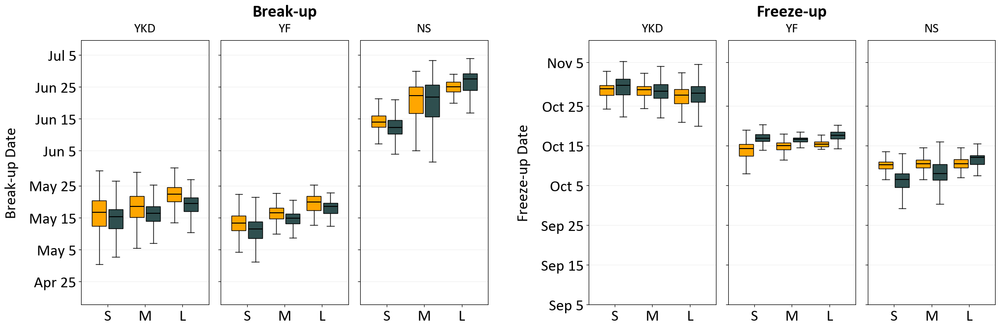

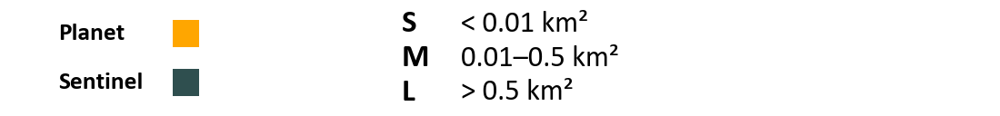

C:\Users\nj142\AppData\Local\Temp\ipykernel_32068\258796457.py:339: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
c:\Users\nj142\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9650 (\N{BLACK UP-POINTING TRIANGLE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\nj142\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9660 (\N{BLACK DOWN-POINTING TRIANGLE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


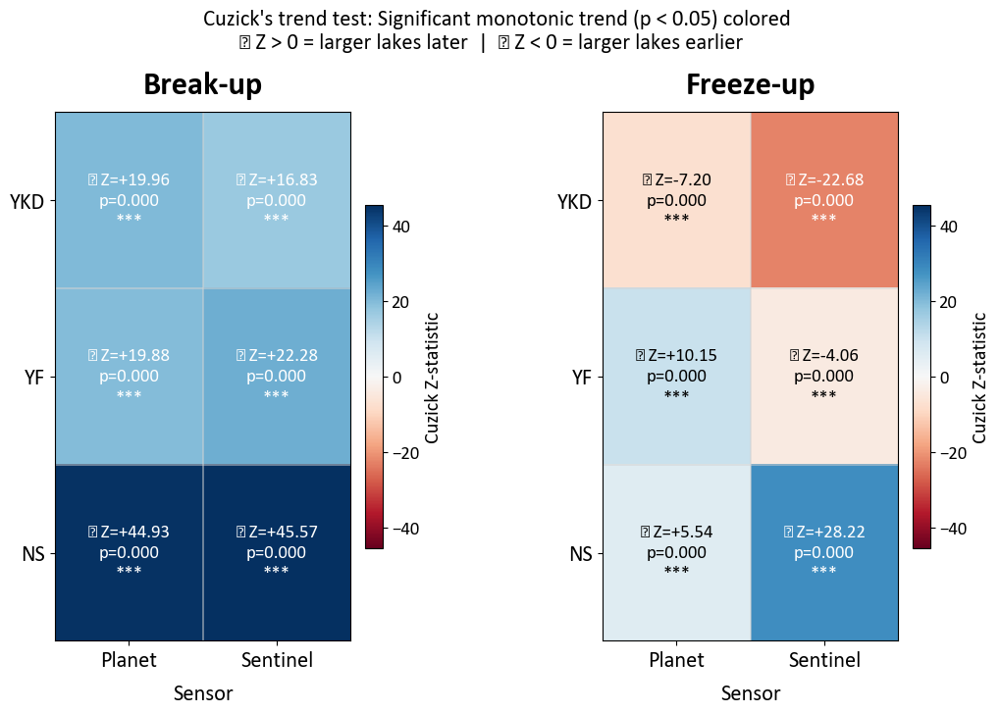

In [2]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from scipy import stats
import warnings
from datetime import datetime, timedelta
import matplotlib.ticker as ticker


# Changed font family to Calibri
plt.rcParams["font.family"] = "Calibri"

# ----------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------
TEXT_SCALE = 1.8
SITES   = ["YKD", "YF", "NS"]
SENSORS = ["PS", "S2"]
EVENTS  = ["Break-up", "Freeze-up"]
SENSOR_LABELS = {"PS": "Planet", "S2": "Sentinel"}
CSV_TEMPLATE = r"C:\Users\nj142\Desktop\Time Series\{sensor}\{event}\{site}_{event_lower}_dates.csv"
SHP_TEMPLATE = (
    r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data"
    r"\{site} 50x50 km\{site} Lakes from ALPOD Shapefile\{site}_50x50km_lakes.shp"
)
SMALL_THRESHOLD  = 0.01
MEDIUM_THRESHOLD = 0.5

PLANET_COLOR   = "#ffa600"
SENTINEL_COLOR = "#2f4f4f"

def _ramp(base):
    return {"Small": base, "Medium": base, "Large": base}

SENSOR_COLORS = {"PS": _ramp(PLANET_COLOR), "S2": _ramp(SENTINEL_COLOR)}
SIZE_ORDER       = ["Small", "Medium", "Large"]
SIZE_SHORT_LABEL = {"Small": "S", "Medium": "M", "Large": "L"}
# Ordered integer scores for Cuzick's test
SIZE_SCORES      = {"Small": 1, "Medium": 2, "Large": 3}
ID_CANDIDATES = ["lake_id", "Lake_id", "LAKE_ID", "id", "ID",
                 "alpod_id", "ALPOD_ID", "Hylak_id", "OBJECTID", "FID"]

# ----------------------------------------------------------------------
# Loaders & Caches
# ----------------------------------------------------------------------
_event_cache, _areas_cache, _assemble_cache = {}, {}, {}

def load_lake_areas(site):
    if site in _areas_cache: return _areas_cache[site].copy()
    gdf = gpd.read_file(SHP_TEMPLATE.format(site=site))
    id_col = next((c for c in ID_CANDIDATES if c in gdf.columns), None)
    gdf_proj = gdf.to_crs("EPSG:6933") if gdf.crs.is_geographic else gdf
    gdf["area_km2"] = gdf_proj.geometry.area / 1e6
    out = gdf[[id_col, "area_km2"]].rename(columns={id_col: "lake_id"})
    out["lake_id"] = pd.to_numeric(out["lake_id"], errors="coerce").astype("Int64").astype(str)
    _areas_cache[site] = out
    return out.copy()

def load_event(sensor, site, event):
    key = (sensor, site, event)
    if key in _event_cache: return _event_cache[key].copy()
    csv = CSV_TEMPLATE.format(sensor=sensor, event=event, event_lower=event.lower(), site=site)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        df = pd.read_csv(csv, low_memory=False)
    date_col = f"{event.lower()}_date"
    parsed = pd.to_datetime(df[date_col], format="%m/%d/%Y %H:%M", errors="coerce")
    if parsed.isna().mean() > 0.5: parsed = pd.to_datetime(df[date_col], format="mixed", errors="coerce")
    df[date_col] = parsed
    df = df.dropna(subset=[date_col])
    df["doy"] = df[date_col].dt.dayofyear
    df["lake_id"] = pd.to_numeric(df["lake_id"], errors="coerce").astype("Int64").astype(str)
    result = df.groupby("lake_id", as_index=False)["doy"].mean()
    _event_cache[key] = result
    return result.copy()

def classify_size(a):
    if a < SMALL_THRESHOLD:  return "Small"
    if a < MEDIUM_THRESHOLD: return "Medium"
    return "Large"

def assemble(sensor, site):
    key = (sensor, site)
    if key in _assemble_cache: return _assemble_cache[key].copy()
    areas = load_lake_areas(site)
    bu = load_event(sensor, site, "Breakup").rename(columns={"doy": "breakup_doy"})
    fu = load_event(sensor, site, "Freezeup").rename(columns={"doy": "freezeup_doy"})
    df = areas.merge(bu, on="lake_id", how="left").merge(fu, on="lake_id", how="left")
    df["size_class"] = df["area_km2"].apply(classify_size)
    _assemble_cache[key] = df
    return df.copy()

# ----------------------------------------------------------------------
# Restrict to lakes observed by BOTH sensors (paired comparison)
# ----------------------------------------------------------------------
EVENT_COL = {"Break-up": "breakup_doy", "Freeze-up": "freezeup_doy"}

def restrict_to_common_lakes(all_dfs, per_event=True):
    """
    Keep only lakes observed by BOTH sensors. Sets the event DOY to NaN
    for any lake not seen by both PS and S2, so all downstream .dropna()
    logic works unchanged and the two sensors are compared over an
    identical set of lakes.

    per_event=True : intersection computed separately for break-up and
                     freeze-up (a lake can qualify for one event but not
                     the other). Maximizes retained data.
    per_event=False: a lake must be paired on BOTH events to be kept for
                     either. Stricter, smaller n, one fixed cohort.
    """
    out = {k: v.copy() for k, v in all_dfs.items()}

    for site in SITES:
        ps = out[("PS", site)]
        s2 = out[("S2", site)]

        common_by_event = {}
        for event in EVENTS:
            col = EVENT_COL[event]
            ps_ids = set(ps.loc[ps[col].notna(), "lake_id"])
            s2_ids = set(s2.loc[s2[col].notna(), "lake_id"])
            common_by_event[event] = ps_ids & s2_ids

        if not per_event:
            both = common_by_event["Break-up"] & common_by_event["Freeze-up"]
            common_by_event = {ev: both for ev in EVENTS}

        for df in (ps, s2):
            for event in EVENTS:
                col = EVENT_COL[event]
                mask = ~df["lake_id"].isin(common_by_event[event])
                df.loc[mask, col] = np.nan

    return out

# ----------------------------------------------------------------------
# Cuzick's trend test
# ----------------------------------------------------------------------

def pval_stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return "ns"

def cuzick_test(groups, scores):
    """
    Cuzick's non-parametric test for a monotonic trend across ordered groups.
    """
    arrays = [np.asarray(g, dtype=float) for g in groups]
    n_i    = np.array([len(a) for a in arrays])
    l_i    = np.array(scores, dtype=float)
    N      = int(n_i.sum())

    if N < 3 or np.any(n_i < 1):
        return np.nan, np.nan

    all_vals = np.concatenate(arrays)
    all_ranks = stats.rankdata(all_vals)          # average-rank tie handling

    # Group rank sums (W_i)
    idx = 0
    W_i = np.empty(len(arrays))
    for k, a in enumerate(arrays):
        W_i[k] = all_ranks[idx : idx + len(a)].sum()
        idx += len(a)

    T   = float(l_i @ W_i)
    E_T = ((N + 1) / 2.0) * float(l_i @ n_i)

    sum_R2  = float((all_ranks ** 2).sum())
    term_R  = sum_R2 - N * (N + 1) ** 2 / 4.0
    term_l  = float(n_i @ (l_i ** 2)) - float(n_i @ l_i) ** 2 / N
    var_T   = term_R * term_l / (N - 1)

    if var_T <= 0:
        return np.nan, np.nan

    z_stat = (T - E_T) / np.sqrt(var_T)
    p_two  = float(2.0 * (1.0 - stats.norm.cdf(abs(z_stat))))
    return z_stat, p_two


def run_cuzick(all_dfs):
    scores = [SIZE_SCORES[sc] for sc in SIZE_ORDER]   # [1, 2, 3]
    results = []
    for sensor in SENSORS:
        for site in SITES:
            df = all_dfs[(sensor, site)]
            for event in EVENTS:
                col = EVENT_COL[event]
                groups = [
                    df.loc[df["size_class"] == sc, col].dropna().values
                    for sc in SIZE_ORDER
                ]
                ns = [len(g) for g in groups]
                if any(n < 3 for n in ns):
                    continue
                z_stat, p_two = cuzick_test(groups, scores)
                group_means = [g.mean() for g in groups]
                results.append({
                    "sensor":       sensor,
                    "site":         site,
                    "event":        event,
                    "n_small":      ns[0],
                    "n_medium":     ns[1],
                    "n_large":      ns[2],
                    "mean_small":   group_means[0],
                    "mean_medium":  group_means[1],
                    "mean_large":   group_means[2],
                    "z_stat":       z_stat,
                    "p_value":      p_two,
                    "stars":        pval_stars(p_two),
                })
    return pd.DataFrame(results)


def print_cuzick_summary(cuzick_df):
    print("\n" + "=" * 80)
    print("CUZICK'S TREND TEST  (H₀: no monotonic trend across Small→Medium→Large)")
    print("Stars: *** p<0.001  ** p<0.01  * p<0.05  ns = not significant")
    print("Z > 0  →  larger lakes are later in the season")
    print("=" * 80)
    for event in EVENTS:
        print(f"\n{'─'*40}  {event.upper()}  {'─'*40}")
        sub = cuzick_df[cuzick_df["event"] == event]
        for sensor in SENSORS:
            print(f"\n  [{SENSOR_LABELS[sensor]}]")
            s = sub[sub["sensor"] == sensor]
            for site in SITES:
                row = s[s["site"] == site]
                if row.empty:
                    continue
                r = row.iloc[0]
                direction = "larger lakes later" if r["z_stat"] > 0 else "larger lakes EARLIER"
                print(
                    f"    {site}:  Z={r['z_stat']:+6.3f}  p={r['p_value']:.4f} {r['stars']:3s}"
                    f"  ({direction})"
                    f"  n={r['n_small']}/{r['n_medium']}/{r['n_large']}"
                    f"  means={r['mean_small']:.1f}/{r['mean_medium']:.1f}/{r['mean_large']:.1f} DOY"
                )
    print("=" * 80 + "\n")


# ----------------------------------------------------------------------
# Stats figure: heatmap of Z-statistics from Cuzick's test
# ----------------------------------------------------------------------
def make_stats_figure(cuzick_df):
    n_rows = len(SITES)
    n_cols = len(SENSORS)
    col_labels = [SENSOR_LABELS[sn] for sn in SENSORS]

    fig, axes = plt.subplots(
        1, len(EVENTS),
        figsize=(12, 7),
        gridspec_kw={"wspace": 0.50}
    )

    cmap = plt.get_cmap("RdBu").copy()
    cmap.set_bad(color="white")

    all_z   = cuzick_df["z_stat"].dropna().values
    abs_max = np.nanmax(np.abs(all_z)) if len(all_z) else 3.0
    vmin, vmax = -abs_max, abs_max

    for ax, event in zip(axes, EVENTS):
        sub = cuzick_df[cuzick_df["event"] == event]

        display_mat = np.full((n_rows, n_cols), np.nan)
        z_mat       = np.full((n_rows, n_cols), np.nan)
        p_mat       = np.ones((n_rows, n_cols))

        for r_idx, site in enumerate(SITES):
            for c_idx, sensor in enumerate(SENSORS):
                match = sub[(sub["site"] == site) & (sub["sensor"] == sensor)]
                if not match.empty:
                    z_val = match["z_stat"].values[0]
                    p_val = match["p_value"].values[0]
                    z_mat[r_idx, c_idx] = z_val
                    p_mat[r_idx, c_idx] = p_val
                    if p_val < 0.05:
                        display_mat[r_idx, c_idx] = z_val

        im = ax.imshow(display_mat, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")

        for r in range(n_rows):
            for c in range(n_cols):
                z_val  = z_mat[r, c]
                p_val  = p_mat[r, c]
                if np.isnan(z_val):
                    continue
                stars  = pval_stars(p_val)
                direction_arrow = "▲" if z_val > 0 else "▼"

                if p_val >= 0.05:
                    text_color = "black"
                else:
                    norm_val = (z_val - vmin) / (vmax - vmin)
                    text_color = "white" if (norm_val < 0.35 or norm_val > 0.65) else "black"

                cell_text = (
                    f"{direction_arrow} Z={z_val:+.2f}\n"
                    f"p={p_val:.3f}\n"
                    f"{stars}"
                )
                ax.text(
                    c, r, cell_text,
                    ha="center", va="center",
                    fontsize=7.5 * TEXT_SCALE,
                    color=text_color,
                    linespacing=1.4
                )

        ax.set_xticks(range(n_cols))
        ax.set_xticklabels(col_labels, fontsize=9 * TEXT_SCALE)
        ax.set_yticks(range(n_rows))
        ax.set_yticklabels(SITES, fontsize=9 * TEXT_SCALE)
        ax.set_title(event, fontsize=13 * TEXT_SCALE, fontweight="bold", pad=14)
        ax.set_xlabel("Sensor", fontsize=9 * TEXT_SCALE, labelpad=10)

        for sep in [0.5, 1.5]:
            ax.axhline(sep, color="lightgray", linewidth=1.2, alpha=0.6)
        ax.axvline(0.5, color="lightgray", linewidth=1.2, alpha=0.6)

        cbar = fig.colorbar(im, ax=ax, shrink=0.65, pad=0.04)
        cbar.set_label("Cuzick Z-statistic", fontsize=8 * TEXT_SCALE)
        cbar.ax.tick_params(labelsize=7.5 * TEXT_SCALE)

    fig.suptitle(
        "Cuzick's trend test: Significant monotonic trend (p < 0.05) colored\n"
        "▲ Z > 0 = larger lakes later  |  ▼ Z < 0 = larger lakes earlier  ",
        fontsize=9 * TEXT_SCALE,
        y=1.03
    )

    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------------------
# Main Figure — boxplots
# ----------------------------------------------------------------------

def date_ticks_for_range(doy_lo, doy_hi):
    """Ticks on day 5, 15, 25 of each month, labeled like 'Jun 5'."""
    ticks, labels = [], []
    for month in range(1, 13):
        for day in (5, 15, 25):
            d = datetime(2023, month, day)   # non-leap reference year
            doy = d.timetuple().tm_yday
            if doy_lo <= doy <= doy_hi:
                ticks.append(doy)
                labels.append(f"{d.strftime('%b')} {d.day}")
    return ticks, labels

def _size_range(sc):
    if sc == "Small":  return f"< {SMALL_THRESHOLD} km²"
    if sc == "Medium": return f"{SMALL_THRESHOLD}–{MEDIUM_THRESHOLD} km²"
    return f"> {MEDIUM_THRESHOLD} km²"
import matplotlib.ticker as ticker

def make_combined_figure(all_dfs):
    def padded(series, frac=0.08):
        if series.empty: return 0, 365
        lo, hi = series.min(), series.max()
        pad = (hi - lo) * frac
        return lo - pad, hi + pad

    event_ylim = {
        ev: padded(pd.concat([all_dfs[(sn, s)][EVENT_COL[ev]].dropna()
                               for sn in SENSORS for s in SITES]))
        for ev in EVENTS
    }

    fig1 = plt.figure(figsize=(24, 7))
    gs = GridSpec(1, 7, figure=fig1,
                  width_ratios=[1, 1, 1, 0.6, 1, 1, 1], wspace=0.1)

    axes = []
    pair_offsets = {"PS": -0.22, "S2": +0.22}
    box_width    = 0.38
    
    # Calculate unified font size: (10 * 1.8) + 5 = 23
    unified_label_size = (10 * TEXT_SCALE) + 5

    def draw_cluster(target_ax, sensor_site_data, event_col, ylim):
        group_centers = [0, 1, 2]
        n_by_size = {sc: {} for sc in SIZE_ORDER}
        for sensor in SENSORS:
            ramp = SENSOR_COLORS[sensor]
            positions, data, colors = [], [], []
            for sz_idx, sc in enumerate(SIZE_ORDER):
                df = sensor_site_data[sensor]
                vals = df.loc[df["size_class"] == sc, event_col].dropna().values
                positions.append(group_centers[sz_idx] + pair_offsets[sensor])
                data.append(vals)
                colors.append(ramp[sc])
                n_by_size[sc][sensor] = len(vals)

            bp = target_ax.boxplot(
                data, positions=positions, widths=box_width, patch_artist=True,
                medianprops=dict(color="black", linewidth=1.4),
                showfliers=False,                       # <-- no outliers drawn
            )
            for patch, c in zip(bp["boxes"], colors):
                patch.set_facecolor(c)
                patch.set_edgecolor("black")

        target_ax.set_ylim(ylim)
        target_ax.set_xlim(-0.7, 2.70)
        target_ax.set_xticks(group_centers)
        target_ax.set_xticklabels(
            [SIZE_SHORT_LABEL[sc] for sc in SIZE_ORDER],
            fontsize=unified_label_size
        )
        target_ax.grid(True, axis="y", alpha=0.2)

        target_ax.set_ylim(ylim)
        target_ax.set_xlim(-0.7, 2.70)

        y_lo, y_hi = target_ax.get_ylim()
        date_ticks, date_labels = date_ticks_for_range(
            int(np.floor(y_lo)), int(np.ceil(y_hi))
        )
        target_ax.set_yticks(date_ticks)
        target_ax.set_yticklabels(date_labels)

        target_ax.tick_params(axis='both', labelsize=unified_label_size)
        # n= labels removed — now printed in notebook output instead

    col_mapping = [0, 1, 2, 4, 5, 6]
    for idx, (ev, site) in enumerate([(ev, s) for ev in EVENTS for s in SITES]):
        ax = fig1.add_subplot(gs[col_mapping[idx]])
        axes.append(ax)
        site_data = {sn: all_dfs[(sn, site)] for sn in SENSORS}
        draw_cluster(ax, site_data, EVENT_COL[ev], event_ylim[ev])
        ax.set_title(site, fontsize=11 * TEXT_SCALE, pad=12)

        if col_mapping[idx] in [0, 4]:
            ax.set_ylabel(f"{ev} Date",
                          fontsize=unified_label_size, labelpad=15)
        else:
            ax.tick_params(labelleft=False)

    plt.tight_layout(rect=[0, 0.02, 0.98, 0.88])

    for ev_idx, ev in enumerate(EVENTS):
        start_pos = axes[ev_idx * 3].get_position()
        end_pos   = axes[ev_idx * 3 + 2].get_position()
        fig1.text(
            (start_pos.x0 + end_pos.x1) / 2,
            start_pos.y1 + 0.07,
            ev,
            ha="center",
            fontsize=14 * TEXT_SCALE,
            fontweight="bold"
        )

    plt.show()

    # --- Compact legend ---
    fig_leg = plt.figure(figsize=(12, 1.2))
    legend_ax = fig_leg.add_axes([0.05, 0.05, 0.9, 0.9])
    legend_ax.axis("off")
    legend_ax.set_xlim(0, 1)
    legend_ax.set_ylim(0, 1)

    label_x = 0.05
    for r, sensor in enumerate(SENSORS):
        y_c = 0.75 - (r * 0.5)
        legend_ax.text(label_x, y_c, SENSOR_LABELS[sensor],
                       ha="left", va="center",
                       fontsize=11 * TEXT_SCALE, fontweight="bold")
        
        legend_ax.scatter(label_x + 0.13, y_c, marker='s', s=450, 
                          facecolor=SENSOR_COLORS[sensor]["Medium"], edgecolor="none")

    letter_x = 0.40; range_x = 0.46
    for j, sc in enumerate(SIZE_ORDER):
        y_c = 0.85 - (j * 0.35)
        legend_ax.text(letter_x, y_c, SIZE_SHORT_LABEL[sc],
                       ha="left", va="center",
                       fontsize=14 * TEXT_SCALE, fontweight="bold")
        legend_ax.text(range_x, y_c, _size_range(sc),
                       ha="left", va="center",
                       fontsize=13 * TEXT_SCALE)

    plt.show()

def print_sample_sizes(all_dfs):
    print("\n" + "=" * 78)
    print("SAMPLE SIZES (n) by Event, Site, Sensor, and Size Class")
    print("(Paired: identical lake sets across sensors within each event/site)")
    print("=" * 78)
    for event in EVENTS:
        col = EVENT_COL[event]
        print(f"\n{event}:")
        header = f"  {'Site':<6}{'Sensor':<12}" + "".join(f"{sc:>10}" for sc in SIZE_ORDER)
        print(header)
        print("  " + "-" * (len(header) - 2))
        for site in SITES:
            for sensor in SENSORS:
                df = all_dfs[(sensor, site)]
                counts = [
                    int(df.loc[(df["size_class"] == sc) & df[col].notna()].shape[0])
                    for sc in SIZE_ORDER
                ]
                print(
                    f"  {site:<6}{SENSOR_LABELS[sensor]:<12}"
                    + "".join(f"{n:>10d}" for n in counts)
                )
    print("=" * 78 + "\n")

# ----------------------------------------------------------------------
# Entry point
# ----------------------------------------------------------------------
if __name__ == "__main__":
    all_dfs = {(sn, s): assemble(sn, s) for sn in SENSORS for s in SITES}
    all_dfs = restrict_to_common_lakes(all_dfs, per_event=True)   # <-- pair the sensors

    cuzick_df = run_cuzick(all_dfs)
    print_cuzick_summary(cuzick_df)

    print_sample_sizes(all_dfs)

    make_combined_figure(all_dfs)
    make_stats_figure(cuzick_df)